# Explainable Healthcare Provider Risk Intelligence

**Provider-level machine learning for investigation prioritization from healthcare claims data**

### Project objective
Develop an explainable machine-learning system that aggregates healthcare claims into provider-level financial, utilization, beneficiary, coding, and physician-behavior profiles; estimates calibrated provider risk; prioritizes providers under limited investigation capacity; and exposes interpretable results through FastAPI and Streamlit.

### Final architecture
`Healthcare claims → provider-level feature engineering → leakage/reliability pruning → baseline models → LightGBM/XGBoost comparison → calibration → capacity-based ranking → SHAP → provider database → FastAPI → Streamlit`

**Important interpretation:** `PotentialFraud` is the dataset's label and should not be treated as independently verified or legally established fraud. The deployed system produces statistical risk-prioritization scores for investigation support.

**Reproducibility:** the raw healthcare claims data are not embedded in this notebook. The ZIP path in the data-loading section must point to the user's authorized local/Drive copy.


In [1]:
import os
import zipfile
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Path to the ZIP file in Google Drive
ZIP_PATH = '/content/drive/My Drive/Colab Notebooks/MedicalHealthcareFraud/HEALTHCARE_PROVIDER_FRAUD_DETECTION.zip'

# Local extraction directory in Colab
EXTRACT_DIR = '/content/data_raw'

# Create extraction directory
os.makedirs(EXTRACT_DIR, exist_ok=True)

# Extract ZIP
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Files extracted successfully.")
print("\nExtracted files:")

for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        print(os.path.join(root, file))

Mounted at /content/drive
Files extracted successfully.

Extracted files:
/content/data_raw/Train-1542865627584.csv
/content/data_raw/Test-1542969243754.csv
/content/data_raw/Test_Inpatientdata-1542969243754.csv
/content/data_raw/Train_Beneficiarydata-1542865627584.csv
/content/data_raw/Test_Beneficiarydata-1542969243754.csv
/content/data_raw/Train_Outpatientdata-1542865627584.csv
/content/data_raw/Test_Outpatientdata-1542969243754.csv
/content/data_raw/Train_Inpatientdata-1542865627584.csv


In [2]:
import os
import pandas as pd

# ============================================================
# STEP 2 — INITIAL DATASET INVENTORY & AUDIT
# ============================================================

# Ensure extraction directory is defined
EXTRACT_DIR = '/content/data_raw'

# File paths
files = {
    "Train Provider": os.path.join(EXTRACT_DIR, "Train-1542865627584.csv"),
    "Train Beneficiary": os.path.join(EXTRACT_DIR, "Train_Beneficiarydata-1542865627584.csv"),
    "Train Inpatient": os.path.join(EXTRACT_DIR, "Train_Inpatientdata-1542865627584.csv"),
    "Train Outpatient": os.path.join(EXTRACT_DIR, "Train_Outpatientdata-1542865627584.csv"),
    "Test Provider": os.path.join(EXTRACT_DIR, "Test-1542969243754.csv"),
    "Test Beneficiary": os.path.join(EXTRACT_DIR, "Test_Beneficiarydata-1542969243754.csv"),
    "Test Inpatient": os.path.join(EXTRACT_DIR, "Test_Inpatientdata-1542969243754.csv"),
    "Test Outpatient": os.path.join(EXTRACT_DIR, "Test_Outpatientdata-1542969243754.csv")
}

# 1. Load Data
data = {}
for name, path in files.items():
    print(f"Loading: {name} ...")
    data[name] = pd.read_csv(path)

print("\nAll files loaded successfully.\n")

# 2. Dimensions & Memory Footprint
print("=" * 80)
print(f"{'DATASET NAME':<22} | {'ROWS':>10} | {'COLS':>5} | {'MEMORY (MB)':>12}")
print("=" * 80)

for name, df in data.items():
    mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    print(f"{name:<22} | {df.shape[0]:>10,} | {df.shape[1]:>5} | {mem_mb:>11.2f} MB")

# 3. Train vs Test Schema Consistency Check
print("\n" + "=" * 80)
print("TRAIN vs. TEST SCHEMA CONSISTENCY")
print("=" * 80)

pairs = [
    ("Provider", "Train Provider", "Test Provider"),
    ("Beneficiary", "Train Beneficiary", "Test Beneficiary"),
    ("Inpatient", "Train Inpatient", "Test Inpatient"),
    ("Outpatient", "Train Outpatient", "Test Outpatient"),
]

for entity, tr_name, te_name in pairs:
    tr_cols = set(data[tr_name].columns)
    te_cols = set(data[te_name].columns)
    diff_tr = tr_cols - te_cols
    diff_te = te_cols - tr_cols

    print(f"\n[{entity}]")
    if tr_cols == te_cols:
        print("  -> Columns match exactly.")
    else:
        if diff_tr:
            print(f"  -> In Train but not Test: {diff_tr}")
        if diff_te:
            print(f"  -> In Test but not Train: {diff_te}")

# 4. Target Class Balance
print("\n" + "=" * 80)
print("TRAIN TARGET DISTRIBUTION")
print("=" * 80)
target_col = "PotentialFraud"

assert target_col in data["Train Provider"].columns, (
    f"'{target_col}' not found in Train Provider columns: {list(data['Train Provider'].columns)}"
)

print(data["Train Provider"][target_col].value_counts(dropna=False))
print("\nPercentage:")
print(data["Train Provider"][target_col].value_counts(normalize=True, dropna=False) * 100)

Loading: Train Provider ...
Loading: Train Beneficiary ...
Loading: Train Inpatient ...
Loading: Train Outpatient ...
Loading: Test Provider ...
Loading: Test Beneficiary ...
Loading: Test Inpatient ...
Loading: Test Outpatient ...

All files loaded successfully.

DATASET NAME           |       ROWS |  COLS |  MEMORY (MB)
Train Provider         |      5,410 |     2 |        0.56 MB
Train Beneficiary      |    138,556 |    25 |       48.58 MB
Train Inpatient        |     40,474 |    30 |       46.77 MB
Train Outpatient       |    517,737 |    27 |      446.45 MB
Test Provider          |      1,353 |     1 |        0.07 MB
Test Beneficiary       |     63,968 |    25 |       22.43 MB
Test Inpatient         |      9,551 |    30 |       11.03 MB
Test Outpatient        |    125,841 |    27 |      108.50 MB

TRAIN vs. TEST SCHEMA CONSISTENCY

[Provider]
  -> In Train but not Test: {'PotentialFraud'}

[Beneficiary]
  -> Columns match exactly.

[Inpatient]
  -> Columns match exactly.

[Outpatie

In [3]:
# ============================================================
# STEP 3 — SCHEMA, MISSINGNESS, DUPLICATES & RELATIONAL AUDIT
# ============================================================

print("=" * 100)
print("1. COLUMN STRUCTURE & MISSINGNESS (TRAINING TABLES)")
print("=" * 100)

target_tables = [
    "Train Provider",
    "Train Beneficiary",
    "Train Inpatient",
    "Train Outpatient"
]

for name in target_tables:
    df = data[name]
    print("\n" + "-" * 100)
    print(f"{name} ({df.shape[0]:,d} rows × {df.shape[1]} cols)")
    print("-" * 100)
    for i, col in enumerate(df.columns, start=1):
        null_count = df[col].isna().sum()
        null_pct = df[col].isna().mean() * 100
        print(f"{i:>2}. {col:<35} | dtype = {str(df[col].dtype):<10} | missing = {null_count:>8,d} ({null_pct:>6.2f}%)")

print("\n" + "=" * 100)
print("2. IDENTIFIER CARDINALITY & UNIQUE COUNTS")
print("=" * 100)

identifier_candidates = {
    "Train Provider": ["Provider"],
    "Train Beneficiary": ["BeneID"],
    "Train Inpatient": ["ClaimID", "Provider", "BeneID"],
    "Train Outpatient": ["ClaimID", "Provider", "BeneID"]
}

for name, cols in identifier_candidates.items():
    df = data[name]
    print(f"\n[{name}]")
    for col in cols:
        if col in df.columns:
            print(
                f"{col:<15} | rows = {len(df):>10,d} | "
                f"unique = {df[col].nunique(dropna=True):>10,d} | "
                f"missing = {df[col].isna().sum():>8,d}"
            )

print("\n" + "=" * 100)
print("3. DUPLICATE ROW AUDIT")
print("=" * 100)

for name in target_tables:
    df = data[name]
    print(f"{name:<22} | duplicate rows = {df.duplicated().sum():>10,d}")

print("\n" + "=" * 100)
print("4. RELATIONAL INTEGRITY & FOREIGN KEY MAPPING")
print("=" * 100)

train_providers = set(data["Train Provider"]["Provider"])
inpatient_providers = set(data["Train Inpatient"]["Provider"])
outpatient_providers = set(data["Train Outpatient"]["Provider"])
all_claim_providers = inpatient_providers.union(outpatient_providers)

print(f"Total Labeled Providers:                 {len(train_providers):,d}")
print(f"Unique Providers in Inpatient:           {len(inpatient_providers):,d}")
print(f"Unique Providers in Outpatient:          {len(outpatient_providers):,d}")
print(f"Providers in Both Inpatient & Outpatient:{len(inpatient_providers.intersection(outpatient_providers)):,d}")
print(f"Providers in Inpatient ONLY:             {len(inpatient_providers - outpatient_providers):,d}")
print(f"Providers in Outpatient ONLY:            {len(outpatient_providers - inpatient_providers):,d}")
print(f"Total Providers with Claims:             {len(all_claim_providers):,d}")

unmapped_labels = train_providers - all_claim_providers
orphan_claim_providers = all_claim_providers - train_providers

print(f"\nProviders in Labels with ZERO claims:     {len(unmapped_labels):,d}")
if unmapped_labels:
    print(f"  -> Unmapped Provider IDs: {unmapped_labels}")
print(f"Providers in Claims NOT in label file:    {len(orphan_claim_providers):,d}")

# Row-level provider coverage
inpatient_unmapped_rows = (~data["Train Inpatient"]["Provider"].isin(train_providers)).sum()
outpatient_unmapped_rows = (~data["Train Outpatient"]["Provider"].isin(train_providers)).sum()
print(f"Inpatient claim rows with unmapped Provider:  {inpatient_unmapped_rows:,d}")
print(f"Outpatient claim rows with unmapped Provider: {outpatient_unmapped_rows:,d}")

bene_master = set(data["Train Beneficiary"]["BeneID"])
inpatient_bene = set(data["Train Inpatient"]["BeneID"])
outpatient_bene = set(data["Train Outpatient"]["BeneID"])
all_claim_bene = inpatient_bene.union(outpatient_bene)

print(f"\nTotal Beneficiaries in Master Table:     {len(bene_master):,d}")
print(f"Total Beneficiaries appearing in Claims:  {len(all_claim_bene):,d}")
print(f"Beneficiaries in Master but NO claims:    {len(bene_master - all_claim_bene):,d}")
print(f"Claim Beneficiaries MISSING from Master:  {len(all_claim_bene - bene_master):,d}")

# Row-level beneficiary coverage
inpatient_unmapped_bene_rows = (~data["Train Inpatient"]["BeneID"].isin(bene_master)).sum()
outpatient_unmapped_bene_rows = (~data["Train Outpatient"]["BeneID"].isin(bene_master)).sum()
print(f"Inpatient rows with unmapped BeneID:  {inpatient_unmapped_bene_rows:,d}")
print(f"Outpatient rows with unmapped BeneID: {outpatient_unmapped_bene_rows:,d}")

in_claims = data["Train Inpatient"]["ClaimID"]
out_claims = data["Train Outpatient"]["ClaimID"]

print(f"\nInpatient ClaimID Duplicates:            {in_claims.duplicated().sum():,d}")
print(f"Outpatient ClaimID Duplicates:           {out_claims.duplicated().sum():,d}")
print(f"ClaimIDs appearing in BOTH In & Out:     {len(set(in_claims).intersection(set(out_claims))):,d}")

1. COLUMN STRUCTURE & MISSINGNESS (TRAINING TABLES)

----------------------------------------------------------------------------------------------------
Train Provider (5,410 rows × 2 cols)
----------------------------------------------------------------------------------------------------
 1. Provider                            | dtype = object     | missing =        0 (  0.00%)
 2. PotentialFraud                      | dtype = object     | missing =        0 (  0.00%)

----------------------------------------------------------------------------------------------------
Train Beneficiary (138,556 rows × 25 cols)
----------------------------------------------------------------------------------------------------
 1. BeneID                              | dtype = object     | missing =        0 (  0.00%)
 2. DOB                                 | dtype = object     | missing =        0 (  0.00%)
 3. DOD                                 | dtype = object     | missing =  137,135 ( 98.97%)
 4

In [4]:
# ============================================================
# CELL 4 — TEMPORAL AUDIT & CHRONOLOGICAL INTEGRITY
# ============================================================

import numpy as np
import pandas as pd

print('=' * 90)
print('1. DATE CONVERSIONS & GLOBAL TIME HORIZONS')
print('=' * 90)

# Convert date columns to datetime
date_cols_bene = ['DOB', 'DOD']
date_cols_in = ['ClaimStartDt', 'ClaimEndDt', 'AdmissionDt', 'DischargeDt']
date_cols_out = ['ClaimStartDt', 'ClaimEndDt']

for col in date_cols_bene:
  data['Train Beneficiary'][col] = pd.to_datetime(
      data['Train Beneficiary'][col], format='%Y-%m-%d', errors='coerce'
  )

for col in date_cols_in:
  data['Train Inpatient'][col] = pd.to_datetime(
      data['Train Inpatient'][col], format='%Y-%m-%d', errors='coerce'
  )

for col in date_cols_out:
  data['Train Outpatient'][col] = pd.to_datetime(
      data['Train Outpatient'][col], format='%Y-%m-%d', errors='coerce'
  )

# Global Min/Max Dates
in_start_min, in_start_max = (
    data['Train Inpatient']['ClaimStartDt'].min(),
    data['Train Inpatient']['ClaimStartDt'].max(),
)
in_end_min, in_end_max = (
    data['Train Inpatient']['ClaimEndDt'].min(),
    data['Train Inpatient']['ClaimEndDt'].max(),
)
out_start_min, out_start_max = (
    data['Train Outpatient']['ClaimStartDt'].min(),
    data['Train Outpatient']['ClaimStartDt'].max(),
)
out_end_min, out_end_max = (
    data['Train Outpatient']['ClaimEndDt'].min(),
    data['Train Outpatient']['ClaimEndDt'].max(),
)

print(
    f"Inpatient ClaimStartDt  : {in_start_min.strftime('%Y-%m-%d')}  to "
    f" {in_start_max.strftime('%Y-%m-%d')}"
)
print(
    f"Inpatient ClaimEndDt    : {in_end_min.strftime('%Y-%m-%d')}  to "
    f" {in_end_max.strftime('%Y-%m-%d')}"
)
print(
    f"Outpatient ClaimStartDt : {out_start_min.strftime('%Y-%m-%d')}  to "
    f" {out_start_max.strftime('%Y-%m-%d')}"
)
print(
    f"Outpatient ClaimEndDt   : {out_end_min.strftime('%Y-%m-%d')}  to "
    f" {out_end_max.strftime('%Y-%m-%d')}"
)
print(
    'Beneficiary DOB Range   :'
    f" {data['Train Beneficiary']['DOB'].min().strftime('%Y-%m-%d')}  to "
    f" {data['Train Beneficiary']['DOB'].max().strftime('%Y-%m-%d')}"
)
print(
    'Beneficiary DOD Range   :'
    f" {data['Train Beneficiary']['DOD'].min().strftime('%Y-%m-%d')}  to "
    f" {data['Train Beneficiary']['DOD'].max().strftime('%Y-%m-%d')}"
)

print('\n' + '=' * 90)
print('2. CHRONOLOGICAL SANITY & DURATION CHECKS')
print('=' * 90)

# Check for negative durations
in_inv_claims = (
    data['Train Inpatient']['ClaimEndDt']
    < data['Train Inpatient']['ClaimStartDt']
).sum()
out_inv_claims = (
    data['Train Outpatient']['ClaimEndDt']
    < data['Train Outpatient']['ClaimStartDt']
).sum()
in_inv_stays = (
    data['Train Inpatient']['DischargeDt']
    < data['Train Inpatient']['AdmissionDt']
).sum()

# Check mismatch between ClaimStartDt/AdmissionDt and ClaimEndDt/DischargeDt in Inpatient
admit_start_diff = (
    data['Train Inpatient']['AdmissionDt']
    != data['Train Inpatient']['ClaimStartDt']
).sum()
disch_end_diff = (
    data['Train Inpatient']['DischargeDt']
    != data['Train Inpatient']['ClaimEndDt']
).sum()

print(
    'Inpatient Claims with EndDt < StartDt           :'
    f' {in_inv_claims:,d}'
)
print(
    'Outpatient Claims with EndDt < StartDt          :'
    f' {out_inv_claims:,d}'
)
print(f'Inpatient Stays with DischargeDt < AdmissionDt  : {in_inv_stays:,d}')
print(
    'Inpatient rows where AdmissionDt != ClaimStartDt:'
    f' {admit_start_diff:,d}'
)
print(
    'Inpatient rows where DischargeDt != ClaimEndDt  :'
    f' {disch_end_diff:,d}'
)

# Duration summaries
in_stay_days = (
    data['Train Inpatient']['DischargeDt']
    - data['Train Inpatient']['AdmissionDt']
).dt.days
out_claim_days = (
    data['Train Outpatient']['ClaimEndDt']
    - data['Train Outpatient']['ClaimStartDt']
).dt.days

print(
    f'\nInpatient Length of Stay (Days) -> Min: {in_stay_days.min()}, Median:'
    f' {in_stay_days.median():.1f}, Mean: {in_stay_days.mean():.2f}, Max:'
    f' {in_stay_days.max()}'
)
print(
    f'Outpatient Claim Duration (Days)-> Min: {out_claim_days.min()}, Median:'
    f' {out_claim_days.median():.1f}, Mean: {out_claim_days.mean():.2f}, Max:'
    f' {out_claim_days.max()}'
)

print('\n' + '=' * 90)
print('3. POST-MORTEM BILLING AUDIT (Claims after Beneficiary DOD)')
print('=' * 90)

bene_dod = data['Train Beneficiary'][['BeneID', 'DOD']].dropna(subset=['DOD'])

in_merged = data['Train Inpatient'][
    ['ClaimID', 'Provider', 'BeneID', 'ClaimStartDt', 'ClaimEndDt']
].merge(bene_dod, on='BeneID', how='inner')
out_merged = data['Train Outpatient'][
    ['ClaimID', 'Provider', 'BeneID', 'ClaimStartDt', 'ClaimEndDt']
].merge(bene_dod, on='BeneID', how='inner')

in_post_start = (in_merged['ClaimStartDt'] > in_merged['DOD']).sum()
out_post_start = (out_merged['ClaimStartDt'] > out_merged['DOD']).sum()

in_post_end = (in_merged['ClaimEndDt'] > in_merged['DOD']).sum()
out_post_end = (out_merged['ClaimEndDt'] > out_merged['DOD']).sum()

print(f'Deceased Beneficiaries in Master Table          : {len(bene_dod):,d}')
print(f'Inpatient claims with ClaimStartDt > DOD        : {in_post_start:,d}')
print(
    f'Outpatient claims with ClaimStartDt > DOD       : {out_post_start:,d}'
)
print(f'Inpatient claims with ClaimEndDt > DOD          : {in_post_end:,d}')
print(f'Outpatient claims with ClaimEndDt > DOD         : {out_post_end:,d}')

1. DATE CONVERSIONS & GLOBAL TIME HORIZONS
Inpatient ClaimStartDt  : 2008-11-27  to  2009-12-31
Inpatient ClaimEndDt    : 2009-01-01  to  2009-12-31
Outpatient ClaimStartDt : 2008-12-12  to  2009-12-31
Outpatient ClaimEndDt   : 2008-12-28  to  2009-12-31
Beneficiary DOB Range   : 1909-01-01  to  1983-12-01
Beneficiary DOD Range   : 2009-02-01  to  2009-12-01

2. CHRONOLOGICAL SANITY & DURATION CHECKS
Inpatient Claims with EndDt < StartDt           : 0
Outpatient Claims with EndDt < StartDt          : 0
Inpatient Stays with DischargeDt < AdmissionDt  : 0
Inpatient rows where AdmissionDt != ClaimStartDt: 32
Inpatient rows where DischargeDt != ClaimEndDt  : 17

Inpatient Length of Stay (Days) -> Min: 0, Median: 4.0, Mean: 5.67, Max: 35
Outpatient Claim Duration (Days)-> Min: 0, Median: 0.0, Mean: 1.42, Max: 23

3. POST-MORTEM BILLING AUDIT (Claims after Beneficiary DOD)
Deceased Beneficiaries in Master Table          : 1,421
Inpatient claims with ClaimStartDt > DOD        : 0
Outpatient c

In [5]:
# ============================================================
# STEP 4A — BASIC STATISTICAL PROFILING
# ============================================================

import pandas as pd
import numpy as np

# Ensure target_col is defined
target_col = "PotentialFraud"

# ------------------------------------------------------------
# 1. Access the training data
# ------------------------------------------------------------

train_provider = data["Train Provider"].copy()
train_beneficiary = data["Train Beneficiary"].copy()
train_inpatient = data["Train Inpatient"].copy()
train_outpatient = data["Train Outpatient"].copy()

print("=" * 90)
print("1. DATASET SIZES")
print("=" * 90)

for name, df in {
    "Train Provider": train_provider,
    "Train Beneficiary": train_beneficiary,
    "Train Inpatient": train_inpatient,
    "Train Outpatient": train_outpatient
}.items():
    print(f"{name:25s}: {df.shape[0]:,} rows × {df.shape[1]} columns")


# ------------------------------------------------------------
# 2. Target-label distribution
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("2. TARGET-LABEL DISTRIBUTION")
print("=" * 90)

target_counts = train_provider[target_col].value_counts(dropna=False)
target_percent = train_provider[target_col].value_counts(
    normalize=True, dropna=False
) * 100

target_summary = pd.DataFrame({
    "Provider_Count": target_counts,
    "Percentage": target_percent.round(2)
})

print(target_summary)


# ------------------------------------------------------------
# 3. Claim-level financial profiling
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("3. CLAIM-LEVEL FINANCIAL PROFILING")
print("=" * 90)

financial_columns = [
    "InscClaimAmtReimbursed",
    "DeductibleAmtPaid"
]

financial_rows = []

for table_name, df in {
    "Inpatient": train_inpatient,
    "Outpatient": train_outpatient
}.items():

    for col in financial_columns:

        if col in df.columns:
            s = pd.to_numeric(df[col], errors="coerce")

            financial_rows.append({
                "Claim_Type": table_name,
                "Variable": col,
                "Count": s.count(),
                "Missing": s.isna().sum(),
                "Mean": s.mean(),
                "Median": s.median(),
                "Std": s.std(),
                "Minimum": s.min(),
                "25%": s.quantile(0.25),
                "75%": s.quantile(0.75),
                "95%": s.quantile(0.95),
                "99%": s.quantile(0.99),
                "Maximum": s.max()
            })

financial_summary = pd.DataFrame(financial_rows)

print(financial_summary.round(2).to_string(index=False))


# ------------------------------------------------------------
# 4. Provider-level claim volume
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("4. PROVIDER-LEVEL CLAIM VOLUME")
print("=" * 90)

ip_claims_per_provider = (
    train_inpatient.groupby("Provider")["ClaimID"]
    .count()
    .rename("Inpatient_Claims")
)

op_claims_per_provider = (
    train_outpatient.groupby("Provider")["ClaimID"]
    .count()
    .rename("Outpatient_Claims")
)

ip_beneficiaries_per_provider = (
    train_inpatient.groupby("Provider")["BeneID"]
    .nunique()
    .rename("Inpatient_Beneficiaries")
)

op_beneficiaries_per_provider = (
    train_outpatient.groupby("Provider")["BeneID"]
    .nunique()
    .rename("Outpatient_Beneficiaries")
)

provider_volume_profile = pd.concat(
    [
        ip_claims_per_provider,
        op_claims_per_provider,
        ip_beneficiaries_per_provider,
        op_beneficiaries_per_provider
    ],
    axis=1
).fillna(0)

provider_volume_profile["Total_Claims"] = (
    provider_volume_profile["Inpatient_Claims"]
    + provider_volume_profile["Outpatient_Claims"]
)

provider_volume_profile["Total_Unique_Beneficiaries"] = (
    pd.concat([
        train_inpatient[["Provider", "BeneID"]],
        train_outpatient[["Provider", "BeneID"]]
    ])
    .groupby("Provider")["BeneID"]
    .nunique()
)

provider_volume_profile = provider_volume_profile.reset_index()

print("Provider-level claim volume summary:\n")

volume_columns = [
    "Inpatient_Claims",
    "Outpatient_Claims",
    "Total_Claims",
    "Inpatient_Beneficiaries",
    "Outpatient_Beneficiaries",
    "Total_Unique_Beneficiaries"
]

print(
    provider_volume_profile[volume_columns]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)


# ------------------------------------------------------------
# 5. Claims per beneficiary
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("5. CLAIMS PER BENEFICIARY")
print("=" * 90)

all_claims = pd.concat(
    [
        train_inpatient[["Provider", "BeneID", "ClaimID"]],
        train_outpatient[["Provider", "BeneID", "ClaimID"]]
    ],
    ignore_index=True
)

claims_per_beneficiary = (
    all_claims.groupby(["Provider", "BeneID"])["ClaimID"]
    .count()
    .rename("Claims_Per_Beneficiary")
)

print(
    claims_per_beneficiary.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)


# ------------------------------------------------------------
# 6. Providers with highest claim volume
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("6. TOP 15 PROVIDERS BY TOTAL CLAIM VOLUME")
print("=" * 90)

top_volume_providers = (
    provider_volume_profile
    .merge(
        train_provider[["Provider", target_col]],
        on="Provider",
        how="left",
        validate="one_to_one"
    )
    .sort_values("Total_Claims", ascending=False)
    .head(15)
)

print(
    top_volume_providers[
        [
            "Provider",
            "Inpatient_Claims",
            "Outpatient_Claims",
            "Total_Claims",
            "Total_Unique_Beneficiaries",
            target_col
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 90)
print("STEP 4A COMPLETED")
print("=" * 90)

1. DATASET SIZES
Train Provider           : 5,410 rows × 2 columns
Train Beneficiary        : 138,556 rows × 25 columns
Train Inpatient          : 40,474 rows × 30 columns
Train Outpatient         : 517,737 rows × 27 columns

2. TARGET-LABEL DISTRIBUTION
                Provider_Count  Percentage
PotentialFraud                            
No                        4904       90.65
Yes                        506        9.35

3. CLAIM-LEVEL FINANCIAL PROFILING
Claim_Type               Variable  Count  Missing     Mean  Median      Std  Minimum    25%     75%     95%     99%  Maximum
 Inpatient InscClaimAmtReimbursed  40474        0 10087.88  7000.0 10303.10      0.0 4000.0 12000.0 30000.0 57000.0 125000.0
 Inpatient      DeductibleAmtPaid  39575      899  1068.00  1068.0     0.00   1068.0 1068.0  1068.0  1068.0  1068.0   1068.0
Outpatient InscClaimAmtReimbursed 517737        0   286.33    80.0   694.03      0.0   40.0   200.0  1500.0  3300.0 102500.0
Outpatient      DeductibleAmtPaid 517

In [6]:
# ============================================================
# STEP 4B — TARGET VS FINANCIAL BEHAVIOUR
# ============================================================

import pandas as pd
import numpy as np

target_col = "PotentialFraud"

# ------------------------------------------------------------
# 1. Function to create provider-level financial summaries
# ------------------------------------------------------------

def provider_financial_summary(df, prefix):

    temp = df.copy()

    temp["InscClaimAmtReimbursed"] = pd.to_numeric(
        temp["InscClaimAmtReimbursed"], errors="coerce"
    )

    temp["DeductibleAmtPaid"] = pd.to_numeric(
        temp["DeductibleAmtPaid"], errors="coerce"
    )

    summary = (
        temp.groupby("Provider")
        .agg(
            Claim_Count=("ClaimID", "count"),

            Total_Reimbursement=(
                "InscClaimAmtReimbursed", "sum"
            ),

            Mean_Reimbursement=(
                "InscClaimAmtReimbursed", "mean"
            ),

            Median_Reimbursement=(
                "InscClaimAmtReimbursed", "median"
            ),

            Std_Reimbursement=(
                "InscClaimAmtReimbursed", "std"
            ),

            Max_Reimbursement=(
                "InscClaimAmtReimbursed", "max"
            ),

            Total_Deductible=(
                "DeductibleAmtPaid",
                lambda x: x.sum(min_count=1)
            ),

            Mean_Deductible=(
                "DeductibleAmtPaid", "mean"
            ),

            NonMissing_Deductible_Count=(
                "DeductibleAmtPaid", "count"
            )
        )
    )

    summary.columns = [
        f"{prefix}_{col}" for col in summary.columns
    ]

    return summary


# ------------------------------------------------------------
# 2. Create inpatient and outpatient profiles separately
# ------------------------------------------------------------

ip_financial = provider_financial_summary(
    train_inpatient, "IP"
)

op_financial = provider_financial_summary(
    train_outpatient, "OP"
)


# ------------------------------------------------------------
# 3. Combine both profiles at provider level
# ------------------------------------------------------------

provider_financial_profile = (
    ip_financial
    .join(op_financial, how="outer")
    .reset_index()
)

# Fill zero only for claim counts and reimbursement totals.
# Missing deductible summaries and modality means remain NaN where appropriate.

count_columns = [
    "IP_Claim_Count",
    "OP_Claim_Count",
    "IP_NonMissing_Deductible_Count",
    "OP_NonMissing_Deductible_Count"
]

reimbursement_columns = [
    "IP_Total_Reimbursement",
    "OP_Total_Reimbursement"
]

provider_financial_profile[count_columns] = (
    provider_financial_profile[count_columns].fillna(0)
)

provider_financial_profile[reimbursement_columns] = (
    provider_financial_profile[reimbursement_columns].fillna(0)
)


# ------------------------------------------------------------
# 4. Add total claims and total reimbursement
# ------------------------------------------------------------

provider_financial_profile["Total_Claims"] = (
    provider_financial_profile["IP_Claim_Count"]
    + provider_financial_profile["OP_Claim_Count"]
)

provider_financial_profile["Total_Reimbursement"] = (
    provider_financial_profile["IP_Total_Reimbursement"]
    + provider_financial_profile["OP_Total_Reimbursement"]
)


# ------------------------------------------------------------
# 5. Add total unique beneficiaries per provider
# ------------------------------------------------------------

all_claims = pd.concat(
    [
        train_inpatient[["Provider", "BeneID"]],
        train_outpatient[["Provider", "BeneID"]]
    ],
    ignore_index=True
)

provider_beneficiary_count = (
    all_claims.groupby("Provider")["BeneID"]
    .nunique()
    .rename("Total_Unique_Beneficiaries")
)

provider_financial_profile = (
    provider_financial_profile
    .merge(
        provider_beneficiary_count,
        on="Provider",
        how="left",
        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# 6. Calculate combined financial, dispersion & deductible indicators
# ------------------------------------------------------------

provider_financial_profile["Mean_Reimbursement_Per_Claim"] = (
    provider_financial_profile["Total_Reimbursement"]
    / provider_financial_profile["Total_Claims"].replace(0, np.nan)
)

provider_financial_profile["Reimbursement_Per_Beneficiary"] = (
    provider_financial_profile["Total_Reimbursement"]
    / provider_financial_profile[
        "Total_Unique_Beneficiaries"
    ].replace(0, np.nan)
)

provider_financial_profile["IP_Reimbursement_Share"] = (
    provider_financial_profile["IP_Total_Reimbursement"]
    / provider_financial_profile["Total_Reimbursement"].replace(0, np.nan)
)

provider_financial_profile["OP_Reimbursement_Share"] = (
    provider_financial_profile["OP_Total_Reimbursement"]
    / provider_financial_profile["Total_Reimbursement"].replace(0, np.nan)
)

# Dispersion: Coefficient of Variation (Std / Mean)
provider_financial_profile["IP_Reimb_CV"] = (
    provider_financial_profile["IP_Std_Reimbursement"]
    / provider_financial_profile["IP_Mean_Reimbursement"].replace(0, np.nan)
)

provider_financial_profile["OP_Reimb_CV"] = (
    provider_financial_profile["OP_Std_Reimbursement"]
    / provider_financial_profile["OP_Mean_Reimbursement"].replace(0, np.nan)
)

# Deductible missingness rate in Inpatient (since non-missing is constant $1,068)
provider_financial_profile["IP_Deductible_Missing_Rate"] = (
    1.0 - (
        provider_financial_profile["IP_NonMissing_Deductible_Count"]
        / provider_financial_profile["IP_Claim_Count"].replace(0, np.nan)
    )
)

# Deductible to Reimbursement Ratio
provider_financial_profile["OP_Deductible_to_Reimb_Ratio"] = (
    provider_financial_profile["OP_Total_Deductible"]
    / provider_financial_profile["OP_Total_Reimbursement"].replace(0, np.nan)
)


# ------------------------------------------------------------
# 7. Add target labels
# ------------------------------------------------------------

provider_financial_profile = (
    provider_financial_profile
    .merge(
        train_provider[["Provider", target_col]],
        on="Provider",
        how="left",
        validate="one_to_one"
    )
)

assert len(provider_financial_profile) == len(train_provider)
assert provider_financial_profile[target_col].notna().all()

print("=" * 90)
print("1. PROVIDER-LEVEL FINANCIAL PROFILE")
print("=" * 90)

print("Number of providers:", len(provider_financial_profile))
print(
    "Unique provider IDs:",
    provider_financial_profile["Provider"].nunique()
)


# ------------------------------------------------------------
# 8. Compare financial behaviour between target groups
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("2. FINANCIAL COMPARISON BY TARGET GROUP")
print("=" * 90)

comparison_columns = [
    "IP_Total_Reimbursement",
    "OP_Total_Reimbursement",
    "Total_Reimbursement",
    "IP_Mean_Reimbursement",
    "OP_Mean_Reimbursement",
    "IP_Median_Reimbursement",
    "OP_Median_Reimbursement",
    "IP_Std_Reimbursement",
    "OP_Std_Reimbursement",
    "IP_Reimb_CV",
    "OP_Reimb_CV",
    "Mean_Reimbursement_Per_Claim",
    "Reimbursement_Per_Beneficiary",
    "IP_Reimbursement_Share",
    "OP_Reimbursement_Share",
    "IP_Total_Deductible",
    "OP_Total_Deductible",
    "IP_Mean_Deductible",
    "OP_Mean_Deductible",
    "IP_Deductible_Missing_Rate",
    "OP_Deductible_to_Reimb_Ratio"
]

# Formatted vertically by metric so all columns are clearly visible
group_summary = (
    provider_financial_profile
    .groupby(target_col)[comparison_columns]
    .agg(["count", "mean", "median", "std"])
    .stack(level=0, future_stack=True)
    .unstack(level=0)
)

print(group_summary.round(2).to_string())


# ------------------------------------------------------------
# 9. Compare selected financial indicators using quantiles
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("3. FINANCIAL DISTRIBUTION QUANTILES BY TARGET GROUP")
print("=" * 90)

quantile_columns = [
    "Total_Reimbursement",
    "Mean_Reimbursement_Per_Claim",
    "Reimbursement_Per_Beneficiary",

    "IP_Total_Reimbursement",
    "OP_Total_Reimbursement",

    "IP_Mean_Reimbursement",
    "OP_Mean_Reimbursement",

    "IP_Reimb_CV",
    "OP_Reimb_CV",

    "IP_Deductible_Missing_Rate",
    "OP_Deductible_to_Reimb_Ratio"
]

for col in quantile_columns:

    print(f"\n{col}")

    print(
        provider_financial_profile
        .groupby(target_col)[col]
        .quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
        .unstack()
        .round(2)
    )


# ------------------------------------------------------------
# 10. Top providers by total reimbursement
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("4. TOP 15 PROVIDERS BY TOTAL REIMBURSEMENT")
print("=" * 90)

top_reimbursement = (
    provider_financial_profile
    .sort_values("Total_Reimbursement", ascending=False)
    .head(15)
)

print(
    top_reimbursement[
        [
            "Provider",
            "IP_Total_Reimbursement",
            "OP_Total_Reimbursement",
            "Total_Reimbursement",
            "Total_Claims",
            "Total_Unique_Beneficiaries",
            "Reimbursement_Per_Beneficiary",
            target_col
        ]
    ].round(2).to_string(index=False)
)


# ------------------------------------------------------------
# 11. Profile validation
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("5. PROFILE VALIDATION")
print("=" * 90)

print(
    "Providers with zero total claims:",
    (provider_financial_profile["Total_Claims"] == 0).sum()
)

print(
    "Providers with missing total reimbursement:",
    provider_financial_profile["Total_Reimbursement"].isna().sum()
)

print(
    "Providers with missing reimbursement per beneficiary:",
    provider_financial_profile[
        "Reimbursement_Per_Beneficiary"
    ].isna().sum()
)

print(
    "Providers with missing IP reimbursement mean:",
    provider_financial_profile["IP_Mean_Reimbursement"].isna().sum()
)

print(
    "Providers with missing OP reimbursement mean:",
    provider_financial_profile["OP_Mean_Reimbursement"].isna().sum()
)

print(
    "Providers with undefined IP deductible missingness rate:",
    provider_financial_profile["IP_Deductible_Missing_Rate"].isna().sum()
)

print(
    "Providers with infinite CV values:",
    np.isinf(
        provider_financial_profile[
            ["IP_Reimb_CV", "OP_Reimb_CV"]
        ].to_numpy()
    ).sum()
)
print("\nSTEP 4B COMPLETED")

1. PROVIDER-LEVEL FINANCIAL PROFILE
Number of providers: 5410
Unique provider IDs: 5410

2. FINANCIAL COMPARISON BY TARGET GROUP
                              count           mean               median                   std           
PotentialFraud                   No  Yes        No        Yes        No        Yes         No        Yes
IP_Total_Reimbursement         4904  506  34055.57  476854.76      0.00  265500.00   91228.31  607005.92
OP_Total_Reimbursement         4904  506  19138.15  107495.28   6655.00   29945.00   37136.20  204147.97
Total_Reimbursement            4904  506  53193.72  584350.04  15055.00  373450.00  102342.35  644668.51
IP_Mean_Reimbursement          1652  440   9984.86   11046.24   9000.00   10375.37    5481.36    3450.41
OP_Mean_Reimbursement          4550  462    282.62     518.72    261.56     278.03     207.23    4447.39
IP_Median_Reimbursement        1652  440   8071.37    7738.86   7000.00    7000.00    5164.84    2393.66
OP_Median_Reimbursement        

In [7]:
# ======================================================================
# STEP 4C — PROVIDER-LEVEL BEHAVIOURAL DISTRIBUTIONS
# ======================================================================
#
# Purpose:
# Build a provider-level behavioural profile covering:
#   A. Provider utilization
#   B. Beneficiary reuse
#   C. Patient mix
#   D. Hospital / service intensity
#   E. Medical coding behaviour
#   F. Physician behaviour / concentration
#   G. Target-group descriptive comparison
#   H. Quantile comparison
#   I. Extreme-provider inspection
#   J. Final validation
#   K. Age quality check
#
# Important:
# - These are descriptive/candidate features, NOT fraud rules.
# - HHI/entropy direction is NOT assumed.
# - Missing physician/coding information is explicitly tracked.
# - Extreme observations are retained for Step 4D investigation.
# ======================================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 4C — PROVIDER-LEVEL BEHAVIOURAL DISTRIBUTIONS")
print("=" * 70)


# ======================================================================
# 0. HELPER FUNCTIONS
# ======================================================================

def group_summary_table(df, features, target="PotentialFraud"):
    """
    Mean / median / std by target group.
    """
    rows = []

    for feature in features:
        if feature not in df.columns:
            continue

        for group in ["No", "Yes"]:
            s = pd.to_numeric(
                df.loc[df[target] == group, feature],
                errors="coerce"
            ).dropna()

            rows.append({
                "Feature": feature,
                "PotentialFraud": group,
                "Count": len(s),
                "Mean": s.mean(),
                "Median": s.median(),
                "Std": s.std()
            })

    return pd.DataFrame(rows)


def quantile_table(df, features, target="PotentialFraud"):
    """
    Q25, Q50, Q75, Q90, Q95, Q99 by target group.
    """
    rows = []

    for feature in features:
        if feature not in df.columns:
            continue

        for group in ["No", "Yes"]:
            s = pd.to_numeric(
                df.loc[df[target] == group, feature],
                errors="coerce"
            ).dropna()

            if len(s) == 0:
                continue

            q = s.quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

            rows.append({
                "Feature": feature,
                "PotentialFraud": group,
                "Q25": q.loc[0.25],
                "Q50": q.loc[0.50],
                "Q75": q.loc[0.75],
                "Q90": q.loc[0.90],
                "Q95": q.loc[0.95],
                "Q99": q.loc[0.99]
            })

    return pd.DataFrame(rows)


def calc_hhi(series):
    """
    Herfindahl-Hirschman Index:
        HHI = sum(p_i^2)

    Missing values are ignored.
    """
    s = series.dropna()

    if len(s) == 0:
        return np.nan

    proportions = s.value_counts(normalize=True)

    return np.sum(proportions ** 2)


def calc_entropy(series):
    """
    Shannon entropy of a categorical distribution.
    """
    s = series.dropna()

    if len(s) == 0:
        return np.nan

    probabilities = s.value_counts(normalize=True)

    return -np.sum(
        probabilities * np.log2(probabilities)
    )


def calc_normalized_entropy(series):
    """
    Normalized Shannon entropy:

        H / log2(K)

    where K = number of unique observed categories.

    Returns NaN when fewer than 2 categories are observed.
    """
    s = series.dropna()

    k = s.nunique()

    if k <= 1:
        return 0.0 if k == 1 else np.nan

    entropy = calc_entropy(s)

    return entropy / np.log2(k)


# ======================================================================
# A. PROVIDER UTILIZATION
# ======================================================================

print("\n" + "=" * 70)
print("A. PROVIDER UTILIZATION")
print("=" * 70)


# -----------------------------
# Claim counts
# -----------------------------

ip_claim_count = (
    train_inpatient
    .groupby("Provider")
    .size()
    .rename("IP_Claim_Count")
)

op_claim_count = (
    train_outpatient
    .groupby("Provider")
    .size()
    .rename("OP_Claim_Count")
)


# -----------------------------
# Unique beneficiaries
# -----------------------------

ip_unique_beneficiaries = (
    train_inpatient
    .groupby("Provider")["BeneID"]
    .nunique()
    .rename("IP_Unique_Beneficiaries")
)

op_unique_beneficiaries = (
    train_outpatient
    .groupby("Provider")["BeneID"]
    .nunique()
    .rename("OP_Unique_Beneficiaries")
)


# -----------------------------
# Start provider profile
# -----------------------------

provider_behaviour = (
    train_provider[["Provider", "PotentialFraud"]]
    .copy()
    .set_index("Provider")
)


provider_behaviour = provider_behaviour.join(
    ip_claim_count,
    how="left"
)

provider_behaviour = provider_behaviour.join(
    op_claim_count,
    how="left"
)

provider_behaviour = provider_behaviour.join(
    ip_unique_beneficiaries,
    how="left"
)

provider_behaviour = provider_behaviour.join(
    op_unique_beneficiaries,
    how="left"
)


# Providers with no activity in one setting get zero counts
count_cols = [
    "IP_Claim_Count",
    "OP_Claim_Count",
    "IP_Unique_Beneficiaries",
    "OP_Unique_Beneficiaries"
]

provider_behaviour[count_cols] = (
    provider_behaviour[count_cols]
    .fillna(0)
)


# -----------------------------
# Total utilization
# -----------------------------

provider_behaviour["Total_Claim_Count"] = (
    provider_behaviour["IP_Claim_Count"]
    + provider_behaviour["OP_Claim_Count"]
)


# Combined unique beneficiaries
# MUST deduplicate Provider-BeneID across IP and OP
provider_bene_pairs = pd.concat(
    [
        train_inpatient[["Provider", "BeneID"]],
        train_outpatient[["Provider", "BeneID"]]
    ],
    ignore_index=True
).drop_duplicates()


total_unique_beneficiaries = (
    provider_bene_pairs
    .groupby("Provider")
    .size()
    .rename("Total_Unique_Beneficiaries")
)


provider_behaviour = provider_behaviour.join(
    total_unique_beneficiaries,
    how="left"
)

provider_behaviour["Total_Unique_Beneficiaries"] = (
    provider_behaviour["Total_Unique_Beneficiaries"]
    .fillna(0)
)


# -----------------------------
# Claims per beneficiary
# -----------------------------

provider_behaviour["Total_Claims_Per_Beneficiary"] = (
    provider_behaviour["Total_Claim_Count"]
    / provider_behaviour["Total_Unique_Beneficiaries"]
    .replace(0, np.nan)
)

provider_behaviour["IP_Claims_Per_Beneficiary"] = (
    provider_behaviour["IP_Claim_Count"]
    / provider_behaviour["IP_Unique_Beneficiaries"]
    .replace(0, np.nan)
)

provider_behaviour["OP_Claims_Per_Beneficiary"] = (
    provider_behaviour["OP_Claim_Count"]
    / provider_behaviour["OP_Unique_Beneficiaries"]
    .replace(0, np.nan)
)


# -----------------------------
# Claim shares
# -----------------------------

provider_behaviour["IP_Claim_Share"] = (
    provider_behaviour["IP_Claim_Count"]
    / provider_behaviour["Total_Claim_Count"]
    .replace(0, np.nan)
)

provider_behaviour["OP_Claim_Share"] = (
    provider_behaviour["OP_Claim_Count"]
    / provider_behaviour["Total_Claim_Count"]
    .replace(0, np.nan)
)


# -----------------------------
# Activity indicators
# -----------------------------

provider_behaviour["Has_IP_Activity"] = (
    provider_behaviour["IP_Claim_Count"] > 0
).astype(int)

provider_behaviour["Has_OP_Activity"] = (
    provider_behaviour["OP_Claim_Count"] > 0
).astype(int)


print(
    f"Providers in behaviour profile: "
    f"{provider_behaviour.shape[0]:,}"
)

print(
    f"Unique providers: "
    f"{provider_behaviour.index.nunique():,}"
)

print(
    f"Providers with inpatient activity: "
    f"{(provider_behaviour['IP_Claim_Count'] > 0).sum():,}"
)

print(
    f"Providers with outpatient activity: "
    f"{(provider_behaviour['OP_Claim_Count'] > 0).sum():,}"
)


# ======================================================================
# B. BENEFICIARY REUSE
# ======================================================================

print("\n" + "=" * 70)
print("B. BENEFICIARY REUSE")
print("=" * 70)


# Provider-beneficiary claim counts
ip_pb = (
    train_inpatient
    .groupby(["Provider", "BeneID"])
    .size()
    .rename("IP_Claims")
)

op_pb = (
    train_outpatient
    .groupby(["Provider", "BeneID"])
    .size()
    .rename("OP_Claims")
)


# Combine IP and OP provider-beneficiary pairs
provider_bene_claims = (
    pd.concat([ip_pb, op_pb], axis=1)
    .fillna(0)
)

provider_bene_claims["Total_Claims"] = (
    provider_bene_claims["IP_Claims"]
    + provider_bene_claims["OP_Claims"]
)


# -----------------------------
# Provider-level reuse statistics
# -----------------------------

reuse_profile = (
    provider_bene_claims
    .groupby(level=0)["Total_Claims"]
    .agg(
        Mean_Claims_Per_Beneficiary="mean",
        Median_Claims_Per_Beneficiary="median",
        Std_Claims_Per_Beneficiary="std",
        Max_Claims_Per_Beneficiary="max"
    )
)


provider_behaviour = provider_behaviour.join(
    reuse_profile,
    how="left"
)


# -----------------------------
# Repeat beneficiaries
# -----------------------------

repeat_beneficiary_count = (
    provider_bene_claims["Total_Claims"]
    .gt(1)
    .groupby(level=0)
    .sum()
    .rename("Repeat_Beneficiary_Count")
)

provider_behaviour = provider_behaviour.join(
    repeat_beneficiary_count,
    how="left"
)

provider_behaviour["Repeat_Beneficiary_Count"] = (
    provider_behaviour["Repeat_Beneficiary_Count"]
    .fillna(0)
)

provider_behaviour["Total_Provider_Beneficiary_Pairs"] = (
    provider_bene_claims
    .groupby(level=0)
    .size()
)

provider_behaviour["Repeat_Beneficiary_Rate"] = (
    provider_behaviour["Repeat_Beneficiary_Count"]
    / provider_behaviour["Total_Provider_Beneficiary_Pairs"]
    .replace(0, np.nan)
)


reuse_features = [
    "Total_Claims_Per_Beneficiary",
    "IP_Claims_Per_Beneficiary",
    "OP_Claims_Per_Beneficiary",
    "Mean_Claims_Per_Beneficiary",
    "Median_Claims_Per_Beneficiary",
    "Std_Claims_Per_Beneficiary",
    "Max_Claims_Per_Beneficiary",
    "Repeat_Beneficiary_Rate"
]

print(
    group_summary_table(
        provider_behaviour.reset_index(),
        reuse_features
    )
)


# ======================================================================
# C. PATIENT MIX
# ======================================================================

print("\n" + "=" * 70)
print("C. PATIENT MIX")
print("=" * 70)


# -----------------------------
# Chronic condition columns
# -----------------------------

chronic_cols = [
    "ChronicCond_Alzheimer",
    "ChronicCond_Heartfailure",
    "ChronicCond_KidneyDisease",
    "ChronicCond_Cancer",
    "ChronicCond_ObstrPulmonary",
    "ChronicCond_Depression",
    "ChronicCond_Diabetes",
    "ChronicCond_IschemicHeart",
    "ChronicCond_Osteoporasis",
    "ChronicCond_rheumatoidarthritis",
    "ChronicCond_stroke"
]


# -----------------------------
# Beneficiary-level chronic burden
# -----------------------------

beneficiary_chronic = train_beneficiary[
    ["BeneID"] + chronic_cols
].copy()

for col in chronic_cols:
    beneficiary_chronic[col] = pd.to_numeric(
        beneficiary_chronic[col],
        errors="coerce"
)

    # CMS coding:
    # 1 = Yes
    # 2 = No
    beneficiary_chronic[col] = (
        beneficiary_chronic[col] == 1
    ).astype(int)


beneficiary_chronic["Chronic_Count"] = (
    beneficiary_chronic[chronic_cols]
    .sum(axis=1)
)


# -----------------------------
# Provider-beneficiary first claim date
# -----------------------------

ip_dates = train_inpatient[
    ["Provider", "BeneID", "ClaimStartDt"]
].copy()

op_dates = train_outpatient[
    ["Provider", "BeneID", "ClaimStartDt"]
].copy()

provider_bene_dates = pd.concat(
    [ip_dates, op_dates],
    ignore_index=True
)

provider_bene_dates["ClaimStartDt"] = pd.to_datetime(
    provider_bene_dates["ClaimStartDt"],
    errors="coerce"
)

provider_bene_first_claim = (
    provider_bene_dates
    .groupby(["Provider", "BeneID"])["ClaimStartDt"]
    .min()
    .reset_index()
)


# -----------------------------
# Attach beneficiary attributes
# -----------------------------

bene_attributes = beneficiary_chronic.merge(
    train_beneficiary[["BeneID", "DOB"]],
    on="BeneID",
    how="left"
)

bene_attributes["DOB"] = pd.to_datetime(
    bene_attributes["DOB"],
    errors="coerce"
)


provider_bene_patient = provider_bene_first_claim.merge(
    bene_attributes,
    on="BeneID",
    how="left"
)


# Age at first provider claim
provider_bene_patient["Age_At_First_Provider_Claim"] = (
    (
        provider_bene_patient["ClaimStartDt"]
        - provider_bene_patient["DOB"]
    ).dt.days
    / 365.25
)


# -----------------------------
# Provider-level patient mix
# -----------------------------

patient_mix_profile = (
    provider_bene_patient
    .groupby("Provider")
    .agg(
        Mean_Patient_Age=(
            "Age_At_First_Provider_Claim",
            "mean"
        ),
        Median_Patient_Age=(
            "Age_At_First_Provider_Claim",
            "median"
        ),
        Std_Patient_Age=(
            "Age_At_First_Provider_Claim",
            "std"
        ),
        Mean_Chronic_Count=(
            "Chronic_Count",
            "mean"
        ),
        Median_Chronic_Count=(
            "Chronic_Count",
            "median"
        ),
        Max_Chronic_Count=(
            "Chronic_Count",
            "max"
        ),
        Renal_Disease_Rate=(
            "ChronicCond_KidneyDisease",
            "mean"
        )
    )
)


provider_behaviour = provider_behaviour.join(
    patient_mix_profile,
    how="left"
)


patient_mix_features = [
    "Mean_Patient_Age",
    "Median_Patient_Age",
    "Std_Patient_Age",
    "Mean_Chronic_Count",
    "Median_Chronic_Count",
    "Max_Chronic_Count",
    "Renal_Disease_Rate"
]

print(
    group_summary_table(
        provider_behaviour.reset_index(),
        patient_mix_features
    )
)


# ======================================================================
# D. HOSPITAL / SERVICE INTENSITY
# ======================================================================

print("\n" + "=" * 70)
print("D. HOSPITAL / SERVICE INTENSITY")
print("=" * 70)


# -----------------------------
# Inpatient LOS
# -----------------------------

ip_service = train_inpatient.copy()

ip_service["AdmissionDt"] = pd.to_datetime(
    ip_service["AdmissionDt"],
    errors="coerce"
)

ip_service["DischargeDt"] = pd.to_datetime(
    ip_service["DischargeDt"],
    errors="coerce"
)

ip_service["LOS_Days"] = (
    ip_service["DischargeDt"]
    - ip_service["AdmissionDt"]
).dt.days


# -----------------------------
# Diagnosis / procedure columns
# -----------------------------

ip_diag_cols = [
    c for c in train_inpatient.columns
    if c.startswith("ClmDiagnosisCode_")
]

op_diag_cols = [
    c for c in train_outpatient.columns
    if c.startswith("ClmDiagnosisCode_")
]

ip_proc_cols = [
    c for c in train_inpatient.columns
    if c.startswith("ClmProcedureCode_")
]

op_proc_cols = [
    c for c in train_outpatient.columns
    if c.startswith("ClmProcedureCode_")
]


print(
    f"Inpatient diagnosis columns: {len(ip_diag_cols)}"
)

print(
    f"Inpatient procedure columns: {len(ip_proc_cols)}"
)

print(
    f"Outpatient diagnosis columns: {len(op_diag_cols)}"
)

print(
    f"Outpatient procedure columns: {len(op_proc_cols)}"
)


# -----------------------------
# Diagnosis / procedure density
# -----------------------------

if len(ip_diag_cols) > 0:
    ip_service["IP_Diagnosis_Count"] = (
        ip_service[ip_diag_cols]
        .notna()
        .sum(axis=1)
    )
else:
    ip_service["IP_Diagnosis_Count"] = np.nan


if len(ip_proc_cols) > 0:
    ip_service["IP_Procedure_Count"] = (
        ip_service[ip_proc_cols]
        .notna()
        .sum(axis=1)
    )
else:
    ip_service["IP_Procedure_Count"] = np.nan


op_service = train_outpatient.copy()

if len(op_diag_cols) > 0:
    op_service["OP_Diagnosis_Count"] = (
        op_service[op_diag_cols]
        .notna()
        .sum(axis=1)
    )
else:
    op_service["OP_Diagnosis_Count"] = np.nan


if len(op_proc_cols) > 0:
    op_service["OP_Procedure_Count"] = (
        op_service[op_proc_cols]
        .notna()
        .sum(axis=1)
    )
else:
    op_service["OP_Procedure_Count"] = np.nan


# -----------------------------
# Provider service profile
# -----------------------------

ip_service_profile = (
    ip_service
    .groupby("Provider")
    .agg(
        Mean_IP_LOS_Days=("LOS_Days", "mean"),
        Median_IP_LOS_Days=("LOS_Days", "median"),
        Max_IP_LOS_Days=("LOS_Days", "max"),
        Mean_IP_Diag_Per_Claim=(
            "IP_Diagnosis_Count",
            "mean"
        ),
        Mean_IP_Proc_Per_Claim=(
            "IP_Procedure_Count",
            "mean"
        )
    )
)


op_service_profile = (
    op_service
    .groupby("Provider")
    .agg(
        Mean_OP_Diag_Per_Claim=(
            "OP_Diagnosis_Count",
            "mean"
        ),
        Mean_OP_Proc_Per_Claim=(
            "OP_Procedure_Count",
            "mean"
        )
    )
)


provider_behaviour = provider_behaviour.join(
    ip_service_profile,
    how="left"
)

provider_behaviour = provider_behaviour.join(
    op_service_profile,
    how="left"
)


# ======================================================================
# E. MEDICAL CODING BEHAVIOUR
# ======================================================================

print("\n" + "=" * 70)
print("E. MEDICAL CODING BEHAVIOUR")
print("=" * 70)


# -----------------------------
# Primary diagnosis distribution
# -----------------------------

ip_primary = train_inpatient[
    ["Provider", "ClmDiagnosisCode_1"]
].copy()

op_primary = train_outpatient[
    ["Provider", "ClmDiagnosisCode_1"]
].copy()

primary_diag = pd.concat(
    [ip_primary, op_primary],
    ignore_index=True
)


# -----------------------------
# Provider-level coding metrics
# -----------------------------

primary_diag_profile = (
    primary_diag
    .groupby("Provider")
    .agg(
        Unique_Primary_Diagnoses=(
            "ClmDiagnosisCode_1",
            lambda x: x.dropna().nunique()
        ),
        Primary_Diagnosis_Entropy=(
            "ClmDiagnosisCode_1",
            calc_entropy
        ),
        Primary_Diagnosis_Normalized_Entropy=(
            "ClmDiagnosisCode_1",
            calc_normalized_entropy
        ),
        Primary_Diagnosis_HHI=(
            "ClmDiagnosisCode_1",
            calc_hhi
        ),
        Primary_Diagnosis_NonMissing=(
            "ClmDiagnosisCode_1",
            lambda x: x.notna().sum()
        )
    )
)


# Primary diagnosis coverage
primary_diag_profile["Primary_Diagnosis_Coverage"] = (
    primary_diag_profile["Primary_Diagnosis_NonMissing"]
    / provider_behaviour["Total_Claim_Count"]
    .replace(0, np.nan)
)


provider_behaviour = provider_behaviour.join(
    primary_diag_profile,
    how="left"
)


# -----------------------------
# Overall coding density
# -----------------------------

coding_density = (
    pd.concat(
        [
            ip_service[
                [
                    "Provider",
                    "IP_Diagnosis_Count",
                    "IP_Procedure_Count"
                ]
            ].rename(
                columns={
                    "IP_Diagnosis_Count": "Diagnosis_Count",
                    "IP_Procedure_Count": "Procedure_Count"
                }
            ),
            op_service[
                [
                    "Provider",
                    "OP_Diagnosis_Count",
                    "OP_Procedure_Count"
                ]
            ].rename(                columns={
                    "OP_Diagnosis_Count": "Diagnosis_Count",
                    "OP_Procedure_Count": "Procedure_Count"
                }
            )
        ],
        ignore_index=True
    )
    .groupby("Provider")
    .agg(
        Overall_Mean_Diag_Per_Claim=(
            "Diagnosis_Count",
            "mean"
        ),
        Overall_Mean_Proc_Per_Claim=(
            "Procedure_Count",
            "mean"
        )
    )
)


provider_behaviour = provider_behaviour.join(
    coding_density,
    how="left"
)


# ======================================================================
# F. PHYSICIAN BEHAVIOUR / CONCENTRATION
# ======================================================================

print("\n" + "=" * 70)
print("F. PHYSICIAN BEHAVIOUR / CONCENTRATION")
print("=" * 70)


# -----------------------------
# Physician columns
# -----------------------------

physician_columns = {
    "Attending": "AttendingPhysician",
    "Operating": "OperatingPhysician"
}


# -----------------------------
# Combine physician information
# -----------------------------

physician_data = pd.concat(
    [
        train_inpatient[
            [
                "Provider",
                "AttendingPhysician",
                "OperatingPhysician"
            ]
        ],
        train_outpatient[
            [
                "Provider",
                "AttendingPhysician",
                "OperatingPhysician"
            ]
        ]
    ],
    ignore_index=True
)


# -----------------------------
# Unique physicians
# -----------------------------

physician_profile = (
    physician_data
    .groupby("Provider")
    .agg(
        Unique_Attending_Physicians=(
            "AttendingPhysician",
            lambda x: x.dropna().nunique()
        ),
        Unique_Operating_Physicians=(
            "OperatingPhysician",
            lambda x: x.dropna().nunique()
        ),
        Attending_Physician_NonMissing=(
            "AttendingPhysician",
            lambda x: x.notna().sum()
        ),
        Operating_Physician_NonMissing=(
            "OperatingPhysician",
            lambda x: x.notna().sum()
        ),
        Attending_Physician_HHI=(
            "AttendingPhysician",
            calc_hhi
        ),
        Operating_Physician_HHI=(
            "OperatingPhysician",
            calc_hhi
        )
    )
)


# -----------------------------
# Physician coverage
# -----------------------------

total_claims_for_physicians = (
    provider_behaviour["Total_Claim_Count"]
    .replace(0, np.nan)
)

physician_profile["Attending_Physician_Coverage"] = (
    physician_profile["Attending_Physician_NonMissing"]
    / total_claims_for_physicians
)

physician_profile["Operating_Physician_Coverage"] = (
    physician_profile["Operating_Physician_NonMissing"]
    / total_claims_for_physicians
)


# -----------------------------
# Missingness rates
# -----------------------------

physician_profile["Attending_Physician_Missing_Rate"] = (
    1
    - physician_profile["Attending_Physician_Coverage"]
)

physician_profile["Operating_Physician_Missing_Rate"] = (
    1
    - physician_profile["Operating_Physician_Coverage"]
)


provider_behaviour = provider_behaviour.join(
    physician_profile,
    how="left"
)


# ======================================================================
# G. TARGET-GROUP DESCRIPTIVE COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("G. TARGET-GROUP DESCRIPTIVE COMPARISON")
print("=" * 70)


behaviour_features = [

    # Utilization
    "IP_Claim_Count",
    "OP_Claim_Count",
    "Total_Claim_Count",
    "IP_Unique_Beneficiaries",
    "OP_Unique_Beneficiaries",
    "Total_Unique_Beneficiaries",
    "Total_Claims_Per_Beneficiary",
    "IP_Claims_Per_Beneficiary",
    "OP_Claims_Per_Beneficiary",
    "IP_Claim_Share",
    "OP_Claim_Share",

    # Beneficiary reuse
    "Mean_Claims_Per_Beneficiary",
    "Median_Claims_Per_Beneficiary",
    "Std_Claims_Per_Beneficiary",
    "Max_Claims_Per_Beneficiary",
    "Repeat_Beneficiary_Count",
    "Total_Provider_Beneficiary_Pairs",
    "Repeat_Beneficiary_Rate",

    # Patient mix
    "Mean_Patient_Age",
    "Median_Patient_Age",
    "Std_Patient_Age",
    "Mean_Chronic_Count",
    "Median_Chronic_Count",
    "Max_Chronic_Count",
    "Renal_Disease_Rate",

    # Service intensity
    "Mean_IP_LOS_Days",
    "Median_IP_LOS_Days",
    "Max_IP_LOS_Days",
    "Mean_IP_Diag_Per_Claim",
    "Mean_IP_Proc_Per_Claim",
    "Mean_OP_Diag_Per_Claim",
    "Mean_OP_Proc_Per_Claim",

    # Coding
    "Unique_Primary_Diagnoses",
    "Primary_Diagnosis_Entropy",
    "Primary_Diagnosis_Normalized_Entropy",
    "Primary_Diagnosis_HHI",
    "Primary_Diagnosis_NonMissing",
    "Primary_Diagnosis_Coverage",
    "Overall_Mean_Diag_Per_Claim",
    "Overall_Mean_Proc_Per_Claim",

    # Physician
    "Unique_Attending_Physicians",
    "Unique_Operating_Physicians",
    "Attending_Physician_HHI",
    "Operating_Physician_HHI",
    "Attending_Physician_Coverage",
    "Operating_Physician_Coverage",
    "Attending_Physician_Missing_Rate",
    "Operating_Physician_Missing_Rate"
]


provider_behaviour_reset = (
    provider_behaviour
    .reset_index()
)


target_comparison = group_summary_table(
    provider_behaviour_reset,
    behaviour_features
)


print(target_comparison)


# ======================================================================
# H. QUANTILE COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("H. QUANTILE COMPARISON")
print("=" * 70)


behaviour_quantiles = quantile_table(
    provider_behaviour_reset,
    behaviour_features
)

print(behaviour_quantiles)


# ======================================================================
# I. EXTREME PROVIDER INSPECTION
# ======================================================================

print("\n" + "=" * 70)
print("I. EXTREME PROVIDER INSPECTION")
print("=" * 70)


# -----------------------------
# I1. Highest-volume providers
# -----------------------------

top_volume = (
    provider_behaviour_reset
    .sort_values(
        "Total_Claim_Count",
        ascending=False
    )
    [
        [
            "Provider",
            "PotentialFraud",
            "Total_Claim_Count",
            "Total_Unique_Beneficiaries",
            "Total_Claims_Per_Beneficiary",
            "Repeat_Beneficiary_Rate",
            "IP_Claim_Share",
            "OP_Claim_Share"
        ]
    ]
    .head(15)
)

print("\nTop 15 providers by claim volume:")
print(top_volume)


# -----------------------------
# I2. Highest claims per beneficiary
# -----------------------------

top_reuse = (
    provider_behaviour_reset
    .loc[
        provider_behaviour_reset["Total_Claim_Count"] >= 4
    ]
    .sort_values(
        [
            "Total_Claims_Per_Beneficiary",
            "Total_Claim_Count"
        ],
        ascending=[False, False]
    )
    [
        [
            "Provider",
            "PotentialFraud",
            "Total_Claim_Count",
            "Total_Unique_Beneficiaries",
            "Total_Claims_Per_Beneficiary",
            "Median_Claims_Per_Beneficiary",
            "Max_Claims_Per_Beneficiary",
            "Repeat_Beneficiary_Rate"
        ]
    ]
    .head(15)
)

print("\nTop 15 providers by claims per beneficiary:")
print(top_reuse)


# -----------------------------
# I3. Highest physician concentration
# -----------------------------

top_physician_hhi = (
    provider_behaviour_reset
    .loc[
        provider_behaviour_reset["Total_Claim_Count"] >= 10
    ]
    .sort_values(
        [
            "Attending_Physician_HHI",
            "Operating_Physician_HHI"
        ],
        ascending=[False, False]
    )
    [
        [
            "Provider",
            "PotentialFraud",
            "Total_Claim_Count",
            "Unique_Attending_Physicians",
            "Attending_Physician_HHI",
            "Unique_Operating_Physicians",
            "Operating_Physician_HHI"
        ]
    ]
    .head(15)
)

print("\nTop 15 providers by physician concentration:")
print(top_physician_hhi)


# ======================================================================
# J. FINAL VALIDATION
# ======================================================================

print("\n" + "=" * 70)
print("J. FINAL VALIDATION")
print("=" * 70)


# -----------------------------
# Provider uniqueness
# -----------------------------

assert provider_behaviour.index.is_unique
print("✓ Provider IDs are unique")


# -----------------------------
# Provider count
# -----------------------------

assert (
    provider_behaviour.shape[0]
    == train_provider["Provider"].nunique()
)

print(
    f"✓ Provider count matches train provider table: "
    f"{provider_behaviour.shape[0]:,}"
)


# -----------------------------
# Target completeness
# -----------------------------

assert provider_behaviour["PotentialFraud"].notna().all()
print("✓ PotentialFraud has no missing provider labels")


# -----------------------------
# Every provider has claims
# -----------------------------

assert (
    provider_behaviour["Total_Claim_Count"] > 0
).all()

print("✓ Every provider has at least one claim")


# -----------------------------
# Claims >= unique beneficiaries
# -----------------------------

assert (
    provider_behaviour["Total_Claim_Count"]
    >= provider_behaviour["Total_Unique_Beneficiaries"]
).all()

print("✓ Total claims >= total unique beneficiaries")


# -----------------------------
# Claim shares
# -----------------------------

share_sum = (
    provider_behaviour["IP_Claim_Share"]
    + provider_behaviour["OP_Claim_Share"]
)

assert np.allclose(
    share_sum,
    1.0,
    equal_nan=False
)

print("✓ IP + OP claim shares sum to 1")


# -----------------------------
# LOS validity
# -----------------------------

assert (
    provider_behaviour["Mean_IP_LOS_Days"]
    .dropna()
    >= 0
).all()

print("✓ No negative mean inpatient LOS")


# -----------------------------
# Coding density bounds
# -----------------------------

if len(ip_diag_cols) > 0:
    assert (
        provider_behaviour["Mean_IP_Diag_Per_Claim"]
        .dropna()
        .between(0, len(ip_diag_cols))
    ).all()

if len(ip_proc_cols) > 0:
    assert (
        provider_behaviour["Mean_IP_Proc_Per_Claim"]
        .dropna()
        .between(0, len(ip_proc_cols))
    ).all()

if len(op_diag_cols) > 0:
    assert (
        provider_behaviour["Mean_OP_Diag_Per_Claim"]
        .dropna()
        .between(0, len(op_diag_cols))
    ).all()

if len(op_proc_cols) > 0:
    assert (
        provider_behaviour["Mean_OP_Proc_Per_Claim"]
        .dropna()
        .between(0, len(op_proc_cols))
    ).all()

print(
    "✓ Diagnosis/procedure density values are within valid bounds"
)


# -----------------------------
# HHI bounds
# -----------------------------

hhi_cols = [
    "Primary_Diagnosis_HHI",
    "Attending_Physician_HHI",
    "Operating_Physician_HHI"
]

for col in hhi_cols:
    s = provider_behaviour[col].dropna()

    assert (s >= 0).all()
    assert (s <= 1 + 1e-10).all()

print("✓ All HHI values lie within [0, 1]")


# -----------------------------
# Entropy bounds
# -----------------------------

entropy_cols = [
    "Primary_Diagnosis_Entropy",
    "Primary_Diagnosis_Normalized_Entropy"
]

assert (
    provider_behaviour["Primary_Diagnosis_Entropy"]
    .dropna()
    >= 0
).all()

assert (
    provider_behaviour["Primary_Diagnosis_Normalized_Entropy"]
    .dropna()
    .between(0, 1 + 1e-9)
).all()

print("✓ Entropy values are valid")


# -----------------------------
# Chronic burden bounds
# -----------------------------

assert (
    provider_behaviour["Max_Chronic_Count"]
    .dropna()
    .between(0, len(chronic_cols))
).all()

print(
    f"✓ Chronic count lies within 0–{len(chronic_cols)}"
)


# -----------------------------
# Coverage bounds
# -----------------------------

coverage_cols = [
    "Primary_Diagnosis_Coverage",
    "Attending_Physician_Coverage",
    "Operating_Physician_Coverage"
]

for col in coverage_cols:
    s = provider_behaviour[col].dropna()

    assert (s >= 0).all()
    assert (s <= 1 + 1e-10).all()

print("✓ Coding/physician coverage values lie within [0, 1]")


# ======================================================================
# K. AGE QUALITY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("K. AGE QUALITY CHECK")
print("=" * 70)


age = provider_behaviour["Mean_Patient_Age"].dropna()

print(
    f"Negative ages: {(age < 0).sum():,}"
)

print(
    f"Age > 100: {(age > 100).sum():,}"
)

print(
    f"Age > 110: {(age > 110).sum():,}"
)

print(
    f"Minimum age: {age.min():.2f}"
)

print(
    f"Median age: {age.median():.2f}"
)

print(
    f"Maximum age: {age.max():.2f}"
)

print(
    "\nNote: unusual ages are NOT automatically removed here."
)

print(
    "They will be investigated in Step 4D."
)


# ======================================================================
# L. FINAL PROVIDER BEHAVIOUR PROFILE
# ======================================================================

print("\n" + "=" * 70)
print("FINAL PROVIDER BEHAVIOUR PROFILE")
print("=" * 70)


provider_behaviour = (
    provider_behaviour
    .reset_index()
)


print(
    f"Rows:    {provider_behaviour.shape[0]:,}"
)

print(
    f"Columns: {provider_behaviour.shape[1]:,}"
)


print("\nFirst 20 columns:")
print(
    provider_behaviour.iloc[:, :20].head()
)


print("\nComplete feature list:")

for i, col in enumerate(
    provider_behaviour.columns,
    start=1
):
    print(f"{i:>3}. {col}")


print("\n" + "=" * 70)
print("STEP 4C COMPLETED")
print("=" * 70)

STEP 4C — PROVIDER-LEVEL BEHAVIOURAL DISTRIBUTIONS

A. PROVIDER UTILIZATION
Providers in behaviour profile: 5,410
Unique providers: 5,410
Providers with inpatient activity: 2,092
Providers with outpatient activity: 5,012

B. BENEFICIARY REUSE
                          Feature PotentialFraud  Count      Mean    Median  \
0    Total_Claims_Per_Beneficiary             No   4904  1.310802  1.083333   
1    Total_Claims_Per_Beneficiary            Yes    506  1.482765  1.192113   
2       IP_Claims_Per_Beneficiary             No   1652  1.053726  1.000000   
3       IP_Claims_Per_Beneficiary            Yes    440  1.132943  1.100926   
4       OP_Claims_Per_Beneficiary             No   4550  1.330605  1.095238   
5       OP_Claims_Per_Beneficiary            Yes    462  1.491358  1.168440   
6     Mean_Claims_Per_Beneficiary             No   4904  1.310802  1.083333   
7     Mean_Claims_Per_Beneficiary            Yes    506  1.482765  1.192113   
8   Median_Claims_Per_Beneficiary             

In [8]:
# ============================================================
# STEP 4D — OUTLIERS, SKEWNESS, KURTOSIS & TRANSFORMATIONS
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from IPython.display import display

print("=" * 80)
print("STEP 4D — OUTLIERS, SKEWNESS, KURTOSIS & TRANSFORMATIONS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Unify Financial & Behavioural Profiles
# ------------------------------------------------------------

provider_financial_profile = globals().get('provider_financial_profile')
provider_behavior_profile = globals().get('provider_behavior_profile')

if provider_behavior_profile is None and 'provider_behaviour' in globals():
    provider_behavior_profile = globals()['provider_behaviour']

# Identify and drop duplicate columns before merging (excluding Provider and PotentialFraud)
overlap_cols = [
    c for c in provider_financial_profile.columns
    if c in provider_behavior_profile.columns and c not in ["Provider", "PotentialFraud"]
]

provider_full_profile = provider_behavior_profile.merge(
    provider_financial_profile.drop(columns=overlap_cols),
    on=["Provider", "PotentialFraud"],
    how="inner"
)

exclude_cols = ["Provider", "PotentialFraud"]
numeric_cols = provider_full_profile.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [col for col in numeric_cols if col not in exclude_cols]

# Filter out constant columns (zero variance) to avoid division by zero & catastrophic cancellation
non_constant_numeric_cols = []
for col in numeric_cols:
    x = provider_full_profile[col].dropna()
    if len(x) > 1 and x.std() > 0:
        non_constant_numeric_cols.append(col)
    else:
        print(f"Excluding constant/zero-variance column: {col}")

print(f"\nTotal providers merged: {len(provider_full_profile):,}")
print(f"Numerical features analyzed: {len(non_constant_numeric_cols)}")

# ------------------------------------------------------------
# 2. Distribution Statistics (Skewness, Excess Kurtosis & Quantiles)
# ------------------------------------------------------------

distribution_summary = []

for col in non_constant_numeric_cols:
    x = provider_full_profile[col].dropna()
    if len(x) == 0:
        continue

    distribution_summary.append({
        "Feature": col,
        "N": len(x),
        "Missing": provider_full_profile[col].isna().sum(),
        "Mean": x.mean(),
        "Median": x.median(),
        "Std": x.std(),
        "Min": x.min(),
        "Q1": x.quantile(0.25),
        "Q3": x.quantile(0.75),
        "P95": x.quantile(0.95),
        "P99": x.quantile(0.99),
        "Max": x.max(),
        "Skewness": skew(x, bias=False),
        "Kurtosis": kurtosis(x, fisher=True, bias=False)
    })

distribution_summary = pd.DataFrame(distribution_summary)
distribution_summary["Abs_Skewness"] = distribution_summary["Skewness"].abs()
distribution_summary = distribution_summary.sort_values("Abs_Skewness", ascending=False).reset_index(drop=True)

print("\nDistribution summary (Top 25 by absolute skewness):")
display(distribution_summary.drop(columns=["Abs_Skewness"]).head(25).round(3))

# ------------------------------------------------------------
# 3. IQR-Based Outlier Detection & Label Concentration
# ------------------------------------------------------------

outlier_summary = []

for col in non_constant_numeric_cols:
    x = provider_full_profile[col].dropna()
    if len(x) == 0:
        continue

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (x < lower_bound) | (x > upper_bound)
    outlier_count = outlier_mask.sum()

    extreme_mask = x > (q3 + 3.0 * iqr)
    extreme_count = extreme_mask.sum()

    fraud_in_extreme = (provider_full_profile.loc[x[extreme_mask].index, "PotentialFraud"] == "Yes").sum()
    fraud_pct_in_extreme = (fraud_in_extreme / extreme_count * 100) if extreme_count > 0 else 0.0

    outlier_summary.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Upper_Fence_1.5IQR": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Pct": 100 * outlier_count / len(x),
        "Extreme_3IQR_Count": extreme_count,
        "Extreme_Fraud_Count": fraud_in_extreme,
        "PotentialFraud_Pct_in_Extreme": fraud_pct_in_extreme
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary = outlier_summary.sort_values("Outlier_Pct", ascending=False).reset_index(drop=True)

print("\nIQR-based outlier summary (Top 20 features by outlier percentage):")
display(outlier_summary.head(20).round(2))

# ------------------------------------------------------------
# 4. Evaluate Log1p Transformation Candidates
# ------------------------------------------------------------

bounded_substrings = ["Rate", "Share", "HHI", "Coverage", "Entropy", "Has_"]
transformation_candidates = []

for _, row in distribution_summary.iterrows():
    col = row["Feature"]
    x = provider_full_profile[col].dropna()

    is_bounded = any(sub in col for sub in bounded_substrings) or (x.min() >= 0 and x.max() <= 1.0)

    if (x >= 0).all() and not is_bounded and row["Skewness"] > 1.0:
        x_log = np.log1p(x)
        log_skew = skew(x_log, bias=False)
        log_kurt = kurtosis(x_log, fisher=True, bias=False)

        skew_reduction = abs(row["Skewness"]) - abs(log_skew)
        recommended = (abs(log_skew) < abs(row["Skewness"])) and (log_skew > -1.0)

        transformation_candidates.append({
            "Feature": col,
            "Original_Skewness": row["Skewness"],
            "Log1p_Skewness": log_skew,
            "Original_Kurtosis": row["Kurtosis"],
            "Log1p_Kurtosis": log_kurt,
            "Skew_Reduction": skew_reduction,
            "Recommended_For_Log1p": recommended
        })

transformation_df = pd.DataFrame(transformation_candidates)
transformation_df = transformation_df.sort_values("Skew_Reduction", ascending=False).reset_index(drop=True)

print("\nLog1p transformation evaluation (Sorted by skew reduction):")
display(transformation_df.round(3))

# ------------------------------------------------------------
# 5. Top Providers by Key Extreme Features
# ------------------------------------------------------------

extreme_features = [
    "Total_Reimbursement",
    "Total_Claim_Count",
    "Total_Unique_Beneficiaries",
    "Total_Claims_Per_Beneficiary",
    "Repeat_Beneficiary_Rate",
    "Mean_Patient_Age",
    "Max_IP_LOS_Days",
    "Attending_Physician_HHI"
]

extreme_features = [col for col in extreme_features if col in provider_full_profile.columns]

for col in extreme_features:
    print(f"\nTop 10 providers by {col}:")
    display(
        provider_full_profile[["Provider", "PotentialFraud", col]]
        .sort_values(col, ascending=False)
        .head(10)
        .round(3)
    )

# ------------------------------------------------------------
# 6. Extreme-Value Distribution Comparison by Target Group
# ------------------------------------------------------------

extreme_group_rows = []

for col in non_constant_numeric_cols:
    if provider_full_profile[col].notna().sum() == 0:
        continue

    for label, group in provider_full_profile.groupby("PotentialFraud"):
        x = group[col].dropna()
        if len(x) == 0:
            continue

        extreme_group_rows.append({
            "Feature": col,
            "PotentialFraud": label,
            "Median": x.median(),
            "P95": x.quantile(0.95),
            "P99": x.quantile(0.99),
            "Max": x.max()
        })

extreme_group_df = pd.DataFrame(extreme_group_rows)

pivoted_extreme = extreme_group_df.pivot(
    index="Feature", columns="PotentialFraud", values=["Median", "P95", "P99", "Max"]
)
pivoted_extreme.columns = [f"{stat}_{grp}" for stat, grp in pivoted_extreme.columns]
pivoted_extreme = pivoted_extreme[
    ["Median_No", "Median_Yes", "P95_No", "P95_Yes", "P99_No", "P99_Yes", "Max_No", "Max_Yes"]
]

print("\nExtreme-value comparison by target group (Top 25 features):")
display(pivoted_extreme.loc[distribution_summary["Feature"].head(25)].round(2))

# ------------------------------------------------------------
# 7. Step 4D Defensive Validation
# ------------------------------------------------------------

assert len(provider_full_profile) == 5410
assert provider_full_profile["Provider"].is_unique
assert provider_full_profile["PotentialFraud"].notna().all()
assert distribution_summary["Feature"].is_unique
assert outlier_summary["Feature"].is_unique
assert np.isfinite(
    distribution_summary[["Skewness", "Kurtosis"]].select_dtypes(include=np.number)
).all().all()

print("\n" + "=" * 80)
print("✓ STEP 4D VALIDATION PASSED")
print(f"- Total providers validated: {len(provider_full_profile):,}")
print(f"- Numerical features analyzed: {len(non_constant_numeric_cols)}")
print(f"- Features evaluated for log1p: {len(transformation_df)}")
print("=" * 80)


STEP 4D — OUTLIERS, SKEWNESS, KURTOSIS & TRANSFORMATIONS
Excluding constant/zero-variance column: IP_Mean_Deductible

Total providers merged: 5,410
Numerical features analyzed: 77

Distribution summary (Top 25 by absolute skewness):


,Feature,N,Missing,Mean,Median,Std,Min,Q1,Q3,P95,P99,Max,Skewness,Kurtosis
0,Mean_OP_Proc_Per_Claim,5012,398,0.001,0.000,0.028,0.0,0.000,0.000,0.000,0.007,2.000,69.541,4891.922
1,OP_Median_Reimbursement,5012,398,120.237,80.000,1358.284,0.0,65.000,90.000,200.000,693.950,95580.000,69.318,4871.358
2,OP_Mean_Reimbursement,5012,398,304.381,265.154,1365.026,0.0,189.183,330.273,553.638,1056.300,95580.000,67.923,4739.082
3,OP_Mean_Deductible,5012,398,2.962,1.987,13.248,0.0,0.000,3.560,8.571,20.000,865.000,55.542,3581.499
4,OP_Std_Reimbursement,4812,598,527.551,517.855,603.955,0.0,308.823,652.581,986.365,1575.214,22039.196,22.968,733.468
5,OP_Deductible_to_Reimb_Ratio,4996,414,0.016,0.007,0.082,0.0,0.000,0.013,0.038,0.143,2.333,19.847,459.924
6,OP_Max_Reimbursement,5012,398,2583.188,2500.000,3935.320,0.0,1000.000,3300.000,5100.000,14030.000,102500.000,16.665,372.690
7,Attending_Physician_Missing_Rate,5410,0,0.003,0.000,0.018,0.0,0.000,0.000,0.014,0.056,0.500,15.934,336.690
8,Attending_Physician_Coverage,5410,0,0.997,1.000,0.018,0.5,1.000,1.000,1.000,1.000,1.000,-15.934,336.690
9,Primary_Diagnosis_Coverage,5410,0,0.983,1.000,0.044,0.0,0.977,1.000,1.000,1.000,1.000,-12.718,251.133



IQR-based outlier summary (Top 20 features by outlier percentage):


,Feature,Q1,Q3,IQR,Upper_Fence_1.5IQR,Outlier_Count,Outlier_Pct,Extreme_3IQR_Count,Extreme_Fraud_Count,PotentialFraud_Pct_in_Extreme
0,IP_Deductible_Missing_Rate,0.00,0.01,0.01,0.03,388,18.55,292,69,23.63
1,Attending_Physician_Coverage,1.00,1.00,0.00,1.00,905,16.73,0,0,0.00
2,Attending_Physician_Missing_Rate,0.00,0.00,0.00,0.00,905,16.73,905,210,23.20
3,Overall_Mean_Proc_Per_Claim,0.00,0.08,0.08,0.21,862,15.93,597,148,24.79
4,OP_Claim_Share,0.87,1.00,0.13,1.19,823,15.21,0,0,0.00
5,IP_Claim_Share,0.00,0.13,0.13,0.32,823,15.21,581,126,21.69
6,Mean_Reimbursement_Per_Claim,232.39,1490.15,1257.76,3376.79,810,14.97,557,140,25.13
7,IP_Total_Reimbursement,0.00,48000.00,48000.00,120000.00,767,14.18,512,298,58.20
8,IP_Claim_Count,0.00,5.00,5.00,12.50,742,13.72,483,283,58.59
9,Reimbursement_Per_Beneficiary,286.92,1902.36,1615.44,4325.51,730,13.49,469,118,25.16



Log1p transformation evaluation (Sorted by skew reduction):


,Feature,Original_Skewness,Log1p_Skewness,Original_Kurtosis,Log1p_Kurtosis,Skew_Reduction,Recommended_For_Log1p
0,OP_Median_Reimbursement,69.318,0.291,4871.358,20.751,69.028,True
1,OP_Mean_Reimbursement,67.923,-1.933,4739.082,12.432,65.990,False
2,OP_Mean_Deductible,55.542,0.481,3581.499,0.165,55.061,True
3,OP_Std_Reimbursement,22.968,-1.972,733.468,6.896,20.996,False
4,OP_Max_Reimbursement,16.665,-1.724,372.690,4.486,14.941,False
5,Repeat_Beneficiary_Count,11.999,0.807,257.042,-0.050,11.192,True
6,OP_NonMissing_Deductible_Count,11.035,-0.062,220.864,-0.352,10.974,True
7,OP_Claim_Count,11.035,-0.062,220.864,-0.352,10.974,True
8,Total_Claims,10.566,0.183,203.469,-0.352,10.383,True
9,Total_Claim_Count,10.566,0.183,203.469,-0.352,10.383,True


... (15 outputs left out)

,Provider,PotentialFraud,Attending_Physician_HHI
5394,PRV57746,No,1.0
5409,PRV57763,No,1.0
5392,PRV57743,No,1.0
5395,PRV57747,No,1.0
5398,PRV57752,No,1.0
1965,PRV53451,No,1.0
1995,PRV53487,No,1.0
2005,PRV53501,No,1.0
2007,PRV53503,No,1.0
2009,PRV53506,No,1.0



Extreme-value comparison by target group (Top 25 features):


,Median_No,Median_Yes,P95_No,P95_Yes,P99_No,P99_Yes,Max_No,Max_Yes
Feature,,,,,,,,
Mean_OP_Proc_Per_Claim,0.00,0.00,0.00,0.00,0.01,0.02,0.08,2.00
OP_Median_Reimbursement,80.00,80.00,200.00,100.00,870.40,221.45,3300.00,95580.00
OP_Mean_Reimbursement,261.56,278.03,561.10,481.14,1075.63,788.94,3300.00,95580.00
OP_Mean_Deductible,1.82,2.54,8.75,6.68,20.00,14.78,100.00,865.00
OP_Std_Reimbursement,509.97,568.28,996.37,927.88,1569.16,1465.03,14003.30,22039.20
OP_Deductible_to_Reimb_Ratio,0.01,0.01,0.04,0.02,0.16,0.08,2.33,0.14
OP_Max_Reimbursement,2300.00,3300.00,4100.00,13990.00,11080.40,42943.40,84660.00,102500.00
Attending_Physician_Missing_Rate,0.00,0.00,0.01,0.01,0.06,0.03,0.50,0.17
Attending_Physician_Coverage,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00



✓ STEP 4D VALIDATION PASSED
- Total providers validated: 5,410
- Numerical features analyzed: 77
- Features evaluated for log1p: 47


In [9]:
# ============================================================
# STEP 4E — FORMAL STATISTICAL COMPARISON
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import ttest_ind, mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# ------------------------------------------------------------
# 1. Confirm and load the unified provider dataset
# ------------------------------------------------------------
assert "provider_full_profile" in globals(), (
    "provider_full_profile was not found. Please run Step 4D first."
)

df_4e = provider_full_profile.copy()

# Map string labels ('No'/'Yes') to binary integers (0/1)
df_4e["PotentialFraud"] = df_4e["PotentialFraud"].map({"No": 0, "Yes": 1, 0: 0, 1: 1}).astype(int)

print("Dataset shape:", df_4e.shape)
print("Unique providers:", df_4e["Provider"].nunique())
print("Target missing:", df_4e["PotentialFraud"].isna().sum())

# ------------------------------------------------------------
# 2. Candidate numerical features & sample-size filtering
# ------------------------------------------------------------
exclude_cols = ["Provider", "PotentialFraud"]
numeric_features = [col for col in df_4e.select_dtypes(include=np.number).columns if col not in exclude_cols]

MIN_GROUP_N = 20
eligible_features = []
excluded_low_n = []

for feature in numeric_features:
    no_values = df_4e.loc[df_4e["PotentialFraud"] == 0, feature].dropna()
    yes_values = df_4e.loc[df_4e["PotentialFraud"] == 1, feature].dropna()
    if len(no_values) >= MIN_GROUP_N and len(yes_values) >= MIN_GROUP_N:
        eligible_features.append(feature)
    else:
        excluded_low_n.append({
            "Feature": feature,
            "No_n": len(no_values),
            "Yes_n": len(yes_values)
        })

print("Eligible features:", len(eligible_features))
print("Excluded features:", len(excluded_low_n))
if excluded_low_n:
    display(pd.DataFrame(excluded_low_n))

# ============================================================
# 3. Statistical metrics helper functions
# ============================================================
def cohens_d(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    nx, ny = len(x), len(y)
    if nx < 2 or ny < 2: return np.nan
    sx, sy = np.std(x, ddof=1), np.std(y, ddof=1)
    pooled_sd = np.sqrt(((nx - 1) * sx**2 + (ny - 1) * sy**2) / (nx + ny - 2))
    return (np.mean(y) - np.mean(x)) / pooled_sd if pooled_sd != 0 else np.nan

def rank_biserial_from_u(u_stat, n_x, n_y):
    if n_x == 0 or n_y == 0: return np.nan
    return (2 * u_stat) / (n_x * n_y) - 1

def welch_mean_difference_ci(x, y, confidence=0.95):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    nx, ny = len(x), len(y)
    if nx < 2 or ny < 2: return np.nan, np.nan, np.nan
    mean_x, mean_y = np.mean(x), np.mean(y)
    var_x, var_y = np.var(x, ddof=1), np.var(y, ddof=1)
    difference = mean_y - mean_x
    se = np.sqrt(var_x / nx + var_y / ny)
    if se == 0: return difference, difference, difference
    df_welch = ((var_x / nx + var_y / ny) ** 2) / (((var_x / nx) ** 2 / (nx - 1)) + ((var_y / ny) ** 2 / (ny - 1)))
    from scipy.stats import t
    crit = t.ppf(1 - (1 - confidence) / 2, df_welch)
    margin = crit * se
    return difference, difference - margin, difference + margin

# ============================================================
# 4. Statistical comparisons
# ============================================================
results = []
for feature in eligible_features:
    group_no = df_4e.loc[df_4e["PotentialFraud"] == 0, feature].dropna().astype(float)
    group_yes = df_4e.loc[df_4e["PotentialFraud"] == 1, feature].dropna().astype(float)

    n_no, n_yes = len(group_no), len(group_yes)
    mean_no, mean_yes = group_no.mean(), group_yes.mean()
    median_no, median_yes = group_no.median(), group_yes.median()
    std_no, std_yes = group_no.std(), group_yes.std()

    try:
        welch_stat, welch_p = ttest_ind(group_no, group_yes, equal_var=False, nan_policy="omit")
    except Exception:
        welch_stat, welch_p = np.nan, np.nan

    try:
        mw_stat, mw_p = mannwhitneyu(group_no, group_yes, alternative="two-sided")
    except Exception:
        mw_stat, mw_p = np.nan, np.nan

    d = cohens_d(group_no, group_yes)
    rank_biserial = rank_biserial_from_u(mw_stat, n_no, n_yes)
    mean_diff, ci_low, ci_high = welch_mean_difference_ci(group_no, group_yes)
    relative_mean_diff = (mean_yes - mean_no) / abs(mean_no) if mean_no != 0 else np.nan
    median_diff = median_yes - median_no

    results.append({
        "Feature": feature,
        "No_n": n_no,
        "Yes_n": n_yes,
        "No_Mean": mean_no,
        "Yes_Mean": mean_yes,
        "No_Median": median_no,
        "Yes_Median": median_yes,
        "No_Std": std_no,
        "Yes_Std": std_yes,
        "Mean_Difference_Yes_minus_No": mean_diff,
        "Mean_Difference_CI_Lower": ci_low,
        "Mean_Difference_CI_Upper": ci_high,
        "Relative_Mean_Difference": relative_mean_diff,
        "Median_Difference_Yes_minus_No": median_diff,
        "Welch_t": welch_stat,
        "Welch_p": welch_p,
        "MannWhitney_U": mw_stat,
        "MannWhitney_p": mw_p,
        "Cohens_d": d,
        "Rank_Biserial": rank_biserial
    })

stats_results = pd.DataFrame(results)

# FDR Correction
for p_col, fdr_col in [("MannWhitney_p", "MW_FDR_p"), ("Welch_p", "Welch_FDR_p")]:
    valid_idx = stats_results[p_col].notna()
    stats_results.loc[valid_idx, fdr_col] = multipletests(stats_results.loc[valid_idx, p_col], method="fdr_bh")[1]

ALPHA = 0.05
stats_results["MW_Significant_FDR"] = stats_results["MW_FDR_p"] < ALPHA
stats_results["Welch_Significant_FDR"] = stats_results["Welch_FDR_p"] < ALPHA
stats_results["Both_Tests_FDR_Significant"] = stats_results["MW_Significant_FDR"] & stats_results["Welch_Significant_FDR"]

# Categorize Effect Sizes
stats_results["Cohens_d_Category"] = stats_results["Cohens_d"].abs().map(
    lambda x: "Undefined" if pd.isna(x) else ("Negligible" if x < 0.2 else ("Small" if x < 0.5 else ("Moderate" if x < 0.8 else "Large")))
)
stats_results["Rank_Biserial_Category"] = stats_results["Rank_Biserial"].abs().map(
    lambda x: "Undefined" if pd.isna(x) else ("Negligible" if x < 0.1 else ("Small" if x < 0.3 else ("Moderate" if x < 0.5 else "Large")))
)
stats_results["Direction"] = np.where(
    stats_results["Median_Difference_Yes_minus_No"] > 0, "Higher in PotentialFraud=Yes",
    np.where(stats_results["Median_Difference_Yes_minus_No"] < 0, "Lower in PotentialFraud=Yes", "No median difference")
)

# Primary ranking
stats_results["Abs_Rank_Biserial"] = stats_results["Rank_Biserial"].abs()
stats_results["Abs_Cohens_d"] = stats_results["Cohens_d"].abs()
primary_ranking = stats_results.sort_values(by=["MW_FDR_p", "Abs_Rank_Biserial"], ascending=[True, False]).reset_index(drop=True)

print("\nTop statistically differentiated features:")
display(primary_ranking[[
    "Feature", "No_Median", "Yes_Median", "Direction", "MannWhitney_p",
    "MW_FDR_p", "Rank_Biserial", "Rank_Biserial_Category", "Cohens_d", "Cohens_d_Category"
]].head(25))

# Zero Inflation Audits
zero_inflation = []
for feature in eligible_features:
    vals = df_4e[feature]
    no_v = vals[df_4e["PotentialFraud"] == 0].dropna()
    yes_v = vals[df_4e["PotentialFraud"] == 1].dropna()
    zero_inflation.append({
        "Feature": feature,
        "Zero_Rate_No": (no_v == 0).mean() if len(no_v) > 0 else np.nan,
        "Zero_Rate_Yes": (yes_v == 0).mean() if len(yes_v) > 0 else np.nan,
        "Zero_Rate_Overall": vals.dropna().eq(0).mean()
    })

zero_inflation_df = pd.DataFrame(zero_inflation)
stats_results = stats_results.merge(zero_inflation_df, on="Feature", how="left", validate="one_to_one")

# Redundancy Audits (Spearman rho >= 0.80)
top_stat_features = stats_results[stats_results["MW_FDR_p"] < ALPHA].sort_values(by="Abs_Rank_Biserial", ascending=False).head(25)["Feature"].tolist()
spearman_corr = df_4e[top_stat_features].corr(method="spearman")
corr_pairs = []
for i in range(len(top_stat_features)):
    for j in range(i + 1, len(top_stat_features)):
        f1, f2 = top_stat_features[i], top_stat_features[j]
        corr_value = spearman_corr.loc[f1, f2]
        if abs(corr_value) >= 0.80:
            corr_pairs.append({"Feature_1": f1, "Feature_2": f2, "Spearman_Correlation": corr_value})

high_corr_pairs = pd.DataFrame(corr_pairs).sort_values("Spearman_Correlation", key=lambda x: x.abs(), ascending=False) if corr_pairs else pd.DataFrame(columns=["Feature_1", "Feature_2", "Spearman_Correlation"])

# Save step configurations
stats_results.to_csv("/content/step_4E_statistical_results.csv", index=False)
high_corr_pairs.to_csv("/content/step_4E_high_correlation_pairs.csv", index=False)

# Assertions and Validation Checks
assert len(stats_results) == len(eligible_features)
assert stats_results["Feature"].is_unique
assert stats_results["MW_FDR_p"].between(0, 1).all()
assert stats_results["No_n"].ge(MIN_GROUP_N).all()
assert stats_results["Yes_n"].ge(MIN_GROUP_N).all()

print("\n==============================================")
print("✓ STEP 4E VALIDATION PASSED")
print("==============================================")

Dataset shape: (5410, 80)
Unique providers: 5410
Target missing: 0
Eligible features: 78
Excluded features: 0

Top statistically differentiated features:


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,Feature,No_Median,Yes_Median,Direction,MannWhitney_p,MW_FDR_p,Rank_Biserial,Rank_Biserial_Category,Cohens_d,Cohens_d_Category
0,Total_Reimbursement,"15,055.0000","373,450.0000",Higher in PotentialFraud=Yes,0.0000,0.0000,-0.8751,Large,2.4167,Large
1,IP_Total_Reimbursement,0.0000,"265,500.0000",Higher in PotentialFraud=Yes,0.0000,0.0000,-0.7462,Large,2.1619,Large
2,IP_NonMissing_Deductible_Count,0.0000,24.0000,Higher in PotentialFraud=Yes,0.0000,0.0000,-0.7362,Large,2.1206,Large
3,IP_Claim_Count,0.0000,24.0000,Higher in PotentialFraud=Yes,0.0000,0.0000,-0.7364,Large,2.1203,Large
4,IP_Unique_Beneficiaries,0.0000,22.0000,Higher in PotentialFraud=Yes,0.0000,0.0000,-0.7325,Large,2.1028,Large
5,Operating_Physician_NonMissing,6.0000,45.5000,Higher in PotentialFraud=Yes,0.0000,0.0000,-0.7336,Large,1.7067,Large
6,Overall_Mean_Proc_Per_Claim,0.0000,0.1742,Higher in PotentialFraud=Yes,0.0000,0.0000,-0.5952,Large,0.6580,Moderate
7,Reimbursement_Per_Beneficiary,478.0902,"3,352.9180",Higher in PotentialFraud=Yes,0.0000,0.0000,-0.6504,Large,0.7888,Moderate
8,Total_Unique_Beneficiaries,22.0000,117.0000,Higher in PotentialFraud=Yes,0.0000,0.0000,-0.6401,Large,1.4699,Large
9,Total_Provider_Beneficiary_Pairs,22.0000,117.0000,Higher in PotentialFraud=Yes,0.0000,0.0000,-0.6401,Large,1.4699,Large



✓ STEP 4E VALIDATION PASSED


In [10]:
# ============================================================
# STEP 4F — CANDIDATE FEATURE ARCHITECTURE & GOVERNANCE
# ============================================================
#
# Purpose:
#   1. Build a defensible candidate feature architecture
#   2. Organize features into meaningful behavioural domains
#   3. Remove only structural redundancies
#   4. Detect high-correlation groups without blindly pruning
#   5. Assess feature reliability / denominator support
#   6. Identify selective log1p transformation candidates
#   7. Keep Step 4E target-based statistics as metadata only
#
# IMPORTANT:
#   This is NOT final supervised feature selection.
#   Final feature selection will happen after train/validation split.
#
# Required existing objects:
#   provider_full_profile
#   df_4e
#
# ============================================================

import os
import numpy as np
import pandas as pd

from scipy.stats import skew


# ============================================================
# 0. SETTINGS
# ============================================================

OUTPUT_DIR = "/content/step_4F_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "PotentialFraud"
ID_COL = "Provider"

CORR_THRESHOLD = 0.90
LOG_SKEW_THRESHOLD = 2.0
LOG_IMPROVEMENT_THRESHOLD = 0.50
LOG_ABS_SKEW_THRESHOLD = 1.50

EXPECTED_PROVIDERS = 5410


# ============================================================
# 1. INPUT VALIDATION
# ============================================================

assert "provider_full_profile" in globals(), \
    "provider_full_profile is not available. Run Step 4C/4D first."

assert "df_4e" in globals(), \
    "df_4e is not available. Run Step 4E first."

df = provider_full_profile.copy()

print("=" * 80)
print("STEP 4F — CANDIDATE FEATURE ARCHITECTURE & GOVERNANCE")
print("=" * 80)

print(f"\nInput shape: {df.shape}")

assert ID_COL in df.columns, f"{ID_COL} not found."
assert TARGET in df.columns, f"{TARGET} not found."

assert df[ID_COL].nunique() == len(df), \
    "Provider IDs are not unique."

assert len(df) == EXPECTED_PROVIDERS, \
    f"Expected {EXPECTED_PROVIDERS} providers, found {len(df)}."


# ============================================================
# 2. TARGET STANDARDIZATION
# ============================================================

if df[TARGET].dtype == "object":

    target_map = {
        "Yes": 1,
        "No": 0,
        "yes": 1,
        "no": 0,
        "Y": 1,
        "N": 0
    }

    df[TARGET] = df[TARGET].map(target_map)

assert df[TARGET].notna().all(), \
    "Target contains unmapped/missing values."

df[TARGET] = df[TARGET].astype(int)

assert set(df[TARGET].unique()).issubset({0, 1}), \
    "Target is not binary."


# ============================================================
# 3. NUMERIC FEATURE CANDIDATE SPACE
# ============================================================

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

candidate_numeric = [
    c for c in numeric_cols
    if c != TARGET
]

print(f"\nNumeric candidate features: {len(candidate_numeric)}")


# ============================================================
# 4. STRUCTURAL DIAGNOSTICS
# ============================================================

diagnostics = []

for col in candidate_numeric:

    s = df[col]

    non_missing = s.dropna()

    if len(non_missing) > 0:

        try:
            skew_value = float(skew(non_missing, bias=False))
        except Exception:
            skew_value = np.nan

        min_value = non_missing.min()
        max_value = non_missing.max()

    else:

        skew_value = np.nan
        min_value = np.nan
        max_value = np.nan

    diagnostics.append({

         "Feature": col,

         "Missing_Count": int(s.isna().sum()),

         "Missing_Rate": float(s.isna().mean()),

         "Unique_Count": int(s.nunique(dropna=True)),

         "Zero_Rate": float((s == 0).mean()),

         "Skew": skew_value,

         "Min": min_value,

         "Max": max_value,

         "Is_Constant":
             bool(s.nunique(dropna=True) <= 1),

         "Is_NonNegative":
             bool((non_missing >= 0).all())
             if len(non_missing) > 0 else False,

         "Is_Bounded_01":
             bool(
                 len(non_missing) > 0
                 and (min_value >= 0)
                 and (max_value <= 1)
             )

    })


diagnostics_df = pd.DataFrame(diagnostics)

print("\nStructural diagnostics created.")


# ============================================================
# 5. CONSTANT FEATURES
# ============================================================

constant_features = diagnostics_df.loc[
    diagnostics_df["Is_Constant"],
    "Feature"
].tolist()

print("\nConstant features:")
print(constant_features if constant_features else "None")


# ============================================================
# 6. EXACT DUPLICATE FEATURE DETECTION
# ============================================================
#
# Two columns are exact duplicates across all providers.
# Only one needs to remain in the candidate matrix.
#
# This is purely structural and does NOT use the target.
# ============================================================

duplicate_groups = []
already_assigned = set()

for i, col1 in enumerate(candidate_numeric):

    if col1 in already_assigned:
        continue

    group = [col1]

    for col2 in candidate_numeric[i + 1:]:

        if col2 in already_assigned:
            continue

        if df[col1].equals(df[col2]):
            group.append(col2)

    if len(group) > 1:

        duplicate_groups.append(group)

        for c in group:
            already_assigned.add(c)


print("\nExact duplicate groups:")

if duplicate_groups:

    for group in duplicate_groups:
        print("  ", group)

else:
    print("None")


# ============================================================
# 7. DETERMINISTIC RELATIONSHIPS
# ============================================================
#
# These are mathematically redundant representations.
#
# IMPORTANT:
# We record them as governance information rather than blindly
# deleting every member of a relationship.
# ============================================================

deterministic_relationships = [

    {
        "Keep": "IP_Claim_Share",
        "Drop": "OP_Claim_Share",
        "Relationship": "OP_Claim_Share = 1 - IP_Claim_Share",
        "Reason":
            "Exact complement; retaining both adds deterministic redundancy."
    },

    {
        "Keep": "IP_Reimbursement_Share",
        "Drop": "OP_Reimbursement_Share",
        "Relationship": "OP_Reimbursement_Share = 1 - IP_Reimbursement_Share",
        "Reason":
            "Exact complement; retaining both adds deterministic redundancy."
    }

]


# ============================================================
# 8. DOMAIN FEATURE GROUPS
# ============================================================
#
# These groups are the conceptual architecture of the project.
#
# A feature may belong to only one primary group here.
# ============================================================

feature_groups = {

    # --------------------------------------------------------
    # 1. Financial Scale
    # --------------------------------------------------------
    "Financial Scale": [

        "Total_Reimbursement",

        "IP_Total_Reimbursement",

        "OP_Total_Reimbursement",

        "Total_Claim_Count",

        "IP_Claim_Count",

        "OP_Claim_Count"

    ],


    # --------------------------------------------------------
    # 2. Financial Intensity
    # --------------------------------------------------------
    "Financial Intensity": [

        "Mean_Reimbursement_Per_Claim",

        "Reimbursement_Per_Beneficiary",

        "IP_Mean_Reimbursement",

        "OP_Mean_Reimbursement",

        "IP_Median_Reimbursement",

        "OP_Median_Reimbursement"

    ],


    # --------------------------------------------------------
    # 3. Financial Structure
    # --------------------------------------------------------
    "Financial Structure": [

        "IP_Reimbursement_Share",

        "IP_Claim_Share",

        "IP_Total_Deductible",

        "OP_Total_Deductible"

    ],


    # --------------------------------------------------------
    # 4. Financial Dispersion
    # --------------------------------------------------------
    "Financial Dispersion": [

        "IP_Std_Reimbursement",

        "OP_Std_Reimbursement",

        "IP_Reimb_CV",

        "OP_Reimb_CV",

        "IP_Max_Reimbursement",

        "OP_Max_Reimbursement"

    ],


    # --------------------------------------------------------
    # 5. Financial Policy
    # --------------------------------------------------------
    "Financial Policy": [

        "IP_Mean_Deductible",

        "OP_Mean_Deductible",

        "IP_Deductible_Missing_Rate",

        "OP_Deductible_to_Reimb_Ratio"

    ],


    # --------------------------------------------------------
    # 6. Utilization
    # --------------------------------------------------------
    "Utilization": [

        "Total_Claims_Per_Beneficiary",

        "IP_Claims_Per_Beneficiary",

        "OP_Claims_Per_Beneficiary",

        "Has_IP_Activity",

        "Has_OP_Activity"

    ],


    # --------------------------------------------------------
    # 7. Beneficiary Reuse
    # --------------------------------------------------------
    "Beneficiary Reuse": [

        "Repeat_Beneficiary_Count",

        "Repeat_Beneficiary_Rate",

        "Max_Claims_Per_Beneficiary",

        "Mean_Claims_Per_Beneficiary",

        "Median_Claims_Per_Beneficiary",

        "Std_Claims_Per_Beneficiary"

    ],


    # --------------------------------------------------------
    # 8. Modality Exposure
    # --------------------------------------------------------
    "Modality Exposure": [

        "IP_Unique_Beneficiaries",

        "OP_Unique_Beneficiaries",

        "Total_Unique_Beneficiaries",

        "IP_Claim_Count",

        "OP_Claim_Count",

        "Has_IP_Activity",

        "Has_OP_Activity"

    ],


    # --------------------------------------------------------
    # 9. Patient Mix
    # --------------------------------------------------------
    "Patient Mix": [

        "Mean_Patient_Age",

        "Median_Patient_Age",

        "Std_Patient_Age",

        "Mean_Chronic_Count",

        "Median_Chronic_Count",

        "Max_Chronic_Count",

        "Renal_Disease_Rate"

    ],


    # --------------------------------------------------------
    # 10. Service Intensity
    # --------------------------------------------------------
    "Service Intensity": [

        "Mean_IP_LOS_Days",

        "Median_IP_LOS_Days",

        "Max_IP_LOS_Days",

        "Mean_IP_Diag_Per_Claim",

        "Mean_IP_Proc_Per_Claim",

        "Mean_OP_Diag_Per_Claim",

        "Mean_OP_Proc_Per_Claim",

        "Overall_Mean_Diag_Per_Claim",

        "Overall_Mean_Proc_Per_Claim"

    ],


    # --------------------------------------------------------
    # 11. Physician Behaviour
    # --------------------------------------------------------
    "Physician Behaviour": [

        "Unique_Attending_Physicians",

        "Unique_Operating_Physicians",

        "Attending_Physician_Coverage",

        "Operating_Physician_Coverage",

        "Attending_Physician_Missing_Rate",

        "Operating_Physician_Missing_Rate"

    ],


    # --------------------------------------------------------
    # 12. Physician Concentration
    # --------------------------------------------------------
    "Physician Concentration": [

        "Attending_Physician_HHI",

        "Operating_Physician_HHI"

    ],


    # --------------------------------------------------------
    # 13. Coding Diversity
    # --------------------------------------------------------
    "Coding Diversity": [

        "Unique_Primary_Diagnoses",

        "Primary_Diagnosis_Entropy",

        "Primary_Diagnosis_Normalized_Entropy"

    ],


    # --------------------------------------------------------
    # 14. Coding Concentration
    # --------------------------------------------------------
    "Coding Concentration": [

        "Primary_Diagnosis_HHI",

        "Primary_Diagnosis_NonMissing",

        "Primary_Diagnosis_Coverage"

    ]
}


# ============================================================
# 9. BUILD FEATURE REGISTRY
# ============================================================

registry_rows = []

for group_name, features in feature_groups.items():

    for feature in features:

        exists = feature in df.columns

        registry_rows.append({

            "Feature": feature,

            "Feature_Group": group_name,

            "Exists_In_Profile": exists,

            "Candidate_Status":
                "Candidate"
                if exists else
                "Not_Computed_Yet",

            "Notes": ""

        })


feature_registry = pd.DataFrame(registry_rows)


# ============================================================
# 10. REMOVE DUPLICATED GROUP ASSIGNMENTS
# ============================================================
#
# Some useful variables such as IP_Claim_Count appear in both
# Utilization and Modality Exposure conceptually.
#
# For the registry we assign each feature one PRIMARY group.
#
# Priority is based on the first occurrence.
# ============================================================

feature_registry = (
    feature_registry
    .drop_duplicates(subset=["Feature"], keep="first")
    .reset_index(drop=True)
)


# ============================================================
# 11. DOMAIN NOTES
# ============================================================

domain_notes = {

    "Financial Scale":
        "Absolute provider activity and reimbursement magnitude.",

    "Financial Intensity":
        "Reimbursement intensity relative to claims or beneficiaries.",

    "Financial Structure":
        "Relative composition of inpatient/outpatient activity and financial mix.",

    "Financial Dispersion":
        "Variability and extremity of provider reimbursement behaviour.",

    "Financial Policy":
        "Deductible-related reporting and reimbursement relationships.",

    "Utilization":
        "Provider service utilization and activity intensity.",

    "Beneficiary Reuse":
        "Repeated claims involving the same beneficiaries.",

    "Modality Exposure":
        "Whether and how strongly the provider participates in inpatient/outpatient care.",

    "Patient Mix":
        "Provider-level characteristics of the beneficiary population.",

    "Service Intensity":
        "Claim complexity, diagnosis/procedure intensity and inpatient length of stay.",

    "Physician Behaviour":
        "Breadth and coverage of physicians associated with provider claims.",

    "Physician Concentration":
        "Concentration of physician activity using HHI-style measures.",

    "Coding Diversity":
        "Breadth and entropy of primary diagnosis coding.",

    "Coding Concentration":
        "Concentration and coverage of primary diagnosis coding."
}


feature_registry["Group_Description"] = (
    feature_registry["Feature_Group"]
    .map(domain_notes)
)


# ============================================================
# 12. STRUCTURAL GOVERNANCE LEDGER
# ============================================================

governance_rows = []

# Constants
for feature in constant_features:

    governance_rows.append({

        "Feature": feature,

        "Governance_Status": "Structural Prune",

        "Reason":
            "Constant feature; contains no provider-level variation.",

        "Evidence_Type": "Unsupervised structural diagnostic"

    })


# Exact duplicate groups
for group in duplicate_groups:

    keep = group[0]

    for feature in group[1:]:

        governance_rows.append({

            "Feature": feature,

            "Governance_Status": "Structural Prune",

            "Reason":
                f"Exact duplicate of {keep}.",

            "Evidence_Type": "Unsupervised structural diagnostic"

        })


# Deterministic relationships
for item in deterministic_relationships:

    if item["Drop"] in df.columns:

        governance_rows.append({

            "Feature": item["Drop"],

            "Governance_Status": "Structural Prune Candidate",

            "Reason": item["Reason"],

            "Evidence_Type":
                "Mathematical deterministic relationship"

        })


governance_df = pd.DataFrame(governance_rows)


# ============================================================
# 13. CORRELATION ANALYSIS
# ============================================================
#
# Spearman correlation is used because many features are heavily
# skewed and monotonic relationships are more relevant than
# purely linear Pearson relationships.
#
# This is NOT an automatic feature deletion mechanism.
# ============================================================

corr_features = [
    c for c in candidate_numeric
    if c not in constant_features
]

spearman_corr = df[corr_features].corr(
    method="spearman"
)

high_corr_pairs = []

for i in range(len(corr_features)):

    for j in range(i + 1, len(corr_features)):

         f1 = corr_features[i]
         f2 = corr_features[j]

         rho = spearman_corr.loc[f1, f2]

         if pd.notna(rho) and abs(rho) >= CORR_THRESHOLD:

             high_corr_pairs.append({

                 "Feature_1": f1,

                 "Feature_2": f2,

                 "Spearman_Rho": rho,

                 "Absolute_Rho": abs(rho)

             })


high_corr_pairs_df = pd.DataFrame(high_corr_pairs)

if len(high_corr_pairs_df) > 0:

    high_corr_pairs_df = high_corr_pairs_df.sort_values(
        "Absolute_Rho",
        ascending=False
    ).reset_index(drop=True)


print(
    f"\nHigh-correlation pairs "
    f"(|Spearman rho| >= {CORR_THRESHOLD}): "
    f"{len(high_corr_pairs_df)}"
)


# ============================================================
# 14. CORRELATION GROUPS USING UNION-FIND
# ============================================================
#
# Features connected by high correlations are grouped.
# We do NOT automatically remove all but one.
# ============================================================

parent = {feature: feature for feature in corr_features}


def find(x):

    while parent[x] != x:

        parent[x] = parent[parent[x]]
        x = parent[x]

    return x


def union(x, y):

    root_x = find(x)
    root_y = find(y)

    if root_x != root_y:

        parent[root_y] = root_x


for _, row in high_corr_pairs_df.iterrows():

    union(
        row["Feature_1"],
        row["Feature_2"]
    )


corr_groups = {}

for feature in corr_features:

    root = find(feature)

    corr_groups.setdefault(root, []).append(feature)


corr_group_rows = []

group_counter = 1

for root, members in corr_groups.items():

    if len(members) > 1:

        group_id = f"CORR_{group_counter:03d}"

        for feature in members:

            corr_group_rows.append({

                "Feature": feature,

                "Correlation_Group": group_id,

                "Group_Size": len(members)

            })

        group_counter += 1


correlation_groups_df = pd.DataFrame(corr_group_rows)


# ============================================================
# 15. SELECTIVE LOG1P TRANSFORMATION DIAGNOSTICS
# ============================================================
#
# We only consider log1p for non-negative, non-bounded variables
# with strong positive skew.
#
# We retain the raw feature as a candidate as well.
# The final model pipeline can decide whether raw/transformed/both
# are appropriate.
# ============================================================

transform_rows = []

for feature in candidate_numeric:

    s = df[feature].dropna()

    if len(s) < 10:
        continue

    if not np.isfinite(s).all():
        continue

    if (s < 0).any():
        continue

    original_skew = skew(s, bias=False)

    if not np.isfinite(original_skew):
        continue

    if original_skew <= LOG_SKEW_THRESHOLD:
        continue

    # Avoid applying log1p to proportions/shares/rates already bounded 0-1
    if s.min() >= 0 and s.max() <= 1:
        continue

    transformed = np.log1p(s)

    transformed_skew = skew(
        transformed,
        bias=False
    )

    if not np.isfinite(transformed_skew):
        continue

    improvement = (
        abs(original_skew) -
        abs(transformed_skew)
    )

    improvement_fraction = (
        improvement / abs(original_skew)
        if abs(original_skew) > 0
        else np.nan
    )

    qualifies = (
        improvement_fraction >= LOG_IMPROVEMENT_THRESHOLD
        and
        abs(transformed_skew) <= LOG_ABS_SKEW_THRESHOLD
    )

    transform_rows.append({

        "Feature": feature,

        "Original_Skew": original_skew,

        "Log1p_Skew": transformed_skew,

        "Absolute_Skew_Reduction":
            improvement,

        "Fractional_Skew_Reduction":
            improvement_fraction,

        "Recommended_Log1p":
            qualifies

    })


transform_candidates_df = pd.DataFrame(transform_rows)

if len(transform_candidates_df) > 0:

    transform_candidates_df = (
        transform_candidates_df
        .sort_values(
            "Fractional_Skew_Reduction",
            ascending=False
        )
        .reset_index(drop=True)
    )


print("\nSelective log1p candidates:")

if len(transform_candidates_df) > 0:

    print(
        transform_candidates_df[
            transform_candidates_df["Recommended_Log1p"]
        ][
            [
                "Feature",
                "Original_Skew",
                "Log1p_Skew",
                "Fractional_Skew_Reduction"
            ]
        ].to_string(index=False)
    )

else:

    print("None")


# ============================================================
# 16. FEATURE RELIABILITY / SUPPORT DIAGNOSTICS
# ============================================================
#
# Ratios and rates can become unstable when denominators are small.
#
# We flag such features rather than deleting them automatically.
# ============================================================

reliability_rows = []

ratio_keywords = [
    "Per_Claim",
    "Per_Beneficiary",
    "Per_Month",
    "Rate",
    "Share",
    "CV",
    "HHI",
    "Entropy",
    "Coverage",
    "Mean_"
]


for feature in candidate_numeric:

    if feature not in df.columns:
        continue

    s = df[feature]

    row = {

        "Feature": feature,

        "Zero_Rate": float((s == 0).mean()),

         "Missing_Rate": float(s.isna().mean()),

         "Potential_Ratio_or_Rate":
             any(k in feature for k in ratio_keywords)

    }

    # --------------------------------------------------------
    # Determine likely exposure variable
    # --------------------------------------------------------

    if "Per_Beneficiary" in feature:

        support_feature = "Total_Unique_Beneficiaries"

    elif "Per_Claim" in feature:

        if feature.startswith("IP_"):
            support_feature = "IP_Claim_Count"
        elif feature.startswith("OP_"):
            support_feature = "OP_Claim_Count"
        else:
            support_feature = "Total_Claim_Count"

    elif feature in [
        "IP_Reimb_CV",
        "IP_Reimbursement_Share",
        "IP_Claims_Per_Beneficiary"
    ]:

        support_feature = "IP_Claim_Count"

    elif feature in [
        "OP_Reimb_CV",
        "OP_Claims_Per_Beneficiary",
        "OP_Deductible_to_Reimb_Ratio"
    ]:

        support_feature = "OP_Claim_Count"

    else:

        support_feature = None


    row["Support_Feature"] = support_feature

    if support_feature in df.columns:

        support = df[support_feature]

        row["Support_Median"] = support.median()

        row["Low_Support_Rate"] = float(
            (support < 5).mean()
        )

    else:

        row["Support_Median"] = np.nan

        row["Low_Support_Rate"] = np.nan


    # --------------------------------------------------------
    # Reliability flag
    # --------------------------------------------------------

    if row["Low_Support_Rate"] > 0.50:

        reliability = "Review — low denominator support"

    elif row["Missing_Rate"] > 0.50:

        reliability = "Review — high missingness"

    else:

        reliability = "Generally usable candidate"

    row["Reliability_Status"] = reliability

    reliability_rows.append(row)


reliability_df = pd.DataFrame(reliability_rows)


# ============================================================
# 17. SUPPORT / EXPOSURE FEATURES
# ============================================================
#
# These features are especially important for interpreting
# ratios and rates.
# ============================================================

support_features = [

    "Total_Claim_Count",

    "Total_Unique_Beneficiaries",

    "IP_Claim_Count",

    "OP_Claim_Count",

    "IP_Unique_Beneficiaries",

    "OP_Unique_Beneficiaries",

    "Total_Provider_Beneficiary_Pairs",

    "IP_NonMissing_Deductible_Count",

    "OP_NonMissing_Deductible_Count",

    "Primary_Diagnosis_NonMissing",

    "Attending_Physician_NonMissing",

    "Operating_Physician_NonMissing"

]

support_features = [
    f for f in support_features
    if f in df.columns
]


support_summary = []

for feature in support_features:

    s = df[feature]

    support_summary.append({

        "Feature": feature,

        "Median": s.median(),

        "Q25": s.quantile(0.25),

        "Q75": s.quantile(0.75),

        "Q95": s.quantile(0.95),

        "Maximum": s.max(),

        "Zero_Rate": (s == 0).mean(),

        "Missing_Rate": s.isna().mean()

    })


support_summary_df = pd.DataFrame(support_summary)


# ============================================================
# 18. TEMPORAL FEATURE ARCHITECTURE
# ============================================================
#
# These are intentionally listed as FUTURE candidates.
# They are NOT fabricated here because the current provider
# profile does not necessarily contain them yet.
# ============================================================

temporal_candidates = pd.DataFrame({

    "Feature": [

        "Active_Month_Count",

        "Claims_Per_Active_Month",

        "Reimbursement_Per_Active_Month",

        "Peak_Monthly_Claims",

        "Monthly_Claim_CV",

        "Peak_Month_Share"

    ],

    "Feature_Group": [

        "Utilization",

        "Utilization",

        "Financial Intensity",

        "Utilization",

        "Financial Dispersion",

        "Financial Structure"

    ],

    "Status": [

        "Future candidate",

        "Future candidate",

        "Future candidate",

        "Future candidate",

        "Future candidate",

        "Future candidate"

    ],

    "Reason": [

        "Measures duration of provider activity across months.",

        "Normalizes claim volume by active months.",

        "Normalizes reimbursement by active months.",

        "Captures concentration of monthly claim activity.",

        "Measures temporal volatility of claim volume.",

        "Measures concentration of claims in the busiest month."

    ]

})


# ============================================================
# 19. BENEFICIARY-CONCENTRATION FEATURE ARCHITECTURE
# ============================================================
#
# Also future candidates. They require additional aggregation
# from provider-beneficiary claim counts.
# ============================================================

beneficiary_concentration_candidates = pd.DataFrame({

    "Feature": [

        "Beneficiary_Claim_HHI",

        "Top_5Pct_Beneficiary_Claim_Share",

        "Top_10_Beneficiary_Claim_Share",

        "Maximum_Beneficiary_Claim_Share"

    ],

    "Feature_Group": [

        "Beneficiary Reuse",

        "Beneficiary Reuse",

        "Beneficiary Reuse",

        "Beneficiary Reuse"

    ],

    "Status": [

        "Future candidate",

        "Future candidate",

        "Future candidate",

        "Future candidate"

    ],

    "Reason": [

        "Measures concentration of claims across beneficiaries.",

        "Measures concentration among the highest-utilization beneficiary group.",

        "Measures concentration among the ten most-used beneficiaries.",

        "Measures the single most concentrated beneficiary relationship."

    ]

})


# ============================================================
# 20. BUILD CANDIDATE FEATURE MATRIX
# ============================================================
#
# Candidate matrix includes features that:
#   - actually exist
#   - are numeric
#   - are not constants
#   - are not exact duplicates
#
# We do NOT yet remove every highly correlated feature.
# ============================================================

existing_candidates = []

for feature in feature_registry["Feature"]:

    if feature not in df.columns:
        continue

    if feature not in candidate_numeric:
        continue

    if feature in constant_features:
        continue

    existing_candidates.append(feature)


# Remove deterministic complement candidates
for item in deterministic_relationships:

    drop_feature = item["Drop"]

    if drop_feature in existing_candidates:

        existing_candidates.remove(drop_feature)


# Remove exact duplicates except first member
for group in duplicate_groups:

    for feature in group[1:]:

        if feature in existing_candidates:

            existing_candidates.remove(feature)


existing_candidates = list(
    dict.fromkeys(existing_candidates)
)


candidate_feature_matrix = df[
    [ID_COL] + existing_candidates + [TARGET]
].copy()


print(
    f"\nCandidate feature matrix shape: "
    f"{candidate_feature_matrix.shape}"
)


# ============================================================
# 21. LOG1P TRANSFORMED CANDIDATE MATRIX
# ============================================================
#
# This creates optional transformed versions.
# Raw variables are preserved.
# ============================================================

log_features = []

if len(transform_candidates_df) > 0:

    log_features = (
        transform_candidates_df.loc[
            transform_candidates_df["Recommended_Log1p"],
            "Feature"
        ]
        .tolist()
    )

log1p_candidate_matrix = candidate_feature_matrix.copy()

for feature in log_features:

    if feature in log1p_candidate_matrix.columns:

        values = log1p_candidate_matrix[feature]

        log1p_candidate_matrix[
            f"{feature}__log1p"
        ] = np.log1p(values)


# ============================================================
# 22. MERGE STEP 4E STATISTICS AS METADATA ONLY
# ============================================================

evidence_columns = [
    "Feature",
    "No_Median",
    "Yes_Median",
    "Rank_Biserial",
    "Cohens_d"
]

# Check memory first, then disk fallback
stats_source = None
if "stats_results" in globals():
    stats_source = stats_results
elif os.path.exists("/content/step_4E_statistical_results.csv"):
    stats_source = pd.read_csv("/content/step_4E_statistical_results.csv")
elif "df_4e" in globals() and "Rank_Biserial" in df_4e.columns:
    stats_source = df_4e

if stats_source is not None:
    avail_cols = [c for c in evidence_columns if c in stats_source.columns]
    evidence_df = stats_source[avail_cols].copy() if len(avail_cols) >= 1 else pd.DataFrame(columns=evidence_columns)
else:
    evidence_df = pd.DataFrame(columns=evidence_columns)


# ============================================================
# 23. BUILD FINAL FEATURE GOVERNANCE TABLE
# ============================================================

feature_governance = feature_registry.copy()

feature_governance["In_Candidate_Matrix"] = (
    feature_governance["Feature"]
    .isin(existing_candidates)
)

feature_governance["Constant"] = (
    feature_governance["Feature"]
    .isin(constant_features)
)

feature_governance["Log1p_Candidate"] = (
    feature_governance["Feature"]
    .isin(log_features)
)


# Add diagnostics
feature_governance = feature_governance.merge(

    diagnostics_df[
        [
            "Feature",
            "Missing_Rate",
            "Unique_Count",
            "Zero_Rate",
            "Skew",
            "Min",
            "Max",
            "Is_NonNegative",
            "Is_Bounded_01"
        ]
    ],

    on="Feature",

    how="left"
)


# Add reliability
feature_governance = feature_governance.merge(

    reliability_df[
        [
            "Feature",
            "Support_Feature",
            "Low_Support_Rate",
            "Reliability_Status"
        ]
    ],

    on="Feature",

    how="left"
)


# Add correlation group
if len(correlation_groups_df) > 0:

    feature_governance = feature_governance.merge(

        correlation_groups_df[
            [
                "Feature",
                "Correlation_Group",
                "Group_Size"
            ]
        ],

        on="Feature",

        how="left"
)

else:

    feature_governance["Correlation_Group"] = np.nan

    feature_governance["Group_Size"] = np.nan


# Add structural governance status
if len(governance_df) > 0:

    governance_small = governance_df[
        [
            "Feature",
            "Governance_Status",
            "Reason",
            "Evidence_Type"
        ]
    ]

    feature_governance = feature_governance.merge(

        governance_small,

        on="Feature",

        how="left"
    )

else:

    feature_governance["Governance_Status"] = np.nan
    feature_governance["Reason"] = np.nan
    feature_governance["Evidence_Type"] = np.nan


# ============================================================
# 24. EVIDENCE-ONLY MERGE FROM STEP 4E
# ============================================================

if len(evidence_df) > 0 and "Feature" in evidence_df.columns:

    feature_governance = feature_governance.merge(

        evidence_df,

        on="Feature",

        how="left"
    )


# ============================================================
# 25. EXPLICIT NOTES FOR IMPORTANT FEATURES
# ============================================================

feature_notes = {

    "IP_Unique_Beneficiaries":
        "Retained as a candidate; highly correlated with inpatient activity but conceptually measures patient breadth.",

    "IP_Total_Deductible":
        "Retained initially for governance comparison; may later be removed if redundancy with inpatient claim count is confirmed.",

    "IP_Mean_Deductible":
        "Deductible amount is effectively constant when observed; usefulness is likely limited.",

    "Primary_Diagnosis_Entropy":
        "Measures diversity of primary diagnosis distribution.",

    "Primary_Diagnosis_Normalized_Entropy":
        "Scale-normalized version of diagnosis entropy.",

    "Primary_Diagnosis_HHI":
        "Measures concentration of primary diagnosis coding.",

    "Attending_Physician_HHI":
        "Measures concentration of attending physician activity; direction of association must be learned from data.",

    "Operating_Physician_HHI":
        "Measures concentration of operating physician activity; direction of association must be learned from data.",

    "IP_Deductible_Missing_Rate":
        "Measures missingness in inpatient deductible reporting; missingness may itself be informative.",

    "Overall_Mean_Proc_Per_Claim":
        "Measures average procedure-code intensity; high sparsity requires reliability evaluation.",

    "Overall_Mean_Diag_Per_Claim":
        "Measures average diagnosis-code intensity across claims.",

    "Repeat_Beneficiary_Rate":
        "Measures proportion of provider-beneficiary relationships involving repeated claims."
}


feature_governance["Feature_Specific_Note"] = (
    feature_governance["Feature"]
    .map(feature_notes)
)


# ============================================================
# 26. MODELING READINESS FLAGS
# ============================================================
#
# These are governance flags, NOT final feature selection.
# ============================================================

def assign_status(row):

    feature = row["Feature"]

    if row["Constant"]:

        return "Structural Prune"

    if (
        row["Governance_Status"]
        == "Structural Prune"
    ):

        return "Structural Prune"

    if not row["Exists_In_Profile"]:

        return "Future Candidate"

    if row["In_Candidate_Matrix"]:

        return "Current Candidate"

    return "Review"


feature_governance["Current_Status"] = (
    feature_governance.apply(
        assign_status,
        axis=1
    )
)


# ============================================================
# 27. CANDIDATE SUMMARY BY FEATURE GROUP
# ============================================================

group_summary = (

    feature_governance[
        feature_governance["Current_Status"]
        == "Current Candidate"
    ]

    .groupby("Feature_Group")

    .agg(
        Candidate_Count=("Feature", "count"),

        Mean_Missing_Rate=(
            "Missing_Rate",
            "mean"
        ),

        Mean_Skew=(
            "Skew",
            "mean"
        ),

        Log1p_Candidate_Count=(
            "Log1p_Candidate",
            "sum"
        )
    )

    .reset_index()

)


# ============================================================
# 28. SANITY CHECKS
# ============================================================

assert len(candidate_feature_matrix) == EXPECTED_PROVIDERS

assert candidate_feature_matrix[ID_COL].is_unique

assert set(
    candidate_feature_matrix[TARGET].unique()
).issubset({0, 1})

assert not np.isinf(
    candidate_feature_matrix
    .select_dtypes(include=np.number)
).any().any()

# Provider should not accidentally be treated as a numeric model feature
assert ID_COL not in existing_candidates

# Target must not appear among candidate predictors
assert TARGET not in existing_candidates

# Candidate features must exist
assert all(
    feature in df.columns
    for feature in existing_candidates
)

# No exact duplicate columns inside candidate matrix
candidate_numeric_only = candidate_feature_matrix[
    existing_candidates
]

duplicate_columns_in_matrix = []

for i, c1 in enumerate(candidate_numeric_only.columns):

    for c2 in candidate_numeric_only.columns[i + 1:]:

        if candidate_numeric_only[c1].equals(
            candidate_numeric_only[c2]
        ):

            duplicate_columns_in_matrix.append(
                (c1, c2)
            )


assert len(duplicate_columns_in_matrix) == 0, \
    f"Duplicate columns remain: {duplicate_columns_in_matrix}"


print("\nAll Step 4F sanity checks passed.")


# ============================================================
# 29. SAVE OUTPUTS
# ============================================================

candidate_feature_matrix.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_candidate_provider_features.csv"
    ),
    index=False
)

log1p_candidate_matrix.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_candidate_provider_features_with_log1p.csv"
    ),
    index=False
)

feature_registry.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_feature_registry.csv"
    ),
    index=False
)

feature_governance.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_feature_governance.csv"
    ),
    index=False
)

diagnostics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_feature_diagnostics.csv"
    ),
    index=False
)

high_corr_pairs_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_high_correlation_pairs.csv"
    ),
    index=False
)

correlation_groups_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_correlation_groups.csv"
    ),
    index=False
)

transform_candidates_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_log1p_candidates.csv"
    ),
    index=False
)

reliability_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_feature_reliability.csv"
    ),
    index=False
)

support_summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_support_summary.csv"
    ),
    index=False
)

temporal_candidates.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_temporal_future_candidates.csv"
    ),
    index=False
)

beneficiary_concentration_candidates.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_beneficiary_concentration_future_candidates.csv"
    ),
    index=False
)

group_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "step_4F_group_summary.csv"
    ),
    index=False
)

if len(governance_df) > 0:

    governance_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "step_4F_structural_governance_ledger.csv"
        ),
        index=False
    )


# ============================================================
# 30. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("STEP 4F COMPLETE")
print("=" * 80)

print(
    f"\nProviders: "
    f"{len(candidate_feature_matrix):,}"
)

print(
    f"Candidate predictor features: "
    f"{len(existing_candidates)}"
)

print(
    f"Structural constant features: "
    f"{len(constant_features)}"
)

print(
    f"Exact duplicate groups: "
    f"{len(duplicate_groups)}"
)

print(
    f"High-correlation pairs "
    f"(|rho| >= {CORR_THRESHOLD}): "
    f"{len(high_corr_pairs_df)}"
)

print(
    f"Correlation groups: "
    f"{len(correlation_groups_df['Correlation_Group'].unique()) if len(correlation_groups_df) > 0 else 0}"
)

print(
    f"Selective log1p candidates: "
    f"{len(log_features)}"
)

print("\nCandidate features by primary group:")

print(
    feature_governance[
        feature_governance["Current_Status"]
        == "Current Candidate"
    ]
    .groupby("Feature_Group")
    .size()
    .sort_values(ascending=False)
    .to_string()
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nImportant:")
print(
    "This is a candidate feature architecture, "
    "NOT final supervised feature selection."
)

print(
    "Final feature selection will be performed "
    "after train/validation splitting."
)

print("\n" + "=" * 80)

STEP 4F — CANDIDATE FEATURE ARCHITECTURE & GOVERNANCE

Input shape: (5410, 80)

Numeric candidate features: 78

Structural diagnostics created.

Constant features:
['IP_Mean_Deductible']


/tmp/ipykernel_2535/1230470078.py:132: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  skew_value = float(skew(non_missing, bias=False))



Exact duplicate groups:
   ['OP_Claim_Count', 'OP_NonMissing_Deductible_Count']
   ['Total_Claim_Count', 'Total_Claims']
   ['Total_Unique_Beneficiaries', 'Total_Provider_Beneficiary_Pairs']
   ['Total_Claims_Per_Beneficiary', 'Mean_Claims_Per_Beneficiary']

High-correlation pairs (|Spearman rho| >= 0.9): 160

Selective log1p candidates:
                         Feature  Original_Skew  Log1p_Skew  Fractional_Skew_Reduction
   Reimbursement_Per_Beneficiary         5.5810      0.0149                     0.9973
         OP_Median_Reimbursement        69.3184      0.2906                     0.9958
                  OP_Claim_Count        11.0352     -0.0617                     0.9944
  OP_NonMissing_Deductible_Count        11.0352     -0.0617                     0.9944
              OP_Mean_Deductible        55.5422      0.4811                     0.9913
         OP_Unique_Beneficiaries         7.3477     -0.1082                     0.9853
        Unique_Primary_Diagnoses         5.7903   

/tmp/ipykernel_2535/1230470078.py:889: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  original_skew = skew(s, bias=False)



Candidate feature matrix shape: (5410, 70)

All Step 4F sanity checks passed.

STEP 4F COMPLETE

Providers: 5,410
Candidate predictor features: 68
Structural constant features: 1
Exact duplicate groups: 4
High-correlation pairs (|rho| >= 0.9): 160
Correlation groups: 10
Selective log1p candidates: 29

Candidate features by primary group:
Feature_Group
Service Intensity          9
Patient Mix                7
Financial Scale            6
Physician Behaviour        6
Financial Intensity        6
Financial Dispersion       6
Utilization                5
Beneficiary Reuse          5
Financial Structure        4
Coding Concentration       3
Financial Policy           3
Coding Diversity           3
Modality Exposure          3
Physician Concentration    2

Output directory:
/content/step_4F_outputs

Important:
This is a candidate feature architecture, NOT final supervised feature selection.
Final feature selection will be performed after train/validation splitting.



In [11]:
# ============================================================
# STEP 4G — LEAKAGE-SAFE MODELING DATASET PREPARATION
# Cell 1: Load Step 4F candidate feature matrix
# ============================================================

import os
import pandas as pd
import numpy as np

STEP_4F_DIR = "/content/step_4F_outputs"

candidate_path = os.path.join(
    STEP_4F_DIR,
    "step_4F_candidate_provider_features.csv"
)

candidate_feature_matrix = pd.read_csv(candidate_path)

print("=" * 80)
print("STEP 4G — INPUT DATASET")
print("=" * 80)

print("File:", candidate_path)
print("Shape:", candidate_feature_matrix.shape)

print("\nColumns:")
print(candidate_feature_matrix.columns.tolist())
# ============================================================
# Cell 2: Validate provider-level modeling table
# ============================================================

assert "Provider" in candidate_feature_matrix.columns
assert "PotentialFraud" in candidate_feature_matrix.columns

# Provider must be unique
assert candidate_feature_matrix["Provider"].is_unique, \
    "Provider IDs are not unique."

# Target must be completely observed
assert candidate_feature_matrix["PotentialFraud"].notna().all(), \
    "Target contains missing values."

# Target values
print("Target values:")
print(candidate_feature_matrix["PotentialFraud"].value_counts(dropna=False))

print("\nTarget proportions:")
print(
    candidate_feature_matrix["PotentialFraud"]
    .value_counts(normalize=True)
    .sort_index()
)

print("\nNumber of providers:", candidate_feature_matrix["Provider"].nunique())
# ============================================================
# Cell 3: Separate identifiers, predictors, and target
# ============================================================

ID_COL = "Provider"
TARGET_COL = "PotentialFraud"

feature_columns = [
    col for col in candidate_feature_matrix.columns
    if col not in [ID_COL, TARGET_COL]
]

X = candidate_feature_matrix[feature_columns].copy()
y = candidate_feature_matrix[TARGET_COL].astype(int).copy()

provider_ids = candidate_feature_matrix[ID_COL].copy()

print("=" * 80)
print("MODELING MATRICES")
print("=" * 80)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Provider ID shape:", provider_ids.shape)

print("\nPositive labels:", y.sum())
print("Negative labels:", (y == 0).sum())
print("Positive prevalence:", y.mean())
# ============================================================
# Cell 4: Feature data-type audit
# ============================================================

dtype_summary = (
    X.dtypes
    .value_counts()
    .rename_axis("dtype")
    .reset_index(name="count")
)

print(dtype_summary)

non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()

print("\nNon-numeric predictor columns:")
print(non_numeric)

assert len(non_numeric) == 0, \
    f"Non-numeric predictors found: {non_numeric}"
# ============================================================
# Cell 5: Missingness audit
# ============================================================

missing_summary = pd.DataFrame({
    "Feature": X.columns,
    "Missing_Count": X.isna().sum().values,
    "Missing_Rate": X.isna().mean().values,
    "NonMissing_Count": X.notna().sum().values
})

missing_summary = (
    missing_summary
    .sort_values("Missing_Rate", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("MISSINGNESS SUMMARY")
print("=" * 80)

print(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].to_string(index=False)
)
# ============================================================
# Cell 6: Modality-aware missingness diagnostics
# ============================================================

modality_features = [
    col for col in X.columns
    if any(
        token in col
        for token in [
            "IP_",
            "OP_",
            "Inpatient",
            "Outpatient"
        ]
    )
]

modality_missing = missing_summary[
    missing_summary["Feature"].isin(modality_features)
].copy()

print("=" * 80)
print("MODALITY-RELATED MISSINGNESS")
print("=" * 80)

print(modality_missing.to_string(index=False))
# ============================================================
# Cell 7: Inspect Step 4F output files
# ============================================================

print("Step 4F output files:\n")

for filename in sorted(os.listdir(STEP_4F_DIR)):
    path = os.path.join(STEP_4F_DIR, filename)
    if os.path.isfile(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"{filename:<60} {size_kb:>10.1f} KB")



STEP 4G — INPUT DATASET
File: /content/step_4F_outputs/step_4F_candidate_provider_features.csv
Shape: (5410, 70)

Columns:
['Provider', 'Total_Reimbursement', 'IP_Total_Reimbursement', 'OP_Total_Reimbursement', 'Total_Claim_Count', 'IP_Claim_Count', 'OP_Claim_Count', 'Mean_Reimbursement_Per_Claim', 'Reimbursement_Per_Beneficiary', 'IP_Mean_Reimbursement', 'OP_Mean_Reimbursement', 'IP_Median_Reimbursement', 'OP_Median_Reimbursement', 'IP_Reimbursement_Share', 'IP_Claim_Share', 'IP_Total_Deductible', 'OP_Total_Deductible', 'IP_Std_Reimbursement', 'OP_Std_Reimbursement', 'IP_Reimb_CV', 'OP_Reimb_CV', 'IP_Max_Reimbursement', 'OP_Max_Reimbursement', 'OP_Mean_Deductible', 'IP_Deductible_Missing_Rate', 'OP_Deductible_to_Reimb_Ratio', 'Total_Claims_Per_Beneficiary', 'IP_Claims_Per_Beneficiary', 'OP_Claims_Per_Beneficiary', 'Has_IP_Activity', 'Has_OP_Activity', 'Repeat_Beneficiary_Count', 'Repeat_Beneficiary_Rate', 'Max_Claims_Per_Beneficiary', 'Median_Claims_Per_Beneficiary', 'Std_Claims_Per_B

In [12]:
# ============================================================
# STEP 4G — CORRELATION GROUP REVIEW
# ============================================================

import pandas as pd
from pathlib import Path

output_dir = Path("/content/step_4F_outputs")

# Load correlation groups generated in Step 4F
corr_groups = pd.read_csv(
    output_dir / "step_4F_correlation_groups.csv"
)

print("=" * 80)
print("STEP 4G — HIGH-CORRELATION GROUP REVIEW")
print("=" * 80)

print(f"\nShape: {corr_groups.shape}")
print("\nColumns:")
print(corr_groups.columns.tolist())

print("\nFull correlation-group table:")
display(corr_groups)

STEP 4G — HIGH-CORRELATION GROUP REVIEW

Shape: (47, 3)

Columns:
['Feature', 'Correlation_Group', 'Group_Size']

Full correlation-group table:


,Feature,Correlation_Group,Group_Size
0,IP_Claim_Count,CORR_001,12
1,IP_Unique_Beneficiaries,CORR_001,12
2,IP_Claim_Share,CORR_001,12
3,OP_Claim_Share,CORR_001,12
4,Has_IP_Activity,CORR_001,12
5,Overall_Mean_Proc_Per_Claim,CORR_001,12
6,IP_Total_Reimbursement,CORR_001,12
7,IP_Total_Deductible,CORR_001,12
8,IP_NonMissing_Deductible_Count,CORR_001,12
9,Total_Reimbursement,CORR_001,12


In [13]:
# ============================================================
# STEP 4G — FEATURE RELIABILITY / SUPPORT REVIEW
# ============================================================

reliability = pd.read_csv(
    output_dir / "step_4F_feature_reliability.csv"
)

support = pd.read_csv(
    output_dir / "step_4F_support_summary.csv"
)

print("=" * 80)
print("STEP 4G — FEATURE RELIABILITY REVIEW")
print("=" * 80)

print("\nReliability table:")
print(f"Shape: {reliability.shape}")
print(reliability.columns.tolist())

display(reliability)

print("\n" + "=" * 80)
print("SUPPORT SUMMARY")
print("=" * 80)

print(f"Shape: {support.shape}")
print(support.columns.tolist())

display(support)

STEP 4G — FEATURE RELIABILITY REVIEW

Reliability table:
Shape: (78, 8)
['Feature', 'Zero_Rate', 'Missing_Rate', 'Potential_Ratio_or_Rate', 'Support_Feature', 'Support_Median', 'Low_Support_Rate', 'Reliability_Status']


,Feature,Zero_Rate,Missing_Rate,Potential_Ratio_or_Rate,Support_Feature,Support_Median,Low_Support_Rate,Reliability_Status
0,IP_Claim_Count,0.6133,0.0000,False,NaN,NaN,NaN,Generally usable candidate
1,OP_Claim_Count,0.0736,0.0000,False,NaN,NaN,NaN,Generally usable candidate
2,IP_Unique_Beneficiaries,0.6133,0.0000,False,NaN,NaN,NaN,Generally usable candidate
3,OP_Unique_Beneficiaries,0.0736,0.0000,False,NaN,NaN,NaN,Generally usable candidate
4,Total_Claim_Count,0.0000,0.0000,False,NaN,NaN,NaN,Generally usable candidate
...,...,...,...,...,...,...,...,...
73,OP_Reimbursement_Share,0.0738,0.0028,True,NaN,NaN,NaN,Generally usable candidate
74,IP_Reimb_CV,0.0024,0.6530,True,IP_Claim_Count,0.0000,0.7421,Review — low denominator support
75,OP_Reimb_CV,0.0018,0.1105,True,OP_Claim_Count,27.0000,0.1941,Generally usable candidate
76,IP_Deductible_Missing_Rate,0.2867,0.6133,True,NaN,NaN,NaN,Review — high missingness



SUPPORT SUMMARY
Shape: (12, 8)
['Feature', 'Median', 'Q25', 'Q75', 'Q95', 'Maximum', 'Zero_Rate', 'Missing_Rate']


,Feature,Median,Q25,Q75,Q95,Maximum,Zero_Rate,Missing_Rate
0,Total_Claim_Count,31.0000,10.0000,87.0000,421.5500,"8,240.0000",0.0000,0.0000
1,Total_Unique_Beneficiaries,25.0000,8.0000,65.0000,263.0000,"2,857.0000",0.0000,0.0000
2,IP_Claim_Count,0.0000,0.0000,5.0000,39.0000,516.0000,0.6133,0.0000
3,OP_Claim_Count,27.0000,7.0000,77.0000,398.6500,"8,240.0000",0.0736,0.0000
4,IP_Unique_Beneficiaries,0.0000,0.0000,5.0000,34.0000,458.0000,0.6133,0.0000
5,OP_Unique_Beneficiaries,22.0000,6.0000,57.0000,246.0000,"2,857.0000",0.0736,0.0000
6,Total_Provider_Beneficiary_Pairs,25.0000,8.0000,65.0000,263.0000,"2,857.0000",0.0000,0.0000
7,IP_NonMissing_Deductible_Count,0.0000,0.0000,5.0000,38.0000,502.0000,0.6150,0.0000
8,OP_NonMissing_Deductible_Count,27.0000,7.0000,77.0000,398.6500,"8,240.0000",0.0736,0.0000
9,Primary_Diagnosis_NonMissing,30.0000,9.2500,87.0000,414.0000,"8,070.0000",0.0009,0.0000


In [14]:
# ============================================================
# STEP 4G — FINAL STRUCTURAL PRUNING & MODELING REGISTRY
# ============================================================

import os
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

OUTPUT_DIR_4F = Path("/content/step_4F_outputs")
OUTPUT_DIR_4G = Path("/content/step_4G_outputs")
OUTPUT_DIR_4G.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load Step 4F candidate matrix
# ------------------------------------------------------------

candidate_matrix_path = (
    OUTPUT_DIR_4F / "step_4F_candidate_provider_features.csv"
)

assert candidate_matrix_path.exists(), (
    "Step 4F candidate provider features not found."
)

df_4g = pd.read_csv(candidate_matrix_path)

print("=" * 85)
print("STEP 4G — FINAL STRUCTURAL PRUNING & MODELING REGISTRY")
print("=" * 85)

print(
    f"Loaded Step 4F matrix: "
    f"{df_4g.shape[0]:,} providers × {df_4g.shape[1]} columns"
)

TARGET = "PotentialFraud"
ID_COL = "Provider"


# ------------------------------------------------------------
# 2. Structural pruning decisions
# ------------------------------------------------------------

pruning_decisions = [

    # --------------------------------------------------------
    # A. Deterministic complements
    # --------------------------------------------------------

    (
        "OP_Claim_Share",
        "Deterministic complement of IP_Claim_Share."
    ),

    (
        "OP_Reimbursement_Share",
        "Deterministic complement of IP_Reimbursement_Share."
    ),

    (
        "Attending_Physician_Missing_Rate",
        "Deterministic complement of Attending_Physician_Coverage."
    ),

    (
        "Operating_Physician_Missing_Rate",
        "Deterministic complement of Operating_Physician_Coverage."
    ),


    # --------------------------------------------------------
    # B. Exact duplicates
    # --------------------------------------------------------

    (
        "Total_Claims",
        "Exact duplicate of Total_Claim_Count."
    ),

    (
        "Total_Provider_Beneficiary_Pairs",
        "Exact duplicate of Total_Unique_Beneficiaries."
    ),

    (
        "OP_NonMissing_Deductible_Count",
        "Exact duplicate of OP_Claim_Count."
    ),

    (
        "Mean_Claims_Per_Beneficiary",
        "Exact duplicate of Total_Claims_Per_Beneficiary."
    ),


    # --------------------------------------------------------
    # C. Deterministic / near-deterministic financial proxies
    # --------------------------------------------------------

    (
        "IP_Total_Deductible",
        "Near-deterministic product of IP_Claim_Count and "
        "the constant inpatient deductible of $1,068."
    ),

    (
        "IP_NonMissing_Deductible_Count",
        "Near-deterministic proxy for IP_Claim_Count "
        "because deductible is effectively complete when present."
    ),

    (
        "Total_Claims_Per_Beneficiary",
        "Redundant utilization-rate representation after retaining "
        "the more informative beneficiary-reuse features."
    ),


    # --------------------------------------------------------
    # D. Structural zero variance
    # --------------------------------------------------------

    (
        "IP_Mean_Deductible",
        "Zero variance; inpatient mean deductible is constant "
        "at the observed statutory amount."
    ),


    # --------------------------------------------------------
    # E. Reliability-based pruning
    # --------------------------------------------------------

    (
        "IP_Reimb_CV",
        "Low denominator support: approximately 65% missing and "
        "high low-support rate, making inpatient reimbursement CV "
        "unstable for a large fraction of providers."
    ),

    (
        "IP_Deductible_Missing_Rate",
        "High structural missingness and limited incremental value "
        "after retaining modality and volume features."
    )
]

prune_cols = [
    feature
    for feature, reason in pruning_decisions
    if feature in df_4g.columns
]

prune_ledger_df = pd.DataFrame(
    pruning_decisions,
    columns=["Feature", "Pruning_Reason"]
)

print(
    f"\nStructural/reliability pruning: "
    f"{len(prune_cols)} features"
)

display(prune_ledger_df)


# ------------------------------------------------------------
# 3. Create structurally cleaned candidate matrix
# ------------------------------------------------------------

clean_features_df = df_4g.drop(
    columns=prune_cols
).copy()

retained_predictors = [
    c
    for c in clean_features_df.columns
    if c not in [ID_COL, TARGET]
]

print(
    f"\nRetained candidate predictors: "
    f"{len(retained_predictors)}"
)

print(
    f"Clean candidate matrix shape: "
    f"{clean_features_df.shape}"
)


# ------------------------------------------------------------
# 4. Load Step 4F governance artifacts
# ------------------------------------------------------------

feature_registry_path = (
    OUTPUT_DIR_4F / "step_4F_feature_registry.csv"
)

reliability_path = (
    OUTPUT_DIR_4F / "step_4F_feature_reliability.csv"
)

log1p_path = (
    OUTPUT_DIR_4F / "step_4F_log1p_candidates.csv"
)

registry_base = (
    pd.read_csv(feature_registry_path)
    if feature_registry_path.exists()
    else pd.DataFrame({"Feature": retained_predictors})
)

reliability_base = (
    pd.read_csv(reliability_path)
    if reliability_path.exists()
    else pd.DataFrame()
)

log1p_base = (
    pd.read_csv(log1p_path)
    if log1p_path.exists()
    else pd.DataFrame()
)


# ------------------------------------------------------------
# 5. Determine log1p candidates safely
# ------------------------------------------------------------

log1p_set = set()

if not log1p_base.empty:

    if "Recommended_Log1p" in log1p_base.columns:

        recommended = log1p_base[
            log1p_base["Recommended_Log1p"]
            .astype(str)
            .str.lower()
            .isin(["true", "1", "yes"])
        ]

        log1p_set = set(
            recommended["Feature"]
        )

    elif "Feature" in log1p_base.columns:

        # Step 4F's log1p candidate table itself represents
        # features selected by the skewness-reduction rule.
        log1p_set = set(
            log1p_base["Feature"]
        )

print(
    f"\nLog1p candidates identified: "
    f"{len(log1p_set)}"
)


# ------------------------------------------------------------
# 6. Build Step 4G modeling registry
# ------------------------------------------------------------

registry_rows = []

for feat in retained_predictors:

    # --------------------------------------------------------
    # Domain / feature group
    # --------------------------------------------------------

    domain_match = registry_base.loc[
        registry_base["Feature"] == feat,
        "Feature_Group"
    ]

    if len(domain_match) > 0:
        domain = domain_match.iloc[0]
    else:
        domain = "General Behavioral"


    # --------------------------------------------------------
    # Reliability
    # --------------------------------------------------------

    rel_match = reliability_base.loc[
        reliability_base["Feature"] == feat,
        "Reliability_Status"
    ]

    if len(rel_match) > 0:
        reliability_status = rel_match.iloc[0]
    else:
        reliability_status = "Generally usable candidate"


    # --------------------------------------------------------
    # Missingness
    # --------------------------------------------------------

    miss_rate = clean_features_df[feat].isna().mean()

    if miss_rate > 0.50:

        missing_strategy = (
            "Structural/modality missingness; "
            "median imputation + missingness indicator "
            "for linear models; native/compatible handling "
            "for tree models."
        )

    elif miss_rate > 0:

        missing_strategy = (
            "Low missingness; median imputation "
            "within model pipeline."
        )

    else:

        missing_strategy = (
            "Complete; no imputation required."
        )


    # --------------------------------------------------------
    # Transformation protocol
    # --------------------------------------------------------

    if feat in log1p_set:

        transform_protocol = (
            "log1p candidate for linear models; "
            "retain raw feature for tree ensembles."
        )

        scaler = "RobustScaler"

    elif any(
        keyword in feat
        for keyword in [
            "Rate",
            "Share",
            "HHI",
            "Coverage",
            "Entropy",
            "Has_"
        ]
    ):

        transform_protocol = (
            "Raw bounded/proportion feature."
        )

        scaler = "StandardScaler"

    else:

        transform_protocol = (
            "Raw feature."
        )

        scaler = "RobustScaler"


    registry_rows.append({

        "Feature": feat,

        "Domain": domain,

        "Missing_Rate": miss_rate,

        "Missingness_Strategy": missing_strategy,

        "Reliability_Status": reliability_status,

        "Transform_Protocol": transform_protocol,

        "Recommended_Scaler": scaler
    })


modeling_registry_df = pd.DataFrame(
    registry_rows
)

print("\nStep 4G modeling registry — first 15 features:")

display(
    modeling_registry_df.head(15)
)


# ------------------------------------------------------------
# 7. Save Step 4G artifacts
# ------------------------------------------------------------

clean_features_df.to_csv(
    OUTPUT_DIR_4G /
    "step_4G_clean_modeling_matrix.csv",
    index=False
)

modeling_registry_df.to_csv(
    OUTPUT_DIR_4G /
    "step_4G_modeling_registry.csv",
    index=False
)

prune_ledger_df.to_csv(
    OUTPUT_DIR_4G /
    "step_4G_pruning_ledger.csv",
    index=False
)

print(
    f"\nArtifacts exported to:\n"
    f"{OUTPUT_DIR_4G}"
)

print(
    " - step_4G_clean_modeling_matrix.csv"
)

print(
    " - step_4G_modeling_registry.csv"
)

print(
    " - step_4G_pruning_ledger.csv"
)


# ------------------------------------------------------------
# 8. Defensive sanity checks
# ------------------------------------------------------------

assert clean_features_df.shape[0] == 5410

assert clean_features_df[ID_COL].is_unique

assert set(
    clean_features_df[TARGET].unique()
) == {0, 1}

assert not (
    set(retained_predictors)
    .intersection(set(prune_cols))
)

assert len(retained_predictors) == (
    clean_features_df.shape[1] - 2
)

assert clean_features_df[ID_COL].nunique() == 5410

print("\n" + "=" * 85)
print("✓ STEP 4G STRUCTURAL CLEANUP COMPLETED")
print("=" * 85)

print(
    f"Final structurally cleaned candidate predictors: "
    f"{len(retained_predictors)}"
)

print(
    f"Final matrix shape: "
    f"{clean_features_df.shape}"
)

print(
    "\nIMPORTANT:"
    "\nThese are candidate predictors, not the final "
    "supervised feature-selected set."
)

print(
    "\nStep 5A will perform leakage-free "
    "Stratified 5-Fold model evaluation."
)

print("=" * 85)

STEP 4G — FINAL STRUCTURAL PRUNING & MODELING REGISTRY
Loaded Step 4F matrix: 5,410 providers × 70 columns

Structural/reliability pruning: 6 features


,Feature,Pruning_Reason
0,OP_Claim_Share,Deterministic complement of IP_Claim_Share.
1,OP_Reimbursement_Share,Deterministic complement of IP_Reimbursement_S...
2,Attending_Physician_Missing_Rate,Deterministic complement of Attending_Physicia...
3,Operating_Physician_Missing_Rate,Deterministic complement of Operating_Physicia...
4,Total_Claims,Exact duplicate of Total_Claim_Count.
5,Total_Provider_Beneficiary_Pairs,Exact duplicate of Total_Unique_Beneficiaries.
6,OP_NonMissing_Deductible_Count,Exact duplicate of OP_Claim_Count.
7,Mean_Claims_Per_Beneficiary,Exact duplicate of Total_Claims_Per_Beneficiary.
8,IP_Total_Deductible,Near-deterministic product of IP_Claim_Count a...
9,IP_NonMissing_Deductible_Count,Near-deterministic proxy for IP_Claim_Count be...



Retained candidate predictors: 62
Clean candidate matrix shape: (5410, 64)

Log1p candidates identified: 29

Step 4G modeling registry — first 15 features:


,Feature,Domain,Missing_Rate,Missingness_Strategy,Reliability_Status,Transform_Protocol,Recommended_Scaler
0,Total_Reimbursement,Financial Scale,0.0000,Complete; no imputation required.,Generally usable candidate,log1p candidate for linear models; retain raw ...,RobustScaler
1,IP_Total_Reimbursement,Financial Scale,0.0000,Complete; no imputation required.,Generally usable candidate,log1p candidate for linear models; retain raw ...,RobustScaler
2,OP_Total_Reimbursement,Financial Scale,0.0000,Complete; no imputation required.,Generally usable candidate,log1p candidate for linear models; retain raw ...,RobustScaler
3,Total_Claim_Count,Financial Scale,0.0000,Complete; no imputation required.,Generally usable candidate,log1p candidate for linear models; retain raw ...,RobustScaler
4,IP_Claim_Count,Financial Scale,0.0000,Complete; no imputation required.,Generally usable candidate,log1p candidate for linear models; retain raw ...,RobustScaler
5,OP_Claim_Count,Financial Scale,0.0000,Complete; no imputation required.,Generally usable candidate,log1p candidate for linear models; retain raw ...,RobustScaler
6,Mean_Reimbursement_Per_Claim,Financial Intensity,0.0000,Complete; no imputation required.,Generally usable candidate,log1p candidate for linear models; retain raw ...,RobustScaler
7,Reimbursement_Per_Beneficiary,Financial Intensity,0.0000,Complete; no imputation required.,Generally usable candidate,log1p candidate for linear models; retain raw ...,RobustScaler
8,IP_Mean_Reimbursement,Financial Intensity,0.6133,Structural/modality missingness; median imputa...,Review — high missingness,Raw feature.,RobustScaler
9,OP_Mean_Reimbursement,Financial Intensity,0.0736,Low missingness; median imputation within mode...,Generally usable candidate,Raw feature.,RobustScaler



Artifacts exported to:
/content/step_4G_outputs
 - step_4G_clean_modeling_matrix.csv
 - step_4G_modeling_registry.csv
 - step_4G_pruning_ledger.csv

✓ STEP 4G STRUCTURAL CLEANUP COMPLETED
Final structurally cleaned candidate predictors: 62
Final matrix shape: (5410, 64)

IMPORTANT:
These are candidate predictors, not the final supervised feature-selected set.

Step 5A will perform leakage-free Stratified 5-Fold model evaluation.


In [15]:
# ============================================================
# STEP 5A.1 — VALIDATION SETUP & FEATURE-ROLE AUDIT
# No model training in this step
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. Load Step 4G clean modeling matrix
# ------------------------------------------------------------

INPUT_PATH = "/content/step_4G_outputs/step_4G_clean_modeling_matrix.csv"

assert os.path.exists(INPUT_PATH), f"File not found: {INPUT_PATH}. Please run Step 4G first."
df = pd.read_csv(INPUT_PATH)

print("=" * 80)
print("STEP 5A.1 — VALIDATION SETUP & FEATURE-ROLE AUDIT")
print("=" * 80)

print(f"\nLoaded matrix shape: {df.shape}")

# ------------------------------------------------------------
# 2. Basic structural checks
# ------------------------------------------------------------

assert "Provider" in df.columns, "Provider column missing."
assert "PotentialFraud" in df.columns, "Target column missing."

n_providers = df["Provider"].nunique()
n_rows = len(df)

print(f"Number of rows/providers: {n_rows:,}")
print(f"Unique providers:         {n_providers:,}")

assert n_rows == 5410, f"Expected 5410 rows, found {n_rows}"
assert n_providers == 5410, f"Expected 5410 unique providers, found {n_providers}"

# ------------------------------------------------------------
# 3. Target audit
# ------------------------------------------------------------

y = df["PotentialFraud"].astype(int)

target_counts = y.value_counts().sort_index()
target_props = y.value_counts(normalize=True).sort_index()

print("\nTarget distribution:")
print(
    pd.DataFrame({
        "Count": target_counts,
        "Proportion": target_props
    })
)

assert target_counts.loc[0] == 4904
assert target_counts.loc[1] == 506

positive_prevalence = y.mean()

print(f"\nPositive prevalence: {positive_prevalence:.4%}")
print(f"Negative : Positive = {target_counts.loc[0]} : {target_counts.loc[1]}")

# ------------------------------------------------------------
# 4. Predictor matrix
# ------------------------------------------------------------

X = df.drop(columns=["Provider", "PotentialFraud"]).copy()

print("\nPredictor matrix:")
print(f"Rows:     {X.shape[0]:,}")
print(f"Features: {X.shape[1]}")

assert X.shape[1] == 62, f"Expected 62 predictors, found {X.shape[1]}"

# ------------------------------------------------------------
# 5. ID / leakage audit
# ------------------------------------------------------------

id_like_keywords = [
    "Provider",
    "BeneID",
    "ClaimID",
    "DOB",
    "DOD",
    "PotentialFraud"
]

id_like_features = [
    col for col in X.columns
    if any(keyword.lower() in col.lower() for keyword in id_like_keywords)
]

print("\nPotential ID/leakage-like predictor names:")
if id_like_features:
    for col in id_like_features:
        print("  -", col)
else:
    print("  None detected.")

assert len(id_like_features) == 0, (
    f"Potential identifier/leakage columns found: {id_like_features}"
)

# ------------------------------------------------------------
# 6. Data types
# ------------------------------------------------------------

non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()

print("\nNon-numeric predictors:")
if non_numeric:
    for col in non_numeric:
        print("  -", col)
else:
    print("  None")

assert len(non_numeric) == 0, (
    f"Non-numeric predictors found: {non_numeric}"
)

# ------------------------------------------------------------
# 7. Missingness audit
# ------------------------------------------------------------

missing_count = X.isna().sum()
missing_rate = missing_count / len(X)

missing_table = pd.DataFrame({
    "Feature": X.columns,
    "Missing_Count": missing_count.values,
    "Missing_Rate": missing_rate.values
})

missing_table = (
    missing_table[missing_table["Missing_Count"] > 0]
    .sort_values("Missing_Rate", ascending=False)
    .reset_index(drop=True)
)

print("\nMissingness summary:")
print(f"Features with missing values: {len(missing_table)}")
print(f"Features with no missing values: {X.shape[1] - len(missing_table)}")

if len(missing_table) > 0:
    print("\nTop missingness features:")
    display(missing_table.head(20))

# ------------------------------------------------------------
# 8. Constant / near-constant audit
# ------------------------------------------------------------

n_unique = X.nunique(dropna=False)

constant_features = n_unique[n_unique <= 1].index.tolist()

print("\nConstant features:")
if constant_features:
    for col in constant_features:
        print("  -", col)
else:
    print("  None")

assert len(constant_features) == 0, (
    f"Constant predictors found: {constant_features}"
)

# ------------------------------------------------------------
# 9. Step 4F / Step 4G log1p candidates
# ------------------------------------------------------------

LOG_PATH = "/content/step_4F_outputs/step_4F_log1p_candidates.csv"

if os.path.exists(LOG_PATH):

    log_df = pd.read_csv(LOG_PATH)

    print("\nStep 4F log1p candidate file found.")

    possible_feature_cols = [
        "Feature",
        "feature",
        "Column",
        "column",
        "Feature_Name"
    ]

    feature_col = next(
        (c for c in possible_feature_cols if c in log_df.columns),
        None
    )

    if feature_col is not None:
        log1p_candidates = [
            col for col in log_df[feature_col].dropna().astype(str)
            if col in X.columns
        ]
    else:
        log1p_candidates = [
            col for col in log_df.iloc[:, 0].dropna().astype(str)
            if col in X.columns
        ]

else:

    print("\nWARNING: Step 4F log1p candidate file not found.")
    log1p_candidates = []

print(f"Number of log1p candidates from Step 4F: {len(log1p_candidates)}")

if log1p_candidates:
    print("\nLog1p candidates:")
    for col in log1p_candidates:
        print("  -", col)

# ------------------------------------------------------------
# 10. Identify bounded / proportion-type features
# ------------------------------------------------------------

bounded_keywords = [
    "Rate",
    "Share",
    "HHI",
    "Coverage",
    "Entropy",
    "Has_"
]

bounded_features = []

for col in X.columns:

    keyword_match = any(
        keyword.lower() in col.lower()
        for keyword in bounded_keywords
    )

    values = X[col].dropna()

    value_bounded = (
        len(values) > 0
        and values.min() >= 0
        and values.max() <= 1
    )

    if keyword_match or value_bounded:
        bounded_features.append(col)

bounded_features = sorted(set(bounded_features))

print(f"\nBounded/proportion-type candidates: {len(bounded_features)}")

for col in bounded_features:
    print(f"  - {col}")

# ------------------------------------------------------------
# 11. Identify structural/modality features
# ------------------------------------------------------------

structural_features = []

for col in X.columns:

    if (
        col.startswith("IP_")
        or col.startswith("Mean_IP_")
        or col.startswith("Median_IP_")
        or col.startswith("Max_IP_")
        or col.startswith("OP_")
        or col.startswith("Mean_OP_")
        or col.startswith("Median_OP_")
        or col.startswith("Max_OP_")
    ):
        structural_features.append(col)

structural_features = sorted(set(structural_features))

print(f"\nStructural/modality-related candidates: {len(structural_features)}")

structural_missing = [
    col for col in structural_features
    if X[col].isna().any()
]

print(
    f"Structural/modality features with actual missingness: "
    f"{len(structural_missing)}"
)

for col in structural_missing:
    print(
        f"  - {col}: "
        f"{X[col].isna().mean():.2%} missing"
    )

# ------------------------------------------------------------
# 12. Feature-role summary
# ------------------------------------------------------------

role_rows = []

for col in X.columns:

    if col in log1p_candidates:
        transform_role = "log1p_candidate"
    else:
        transform_role = "raw"

    if col in bounded_features:
        scale_role = "bounded"
    else:
        scale_role = "continuous"

    if col in structural_missing:
        missing_role = "structural_modality_missingness"
    elif X[col].isna().any():
        missing_role = "ordinary_missingness"
    else:
        missing_role = "no_missingness"

    role_rows.append({
        "Feature": col,
        "Transform_Role": transform_role,
        "Scale_Role": scale_role,
        "Missing_Role": missing_role,
        "Missing_Rate": X[col].isna().mean()
    })

feature_roles = pd.DataFrame(role_rows)

print("\nFeature-role summary:")
display(
    feature_roles
    .sort_values(["Transform_Role", "Missing_Rate"], ascending=[True, False])
    .head(30)
)

# ------------------------------------------------------------
# 13. Final audit summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 5A.1 AUDIT SUMMARY")
print("=" * 80)

print(f"Providers:                 {n_providers:,}")
print(f"Predictors:                {X.shape[1]}")
print(f"Positive providers:        {target_counts.loc[1]:,}")
print(f"Negative providers:        {target_counts.loc[0]:,}")
print(f"Non-numeric predictors:    {len(non_numeric)}")
print(f"Constant predictors:       {len(constant_features)}")
print(f"Missing-value predictors:  {len(missing_table)}")
print(f"Log1p candidates:          {len(log1p_candidates)}")
print(f"Bounded candidates:        {len(bounded_features)}")
print(f"Structural missingness:    {len(structural_missing)}")

print("\nNo model has been trained in Step 5A.1.")
print("The matrix is now ready for leakage-free cross-validation setup.")

STEP 5A.1 — VALIDATION SETUP & FEATURE-ROLE AUDIT

Loaded matrix shape: (5410, 64)
Number of rows/providers: 5,410
Unique providers:         5,410

Target distribution:
                Count  Proportion
PotentialFraud                   
0                4904      0.9065
1                 506      0.0935

Positive prevalence: 9.3530%
Negative : Positive = 4904 : 506

Predictor matrix:
Rows:     5,410
Features: 62

Potential ID/leakage-like predictor names:
  None detected.

Non-numeric predictors:
  None

Missingness summary:
Features with missing values: 28
Features with no missing values: 34

Top missingness features:


,Feature,Missing_Count,Missing_Rate
0,IP_Std_Reimbursement,3533,0.6530
1,IP_Mean_Reimbursement,3318,0.6133
2,IP_Max_Reimbursement,3318,0.6133
3,IP_Median_Reimbursement,3318,0.6133
4,Mean_IP_LOS_Days,3318,0.6133
5,Median_IP_LOS_Days,3318,0.6133
6,Mean_IP_Diag_Per_Claim,3318,0.6133
7,Mean_IP_Proc_Per_Claim,3318,0.6133
8,Max_IP_LOS_Days,3318,0.6133
9,IP_Claims_Per_Beneficiary,3318,0.6133



Constant features:
  None

Step 4F log1p candidate file found.
Number of log1p candidates from Step 4F: 33

Log1p candidates:
  - Reimbursement_Per_Beneficiary
  - OP_Median_Reimbursement
  - OP_Claim_Count
  - OP_Mean_Deductible
  - OP_Unique_Beneficiaries
  - Unique_Primary_Diagnoses
  - Total_Claim_Count
  - Primary_Diagnosis_NonMissing
  - OP_Total_Deductible
  - Total_Unique_Beneficiaries
  - OP_Mean_Reimbursement
  - Mean_Reimbursement_Per_Claim
  - Unique_Operating_Physicians
  - Mean_IP_LOS_Days
  - Repeat_Beneficiary_Count
  - IP_Total_Reimbursement
  - Unique_Attending_Physicians
  - OP_Std_Reimbursement
  - Mean_OP_Diag_Per_Claim
  - Total_Reimbursement
  - OP_Max_Reimbursement
  - OP_Total_Reimbursement
  - Median_IP_LOS_Days
  - IP_Claim_Count
  - IP_Unique_Beneficiaries
  - Median_Claims_Per_Beneficiary
  - OP_Claims_Per_Beneficiary
  - Overall_Mean_Proc_Per_Claim
  - IP_Claims_Per_Beneficiary
  - OP_Deductible_to_Reimb_Ratio
  - Mean_OP_Proc_Per_Claim
  - IP_Median_Reim

,Feature,Transform_Role,Scale_Role,Missing_Role,Missing_Rate
8,IP_Mean_Reimbursement,log1p_candidate,continuous,structural_modality_missingness,0.6133
10,IP_Median_Reimbursement,log1p_candidate,continuous,structural_modality_missingness,0.6133
22,IP_Claims_Per_Beneficiary,log1p_candidate,continuous,structural_modality_missingness,0.6133
41,Mean_IP_LOS_Days,log1p_candidate,continuous,structural_modality_missingness,0.6133
42,Median_IP_LOS_Days,log1p_candidate,continuous,structural_modality_missingness,0.6133
16,OP_Std_Reimbursement,log1p_candidate,continuous,structural_modality_missingness,0.1105
21,OP_Deductible_to_Reimb_Ratio,log1p_candidate,continuous,structural_modality_missingness,0.0765
9,OP_Mean_Reimbursement,log1p_candidate,continuous,structural_modality_missingness,0.0736
11,OP_Median_Reimbursement,log1p_candidate,continuous,structural_modality_missingness,0.0736
14,OP_Total_Deductible,log1p_candidate,continuous,structural_modality_missingness,0.0736



STEP 5A.1 AUDIT SUMMARY
Providers:                 5,410
Predictors:                62
Positive providers:        506
Negative providers:        4,904
Non-numeric predictors:    0
Constant predictors:       0
Missing-value predictors:  28
Log1p candidates:          33
Bounded candidates:        14
Structural missingness:    22

No model has been trained in Step 5A.1.
The matrix is now ready for leakage-free cross-validation setup.


In [16]:
# ============================================================
# STEP 5A.2 — LEAKAGE-FREE PREPROCESSING ARCHITECTURE
# No predictive model training yet
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler, FunctionTransformer

# ------------------------------------------------------------
# 1. Load Step 4G clean modeling matrix
# ------------------------------------------------------------

INPUT_PATH = "/content/step_4G_outputs/step_4G_clean_modeling_matrix.csv"

df = pd.read_csv(INPUT_PATH)

X = df.drop(columns=["Provider", "PotentialFraud"]).copy()
y = df["PotentialFraud"].astype(int)

print("=" * 70)
print("STEP 5A.2 — LEAKAGE-FREE PREPROCESSING ARCHITECTURE")
print("=" * 70)

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")

# ------------------------------------------------------------
# 2. Step 4F log1p candidates
# ------------------------------------------------------------

LOG_PATH = "/content/step_4F_outputs/step_4F_log1p_candidates.csv"

log_df = pd.read_csv(LOG_PATH)

possible_feature_cols = [
    "Feature",
    "feature",
    "Column",
    "column",
    "Feature_Name"
]

feature_col = next(
    (c for c in possible_feature_cols if c in log_df.columns),
    None
)

if feature_col is not None:
    log1p_candidates = [
        col for col in log_df[feature_col].dropna().astype(str)
        if col in X.columns
    ]
else:
    log1p_candidates = [
        col for col in log_df.iloc[:, 0].dropna().astype(str)
        if col in X.columns
    ]

log1p_candidates = list(dict.fromkeys(log1p_candidates))

# ------------------------------------------------------------
# 3. Define semantically bounded features
# ------------------------------------------------------------

bounded_keywords = [
    "Rate",
    "Share",
    "HHI",
    "Coverage",
    "Entropy",
    "Has_"
]

bounded_features = []

for col in X.columns:

    keyword_match = any(
        keyword.lower() in col.lower()
        for keyword in bounded_keywords
    )

    values = X[col].dropna()

    value_bounded = (
        len(values) > 0
        and values.min() >= 0
        and values.max() <= 1
    )

    if keyword_match or value_bounded:
        bounded_features.append(col)

bounded_features = sorted(set(bounded_features))

# ------------------------------------------------------------
# 4. Remove overlap
# ------------------------------------------------------------

# A feature should not simultaneously receive
# log1p and bounded preprocessing.

log1p_features = [
    col for col in log1p_candidates
    if col not in bounded_features
]

bounded_features = [
    col for col in bounded_features
    if col not in log1p_features
]

ordinary_features = [
    col for col in X.columns
    if col not in log1p_features
    and col not in bounded_features
]

# ------------------------------------------------------------
# 5. Structural missingness identification
# ------------------------------------------------------------

structural_missing_features = [
    col for col in X.columns
    if X[col].isna().any()
]

print("\nFeature groups")
print("-" * 70)
print(f"Total predictors:                  {len(X.columns)}")
print(f"Log1p + robust-scale candidates:   {len(log1p_features)}")
print(f"Bounded features:                  {len(bounded_features)}")
print(f"Ordinary continuous features:      {len(ordinary_features)}")
print(f"Features with missing values:      {len(structural_missing_features)}")

print("\nLog1p features:")
for col in log1p_features:
    print("  -", col)

print("\nBounded features:")
for col in bounded_features:
    print("  -", col)

# ------------------------------------------------------------
# 6. Define fold-safe transformers
# ------------------------------------------------------------

# IMPORTANT:
# Every imputer/scaler is fitted only on the training portion
# of a fold through the Pipeline / ColumnTransformer.

# Log1p features:
#   1. Median imputation
#   2. Missingness indicator
#   3. log1p transformation
#   4. Robust scaling
#
# Missingness indicators are useful because some NaNs are
# structural modality absence.

log1p_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "log1p",
        FunctionTransformer(
            np.log1p,
            feature_names_out="one-to-one"
        )
    ),
    (
        "scaler",
        RobustScaler()
    )
])

# Bounded features:
#   1. Median imputation
#   2. Missingness indicator
#   3. StandardScaler
#
# We do not log-transform rates/shares/HHI/coverage.

bounded_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

# Ordinary continuous features:
#   1. Median imputation
#   2. Missingness indicator
#   3. RobustScaler
#
# Robust scaling is preferred because many financial/utilization
# variables remain heavy-tailed even after selective log1p.

ordinary_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scaler",
        RobustScaler()
    )
])

# ------------------------------------------------------------
# 7. Build ColumnTransformer
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "log1p_features",
            log1p_pipeline,
            log1p_features
        ),
        (
            "bounded_features",
            bounded_pipeline,
            bounded_features
        ),
        (
            "ordinary_features",
            ordinary_pipeline,
            ordinary_features
        )
    ],
    remainder="drop"
)

# ------------------------------------------------------------
# 8. Create Stratified 5-Fold CV
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("\nCross-validation:")
print("  Strategy: StratifiedKFold")
print("  Folds: 5")
print("  Shuffle: True")
print("  Random state: 42")

# ------------------------------------------------------------
# 9. Inspect fold class distributions
# ------------------------------------------------------------

print("\nFold-level class distribution:")

fold_rows = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X, y),
    start=1
):

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    fold_rows.append({
        "Fold": fold,
        "Train_N": len(train_idx),
        "Valid_N": len(valid_idx),
        "Train_Positive": int(y_train.sum()),
        "Valid_Positive": int(y_valid.sum()),
        "Train_Prevalence": y_train.mean(),
        "Valid_Prevalence": y_valid.mean()
    })

fold_summary = pd.DataFrame(fold_rows)

display(fold_summary)

# ------------------------------------------------------------
# 10. Test preprocessing on ONE fold only
# ------------------------------------------------------------

train_idx, valid_idx = next(cv.split(X, y))

X_train = X.iloc[train_idx].copy()
X_valid = X.iloc[valid_idx].copy()

print("\nTesting preprocessing on Fold 1...")
print(f"Training rows:   {len(X_train):,}")
print(f"Validation rows: {len(X_valid):,}")

# Fit ONLY on training fold
preprocessor.fit(X_train)

# Transform training and validation independently
X_train_processed = preprocessor.transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)

print("\nProcessed shapes:")
print(f"Training:   {X_train_processed.shape}")
print(f"Validation: {X_valid_processed.shape}")

# ------------------------------------------------------------
# 11. Verify no NaNs remain after preprocessing
# ------------------------------------------------------------

train_nan_count = np.isnan(X_train_processed).sum()
valid_nan_count = np.isnan(X_valid_processed).sum()

print("\nNaN check after preprocessing:")
print(f"Training NaNs:   {train_nan_count:,}")
print(f"Validation NaNs: {valid_nan_count:,}")

assert train_nan_count == 0
assert valid_nan_count == 0

# ------------------------------------------------------------
# 12. Final validation checks
# ------------------------------------------------------------

assert len(log1p_features) > 0
assert len(bounded_features) > 0
assert len(ordinary_features) > 0

assert (
    len(log1p_features)
    + len(bounded_features)
    + len(ordinary_features)
    == X.shape[1]
)

print("\n" + "=" * 70)
print("STEP 5A.2 PASSED")
print("=" * 70)

print("✓ Stratified 5-fold CV defined")
print("✓ Preprocessing is fold-safe")
print("✓ Missing values handled inside preprocessing")
print("✓ Missingness indicators enabled")
print("✓ Log1p candidates separated from bounded features")
print("✓ Robust scaling used for heavy-tailed variables")
print("✓ Standard scaling used for bounded variables")
print("✓ Fold-1 preprocessing produced no NaNs")
print("\nNo predictive model has been trained yet.")

STEP 5A.2 — LEAKAGE-FREE PREPROCESSING ARCHITECTURE

X shape: (5410, 62)
y shape: (5410,)

Feature groups
----------------------------------------------------------------------
Total predictors:                  62
Log1p + robust-scale candidates:   33
Bounded features:                  14
Ordinary continuous features:      15
Features with missing values:      28

Log1p features:
  - Reimbursement_Per_Beneficiary
  - OP_Median_Reimbursement
  - OP_Claim_Count
  - OP_Mean_Deductible
  - OP_Unique_Beneficiaries
  - Unique_Primary_Diagnoses
  - Total_Claim_Count
  - Primary_Diagnosis_NonMissing
  - OP_Total_Deductible
  - Total_Unique_Beneficiaries
  - OP_Mean_Reimbursement
  - Mean_Reimbursement_Per_Claim
  - Unique_Operating_Physicians
  - Mean_IP_LOS_Days
  - Repeat_Beneficiary_Count
  - IP_Total_Reimbursement
  - Unique_Attending_Physicians
  - OP_Std_Reimbursement
  - Mean_OP_Diag_Per_Claim
  - Total_Reimbursement
  - OP_Max_Reimbursement
  - OP_Total_Reimbursement
  - Median_IP_LOS

,Fold,Train_N,Valid_N,Train_Positive,Valid_Positive,Train_Prevalence,Valid_Prevalence
0,1,4328,1082,405,101,0.0936,0.0933
1,2,4328,1082,405,101,0.0936,0.0933
2,3,4328,1082,405,101,0.0936,0.0933
3,4,4328,1082,405,101,0.0936,0.0933
4,5,4328,1082,404,102,0.0933,0.0943



Testing preprocessing on Fold 1...
Training rows:   4,328
Validation rows: 1,082

Processed shapes:
Training:   (4328, 90)
Validation: (1082, 90)

NaN check after preprocessing:
Training NaNs:   0
Validation NaNs: 0

STEP 5A.2 PASSED
✓ Stratified 5-fold CV defined
✓ Preprocessing is fold-safe
✓ Missing values handled inside preprocessing
✓ Missingness indicators enabled
✓ Log1p candidates separated from bounded features
✓ Robust scaling used for heavy-tailed variables
✓ Standard scaling used for bounded variables
✓ Fold-1 preprocessing produced no NaNs

No predictive model has been trained yet.


In [17]:
# ============================================================
# STEP 5A.3 — BASELINE BENCHMARKS & OUT-OF-FOLD EVALUATION
# ============================================================
#
# Models:
#   0. Dummy Prior
#   1. Regularized Logistic Regression
#   2. Class-Weighted Random Forest
#   3. LightGBM
#
# Validation:
#   Stratified 5-Fold Cross-Validation
#   All preprocessing fitted INSIDE each training fold
#
# Primary metric:
#   Average Precision (AP)
#
# Operational metrics:
#   Precision@50
#   Precision@100
#   Recall@100
#
# Probability quality:
#   Brier Score
#
# ============================================================

import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)

# ------------------------------------------------------------
# 0. Check required variables from Step 5A.1 / 5A.2
# ------------------------------------------------------------

required_objects = [
    "df",
    "X",
    "y",
    "preprocessor",
    "cv"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Required objects missing from previous steps: {missing_objects}. "
        "Please run Step 5A.1 and Step 5A.2 first."
    )

print("=" * 80)
print("STEP 5A.3 — BASELINE BENCHMARKS & OUT-OF-FOLD EVALUATION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Output directory
# ------------------------------------------------------------

OUTPUT_DIR_5A = Path("/content/step_5A_outputs")
OUTPUT_DIR_5A.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Basic validation
# ------------------------------------------------------------

assert X.shape == (5410, 62)
assert len(y) == 5410
assert y.sum() == 506

print(f"\nProviders:        {len(X):,}")
print(f"Predictors:       {X.shape[1]}")
print(f"Positive labels:  {int(y.sum()):,}")
print(f"Negative labels:  {int((y == 0).sum()):,}")
print(f"Prevalence:       {y.mean():.4%}")

# ------------------------------------------------------------
# 3. Operational SIU metrics
# ------------------------------------------------------------

def precision_at_k(y_true, y_prob, k=50):
    """
    Precision among the top-K providers ranked by predicted risk.
    """

    k = min(k, len(y_true))

    order = np.argsort(-y_prob)
    top_indices = order[:k]

    return float(
        np.mean(y_true[top_indices])
    )


def recall_at_k(y_true, y_prob, k=100):
    """
    Fraction of all positive providers captured in the top-K queue.
    """

    k = min(k, len(y_true))

    order = np.argsort(-y_prob)
    top_indices = order[:k]

    total_positives = np.sum(y_true)

    if total_positives == 0:
        return 0.0

    return float(
        np.sum(y_true[top_indices]) / total_positives
    )


def evaluate_fold(y_true, y_prob):

    return {
        "Average_Precision": float(
            average_precision_score(
                y_true,
                y_prob
            )
        ),

        "ROC_AUC": float(
            roc_auc_score(
                y_true,
                y_prob
            )
        ),

        "Precision@50": precision_at_k(
            y_true,
            y_prob,
            k=50
        ),

        "Precision@100": precision_at_k(
            y_true,
            y_prob,
            k=100
        ),

        "Recall@100": recall_at_k(
            y_true,
            y_prob,
            k=100
        ),

        "Brier_Score": float(
            brier_score_loss(
                y_true,
                y_prob
            )
        )
    }


# ------------------------------------------------------------
# 4. Class imbalance
# ------------------------------------------------------------

imbalance_ratio = (
    (y == 0).sum() /
    (y == 1).sum()
)

print(
    f"\nNegative : Positive ratio = "
    f"{imbalance_ratio:.3f} : 1"
)

# ------------------------------------------------------------
# 5. Define model suite
# ------------------------------------------------------------

models = {}

# ------------------------------------------------------------
# Model 0 — Dummy prior
# ------------------------------------------------------------

models["0. Dummy Prior"] = Pipeline([
    (
        "clf",
        DummyClassifier(
            strategy="prior"
        )
    )
])

# ------------------------------------------------------------
# Model 1 — Regularized Logistic Regression
# ------------------------------------------------------------

models["1. Regularized Logistic Regression"] = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "clf",
        LogisticRegression(
            penalty="l2",
            C=0.1,
            class_weight="balanced",
            solver="liblinear",
            max_iter=2000,
            random_state=42
        )
    )
])

# ------------------------------------------------------------
# Model 2 — Class-Weighted Random Forest
# ------------------------------------------------------------
#
# NOTE:
# This is NOT called "Balanced Random Forest" because we are
# using sklearn RandomForestClassifier with class weighting.
# ------------------------------------------------------------

models["2. Class-Weighted Random Forest"] = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "clf",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

# ------------------------------------------------------------
# Model 3 — LightGBM
# ------------------------------------------------------------

try:

    from lightgbm import LGBMClassifier

    models["3. LightGBM"] = Pipeline([
        (
            "preprocessor",
            preprocessor
        ),
        (
            "clf",
            LGBMClassifier(
                n_estimators=150,
                learning_rate=0.05,
                max_depth=5,
                num_leaves=25,
                scale_pos_weight=imbalance_ratio,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                verbosity=-1,
                n_jobs=-1
            )
        )
    ])

    print("\nLightGBM detected.")
    print("Using LightGBM as the strong boosting baseline.")

except ImportError:

    from sklearn.ensemble import HistGradientBoostingClassifier

    models["3. HistGradientBoosting"] = Pipeline([
        (
            "preprocessor",
            preprocessor
        ),
        (
            "clf",
            HistGradientBoostingClassifier(
                max_iter=150,
                learning_rate=0.05,
                max_depth=5,
                class_weight="balanced",
                random_state=42
            )
        )
    ])

    print("\nLightGBM not installed.")
    print("Using HistGradientBoosting as fallback.")

# ------------------------------------------------------------
# 6. Model list
# ------------------------------------------------------------

print("\nModels to benchmark:")

for model_name in models:
    print(f"  {model_name}")

# ------------------------------------------------------------
# 7. Stratified 5-Fold OOF evaluation
# ------------------------------------------------------------

benchmark_records = []
fold_records = []

oof_predictions = pd.DataFrame({
    "Provider": df["Provider"].values,
    "Actual_Label": y.values
})

for model_name, pipeline in models.items():

    print("\n" + "=" * 80)
    print(f"TRAINING: {model_name}")
    print("=" * 80)

    start_time = time.time()

    oof_probs = np.zeros(
        len(y),
        dtype=float
    )

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X, y),
        start=1
    ):

        print(f"  Fold {fold}/5 ...", end=" ")

        X_train_f = X.iloc[train_idx].copy()
        X_val_f = X.iloc[val_idx].copy()

        y_train_f = y.iloc[train_idx].copy()
        y_val_f = y.iloc[val_idx].copy()

        # ----------------------------------------------------
        # IMPORTANT:
        # Clone a completely fresh pipeline for every fold.
        # This prevents any fitted state from carrying across
        # folds.
        # ----------------------------------------------------

        fold_pipeline = clone(pipeline)

        # Fit ONLY on training fold
        fold_pipeline.fit(
            X_train_f,
            y_train_f
        )

        # Predict validation fold
        val_probs = fold_pipeline.predict_proba(
            X_val_f
        )[:, 1]

        # Store OOF probabilities
        oof_probs[val_idx] = val_probs

        # Fold metrics
        metrics = evaluate_fold(
            y_val_f.to_numpy(),
            val_probs
        )

        metrics["Model"] = model_name
        metrics["Fold"] = fold

        fold_records.append(metrics)

        print(
            f"AP={metrics['Average_Precision']:.4f} | "
            f"ROC-AUC={metrics['ROC_AUC']:.4f} | "
            f"P@100={metrics['Precision@100']:.4f} | "
            f"R@100={metrics['Recall@100']:.4f} | "
            f"Brier={metrics['Brier_Score']:.4f}"
        )

    elapsed = time.time() - start_time

    # --------------------------------------------------------
    # Store OOF predictions
    # --------------------------------------------------------

    oof_predictions[model_name] = oof_probs

    # --------------------------------------------------------
    # Verify OOF coverage
    # --------------------------------------------------------

    assert np.all(
        (oof_probs >= 0) &
        (oof_probs <= 1)
    )

    # --------------------------------------------------------
    # Model summary
    # --------------------------------------------------------

    model_fold_df = pd.DataFrame([
        row
        for row in fold_records
        if row["Model"] == model_name
    ])

    benchmark_records.append({
        "Model": model_name,

        "Average_Precision_Mean":
            model_fold_df["Average_Precision"].mean(),

        "Average_Precision_SD":
            model_fold_df["Average_Precision"].std(
                ddof=1
            ),

        "ROC_AUC_Mean":
            model_fold_df["ROC_AUC"].mean(),

        "ROC_AUC_SD":
            model_fold_df["ROC_AUC"].std(
                ddof=1
            ),

        "Precision@50_Mean":
            model_fold_df["Precision@50"].mean(),

        "Precision@50_SD":
            model_fold_df["Precision@50"].std(
                ddof=1
            ),

        "Precision@100_Mean":
            model_fold_df["Precision@100"].mean(),

        "Precision@100_SD":
            model_fold_df["Precision@100"].std(
                ddof=1
            ),

        "Recall@100_Mean":
            model_fold_df["Recall@100"].mean(),

        "Recall@100_SD":
            model_fold_df["Recall@100"].std(
                ddof=1
            ),

        "Brier_Score_Mean":
            model_fold_df["Brier_Score"].mean(),

        "Brier_Score_SD":
            model_fold_df["Brier_Score"].std(
                ddof=1
            ),

        "Runtime_Seconds":
            elapsed
    })

    print(
        f"  Completed in {elapsed:.2f} seconds."
    )

# ------------------------------------------------------------
# 8. Benchmark summary
# ------------------------------------------------------------

benchmark_summary = (
    pd.DataFrame(benchmark_records)
    .sort_values(
        "Average_Precision_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 9. Fold-level results
# ------------------------------------------------------------

fold_results = pd.DataFrame(
    fold_records
)

fold_results = fold_results[
    [
        "Model",
        "Fold",
        "Average_Precision",
        "ROC_AUC",
        "Precision@50",
        "Precision@100",
        "Recall@100",
        "Brier_Score"
    ]
]

# ------------------------------------------------------------
# 10. Validate complete OOF predictions
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OOF VALIDATION")
print("=" * 80)

for model_name in models:

    probs = oof_predictions[model_name]

    assert len(probs) == len(df)

    assert np.isfinite(probs).all()

    assert np.all(
        (probs >= 0) &
        (probs <= 1)
    )

    print(
        f"{model_name}: "
        f"{len(probs):,} OOF predictions | "
        f"min={probs.min():.6f} | "
        f"max={probs.max():.6f}"
    )

# ------------------------------------------------------------
# 11. Display benchmark summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("BASELINE PERFORMANCE BENCHMARK")
print("5-FOLD STRATIFIED CROSS-VALIDATION")
print("=" * 80)

display(
    benchmark_summary.round(4)
)

# ------------------------------------------------------------
# 12. Display fold-level stability
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FOLD-LEVEL PERFORMANCE")
print("=" * 80)

display(
    fold_results.round(4)
)

# ------------------------------------------------------------
# 13. Save artifacts
# ------------------------------------------------------------

benchmark_path = (
    OUTPUT_DIR_5A /
    "step_5A_baseline_benchmarks.csv"
)

fold_path = (
    OUTPUT_DIR_5A /
    "step_5A_fold_results.csv"
)

oof_path = (
    OUTPUT_DIR_5A /
    "step_5A_oof_predictions.csv"
)

benchmark_summary.to_csv(
    benchmark_path,
    index=False
)

fold_results.to_csv(
    fold_path,
    index=False
)

oof_predictions.to_csv(
    oof_path,
    index=False
)

print("\n" + "=" * 80)
print("SAVED ARTIFACTS")
print("=" * 80)

print(f"✓ {benchmark_path}")
print(f"✓ {fold_path}")
print(f"✓ {oof_path}")

print("\n" + "=" * 80)
print("✓ STEP 5A.3 COMPLETE")
print("=" * 80)

print("\nPrimary ranking metric: Average Precision")
print("Secondary ranking metric: ROC-AUC")
print("Operational metrics: Precision@50, Precision@100, Recall@100")
print("Probability-quality metric: Brier Score")
print("\nNo external test data was used.")

STEP 5A.3 — BASELINE BENCHMARKS & OUT-OF-FOLD EVALUATION

Providers:        5,410
Predictors:       62
Positive labels:  506
Negative labels:  4,904
Prevalence:       9.3530%

Negative : Positive ratio = 9.692 : 1

LightGBM detected.
Using LightGBM as the strong boosting baseline.

Models to benchmark:
  0. Dummy Prior
  1. Regularized Logistic Regression
  2. Class-Weighted Random Forest
  3. LightGBM

TRAINING: 0. Dummy Prior
  Fold 1/5 ... AP=0.0933 | ROC-AUC=0.5000 | P@100=0.1000 | R@100=0.0990 | Brier=0.0846
  Fold 2/5 ... AP=0.0933 | ROC-AUC=0.5000 | P@100=0.1000 | R@100=0.0990 | Brier=0.0846
  Fold 3/5 ... AP=0.0933 | ROC-AUC=0.5000 | P@100=0.1100 | R@100=0.1089 | Brier=0.0846
  Fold 4/5 ... AP=0.0933 | ROC-AUC=0.5000 | P@100=0.1300 | R@100=0.1287 | Brier=0.0846
  Fold 5/5 ... AP=0.0943 | ROC-AUC=0.5000 | P@100=0.1000 | R@100=0.0980 | Brier=0.0854
  Completed in 0.04 seconds.

TRAINING: 1. Regularized Logistic Regression
  Fold 1/5 ... AP=0.7109 | ROC-AUC=0.9516 | P@100=0.6600 |

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


AP=0.7782 | ROC-AUC=0.9598 | P@100=0.7500 | R@100=0.7426 | Brier=0.0528
  Fold 2/5 ... 

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


AP=0.7532 | ROC-AUC=0.9483 | P@100=0.6900 | R@100=0.6832 | Brier=0.0502
  Fold 3/5 ... 

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (4 outputs left out)

,Model,Average_Precision_Mean,Average_Precision_SD,ROC_AUC_Mean,ROC_AUC_SD,Precision@50_Mean,Precision@50_SD,Precision@100_Mean,Precision@100_SD,Recall@100_Mean,Recall@100_SD,Brier_Score_Mean,Brier_Score_SD,Runtime_Seconds
0,3. LightGBM,0.7782,0.0406,0.9575,0.0070,0.8680,0.0729,0.7220,0.0444,0.7134,0.0429,0.0517,0.0037,2.7661
1,1. Regularized Logistic Regression,0.7142,0.0268,0.9501,0.0083,0.7960,0.0590,0.6480,0.0164,0.6403,0.0153,0.0854,0.0048,1.0376
2,2. Class-Weighted Random Forest,0.7126,0.0395,0.9483,0.0088,0.7880,0.0460,0.6580,0.0370,0.6502,0.0371,0.0486,0.0018,16.7044
3,0. Dummy Prior,0.0935,0.0004,0.5000,0.0000,0.1040,0.0456,0.1080,0.0130,0.1067,0.0131,0.0848,0.0003,0.0416



FOLD-LEVEL PERFORMANCE


,Model,Fold,Average_Precision,ROC_AUC,Precision@50,Precision@100,Recall@100,Brier_Score
0,0. Dummy Prior,1,0.0933,0.5000,0.0600,0.1000,0.0990,0.0846
1,0. Dummy Prior,2,0.0933,0.5000,0.1600,0.1000,0.0990,0.0846
2,0. Dummy Prior,3,0.0933,0.5000,0.1400,0.1100,0.1089,0.0846
3,0. Dummy Prior,4,0.0933,0.5000,0.0600,0.1300,0.1287,0.0846
4,0. Dummy Prior,5,0.0943,0.5000,0.1000,0.1000,0.0980,0.0854
5,1. Regularized Logistic Regression,1,0.7109,0.9516,0.7600,0.6600,0.6535,0.0832
6,1. Regularized Logistic Regression,2,0.6929,0.9356,0.7400,0.6500,0.6436,0.0791
7,1. Regularized Logistic Regression,3,0.7509,0.9530,0.8600,0.6500,0.6436,0.0843
8,1. Regularized Logistic Regression,4,0.6859,0.9542,0.7600,0.6200,0.6139,0.0893
9,1. Regularized Logistic Regression,5,0.7302,0.9560,0.8600,0.6600,0.6471,0.0909



SAVED ARTIFACTS
✓ /content/step_5A_outputs/step_5A_baseline_benchmarks.csv
✓ /content/step_5A_outputs/step_5A_fold_results.csv
✓ /content/step_5A_outputs/step_5A_oof_predictions.csv

✓ STEP 5A.3 COMPLETE

Primary ranking metric: Average Precision
Secondary ranking metric: ROC-AUC
Operational metrics: Precision@50, Precision@100, Recall@100
Probability-quality metric: Brier Score

No external test data was used.


In [18]:
# ============================================================
# STEP 5A.4 — XGBOOST COMPARISON & LEADERBOARD CONSOLIDATION
# ============================================================
#
# Objective:
#   Benchmark XGBoost against the models from Step 5A.3 using
#   the EXACT SAME 5-fold Stratified CV framework.
#
# Existing Step 5A.3 models:
#   0. Dummy Prior
#   1. Regularized Logistic Regression
#   2. Class-Weighted Random Forest
#   3. LightGBM
#
# New model:
#   4. XGBoost
#
# Evaluation:
#   - Average Precision
#   - ROC-AUC
#   - Precision@50
#   - Precision@100
#   - Recall@100
#   - Brier Score
#
# Important:
#   - The 1,353-provider public test set is NOT used.
#   - No hyperparameter tuning is performed here.
#   - Preprocessing is fitted separately inside each CV fold.
#   - Missingness indicators remain binary 0/1.
#   - Log1p is applied ONLY to the original feature values.
#   - OOF predictions are generated for all 5,410 labelled providers.
#
# ============================================================


# ============================================================
# 0. Imports
# ============================================================

import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")


# ============================================================
# 1. Paths
# ============================================================

MATRIX_PATH = Path(
    "/content/step_4G_outputs/"
    "step_4G_clean_modeling_matrix.csv"
)

REGISTRY_PATH = Path(
    "/content/step_4G_outputs/"
    "step_4G_modeling_registry.csv"
)

BASELINE_RESULTS_PATH = Path(
    "/content/step_5A_outputs/"
    "step_5A_baseline_benchmarks.csv"
)

OUTPUT_DIR = Path(
    "/content/step_5A4_outputs"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. Verify required files
# ============================================================

assert MATRIX_PATH.exists(), (
    f"Missing modeling matrix:\n{MATRIX_PATH}"
)

assert REGISTRY_PATH.exists(), (
    f"Missing modeling registry:\n{REGISTRY_PATH}"
)

assert BASELINE_RESULTS_PATH.exists(), (
    f"Missing Step 5A.3 benchmark:\n"
    f"{BASELINE_RESULTS_PATH}"
)


# ============================================================
# 3. Load Step 4G modeling matrix
# ============================================================

df = pd.read_csv(
    MATRIX_PATH
)

print("=" * 80)
print("STEP 5A.4 — XGBOOST COMPARISON")
print("=" * 80)

print(
    f"\nLoaded modeling matrix: "
    f"{df.shape[0]:,} rows × {df.shape[1]} columns"
)


# ============================================================
# 4. Define ID, target and predictors
# ============================================================

ID_COL = "Provider"
TARGET_COL = "PotentialFraud"

assert ID_COL in df.columns, (
    f"Missing ID column: {ID_COL}"
)

assert TARGET_COL in df.columns, (
    f"Missing target column: {TARGET_COL}"
)

provider_ids = df[ID_COL].copy()

y = df[
    TARGET_COL
].astype(int).copy()

X = df.drop(
    columns=[
        ID_COL,
        TARGET_COL
    ]
).copy()


# ============================================================
# 5. Dataset verification
# ============================================================

assert len(
    provider_ids
) == len(y)

assert X.shape[0] == len(y)

assert provider_ids.nunique() == len(
    provider_ids
)

assert y.isin([0, 1]).all()

imbalance_ratio = float(
    (y == 0).sum() /
    (y == 1).sum()
)

print("\nDataset Verification")
print("-" * 80)

print(
    f"Providers              : "
    f"{len(df):,}"
)

print(
    f"Predictor features     : "
    f"{X.shape[1]}"
)

print(
    f"Label-positive         : "
    f"{y.sum():,} ({y.mean():.4%})"
)

print(
    f"Label-negative         : "
    f"{(y == 0).sum():,} "
    f"({1 - y.mean():.4%})"
)

print(
    f"Negative / positive    : "
    f"{imbalance_ratio:.4f} : 1"
)


# ============================================================
# 6. Load Step 4G modeling registry
# ============================================================

registry = pd.read_csv(
    REGISTRY_PATH
)

assert "Feature" in registry.columns, (
    "Step 4G registry does not contain "
    "'Feature'."
)

registry = registry.set_index(
    "Feature"
)


# ============================================================
# 7. Identify transformation column
# ============================================================
#
# Step 4G uses Transform_Protocol.
#
# The fallback is retained only for robustness in case the
# notebook contains an older registry.
# ============================================================

if "Transform_Protocol" in registry.columns:

    transform_col = "Transform_Protocol"

elif "Transformation" in registry.columns:

    transform_col = "Transformation"

else:

    raise KeyError(
        "Could not find either "
        "'Transform_Protocol' or "
        "'Transformation' in the Step 4G registry."
    )


print("\nRegistry verification")
print("-" * 80)

print(
    f"Transformation column  : "
    f"{transform_col}"
)


# ============================================================
# 8. Recover feature transformation roles
# ============================================================

log_features = []
bounded_features = []

for feature in X.columns:

    assert feature in registry.index, (
        f"Feature '{feature}' is missing "
        f"from the Step 4G registry."
    )

    protocol = str(
        registry.loc[
            feature,
            transform_col
        ]
    ).lower()

    if "log1p" in protocol:

        log_features.append(
            feature
        )

    elif "bounded" in protocol:

        bounded_features.append(
            feature
        )


ordinary_features = [
    feature
    for feature in X.columns
    if feature not in log_features
    and feature not in bounded_features
]


assert (
    len(log_features)
    + len(bounded_features)
    + len(ordinary_features)
    == X.shape[1]
)


print("\nFeature Partition")
print("-" * 80)

print(
    f"Log1p candidates      : "
    f"{len(log_features)}"
)

print(
    f"Bounded features      : "
    f"{len(bounded_features)}"
)

print(
    f"Ordinary features     : "
    f"{len(ordinary_features)}"
)

print(
    f"Total predictors      : "
    f"{X.shape[1]}"
)


# ============================================================
# 9. Safe log1p transformer
# ============================================================

class SafeLog1pTransformer(
    BaseEstimator,
    TransformerMixin
):

    def fit(
        self,
        X,
        y=None
    ):

        return self

    def transform(
        self,
        X
    ):

        X = np.asarray(
            X,
            dtype=np.float64
        )

        # Numerical protection.
        #
        # All selected log1p features were originally
        # non-negative, so this only protects against tiny
        # floating-point negative values.

        X = np.maximum(
            X,
            0.0
        )

        return np.log1p(
            X
        )


# ============================================================
# 10. Correct preprocessing for log1p features
# ============================================================
#
# IMPORTANT:
#
# We must NOT use:
#
# SimpleImputer(add_indicator=True)
#        ↓
# log1p
#
# because that would also transform the missingness indicators.
#
# Instead:
#
# Original feature
#       ├── missing indicator
#       └── median-imputed value → log1p → RobustScaler
#
# The two outputs are then combined.
# ============================================================


class LogFeatureTransformer(
    BaseEstimator,
    TransformerMixin
):
    """
    Apply leakage-safe preprocessing to log1p features.

    For each feature:
        1. Learn median from training data.
        2. Create missingness indicator.
        3. Median-impute the original feature.
        4. Apply log1p ONLY to the imputed original feature.
        5. Robust-scale transformed feature.
        6. Keep missingness indicator as 0/1.
    """

    def __init__(
        self,
        add_missing_indicator=True
    ):

        self.add_missing_indicator = (
            add_missing_indicator
        )

    def fit(
        self,
        X,
        y=None
    ):

        X = np.asarray(
            X,
            dtype=np.float64
        )

        self.imputer_ = SimpleImputer(
            strategy="median"
        )

        X_imputed = (
            self.imputer_.fit_transform(X)
        )

        self.log_transformer_ = (
            SafeLog1pTransformer()
        )

        X_log = (
            self.log_transformer_
            .fit_transform(
                X_imputed
            )
        )

        self.scaler_ = RobustScaler()

        self.scaler_.fit(
            X_log
        )

        return self

    def transform(
        self,
        X
    ):

        X = np.asarray(
            X,
            dtype=np.float64
        )

        # Missingness indicators must be created
        # BEFORE imputation.

        missing_indicator = (
            np.isnan(X)
            .astype(np.float64)
        )

        # Median imputation learned only from
        # the training fold.

        X_imputed = (
            self.imputer_
            .transform(X)
        )

        # Log1p only the original feature values.

        X_log = (
            self.log_transformer_
            .transform(
                X_imputed
            )
        )

        # Robust scaling only the transformed
        # original feature values.

        X_scaled = (
            self.scaler_
            .transform(
                X_log
            )
        )

        if self.add_missing_indicator:

            return np.hstack([
                X_scaled,
                missing_indicator
            ])

        return X_scaled


# ============================================================
# 11. Build leakage-safe preprocessing
# ============================================================

def build_preprocessor():

    transformers = []


    # --------------------------------------------------------
    # Log1p features
    # --------------------------------------------------------

    if len(log_features) > 0:

        log_pipeline = Pipeline([
            (
                "log_feature_transformer",
                LogFeatureTransformer(
                    add_missing_indicator=True
                )
            )
        ])

        transformers.append(
            (
                "log_features",
                log_pipeline,
                log_features
            )
        )


    # --------------------------------------------------------
    # Bounded features
    # --------------------------------------------------------
    #
    # Missingness indicator remains a separate 0/1 feature.
    #
    # Original bounded feature:
    #     median imputation → StandardScaler
    #
    # Indicator:
    #     unchanged 0/1
    # --------------------------------------------------------

    if len(bounded_features) > 0:

        bounded_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "scaler",
                StandardScaler()
            )
        ])

        transformers.append(
            (
                "bounded_features",
                bounded_pipeline,
                bounded_features
            )
        )


    # --------------------------------------------------------
    # Ordinary continuous features
    # --------------------------------------------------------

    if len(ordinary_features) > 0:

        ordinary_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "scaler",
                RobustScaler()
            )
        ])

        transformers.append(
            (
                "ordinary_features",
                ordinary_pipeline,
                ordinary_features
            )
        )


    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )


# ============================================================
# 12. Evaluation functions
# ============================================================

def precision_at_k(
    y_true,
    y_prob,
    k
):

    y_true = np.asarray(
        y_true
    )

    y_prob = np.asarray(
        y_prob
    )

    k = min(
        k,
        len(y_true)
    )

    ranking = np.argsort(
        -y_prob
    )

    top_k_indices = ranking[
        :k
    ]

    return float(
        np.mean(
            y_true[
                top_k_indices
            ]
        )
    )


def recall_at_k(
    y_true,
    y_prob,
    k
):

    y_true = np.asarray(
        y_true
    )

    y_prob = np.asarray(
        y_prob
    )

    k = min(
        k,
        len(y_true)
    )

    ranking = np.argsort(
        -y_prob
    )

    top_k_indices = ranking[
        :k
    ]

    total_positives = (
        np.sum(y_true)
    )

    if total_positives == 0:

        return 0.0

    positives_found = np.sum(
        y_true[
            top_k_indices
        ]
    )

    return float(
        positives_found /
        total_positives
    )


def evaluate_predictions(
    y_true,
    y_prob
):

    return {

        "Average_Precision":
            float(
                average_precision_score(
                    y_true,
                    y_prob
                )
            ),

        "ROC_AUC":
            float(
                roc_auc_score(
                    y_true,
                    y_prob
                )
            ),

        "Precision@50":
            precision_at_k(
                y_true,
                y_prob,
                50
            ),

        "Precision@100":
            precision_at_k(
                y_true,
                y_prob,
                100
            ),

        "Recall@100":
            recall_at_k(
                y_true,
                y_prob,
                100
            ),

        "Brier_Score":
            float(
                brier_score_loss(
                    y_true,
                    y_prob
                )
            )
    }


# ============================================================
# 13. XGBoost configuration
# ============================================================
#
# Controlled benchmark configuration.
#
# This is NOT hyperparameter tuning.
#
# We use scale_pos_weight because the positive class is only
# about 9.35% of the labelled providers.
# ============================================================

xgb_params = {

    "n_estimators": 300,

    "learning_rate": 0.05,

    "max_depth": 4,

    "min_child_weight": 5,

    "subsample": 0.85,

    "colsample_bytree": 0.85,

    "reg_alpha": 0.0,

    "reg_lambda": 1.0,

    "objective": "binary:logistic",

    "eval_metric": "logloss",

    "scale_pos_weight": imbalance_ratio,

    "random_state": 42,

    "n_jobs": -1,

    "tree_method": "hist"
}


print("\nXGBoost Configuration")
print("-" * 80)

for key, value in xgb_params.items():

    print(
        f"{key:22s}: {value}"
    )


# ============================================================
# 14. Stratified 5-fold CV
# ============================================================
#
# EXACT SAME CV protocol as Step 5A.3:
#
#   n_splits = 5
#   shuffle = True
#   random_state = 42
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 15. Storage
# ============================================================

oof_predictions = np.zeros(
    len(y),
    dtype=float
)

oof_fold_assignment = np.zeros(
    len(y),
    dtype=int
)

fold_results = []

overall_start = time.time()


# ============================================================
# 16. Run XGBoost 5-fold CV
# ============================================================

print("\n" + "=" * 80)
print(
    "RUNNING XGBOOST — "
    "5-FOLD STRATIFIED CROSS-VALIDATION"
)
print("=" * 80)


for fold, (
    train_idx,
    valid_idx
) in enumerate(
    cv.split(X, y),
    start=1
):

    fold_start = time.time()


    # --------------------------------------------------------
    # Split
    # --------------------------------------------------------

    X_train = X.iloc[
        train_idx
    ].copy()

    X_valid = X.iloc[
        valid_idx
    ].copy()

    y_train = y.iloc[
        train_idx
    ].copy()

    y_valid = y.iloc[
        valid_idx
    ].copy()


    print(
        f"\nFold {fold}/5"
    )

    print(
        f"Training providers   : "
        f"{len(train_idx):,}"
    )

    print(
        f"Training positives   : "
        f"{y_train.sum():,}"
    )

    print(
        f"Validation providers : "
        f"{len(valid_idx):,}"
    )

    print(
        f"Validation positives : "
        f"{y_valid.sum():,}"
    )


    # --------------------------------------------------------
    # NEW preprocessing object for this fold
    # --------------------------------------------------------

    fold_preprocessor = (
        build_preprocessor()
    )


    # --------------------------------------------------------
    # FIT ONLY ON TRAINING FOLD
    # --------------------------------------------------------

    X_train_transformed = (
        fold_preprocessor
        .fit_transform(
            X_train
        )
    )


    # --------------------------------------------------------
    # TRANSFORM VALIDATION FOLD
    # --------------------------------------------------------

    X_valid_transformed = (
        fold_preprocessor
        .transform(
            X_valid
        )
    )


    # --------------------------------------------------------
    # Safety checks
    # --------------------------------------------------------

    assert not np.isnan(
        X_train_transformed
    ).any(), (
        f"NaN detected in "
        f"training matrix, fold {fold}."
    )

    assert not np.isnan(
        X_valid_transformed
    ).any(), (
        f"NaN detected in "
        f"validation matrix, fold {fold}."
    )


    print(
        f"Transformed training   : "
        f"{X_train_transformed.shape}"
    )

    print(
        f"Transformed validation : "
        f"{X_valid_transformed.shape}"
    )


    # --------------------------------------------------------
    # Train XGBoost
    # --------------------------------------------------------

    model = XGBClassifier(
        **xgb_params
    )

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # Validation probabilities
    # --------------------------------------------------------

    valid_prob = (
        model
        .predict_proba(
            X_valid_transformed
        )[:, 1]
    )


    # --------------------------------------------------------
    # Store OOF predictions
    # --------------------------------------------------------

    oof_predictions[
        valid_idx
    ] = valid_prob

    oof_fold_assignment[
        valid_idx
    ] = fold


    # --------------------------------------------------------
    # Evaluate
    # --------------------------------------------------------

    metrics = evaluate_predictions(
        y_valid.to_numpy(),
        valid_prob
    )


    fold_runtime = (
        time.time()
        - fold_start
    )


    fold_results.append({

        "Model":
            "XGBoost",

        "Fold":
            fold,

        "Average_Precision":
            metrics[
                "Average_Precision"
            ],

        "ROC_AUC":
            metrics[
                "ROC_AUC"
            ],

        "Precision@50":
            metrics[
                "Precision@50"
            ],

        "Precision@100":
            metrics[
                "Precision@100"
            ],

        "Recall@100":
            metrics[
                "Recall@100"
            ],

        "Brier_Score":
            metrics[
                "Brier_Score"
            ],

        "Runtime_sec":
            fold_runtime
    })


    print(
        f"AP={metrics['Average_Precision']:.4f} | "
        f"ROC-AUC={metrics['ROC_AUC']:.4f} | "
        f"P@50={metrics['Precision@50']:.4f} | "
        f"P@100={metrics['Precision@100']:.4f} | "
        f"Recall@100={metrics['Recall@100']:.4f} | "
        f"Brier={metrics['Brier_Score']:.4f} | "
        f"Time={fold_runtime:.2f}s"
    )


# ============================================================
# 17. Fold results
# ============================================================

overall_runtime = (
    time.time()
    - overall_start
)

fold_results_df = pd.DataFrame(
    fold_results
)


# ============================================================
# 18. XGBoost benchmark summary
# ============================================================

xgb_summary_record = {

    "Model":
        "XGBoost",

    "Average_Precision_Mean":
        fold_results_df[
            "Average_Precision"
        ].mean(),

    "Average_Precision_SD":
        fold_results_df[
            "Average_Precision"
        ].std(ddof=1),

    "ROC_AUC_Mean":
        fold_results_df[
            "ROC_AUC"
        ].mean(),

    "ROC_AUC_SD":
        fold_results_df[
            "ROC_AUC"
        ].std(ddof=1),

    "Precision@50_Mean":
        fold_results_df[
            "Precision@50"
        ].mean(),

    "Precision@50_SD":
        fold_results_df[
            "Precision@50"
        ].std(ddof=1),

    "Precision@100_Mean":
        fold_results_df[
            "Precision@100"
        ].mean(),

    "Precision@100_SD":
        fold_results_df[
            "Precision@100"
        ].std(ddof=1),

    "Recall@100_Mean":
        fold_results_df[
            "Recall@100"
        ].mean(),

    "Recall@100_SD":
        fold_results_df[
            "Recall@100"
        ].std(ddof=1),

    "Brier_Score_Mean":
        fold_results_df[
            "Brier_Score"
        ].mean(),

    "Brier_Score_SD":
        fold_results_df[
            "Brier_Score"
        ].std(ddof=1),

    "Runtime_Seconds":
        overall_runtime
}


xgb_summary_df = pd.DataFrame(
    [xgb_summary_record]
)


# ============================================================
# 19. Verify every provider has exactly one OOF prediction
# ============================================================

assert np.all(
    oof_fold_assignment >= 1
)

assert np.all(
    oof_fold_assignment <= 5
)

assert np.all(
    oof_predictions >= 0
)

assert np.all(
    oof_predictions <= 1
)

assert len(
    oof_predictions
) == len(df)


# ============================================================
# 20. XGBoost OOF dataframe
# ============================================================

xgb_oof_df = pd.DataFrame({

    "Provider":
        provider_ids,

    "PotentialFraud":
        y,

    "XGBoost_OOF_Probability":
        oof_predictions,

    "Validation_Fold":
        oof_fold_assignment
})


assert (
    xgb_oof_df["Provider"]
    .nunique()
    == len(df)
)

assert (
    xgb_oof_df[
        "XGBoost_OOF_Probability"
    ].notna().all()
)


# ============================================================
# 21. Overall OOF metrics
# ============================================================
#
# These use all 5,410 OOF predictions.
#
# They are retained for later calibration and policy analysis.
#
# The official benchmark comparison remains the 5-fold
# mean ± SD above.
# ============================================================

oof_metrics = evaluate_predictions(
    y.to_numpy(),
    oof_predictions
)


xgb_oof_summary_df = pd.DataFrame([{

    "Model":
        "XGBoost",

    "OOF_Average_Precision":
        oof_metrics[
            "Average_Precision"
        ],

    "OOF_ROC_AUC":
        oof_metrics[
            "ROC_AUC"
        ],

    "OOF_Precision@50":
        oof_metrics[
            "Precision@50"
        ],

    "OOF_Precision@100":
        oof_metrics[
            "Precision@100"
        ],

    "OOF_Recall@100":
        oof_metrics[
            "Recall@100"
        ],

    "OOF_Brier_Score":
        oof_metrics[
            "Brier_Score"
        ],

    "Total_Runtime_Seconds":
        overall_runtime
}])


# ============================================================
# 22. Load Step 5A.3 baseline results
# ============================================================

baseline_df = pd.read_csv(
    BASELINE_RESULTS_PATH
)


print("\n" + "=" * 80)
print("STEP 5A.3 BASELINE RESULTS")
print("=" * 80)

display(
    baseline_df.round(4)
)


# ============================================================
# 23. Normalize Step 5A.3 column names
# ============================================================
#
# The actual Step 5A.3 file uses:
#
#   Precision@50_Mean
#   Precision@100_Mean
#   Recall@100_Mean
#   Runtime_Seconds
#
# We explicitly use those names.
#
# A small fallback is retained for robustness only.
# ============================================================

def get_existing_column(
    dataframe,
    candidates,
    description
):

    for column in candidates:

        if column in dataframe.columns:

            return dataframe[
                column
            ]

    raise KeyError(
        f"Could not find {description}.\n"
        f"Tried: {candidates}\n"
        f"Available columns:\n"
        f"{dataframe.columns.tolist()}"
    )


baseline_comparison = pd.DataFrame({

    "Model":
        baseline_df[
            "Model"
        ],

    "Average_Precision_Mean":
        get_existing_column(
            baseline_df,
            [
                "Average_Precision_Mean",
                "PR_AUC_Mean"
            ],
            "Average Precision mean"
        ),

    "Average_Precision_SD":
        get_existing_column(
            baseline_df,
            [
                "Average_Precision_SD",
                "PR_AUC_Std"
            ],
            "Average Precision SD"
        ),

    "ROC_AUC_Mean":
        get_existing_column(
            baseline_df,
            [
                "ROC_AUC_Mean"
            ],
            "ROC-AUC mean"
        ),

    "ROC_AUC_SD":
        get_existing_column(
            baseline_df,
            [
                "ROC_AUC_SD",
                "ROC_AUC_Std"
            ],
            "ROC-AUC SD"
        ),

    "Precision@50_Mean":
        get_existing_column(
            baseline_df,
            [
                "Precision@50_Mean",
                "Precision_at_50_Mean"
            ],
            "Precision@50 mean"
        ),

    "Precision@50_SD":
        get_existing_column(
            baseline_df,
            [
                "Precision@50_SD",
                "Precision_at_50_SD"
            ],
            "Precision@50 SD"
        ),

    "Precision@100_Mean":
        get_existing_column(
            baseline_df,
            [
                "Precision@100_Mean",
                "Precision_at_100_Mean"
            ],
            "Precision@100 mean"
        ),

    "Precision@100_SD":
        get_existing_column(
            baseline_df,
            [
                "Precision@100_SD",
                "Precision_at_100_SD"
            ],
            "Precision@100 SD"
        ),

    "Recall@100_Mean":
        get_existing_column(
            baseline_df,
            [
                "Recall@100_Mean",
                "Recall_at_100_Mean"
            ],
            "Recall@100 mean"
        ),

    "Recall@100_SD":
        get_existing_column(
            baseline_df,
            [
                "Recall@100_SD",
                "Recall_at_100_SD"
            ],
            "Recall@100 SD"
        ),

    "Brier_Score_Mean":
        get_existing_column(
            baseline_df,
            [
                "Brier_Score_Mean",
                "Brier_Score"
            ],
            "Brier score mean"
        ),

    "Brier_Score_SD":
        get_existing_column(
            baseline_df,
            [
                "Brier_Score_SD",
                "Brier_Score_Std"
            ],
            "Brier score SD"
        ),

    "Runtime_Seconds":
        get_existing_column(
            baseline_df,
            [
                "Runtime_Seconds",
                "Runtime_sec"
            ],
            "runtime"
        )
})


# ============================================================
# 24. Normalize XGBoost summary to same schema
# ============================================================

xgb_comparison = pd.DataFrame({

    "Model":
        ["XGBoost"],

    "Average_Precision_Mean":
        [
            xgb_summary_df.loc[
                0,
                "Average_Precision_Mean"
            ]
        ],

    "Average_Precision_SD":
        [
            xgb_summary_df.loc[
                0,
                "Average_Precision_SD"
            ]
        ],

    "ROC_AUC_Mean":
        [
            xgb_summary_df.loc[
                0,
                "ROC_AUC_Mean"
            ]
        ],

    "ROC_AUC_SD":
        [
            xgb_summary_df.loc[
                0,
                "ROC_AUC_SD"
            ]
        ],

    "Precision@50_Mean":
        [
            xgb_summary_df.loc[
                0,
                "Precision@50_Mean"
            ]
        ],

    "Precision@50_SD":
        [
            xgb_summary_df.loc[
                0,
                "Precision@50_SD"
            ]
        ],

    "Precision@100_Mean":
        [
            xgb_summary_df.loc[
                0,
                "Precision@100_Mean"
            ]
        ],

    "Precision@100_SD":
        [
            xgb_summary_df.loc[
                0,
                "Precision@100_SD"
            ]
        ],

    "Recall@100_Mean":
        [
            xgb_summary_df.loc[
                0,
                "Recall@100_Mean"
            ]
        ],

    "Recall@100_SD":
        [
            xgb_summary_df.loc[
                0,
                "Recall@100_SD"
            ]
        ],

    "Brier_Score_Mean":
        [
            xgb_summary_df.loc[
                0,
                "Brier_Score_Mean"
            ]
        ],

    "Brier_Score_SD":
        [
            xgb_summary_df.loc[
                0,
                "Brier_Score_SD"
            ]
        ],

    "Runtime_Seconds":
        [
            xgb_summary_df.loc[
                0,
                "Runtime_Seconds"
            ]
        ]
})


# ============================================================
# 25. Consolidated supervised leaderboard
# ============================================================

combined_leaderboard = pd.concat(
    [
        baseline_comparison,
        xgb_comparison
    ],
    ignore_index=True
)


combined_leaderboard = (
    combined_leaderboard
    .sort_values(
        "Average_Precision_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)


combined_leaderboard.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(combined_leaderboard) + 1
    )
)


# ============================================================
# 26. Display benchmark
# ============================================================

print("\n" + "=" * 80)
print(
    "STEP 5A.4 — CONSOLIDATED SUPERVISED "
    "MODEL LEADERBOARD"
)
print("=" * 80)

display(
    combined_leaderboard.round(4)
)


# ============================================================
# 27. Display XGBoost fold results
# ============================================================

print("\n" + "=" * 80)
print("XGBOOST FOLD-LEVEL RESULTS")
print("=" * 80)

display(
    fold_results_df.round(4)
)


# ============================================================
# 28. Display XGBoost summary
# ============================================================

print("\n" + "=" * 80)
print("XGBOOST 5-FOLD SUMMARY")
print("=" * 80)

display(
    xgb_summary_df.round(4)
)


# ============================================================
# 29. Display overall OOF performance
# ============================================================

print("\n" + "=" * 80)
print("XGBOOST OVERALL OOF PERFORMANCE")
print("=" * 80)

display(
    xgb_oof_summary_df.round(4)
)


# ============================================================
# 30. OOF probability diagnostics
# ============================================================

print("\n" + "=" * 80)
print("XGBOOST OOF PROBABILITY DIAGNOSTICS")
print("=" * 80)

print(
    f"Minimum probability : "
    f"{oof_predictions.min():.6f}"
)

print(
    f"Maximum probability : "
    f"{oof_predictions.max():.6f}"
)

print(
    f"Mean probability    : "
    f"{oof_predictions.mean():.6f}"
)

print(
    f"Actual prevalence   : "
    f"{y.mean():.6f}"
)


# ============================================================
# 31. Save artifacts
# ============================================================

fold_results_path = (
    OUTPUT_DIR /
    "step_5A4_xgboost_fold_results.csv"
)

summary_path = (
    OUTPUT_DIR /
    "step_5A4_xgboost_summary.csv"
)

oof_path = (
    OUTPUT_DIR /
    "step_5A4_xgboost_oof_predictions.csv"
)

oof_summary_path = (
    OUTPUT_DIR /
    "step_5A4_xgboost_oof_summary.csv"
)

leaderboard_path = (
    OUTPUT_DIR /
    "step_5A4_supervised_leaderboard.csv"
)


fold_results_df.to_csv(
    fold_results_path,
    index=False
)

xgb_summary_df.to_csv(
    summary_path,
    index=False
)

xgb_oof_df.to_csv(
    oof_path,
    index=False
)

xgb_oof_summary_df.to_csv(
    oof_summary_path,
    index=False
)

combined_leaderboard.to_csv(
    leaderboard_path,
    index=False
)


# ============================================================
# 32. Final verification
# ============================================================

assert fold_results_path.exists()
assert summary_path.exists()
assert oof_path.exists()
assert oof_summary_path.exists()
assert leaderboard_path.exists()


# ============================================================
# 33. Completion
# ============================================================

print("\n" + "=" * 80)
print("✓ STEP 5A.4 COMPLETE")
print("=" * 80)

print("\nArtifacts saved:")

print(
    f"1. {fold_results_path}"
)

print(
    f"2. {summary_path}"
)

print(
    f"3. {oof_path}"
)

print(
    f"4. {oof_summary_path}"
)

print(
    f"5. {leaderboard_path}"
)

print("\nMethodological checks:")
print(
    "✓ 5-fold stratified CV"
)

print(
    "✓ Same random seed (42)"
)

print(
    "✓ Preprocessing fitted inside each training fold"
)

print(
    "✓ Missingness indicators preserved as binary indicators"
)

print(
    "✓ XGBoost only"
)

print(
    "✓ Public test set untouched"
)

print(
    "✓ OOF prediction generated for every labelled provider"
)

print(
    "\nDo NOT select the final model solely from AP yet."
)

print(
    "Next planned stage: STEP 5A.5 — Calibration Analysis"
)


STEP 5A.4 — XGBOOST COMPARISON

Loaded modeling matrix: 5,410 rows × 64 columns

Dataset Verification
--------------------------------------------------------------------------------
Providers              : 5,410
Predictor features     : 62
Label-positive         : 506 (9.3530%)
Label-negative         : 4,904 (90.6470%)
Negative / positive    : 9.6917 : 1

Registry verification
--------------------------------------------------------------------------------
Transformation column  : Transform_Protocol

Feature Partition
--------------------------------------------------------------------------------
Log1p candidates      : 22
Bounded features      : 14
Ordinary features     : 26
Total predictors      : 62

XGBoost Configuration
--------------------------------------------------------------------------------
n_estimators          : 300
learning_rate         : 0.05
max_depth             : 4
min_child_weight      : 5
subsample             : 0.85
colsample_bytree      : 0.85
reg_alpha     

,Model,Average_Precision_Mean,Average_Precision_SD,ROC_AUC_Mean,ROC_AUC_SD,Precision@50_Mean,Precision@50_SD,Precision@100_Mean,Precision@100_SD,Recall@100_Mean,Recall@100_SD,Brier_Score_Mean,Brier_Score_SD,Runtime_Seconds
0,3. LightGBM,0.7782,0.0406,0.9575,0.0070,0.8680,0.0729,0.7220,0.0444,0.7134,0.0429,0.0517,0.0037,2.7661
1,1. Regularized Logistic Regression,0.7142,0.0268,0.9501,0.0083,0.7960,0.0590,0.6480,0.0164,0.6403,0.0153,0.0854,0.0048,1.0376
2,2. Class-Weighted Random Forest,0.7126,0.0395,0.9483,0.0088,0.7880,0.0460,0.6580,0.0370,0.6502,0.0371,0.0486,0.0018,16.7044
3,0. Dummy Prior,0.0935,0.0004,0.5000,0.0000,0.1040,0.0456,0.1080,0.0130,0.1067,0.0131,0.0848,0.0003,0.0416



STEP 5A.4 — CONSOLIDATED SUPERVISED MODEL LEADERBOARD


,Rank,Model,Average_Precision_Mean,Average_Precision_SD,ROC_AUC_Mean,ROC_AUC_SD,Precision@50_Mean,Precision@50_SD,Precision@100_Mean,Precision@100_SD,Recall@100_Mean,Recall@100_SD,Brier_Score_Mean,Brier_Score_SD,Runtime_Seconds
0,1,3. LightGBM,0.7782,0.0406,0.9575,0.0070,0.8680,0.0729,0.7220,0.0444,0.7134,0.0429,0.0517,0.0037,2.7661
1,2,XGBoost,0.7731,0.0325,0.9581,0.0070,0.8480,0.0502,0.7100,0.0346,0.7016,0.0354,0.0490,0.0029,11.5265
2,3,1. Regularized Logistic Regression,0.7142,0.0268,0.9501,0.0083,0.7960,0.0590,0.6480,0.0164,0.6403,0.0153,0.0854,0.0048,1.0376
3,4,2. Class-Weighted Random Forest,0.7126,0.0395,0.9483,0.0088,0.7880,0.0460,0.6580,0.0370,0.6502,0.0371,0.0486,0.0018,16.7044
4,5,0. Dummy Prior,0.0935,0.0004,0.5000,0.0000,0.1040,0.0456,0.1080,0.0130,0.1067,0.0131,0.0848,0.0003,0.0416



XGBOOST FOLD-LEVEL RESULTS


,Model,Fold,Average_Precision,ROC_AUC,Precision@50,Precision@100,Recall@100,Brier_Score,Runtime_sec
0,XGBoost,1,0.7779,0.9609,0.8200,0.7400,0.7327,0.0480,1.3970
1,XGBoost,2,0.7447,0.9471,0.8200,0.7200,0.7129,0.0492,1.9017
2,XGBoost,3,0.8096,0.9638,0.9200,0.7400,0.7327,0.0462,5.5380
3,XGBoost,4,0.7352,0.9552,0.8000,0.6600,0.6535,0.0538,1.3316
4,XGBoost,5,0.7982,0.9634,0.8800,0.6900,0.6765,0.0477,1.3539



XGBOOST 5-FOLD SUMMARY


,Model,Average_Precision_Mean,Average_Precision_SD,ROC_AUC_Mean,ROC_AUC_SD,Precision@50_Mean,Precision@50_SD,Precision@100_Mean,Precision@100_SD,Recall@100_Mean,Recall@100_SD,Brier_Score_Mean,Brier_Score_SD,Runtime_Seconds
0,XGBoost,0.7731,0.0325,0.9581,0.0070,0.8480,0.0502,0.7100,0.0346,0.7016,0.0354,0.0490,0.0029,11.5265



XGBOOST OVERALL OOF PERFORMANCE


,Model,OOF_Average_Precision,OOF_ROC_AUC,OOF_Precision@50,OOF_Precision@100,OOF_Recall@100,OOF_Brier_Score,Total_Runtime_Seconds
0,XGBoost,0.7720,0.9578,0.9800,0.9700,0.1917,0.0490,11.5265



XGBOOST OOF PROBABILITY DIAGNOSTICS
Minimum probability : 0.000122
Maximum probability : 0.999467
Mean probability    : 0.137658
Actual prevalence   : 0.093530

✓ STEP 5A.4 COMPLETE

Artifacts saved:
1. /content/step_5A4_outputs/step_5A4_xgboost_fold_results.csv
2. /content/step_5A4_outputs/step_5A4_xgboost_summary.csv
3. /content/step_5A4_outputs/step_5A4_xgboost_oof_predictions.csv
4. /content/step_5A4_outputs/step_5A4_xgboost_oof_summary.csv
5. /content/step_5A4_outputs/step_5A4_supervised_leaderboard.csv

Methodological checks:
✓ 5-fold stratified CV
✓ Same random seed (42)
✓ Preprocessing fitted inside each training fold
✓ Missingness indicators preserved as binary indicators
✓ XGBoost only
✓ Public test set untouched
✓ OOF prediction generated for every labelled provider

Do NOT select the final model solely from AP yet.
Next planned stage: STEP 5A.5 — Calibration Analysis


STEP 5A.5 — PROBABILITY CALIBRATION & RELIABILITY AUDIT

Input files loaded successfully.
--------------------------------------------------------------------------------
Step 5A OOF shape    : (5410, 6)
Step 5A.4 OOF shape  : (5410, 4)

OOF DATASET VERIFICATION
Providers             : 5,410
Positive providers    : 506
Negative providers    : 4,904
Positive prevalence   : 9.3530%
Candidate models      : ['Logistic_Regression', 'Random_Forest', 'LightGBM', 'XGBoost']

Probability validation
--------------------------------------------------------------------------------
Logistic_Regression       | Min=0.000005 | Max=0.999887 | Mean=0.230244
Random_Forest             | Min=0.000000 | Max=0.990870 | Mean=0.131166
LightGBM                  | Min=0.000541 | Max=0.998710 | Mean=0.148520
XGBoost                   | Min=0.000122 | Max=0.999467 | Mean=0.137658

OOF fold verification
--------------------------------------------------------------------------------
Unique folds: [1, 2, 3, 4, 5]
Pr

,Model,Mean_Predicted_Probability,Actual_Prevalence,Mean_Probability_Bias,Brier_Score,Brier_Reliability,Brier_Resolution,Brier_Uncertainty,Brier_Reconstructed,Brier_Decomposition_Error,ECE_10_Bins,Log_Loss,Average_Precision,ROC_AUC
0,Random_Forest,0.1312,0.0935,0.0376,0.0486,0.0041,0.0403,0.0848,0.0485,0.0000,0.0376,0.1654,0.7088,0.9476
1,XGBoost,0.1377,0.0935,0.0441,0.0490,0.0093,0.0449,0.0848,0.0492,-0.0002,0.0441,0.1645,0.7720,0.9577
2,LightGBM,0.1485,0.0935,0.0550,0.0517,0.0126,0.0453,0.0848,0.0521,-0.0005,0.0550,0.1725,0.7784,0.9575
3,Logistic_Regression,0.2302,0.0935,0.1367,0.0854,0.0395,0.0389,0.0848,0.0853,0.0001,0.1367,0.2895,0.7129,0.9499



CALIBRATION: LightGBM

CALIBRATION: XGBoost

CALIBRATION BENCHMARK COMPARISON


,Base_Model,Calibration_Method,Mean_Predicted_Probability,Actual_Prevalence,Mean_Probability_Bias,Brier_Score,Brier_Reliability,Brier_Resolution,Brier_Uncertainty,Brier_Reconstructed,Brier_Decomposition_Error,ECE_10_Bins,Log_Loss,Average_Precision,ROC_AUC
0,LightGBM,Platt Sigmoid,0.0935,0.0935,-0.0000,0.0387,0.0002,0.0456,0.0848,0.0394,-0.0006,0.0059,0.1340,0.7769,0.9572
1,LightGBM,Isotonic,0.0935,0.0935,-0.0001,0.0394,0.0002,0.0450,0.0848,0.0399,-0.0005,0.0053,0.1398,0.7599,0.9542
2,LightGBM,Analytic Prior Correction,0.0677,0.0935,-0.0258,0.0411,0.0023,0.0454,0.0848,0.0417,-0.0006,0.0258,0.1466,0.7784,0.9575
3,LightGBM,Raw,0.1485,0.0935,0.0550,0.0517,0.0126,0.0453,0.0848,0.0521,-0.0005,0.0550,0.1725,0.7784,0.9575
4,XGBoost,Platt Sigmoid,0.0935,0.0935,-0.0000,0.0393,0.0002,0.0452,0.0848,0.0398,-0.0005,0.0060,0.1350,0.7709,0.9574
5,XGBoost,Isotonic,0.0934,0.0935,-0.0002,0.0403,0.0003,0.0446,0.0848,0.0404,-0.0001,0.0060,0.1419,0.7493,0.9536
6,XGBoost,Analytic Prior Correction,0.0647,0.0935,-0.0288,0.0425,0.0028,0.0440,0.0848,0.0436,-0.0010,0.0288,0.1533,0.7720,0.9577
7,XGBoost,Raw,0.1377,0.0935,0.0441,0.0490,0.0093,0.0449,0.0848,0.0492,-0.0002,0.0441,0.1645,0.7720,0.9577



BEST CALIBRATION METHOD BY BASE MODEL


,Base_Model,Calibration_Method,Mean_Predicted_Probability,Actual_Prevalence,Mean_Probability_Bias,Brier_Score,Brier_Reliability,Brier_Resolution,Brier_Uncertainty,Brier_Reconstructed,Brier_Decomposition_Error,ECE_10_Bins,Log_Loss,Average_Precision,ROC_AUC
0,LightGBM,Platt Sigmoid,0.0935,0.0935,-0.0000,0.0387,0.0002,0.0456,0.0848,0.0394,-0.0006,0.0059,0.1340,0.7769,0.9572
1,XGBoost,Platt Sigmoid,0.0935,0.0935,-0.0000,0.0393,0.0002,0.0452,0.0848,0.0398,-0.0005,0.0060,0.1350,0.7709,0.9574


... (12 outputs left out)


XGBoost — Platt


,Bin,Probability_Range,Provider_Count,Mean_Predicted_Probability,Observed_Positive_Rate,Calibration_Gap
0,1,0.0–0.1,4483,0.0119,0.0127,-0.0008
1,2,0.1–0.2,198,0.1453,0.1616,-0.0163
2,3,0.2–0.3,130,0.2433,0.1769,0.0664
3,4,0.3–0.4,90,0.3468,0.4000,-0.0532
4,5,0.4–0.5,75,0.4523,0.4800,-0.0277
5,6,0.5–0.6,94,0.5481,0.5213,0.0268
6,7,0.6–0.7,69,0.6548,0.6522,0.0026
7,8,0.7–0.8,92,0.7504,0.7065,0.0438
8,9,0.8–0.9,79,0.8478,0.8354,0.0123
9,10,0.9–1.0,100,0.9414,0.9700,-0.0286



XGBoost — Isotonic


,Bin,Probability_Range,Provider_Count,Mean_Predicted_Probability,Observed_Positive_Rate,Calibration_Gap
0,1,0.0–0.1,4373,0.0092,0.0107,-0.0016
1,2,0.1–0.2,377,0.1490,0.1485,0.0004
2,3,0.2–0.3,80,0.2331,0.2000,0.0331
3,4,0.3–0.4,37,0.3775,0.4865,-0.1090
4,5,0.4–0.5,69,0.4275,0.4348,-0.0073
5,6,0.5–0.6,144,0.5459,0.5139,0.0320
6,7,0.6–0.7,104,0.6595,0.7115,-0.0521
7,8,0.7–0.8,57,0.7377,0.6842,0.0535
8,9,0.8–0.9,44,0.8531,0.7727,0.0804
9,10,0.9–1.0,125,0.9594,0.9440,0.0154


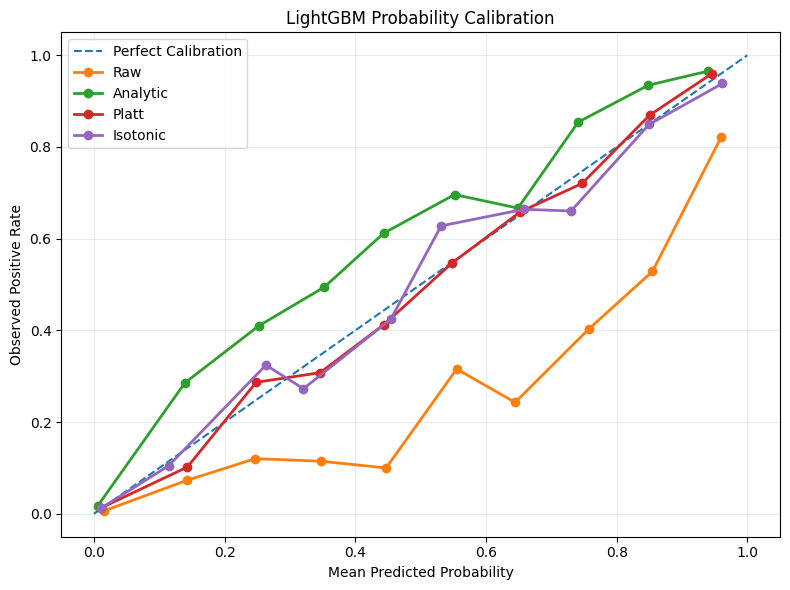

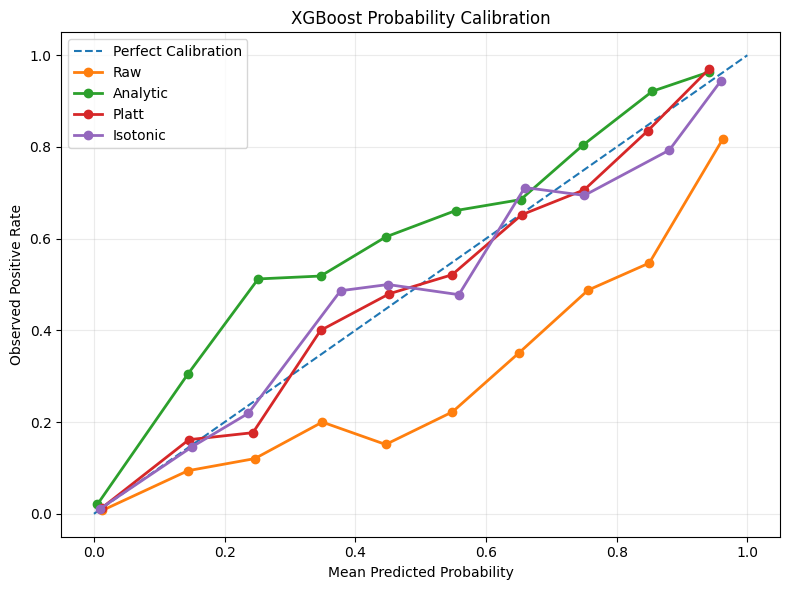

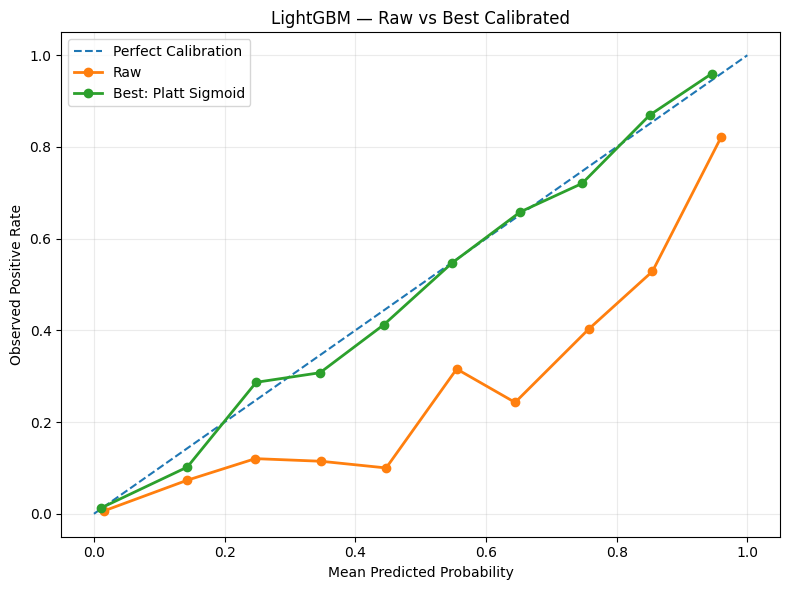

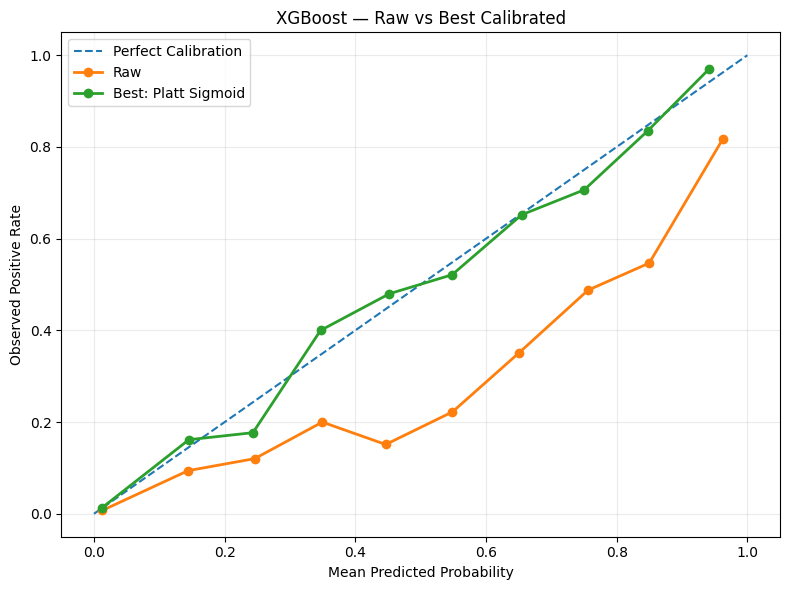


STEP 5A.5 COMPLETE

Input verification
--------------------------------------------------------------------------------
Providers analyzed       : 5,410
Positive providers       : 506
Positive prevalence      : 9.3530%
Models audited           : Logistic_Regression, Random_Forest, LightGBM, XGBoost
Models calibrated        : LightGBM, XGBoost

Methodological safeguards
--------------------------------------------------------------------------------
✓ OOF predictions used
✓ 5,410 labelled providers retained
✓ Provider uniqueness verified
✓ Probability range verified
✓ Leakage-free Platt calibration
✓ Leakage-free isotonic calibration
✓ Mathematical prior correction evaluated separately
✓ Brier decomposition calculated
✓ Reliability tables generated
✓ Reliability diagrams generated
✓ Public 1,353-provider test set untouched

Saved artifacts
--------------------------------------------------------------------------------
1. /content/step_5A5_outputs/step_5A5_raw_probability_audit.csv
2. 

In [19]:
# ============================================================
# STEP 5A.5 — PROBABILITY CALIBRATION & RELIABILITY AUDIT
# ============================================================
#
# Objectives:
#
#   1. Merge OOF predictions from:
#        - Logistic Regression
#        - Class-Weighted Random Forest
#        - LightGBM
#        - XGBoost
#
#   2. Verify:
#        - 5,410 providers
#        - one OOF prediction/provider/model
#        - no missing probabilities
#        - probability range [0,1]
#
#   3. Evaluate raw probability quality:
#        - Brier Score
#        - Log Loss
#        - ECE
#        - Average Precision
#        - ROC-AUC
#
#   4. Compute Brier Score decomposition:
#        Brier = Reliability - Resolution + Uncertainty
#
#   5. Evaluate three calibration approaches:
#
#        Method 1:
#        Mathematical log-odds prior correction
#
#        Method 2:
#        Leakage-free Platt / sigmoid calibration
#
#        Method 3:
#        Leakage-free isotonic regression
#
#   6. Produce reliability tables:
#        - probability bin
#        - number of providers
#        - mean predicted probability
#        - observed positive rate
#        - calibration gap
#
#   7. Produce reliability diagrams.
#
#   8. Export:
#        - raw probability audit
#        - calibration comparison
#        - Brier decomposition
#        - reliability tables
#        - calibrated OOF probabilities
#
# IMPORTANT:
#   The public 1,353-provider test set is NOT loaded or used.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    average_precision_score,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold


# ============================================================
# 1. DISPLAY HEADER
# ============================================================

print("=" * 80)
print("STEP 5A.5 — PROBABILITY CALIBRATION & RELIABILITY AUDIT")
print("=" * 80)


# ============================================================
# 2. PATHS
# ============================================================

PATH_5A = Path(
    "/content/step_5A_outputs/step_5A_oof_predictions.csv"
)

PATH_5A4 = Path(
    "/content/step_5A4_outputs/step_5A4_xgboost_oof_predictions.csv"
)

OUTPUT_DIR_5A5 = Path(
    "/content/step_5A5_outputs"
)

OUTPUT_DIR_5A5.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 3. VERIFY INPUT FILES
# ============================================================

assert PATH_5A.exists(), (
    f"Missing Step 5A OOF prediction file:\n{PATH_5A}"
)

assert PATH_5A4.exists(), (
    f"Missing Step 5A.4 XGBoost OOF prediction file:\n{PATH_5A4}"
)


# ============================================================
# 4. LOAD OOF PREDICTIONS
# ============================================================

df_oof_5a = pd.read_csv(PATH_5A)
df_oof_xgb = pd.read_csv(PATH_5A4)


print("\nInput files loaded successfully.")
print("-" * 80)
print(f"Step 5A OOF shape    : {df_oof_5a.shape}")
print(f"Step 5A.4 OOF shape  : {df_oof_xgb.shape}")


# ============================================================
# 5. IDENTIFY TARGET COLUMN
# ============================================================

if "Actual_Label" in df_oof_5a.columns:

    target_col = "Actual_Label"

elif "PotentialFraud" in df_oof_5a.columns:

    target_col = "PotentialFraud"

else:

    raise KeyError(
        "Could not find target column. "
        "Expected 'Actual_Label' or 'PotentialFraud'."
    )


# ============================================================
# 6. VERIFY PROVIDER COLUMN
# ============================================================

if "Provider" not in df_oof_5a.columns:
    raise KeyError(
        "Provider column missing from Step 5A OOF file."
    )

if "Provider" not in df_oof_xgb.columns:
    raise KeyError(
        "Provider column missing from Step 5A.4 OOF file."
    )


# ============================================================
# 7. VERIFY XGBOOST OOF COLUMN
# ============================================================

if "XGBoost_OOF_Probability" not in df_oof_xgb.columns:

    raise KeyError(
        "XGBoost_OOF_Probability not found in Step 5A.4 OOF file."
    )


# ============================================================
# 8. VERIFY UNIQUE PROVIDERS BEFORE MERGING
# ============================================================

if df_oof_5a["Provider"].duplicated().any():

    duplicated = (
        df_oof_5a.loc[
            df_oof_5a["Provider"].duplicated(keep=False),
            "Provider"
        ]
        .unique()
    )

    raise ValueError(
        f"Step 5A OOF contains duplicate providers. "
        f"Examples: {duplicated[:10]}"
    )


if df_oof_xgb["Provider"].duplicated().any():

    duplicated = (
        df_oof_xgb.loc[
            df_oof_xgb["Provider"].duplicated(keep=False),
            "Provider"
        ]
        .unique()
    )

    raise ValueError(
        f"Step 5A.4 XGBoost OOF contains duplicate providers. "
        f"Examples: {duplicated[:10]}"
    )


# ============================================================
# 9. MERGE OOF PREDICTIONS
# ============================================================

xgb_merge_cols = [
    "Provider",
    "XGBoost_OOF_Probability"
]

if "Validation_Fold" in df_oof_xgb.columns:
    xgb_merge_cols.append("Validation_Fold")


oof_master = df_oof_5a.merge(
    df_oof_xgb[xgb_merge_cols],
    on="Provider",
    how="inner",
    validate="one_to_one"
)


# ============================================================
# 10. RENAME MODEL COLUMNS
# ============================================================

model_column_mapping = {

    "1. Regularized Logistic Regression":
        "Logistic_Regression",

    "2. Class-Weighted Random Forest":
        "Random_Forest",

    "3. LightGBM":
        "LightGBM",

    "XGBoost_OOF_Probability":
        "XGBoost"
}


existing_mapping = {
    old: new
    for old, new in model_column_mapping.items()
    if old in oof_master.columns
}


oof_master = oof_master.rename(
    columns=existing_mapping
)


# ============================================================
# 11. IDENTIFY AVAILABLE MODELS
# ============================================================

candidate_models = [
    "Logistic_Regression",
    "Random_Forest",
    "LightGBM",
    "XGBoost"
]

available_models = [
    model
    for model in candidate_models
    if model in oof_master.columns
]


if len(available_models) == 0:

    raise ValueError(
        "No model probability columns were found."
    )


# ============================================================
# 12. TARGET ARRAY
# ============================================================

y_true = (
    oof_master[target_col]
    .astype(int)
    .to_numpy()
)


# ============================================================
# 13. BASIC DATASET VERIFICATION
# ============================================================

n_providers = len(oof_master)

positive_count = int(np.sum(y_true == 1))
negative_count = int(np.sum(y_true == 0))

prevalence = float(np.mean(y_true))


print("\n" + "=" * 80)
print("OOF DATASET VERIFICATION")
print("=" * 80)

print(f"Providers             : {n_providers:,}")
print(f"Positive providers    : {positive_count:,}")
print(f"Negative providers    : {negative_count:,}")
print(f"Positive prevalence   : {prevalence:.4%}")
print(f"Candidate models      : {available_models}")


# ============================================================
# 14. EXPECTED PROVIDER COUNT CHECK
# ============================================================

assert n_providers == 5410, (
    f"Expected 5,410 providers but found {n_providers}."
)


# ============================================================
# 15. VERIFY TARGET
# ============================================================

unique_targets = set(np.unique(y_true))

assert unique_targets.issubset({0, 1}), (
    f"Unexpected target values found: {unique_targets}"
)


# ============================================================
# 16. VERIFY OOF PROBABILITIES
# ============================================================

print("\nProbability validation")
print("-" * 80)

for model in available_models:

    p = oof_master[model].to_numpy(dtype=float)

    if np.isnan(p).any():

        raise ValueError(
            f"{model}: missing OOF probabilities detected."
        )

    if np.isinf(p).any():

        raise ValueError(
            f"{model}: infinite OOF probabilities detected."
        )

    if np.any(p < 0) or np.any(p > 1):

        raise ValueError(
            f"{model}: probabilities outside [0,1]."
        )

    print(
        f"{model:25s} | "
        f"Min={p.min():.6f} | "
        f"Max={p.max():.6f} | "
        f"Mean={p.mean():.6f}"
    )


# ============================================================
# 17. VERIFY OOF FOLD STRUCTURE
# ============================================================

if "Validation_Fold" in oof_master.columns:

    folds = oof_master["Validation_Fold"].to_numpy()

    print("\nOOF fold verification")
    print("-" * 80)

    print(
        "Unique folds:",
        sorted(pd.Series(folds).dropna().unique().tolist())
    )

    print(
        "Providers per fold:"
    )

    print(
        oof_master["Validation_Fold"]
        .value_counts()
        .sort_index()
        .to_string()
    )


# ============================================================
# 18. HELPER: SAFE PROBABILITY CLIPPING
# ============================================================

def clip_probability(p):

    return np.clip(
        np.asarray(p, dtype=float),
        1e-7,
        1.0 - 1e-7
    )


# ============================================================
# 19. EXPECTED CALIBRATION ERROR
# ============================================================

def compute_ece(
    y_true,
    y_prob,
    n_bins=10
):

    y_true = np.asarray(y_true)
    y_prob = clip_probability(y_prob)

    bins = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    bin_ids = np.digitize(
        y_prob,
        bins,
        right=False
    ) - 1

    bin_ids = np.clip(
        bin_ids,
        0,
        n_bins - 1
    )

    ece = 0.0

    n = len(y_true)

    for i in range(n_bins):

        mask = bin_ids == i

        count = int(np.sum(mask))

        if count == 0:
            continue

        observed_rate = float(
            np.mean(y_true[mask])
        )

        predicted_rate = float(
            np.mean(y_prob[mask])
        )

        ece += (
            count / n
        ) * abs(
            observed_rate - predicted_rate
        )

    return float(ece)


# ============================================================
# 20. BRIER SCORE DECOMPOSITION
# ============================================================
#
# Murphy decomposition:
#
# Brier = Reliability - Resolution + Uncertainty
#
# Reliability:
#   How far predicted probabilities are from observed
#   frequencies inside probability groups.
#
# Resolution:
#   How much the groups differ from the overall prevalence.
#
# Uncertainty:
#   p_bar * (1 - p_bar)
#
# Because the decomposition is bin-based, it depends on
# the chosen bins.
# ============================================================

def brier_decomposition(
    y_true,
    y_prob,
    n_bins=10
):

    y_true = np.asarray(y_true)
    y_prob = clip_probability(y_prob)

    bins = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    bin_ids = np.digitize(
        y_prob,
        bins,
        right=False
    ) - 1

    bin_ids = np.clip(
        bin_ids,
        0,
        n_bins - 1
    )

    overall_rate = float(
        np.mean(y_true)
    )

    reliability = 0.0
    resolution = 0.0

    records = []

    n = len(y_true)

    for i in range(n_bins):

        mask = bin_ids == i

        count = int(np.sum(mask))

        if count == 0:
            continue

        weight = count / n

        mean_pred = float(
            np.mean(y_prob[mask])
        )

        observed_rate = float(
            np.mean(y_true[mask])
        )

        reliability += (
            weight
            * (mean_pred - observed_rate) ** 2
        )

        resolution += (
            weight
            * (observed_rate - overall_rate) ** 2
        )

        records.append({

            "Bin": i + 1,

            "Bin_Lower":
                float(bins[i]),

            "Bin_Upper":
                float(bins[i + 1]),

            "Provider_Count":
                count,

            "Bin_Weight":
                weight,

            "Mean_Predicted_Probability":
                mean_pred,

            "Observed_Positive_Rate":
                observed_rate,

            "Calibration_Gap":
                mean_pred - observed_rate
        })


    uncertainty = (
        overall_rate
        * (1.0 - overall_rate)
    )

    brier = float(
        brier_score_loss(
            y_true,
            y_prob
        )
    )

    reconstructed_brier = (
        reliability
        - resolution
        + uncertainty
    )

    decomposition_error = (
        brier
        - reconstructed_brier
    )

    decomposition_table = pd.DataFrame(
        records
    )

    return {

        "Brier_Score":
            brier,

        "Reliability":
            float(reliability),

        "Resolution":
            float(resolution),

        "Uncertainty":
            float(uncertainty),

        "Reconstructed_Brier":
            float(reconstructed_brier),

        "Decomposition_Error":
            float(decomposition_error),

        "Bin_Table":
            decomposition_table
    }


# ============================================================
# 21. RAW PROBABILITY AUDIT
# ============================================================

raw_records = []

raw_decomposition_tables = {}


for model in available_models:

    p = clip_probability(
        oof_master[model].to_numpy()
    )

    brier_info = brier_decomposition(
        y_true,
        p,
        n_bins=10
    )

    raw_decomposition_tables[model] = (
        brier_info["Bin_Table"]
    )

    raw_records.append({

        "Model":
            model,

        "Mean_Predicted_Probability":
            float(np.mean(p)),

        "Actual_Prevalence":
            prevalence,

        "Mean_Probability_Bias":
            float(np.mean(p) - prevalence),

        "Brier_Score":
            brier_info["Brier_Score"],

        "Brier_Reliability":
            brier_info["Reliability"],

        "Brier_Resolution":
            brier_info["Resolution"],

        "Brier_Uncertainty":
            brier_info["Uncertainty"],

        "Brier_Reconstructed":
            brier_info["Reconstructed_Brier"],

        "Brier_Decomposition_Error":
            brier_info["Decomposition_Error"],

        "ECE_10_Bins":
            compute_ece(
                y_true,
                p,
                n_bins=10
            ),

        "Log_Loss":
            float(
                log_loss(
                    y_true,
                    p
                )
            ),

        "Average_Precision":
            float(
                average_precision_score(
                    y_true,
                    p
                )
            ),

        "ROC_AUC":
            float(
                roc_auc_score(
                    y_true,
                    p
                )
            )
    })


raw_audit_df = (
    pd.DataFrame(raw_records)
    .sort_values(
        "Brier_Score"
    )
    .reset_index(drop=True)
)


# ============================================================
# 22. DISPLAY RAW AUDIT
# ============================================================

print("\n" + "=" * 80)
print("RAW UNCALIBRATED PROBABILITY AUDIT")
print("=" * 80)

display(
    raw_audit_df.round(5)
)


# ============================================================
# 23. MATHEMATICAL LOG-ODDS PRIOR CORRECTION
# ============================================================
#
# For a classifier trained using positive-class weighting:
#
# weighted log-odds ≈ true log-odds + log(weight)
#
# Therefore:
#
# corrected_logit =
#       raw_logit - log(weight)
#
# Here the known class imbalance ratio is:
#
#       negative / positive
#
# which was used as scale_pos_weight for XGBoost.
#
# IMPORTANT:
# This is a mathematical prior correction, NOT a learned
# calibration method.
#
# We apply it only to the boosting models for which the
# training procedure explicitly used scale_pos_weight.
# ============================================================

imbalance_ratio = (
    negative_count /
    positive_count
)


def analytic_prior_correction(
    p_raw,
    scale_pos_weight
):

    p_raw = clip_probability(
        p_raw
    )

    raw_logit = np.log(
        p_raw /
        (1.0 - p_raw)
    )

    corrected_logit = (
        raw_logit
        - np.log(scale_pos_weight)
    )

    corrected_logit = np.clip(
        corrected_logit,
        -50,
        50
    )

    p_corrected = (
        1.0 /
        (
            1.0 +
            np.exp(-corrected_logit)
        )
    )

    return p_corrected


# ============================================================
# 24. LEAKAGE-FREE PLATT CALIBRATION
# ============================================================
#
# We use the OOF predictions as the input to the calibrator.
#
# For every validation subset:
#
#   calibrator is fitted on OTHER OOF predictions
#   and evaluated on the held-out OOF predictions.
#
# Therefore a provider's own label is never used to calibrate
# its own probability.
#
# We fit Platt scaling on LOG-ODDS rather than raw probability.
# This corresponds more closely to standard sigmoid calibration.
# ============================================================

def leakage_free_platt(
    y_true,
    p_raw,
    n_splits=5,
    random_state=42
):

    y_true = np.asarray(y_true).astype(int)
    p_raw = clip_probability(p_raw)

    logit_p = np.log(
        p_raw /
        (1.0 - p_raw)
    )

    calibrated = np.zeros(
        len(y_true),
        dtype=float
    )

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    for train_idx, val_idx in cv.split(
        logit_p.reshape(-1, 1),
        y_true
    ):

        X_train = (
            logit_p[train_idx]
            .reshape(-1, 1)
        )

        X_val = (
            logit_p[val_idx]
            .reshape(-1, 1)
        )

        y_train = y_true[train_idx]

        calibrator = LogisticRegression(
            C=1e5,
            solver="lbfgs",
            max_iter=1000,
            random_state=random_state
        )

        calibrator.fit(
            X_train,
            y_train
        )

        calibrated[val_idx] = (
            calibrator
            .predict_proba(X_val)[:, 1]
        )

    return np.clip(
        calibrated,
        1e-7,
        1.0 - 1e-7
    )


# ============================================================
# 25. LEAKAGE-FREE ISOTONIC CALIBRATION
# ============================================================

def leakage_free_isotonic(
    y_true,
    p_raw,
    n_splits=5,
    random_state=42
):

    y_true = np.asarray(y_true).astype(int)
    p_raw = clip_probability(p_raw)

    calibrated = np.zeros(
        len(y_true),
        dtype=float
    )

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    for train_idx, val_idx in cv.split(
        p_raw.reshape(-1, 1),
        y_true
    ):

        p_train = p_raw[train_idx]
        y_train = y_true[train_idx]

        p_val = p_raw[val_idx]

        calibrator = IsotonicRegression(
            y_min=0.0,
            y_max=1.0,
            out_of_bounds="clip"
        )

        calibrator.fit(
            p_train,
            y_train
        )

        calibrated[val_idx] = (
            calibrator.predict(p_val)
        )

    return np.clip(
        calibrated,
        1e-7,
        1.0 - 1e-7
    )


# ============================================================
# 26. CALIBRATION EXPERIMENT
# ============================================================
#
# We focus post-processing on:
#
#   - LightGBM
#   - XGBoost
#
# because these are currently the two leading nonlinear
# investigation models.
#
# Logistic Regression and Random Forest remain in the raw
# calibration audit.
# ============================================================

target_models_for_calibration = [
    model
    for model in [
        "LightGBM",
        "XGBoost"
    ]
    if model in available_models
]


calibrated_oof = pd.DataFrame({

    "Provider":
        oof_master["Provider"].values,

    "PotentialFraud":
        y_true
})


calibration_records = []

reliability_tables = {}


for model_name in target_models_for_calibration:

    print("\n" + "=" * 80)
    print(f"CALIBRATION: {model_name}")
    print("=" * 80)

    p_raw = clip_probability(
        oof_master[model_name].to_numpy()
    )


    # --------------------------------------------------------
    # Method 0: RAW
    # --------------------------------------------------------

    p_raw_eval = p_raw


    # --------------------------------------------------------
    # Method 1: ANALYTIC PRIOR CORRECTION
    # --------------------------------------------------------
    #
    # Applicable to the boosting models because both were
    # trained with positive-class weighting / scale_pos_weight.
    # --------------------------------------------------------

    p_analytic = analytic_prior_correction(
        p_raw,
        imbalance_ratio
    )


    # --------------------------------------------------------
    # Method 2: PLATT / SIGMOID
    # --------------------------------------------------------

    p_platt = leakage_free_platt(
        y_true,
        p_raw,
        n_splits=5,
        random_state=42
    )


    # --------------------------------------------------------
    # Method 3: ISOTONIC
    # --------------------------------------------------------

    p_isotonic = leakage_free_isotonic(
        y_true,
        p_raw,
        n_splits=5,
        random_state=42
    )


    # --------------------------------------------------------
    # SAVE OOF PROBABILITIES
    # --------------------------------------------------------

    calibrated_oof[
        f"{model_name}_Raw"
    ] = p_raw

    calibrated_oof[
        f"{model_name}_Analytic"
    ] = p_analytic

    calibrated_oof[
        f"{model_name}_Platt"
    ] = p_platt

    calibrated_oof[
        f"{model_name}_Isotonic"
    ] = p_isotonic


    # --------------------------------------------------------
    # EVALUATE ALL METHODS
    # --------------------------------------------------------

    variants = {

        "Raw":
            p_raw,

        "Analytic Prior Correction":
            p_analytic,

        "Platt Sigmoid":
            p_platt,

        "Isotonic":
            p_isotonic
    }


    for method_name, p_eval in variants.items():

        p_eval = clip_probability(
            p_eval
        )

        brier_info = brier_decomposition(
            y_true,
            p_eval,
            n_bins=10
        )

        calibration_records.append({

            "Base_Model":
                model_name,

            "Calibration_Method":
                method_name,

            "Mean_Predicted_Probability":
                float(np.mean(p_eval)),

            "Actual_Prevalence":
                prevalence,

            "Mean_Probability_Bias":
                float(
                    np.mean(p_eval)
                    - prevalence
                ),

            "Brier_Score":
                brier_info["Brier_Score"],

            "Brier_Reliability":
                brier_info["Reliability"],

            "Brier_Resolution":
                brier_info["Resolution"],

            "Brier_Uncertainty":
                brier_info["Uncertainty"],

            "Brier_Reconstructed":
                brier_info["Reconstructed_Brier"],

            "Brier_Decomposition_Error":
                brier_info["Decomposition_Error"],

            "ECE_10_Bins":
                compute_ece(
                    y_true,
                    p_eval,
                    n_bins=10
                ),

            "Log_Loss":
                float(
                    log_loss(
                        y_true,
                        p_eval
                    )
                ),

            "Average_Precision":
                float(
                    average_precision_score(
                        y_true,
                        p_eval
                    )
                ),

            "ROC_AUC":
                float(
                    roc_auc_score(
                        y_true,
                        p_eval
                    )
                )
        })


        # ----------------------------------------------------
        # RELIABILITY TABLE
        # ----------------------------------------------------

        reliability_info = brier_decomposition(
            y_true,
            p_eval,
            n_bins=10
        )

        reliability_tables[
            f"{model_name}_{method_name}"
        ] = reliability_info["Bin_Table"]


# ============================================================
# 27. CALIBRATION RESULTS DATAFRAME
# ============================================================

calibration_results_df = (
    pd.DataFrame(
        calibration_records
    )
    .sort_values(
        [
            "Base_Model",
            "Brier_Score"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# 28. DISPLAY CALIBRATION RESULTS
# ============================================================

print("\n" + "=" * 80)
print("CALIBRATION BENCHMARK COMPARISON")
print("=" * 80)

display(
    calibration_results_df.round(5)
)


# ============================================================
# 29. SELECT BEST CALIBRATION METHOD PER MODEL
# ============================================================

best_calibration_df = (
    calibration_results_df
    .sort_values(
        [
            "Base_Model",
            "Brier_Score"
        ]
    )
    .groupby(
        "Base_Model",
        as_index=False
    )
    .first()
)


print("\n" + "=" * 80)
print("BEST CALIBRATION METHOD BY BASE MODEL")
print("=" * 80)

display(
    best_calibration_df.round(5)
)


# ============================================================
# 30. RELIABILITY TABLE FUNCTION
# ============================================================

def generate_reliability_table(
    y_true,
    y_prob,
    n_bins=10
):

    y_true = np.asarray(y_true)
    y_prob = clip_probability(y_prob)

    bins = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    bin_ids = np.digitize(
        y_prob,
        bins,
        right=False
    ) - 1

    bin_ids = np.clip(
        bin_ids,
        0,
        n_bins - 1
    )

    records = []

    for i in range(n_bins):

        mask = bin_ids == i

        count = int(
            np.sum(mask)
        )

        if count == 0:
            records.append({

                "Bin":
                    i + 1,

                "Probability_Range":
                    f"{bins[i]:.1f}–{bins[i+1]:.1f}",

                "Provider_Count":
                    0,

                "Mean_Predicted_Probability":
                    np.nan,

                "Observed_Positive_Rate":
                    np.nan,

                "Calibration_Gap":
                    np.nan
            })

            continue


        mean_pred = float(
            np.mean(
                y_prob[mask]
            )
        )

        observed_rate = float(
            np.mean(
                y_true[mask]
            )
        )


        records.append({

            "Bin":
                i + 1,

            "Probability_Range":
                f"{bins[i]:.1f}–{bins[i+1]:.1f}",

            "Provider_Count":
                count,

            "Mean_Predicted_Probability":
                mean_pred,

            "Observed_Positive_Rate":
                observed_rate,

            "Calibration_Gap":
                mean_pred - observed_rate
        })


    return pd.DataFrame(
        records
    )


# ============================================================
# 31. RELIABILITY TABLES FOR LIGHTGBM
# ============================================================

if "LightGBM" in target_models_for_calibration:

    print("\n" + "=" * 80)
    print("LIGHTGBM RELIABILITY TABLES")
    print("=" * 80)


    lgb_methods = {

        "Raw":
            calibrated_oof[
                "LightGBM_Raw"
            ].to_numpy(),

        "Analytic":
            calibrated_oof[
                "LightGBM_Analytic"
            ].to_numpy(),

        "Platt":
            calibrated_oof[
                "LightGBM_Platt"
            ].to_numpy(),

        "Isotonic":
            calibrated_oof[
                "LightGBM_Isotonic"
            ].to_numpy()
    }


    for method_name, probabilities in lgb_methods.items():

        print(
            f"\nLightGBM — {method_name}"
        )

        table = generate_reliability_table(
            y_true,
            probabilities,
            n_bins=10
        )

        display(
            table.round(5)
        )


# ============================================================
# 32. RELIABILITY TABLES FOR XGBOOST
# ============================================================

if "XGBoost" in target_models_for_calibration:

    print("\n" + "=" * 80)
    print("XGBOOST RELIABILITY TABLES")
    print("=" * 80)


    xgb_methods = {

        "Raw":
            calibrated_oof[
                "XGBoost_Raw"
            ].to_numpy(),

        "Analytic":
            calibrated_oof[
                "XGBoost_Analytic"
            ].to_numpy(),

        "Platt":
            calibrated_oof[
                "XGBoost_Platt"
            ].to_numpy(),

        "Isotonic":
            calibrated_oof[
                "XGBoost_Isotonic"
            ].to_numpy()
    }


    for method_name, probabilities in xgb_methods.items():

        print(
            f"\nXGBoost — {method_name}"
        )

        table = generate_reliability_table(
            y_true,
            probabilities,
            n_bins=10
        )

        display(
            table.round(5)
        )


# ============================================================
# 33. RELIABILITY DIAGRAMS
# ============================================================
#
# We create separate figures rather than crowded subplots.
#
# Each diagram compares:
#
#   x-axis = predicted probability
#   y-axis = observed positive rate
#
# Perfect calibration = diagonal line.
# ============================================================


def plot_reliability_diagram(
    y_true,
    probability_dict,
    title,
    output_path
):

    plt.figure(
        figsize=(8, 6)
    )

    # Perfect calibration line
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect Calibration"
    )


    for method_name, probabilities in probability_dict.items():

        prob_true, prob_pred = calibration_curve(
            y_true,
            clip_probability(probabilities),
            n_bins=10,
            strategy="uniform"
        )

        plt.plot(
            prob_pred,
            prob_true,
            marker="o",
            linewidth=2,
            label=method_name
        )


    plt.xlabel(
        "Mean Predicted Probability"
    )

    plt.ylabel(
        "Observed Positive Rate"
    )

    plt.title(
        title
    )

    plt.legend()

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# 34. LIGHTGBM RELIABILITY DIAGRAM
# ============================================================

if "LightGBM" in target_models_for_calibration:

    lgb_plot_data = {

        "Raw":
            calibrated_oof[
                "LightGBM_Raw"
            ].to_numpy(),

        "Analytic":
            calibrated_oof[
                "LightGBM_Analytic"
            ].to_numpy(),

        "Platt":
            calibrated_oof[
                "LightGBM_Platt"
            ].to_numpy(),

        "Isotonic":
            calibrated_oof[
                "LightGBM_Isotonic"
            ].to_numpy()
    }


    plot_reliability_diagram(

        y_true,

        lgb_plot_data,

        "LightGBM Probability Calibration",

        OUTPUT_DIR_5A5 /
        "step_5A5_lightgbm_reliability_diagram.png"
    )


# ============================================================
# 35. XGBOOST RELIABILITY DIAGRAM
# ============================================================

if "XGBoost" in target_models_for_calibration:

    xgb_plot_data = {

        "Raw":
            calibrated_oof[
                "XGBoost_Raw"
            ].to_numpy(),

        "Analytic":
            calibrated_oof[
                "XGBoost_Analytic"
            ].to_numpy(),

        "Platt":
            calibrated_oof[
                "XGBoost_Platt"
            ].to_numpy(),

        "Isotonic":
            calibrated_oof[
                "XGBoost_Isotonic"
            ].to_numpy()
    }


    plot_reliability_diagram(

        y_true,

        xgb_plot_data,

        "XGBoost Probability Calibration",

        OUTPUT_DIR_5A5 /
        "step_5A5_xgboost_reliability_diagram.png"
    )


# ============================================================
# 36. COMBINED RAW VS BEST CALIBRATED DIAGRAM
# ============================================================

# Determine best method according to Brier score.

best_methods = {}

for model_name in target_models_for_calibration:

    model_results = (
        calibration_results_df[
            calibration_results_df["Base_Model"]
            == model_name
        ]
    )

    best_row = (
        model_results
        .sort_values("Brier_Score")
        .iloc[0]
    )

    best_methods[model_name] = (
        best_row["Calibration_Method"]
    )


# ------------------------------------------------------------
# Map method names to OOF columns
# ------------------------------------------------------------

method_column_map = {

    "Raw":
        "Raw",

    "Analytic Prior Correction":
        "Analytic",

    "Platt Sigmoid":
        "Platt",

    "Isotonic":
        "Isotonic"
}


# ------------------------------------------------------------
# LightGBM best calibrated comparison
# ------------------------------------------------------------

if "LightGBM" in target_models_for_calibration:

    best_method = best_methods[
        "LightGBM"
    ]

    best_suffix = method_column_map[
        best_method
    ]

    comparison_data = {

        "Raw":
            calibrated_oof[
                "LightGBM_Raw"
            ].to_numpy(),

        f"Best: {best_method}":
            calibrated_oof[
                f"LightGBM_{best_suffix}"
            ].to_numpy()
    }


    plot_reliability_diagram(

        y_true,

        comparison_data,

        "LightGBM — Raw vs Best Calibrated",

        OUTPUT_DIR_5A5 /
        "step_5A5_lightgbm_raw_vs_best.png"
    )


# ------------------------------------------------------------
# XGBoost best calibrated comparison
# ------------------------------------------------------------

if "XGBoost" in target_models_for_calibration:

    best_method = best_methods[
        "XGBoost"
    ]

    best_suffix = method_column_map[
        best_method
    ]

    comparison_data = {

        "Raw":
            calibrated_oof[
                "XGBoost_Raw"
            ].to_numpy(),

        f"Best: {best_method}":
            calibrated_oof[
                f"XGBoost_{best_suffix}"
            ].to_numpy()
    }


    plot_reliability_diagram(

        y_true,

        comparison_data,

        "XGBoost — Raw vs Best Calibrated",

        OUTPUT_DIR_5A5 /
        "step_5A5_xgboost_raw_vs_best.png"
    )


# ============================================================
# 37. SAVE RAW AUDIT
# ============================================================

raw_audit_path = (
    OUTPUT_DIR_5A5 /
    "step_5A5_raw_probability_audit.csv"
)

raw_audit_df.to_csv(
    raw_audit_path,
    index=False
)


# ============================================================
# 38. SAVE CALIBRATION BENCHMARKS
# ============================================================

calibration_results_path = (
    OUTPUT_DIR_5A5 /
    "step_5A5_calibration_benchmarks.csv"
)

calibration_results_df.to_csv(
    calibration_results_path,
    index=False
)


# ============================================================
# 39. SAVE BEST CALIBRATION METHODS
# ============================================================

best_methods_path = (
    OUTPUT_DIR_5A5 /
    "step_5A5_best_calibration_methods.csv"
)

best_calibration_df.to_csv(
    best_methods_path,
    index=False
)


# ============================================================
# 40. SAVE CALIBRATED OOF PREDICTIONS
# ============================================================

calibrated_oof_path = (
    OUTPUT_DIR_5A5 /
    "step_5A5_calibrated_oof_predictions.csv"
)

calibrated_oof.to_csv(
    calibrated_oof_path,
    index=False
)


# ============================================================
# 41. SAVE BRIER DECOMPOSITION TABLES
# ============================================================

brier_decomposition_records = []


for model in available_models:

    if model in target_models_for_calibration:

        methods_to_save = {

            "Raw":
                calibrated_oof[
                    f"{model}_Raw"
                ].to_numpy(),

            "Analytic":
                calibrated_oof[
                    f"{model}_Analytic"
                ].to_numpy(),

            "Platt":
                calibrated_oof[
                    f"{model}_Platt"
                ].to_numpy(),

            "Isotonic":
                calibrated_oof[
                    f"{model}_Isotonic"
                ].to_numpy()
        }

    else:

        methods_to_save = {

            "Raw":
                oof_master[
                    model
                ].to_numpy()
        }


    for method_name, probabilities in methods_to_save.items():

        info = brier_decomposition(
            y_true,
            probabilities,
            n_bins=10
        )

        brier_decomposition_records.append({

            "Model":
                model,

            "Method":
                method_name,

            "Brier_Score":
                info["Brier_Score"],

            "Reliability":
                info["Reliability"],

            "Resolution":
                info["Resolution"],

            "Uncertainty":
                info["Uncertainty"],

            "Reconstructed_Brier":
                info["Reconstructed_Brier"],

            "Decomposition_Error":
                info["Decomposition_Error"]
        })


brier_decomposition_df = pd.DataFrame(
    brier_decomposition_records
)


brier_decomposition_path = (
    OUTPUT_DIR_5A5 /
    "step_5A5_brier_decomposition.csv"
)

brier_decomposition_df.to_csv(
    brier_decomposition_path,
    index=False
)


# ============================================================
# 42. SAVE RELIABILITY TABLES
# ============================================================

reliability_output_dir = (
    OUTPUT_DIR_5A5 /
    "reliability_tables"
)

reliability_output_dir.mkdir(
    parents=True,
    exist_ok=True
)


for table_name, table in reliability_tables.items():

    safe_name = (
        table_name
        .replace(" ", "_")
        .replace("/", "_")
    )

    table.to_csv(
        reliability_output_dir /
        f"{safe_name}.csv",
        index=False
    )


# ============================================================
# 43. SAVE DATASET / METHOD SUMMARY
# ============================================================

audit_metadata = pd.DataFrame({

    "Item": [

        "Providers",

        "Positive_Providers",

        "Negative_Providers",

        "Positive_Prevalence",

        "Imbalance_Ratio",

        "OOF_CV_Folds",

        "Random_Seed",

        "Calibration_Bins",

        "Public_Test_Providers_Used",

        "Calibration_Models"
    ],

    "Value": [

        n_providers,

        positive_count,

        negative_count,

        prevalence,

        imbalance_ratio,

        5,

        42,

        10,

        "NO",

        ", ".join(
            target_models_for_calibration
        )
    ]
})


metadata_path = (
    OUTPUT_DIR_5A5 /
    "step_5A5_audit_metadata.csv"
)

audit_metadata.to_csv(
    metadata_path,
    index=False
)


# ============================================================
# 44. FINAL OUTPUT SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("STEP 5A.5 COMPLETE")
print("=" * 80)

print("\nInput verification")
print("-" * 80)
print(f"Providers analyzed       : {n_providers:,}")
print(f"Positive providers       : {positive_count:,}")
print(f"Positive prevalence      : {prevalence:.4%}")
print(f"Models audited           : {', '.join(available_models)}")
print(
    f"Models calibrated        : "
    f"{', '.join(target_models_for_calibration)}"
)

print("\nMethodological safeguards")
print("-" * 80)
print("✓ OOF predictions used")
print("✓ 5,410 labelled providers retained")
print("✓ Provider uniqueness verified")
print("✓ Probability range verified")
print("✓ Leakage-free Platt calibration")
print("✓ Leakage-free isotonic calibration")
print("✓ Mathematical prior correction evaluated separately")
print("✓ Brier decomposition calculated")
print("✓ Reliability tables generated")
print("✓ Reliability diagrams generated")
print("✓ Public 1,353-provider test set untouched")

print("\nSaved artifacts")
print("-" * 80)

print(
    f"1. {raw_audit_path}"
)

print(
    f"2. {calibration_results_path}"
)

print(
    f"3. {best_methods_path}"
)

print(
    f"4. {calibrated_oof_path}"
)

print(
    f"5. {brier_decomposition_path}"
)

print(
    f"6. {reliability_output_dir}/"
)

print(
    f"7. {metadata_path}"
)

print(
    f"8. "
    f"{OUTPUT_DIR_5A5 / 'step_5A5_lightgbm_reliability_diagram.png'}"
)

print(
    f"9. "
    f"{OUTPUT_DIR_5A5 / 'step_5A5_xgboost_reliability_diagram.png'}"
)

print(
    f"10. "
    f"{OUTPUT_DIR_5A5 / 'step_5A5_lightgbm_raw_vs_best.png'}"
)

print(
    f"11. "
    f"{OUTPUT_DIR_5A5 / 'step_5A5_xgboost_raw_vs_best.png'}"
)

print("\n" + "=" * 80)
print("✓ STEP 5A.5 — PROBABILITY CALIBRATION AUDIT FINISHED")
print("=" * 80)

print(
    "\nNext stage should be model-selection + investigation-policy "
    "analysis, using the calibration results rather than selecting "
    "a model from AP alone."
)

STEP 5A.6 — INVESTIGATION CAPACITY & DECISION POLICY

Loaded files:
  Calibrated OOF predictions : (5410, 10)
  Modeling matrix            : (5410, 64)

POLICY DATASET SUMMARY
Providers                  : 5,410
Label-positive providers   : 506
Positive prevalence        : 9.3530%
Total reimbursement        : $556,543,140.00
Label-positive exposure    : $295,681,120.00

THRESHOLD ANALYSIS — LIGHTGBM + PLATT


,Criterion,Threshold,Providers_Selected,Precision,Recall,F1,F2,Youden_J,Exposure_Capture_Rate,Exposure_Yield
0,Maximum F1,0.4100,520.0000,0.7058,0.7253,0.7154,0.7213,0.6941,0.9188,0.8149
1,Maximum F2,0.1900,748.0000,0.5749,0.8498,0.6858,0.7756,0.7850,0.9669,0.7434
2,Maximum Youden J,0.0800,"1,007.0000",0.4558,0.9071,0.6067,0.7572,0.7954,0.9837,0.6813



INVESTIGATION CAPACITY ANALYSIS


,Audit_Capacity_K,Probability_Cutoff,Potential_Fraud_Providers_Captured,False_Alarms,Precision_at_K,Recall_at_K,Lift_at_K,Audited_Exposure,Potential_Fraud_Exposure_Captured,Exposure_Capture_Rate,Exposure_Yield
0,25,0.9618,25,0,1.0000,0.0494,10.6917,"51,559,570.0000","51,559,570.0000",0.1744,1.0000
1,50,0.9449,48,2,0.9600,0.0949,10.2640,"91,924,280.0000","89,574,250.0000",0.3029,0.9744
2,100,0.9017,96,4,0.9600,0.1897,10.2640,"149,745,400.0000","145,319,280.0000",0.4915,0.9704
3,150,0.8296,141,9,0.9400,0.2787,10.0502,"186,051,520.0000","178,022,560.0000",0.6021,0.9568
4,200,0.7697,180,20,0.9000,0.3557,9.6225,"212,321,900.0000","199,941,040.0000",0.6762,0.9417
5,250,0.7110,215,35,0.8600,0.4249,9.1949,"234,812,300.0000","216,319,130.0000",0.7316,0.9212
6,300,0.6579,248,52,0.8267,0.4901,8.8385,"258,148,340.0000","229,748,550.0000",0.7770,0.8900
7,500,0.4282,357,143,0.7140,0.7055,7.6339,"327,492,720.0000","269,203,450.0000",0.9105,0.8220



MODEL RANKING VS RANDOM INVESTIGATION


,Audit_Capacity_K,Precision_at_K,Random_Baseline_Precision,Lift_at_K,Recall_at_K,Exposure_Capture_Rate
0,25,1.0000,0.0935,10.6917,0.0494,0.1744
1,50,0.9600,0.0935,10.2640,0.0949,0.3029
2,100,0.9600,0.0935,10.2640,0.1897,0.4915
3,150,0.9400,0.0935,10.0502,0.2787,0.6021
4,200,0.9000,0.0935,9.6225,0.3557,0.6762
5,250,0.8600,0.0935,9.1949,0.4249,0.7316
6,300,0.8267,0.0935,8.8385,0.4901,0.7770
7,500,0.7140,0.0935,7.6339,0.7055,0.9105


... (2 outputs left out)


LIGHTGBM VS XGBOOST — INVESTIGATION CAPACITY


,K,LightGBM_TP,LightGBM_Precision,LightGBM_Recall,XGBoost_TP,XGBoost_Precision,XGBoost_Recall
0,25,25,1.0000,0.0494,25,1.0000,0.0494
1,50,48,0.9600,0.0949,49,0.9800,0.0968
2,100,96,0.9600,0.1897,97,0.9700,0.1917
3,150,141,0.9400,0.2787,140,0.9333,0.2767
4,200,180,0.9000,0.3557,176,0.8800,0.3478
5,250,215,0.8600,0.4249,213,0.8520,0.4209
6,300,248,0.8267,0.4901,247,0.8233,0.4881
7,500,357,0.7140,0.7055,353,0.7060,0.6976



LIGHTGBM / XGBOOST INVESTIGATION QUEUE OVERLAP


,K,Common_Providers,Queue_Overlap_Rate
0,25,18,0.7200
1,50,33,0.6600
2,100,84,0.8400
3,150,129,0.8600
4,200,171,0.8550
5,250,218,0.8720
6,300,261,0.8700
7,500,465,0.9300


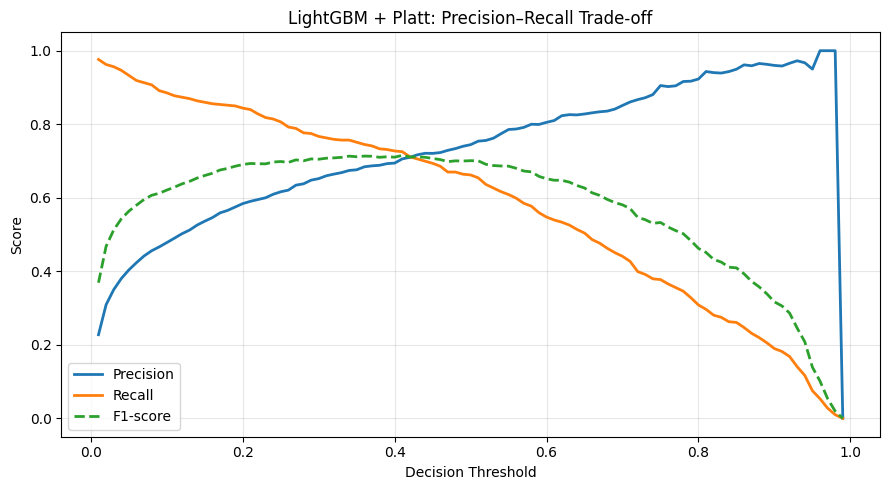

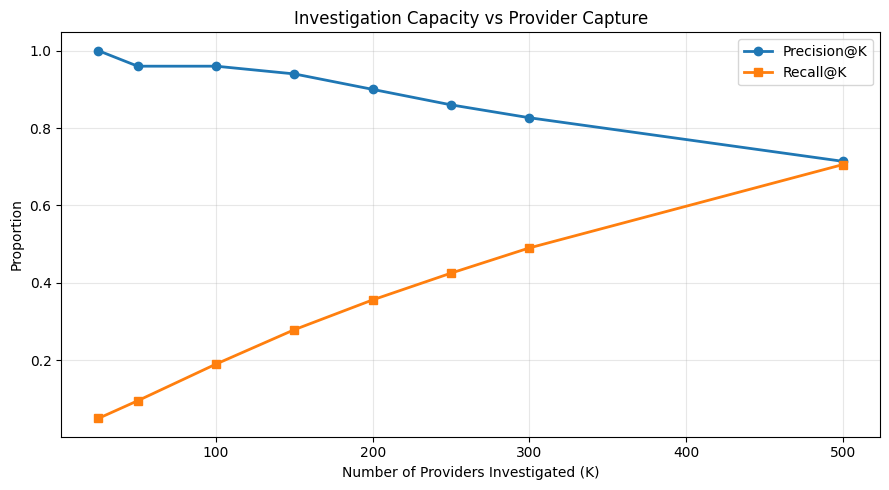

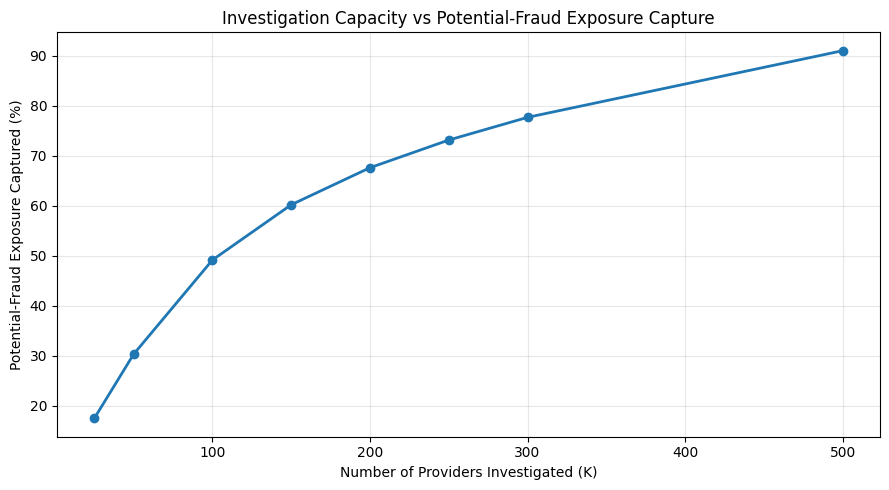


STEP 5A.6 OUTPUTS
✓ Threshold analysis      : /content/step_5A6_outputs/step_5A6_threshold_analysis.csv
✓ Capacity analysis       : /content/step_5A6_outputs/step_5A6_capacity_analysis.csv
✓ Investigation tiers     : /content/step_5A6_outputs/step_5A6_investigation_tiers.csv
✓ Provider policy         : /content/step_5A6_outputs/step_5A6_provider_investigation_policy.csv
✓ Model comparison        : /content/step_5A6_outputs/step_5A6_lightgbm_vs_xgboost_capacity.csv
✓ Queue overlap           : /content/step_5A6_outputs/step_5A6_model_queue_overlap.csv
✓ Threshold plot          : /content/step_5A6_outputs/step_5A6_threshold_tradeoff.png
✓ Capacity plot           : /content/step_5A6_outputs/step_5A6_capacity_tradeoff.png
✓ Exposure plot           : /content/step_5A6_outputs/step_5A6_exposure_capture.png

✓ STEP 5A.6 COMPLETE

Primary operational analysis:
  LightGBM + Platt calibrated probabilities
  → ranked investigation queue
  → Precision@K
  → Recall@K
  → Lift@K
  → potential-fraud 

In [20]:
# ============================================================
# STEP 5A.6 — INVESTIGATION CAPACITY & DECISION POLICY
# ============================================================
#
# Purpose:
#   We now move from "How good is the model?" to:
#
#   "How should an investigation team actually use the model?"
#
# Main questions:
#   1. How does the calibrated probability behave at different
#      decision thresholds?
#
#   2. If the investigation team can review only K providers,
#      which providers should be prioritized?
#
#   3. How many label-positive providers are captured?
#
#   4. How much reimbursement exposure is contained in the
#      selected investigation queue?
#
#   5. How much better is the model's ranking than random
#      selection?
#
# Important:
#   PotentialFraud is a dataset label, NOT confirmed fraud.
#   Therefore we use terms such as:
#       - potential-fraud provider
#       - potential-fraud exposure
#       - exposure captured
#
#   We do NOT claim that money was actually recovered.
#
# ============================================================

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    fbeta_score
)


print("=" * 80)
print("STEP 5A.6 — INVESTIGATION CAPACITY & DECISION POLICY")
print("=" * 80)


# ============================================================
# 1. Paths
# ============================================================

OUTPUT_DIR = Path("/content/step_5A6_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CALIBRATED_FILE = Path(
    "/content/step_5A5_outputs/step_5A5_calibrated_oof_predictions.csv"
)

MODEL_MATRIX_FILE = Path(
    "/content/step_4G_outputs/step_4G_clean_modeling_matrix.csv"
)


assert CALIBRATED_FILE.exists(), (
    f"Calibrated OOF file not found:\n{CALIBRATED_FILE}"
)

assert MODEL_MATRIX_FILE.exists(), (
    f"Modeling matrix not found:\n{MODEL_MATRIX_FILE}"
)


# ============================================================
# 2. Load calibrated OOF predictions and financial information
# ============================================================

calibrated_oof = pd.read_csv(CALIBRATED_FILE)
modeling_matrix = pd.read_csv(MODEL_MATRIX_FILE)

print("\nLoaded files:")
print(f"  Calibrated OOF predictions : {calibrated_oof.shape}")
print(f"  Modeling matrix            : {modeling_matrix.shape}")


# ------------------------------------------------------------
# We need:
#   Provider
#   PotentialFraud
#   LightGBM_Platt
#   XGBoost_Platt
#   Total_Reimbursement
#
# The reimbursement amount is used only to understand the
# financial scale of the investigation queue.
# ------------------------------------------------------------

required_prediction_columns = [
    "Provider",
    "PotentialFraud",
    "LightGBM_Platt",
    "XGBoost_Platt"
]

for column in required_prediction_columns:
    assert column in calibrated_oof.columns, (
        f"Required column '{column}' is missing from "
        f"the calibrated OOF file."
    )

assert "Provider" in modeling_matrix.columns
assert "Total_Reimbursement" in modeling_matrix.columns


# ------------------------------------------------------------
# Keep only the financial columns we actually need.
# ------------------------------------------------------------

financial_columns = [
    "Provider",
    "Total_Reimbursement",
    "IP_Total_Reimbursement",
    "OP_Total_Reimbursement"
]

available_financial_columns = [
    column
    for column in financial_columns
    if column in modeling_matrix.columns
]


# ------------------------------------------------------------
# Merge everything into one provider-level policy dataset.
# ------------------------------------------------------------

policy_data = calibrated_oof.merge(
    modeling_matrix[available_financial_columns],
    on="Provider",
    how="inner",
    validate="one_to_one"
)


# ============================================================
# 3. Basic validation
# ============================================================

assert len(policy_data) == len(calibrated_oof), (
    "Provider merge changed the number of OOF providers."
)

assert policy_data["Provider"].is_unique, (
    "Provider IDs are not unique after merging."
)

assert policy_data["PotentialFraud"].notna().all(), (
    "PotentialFraud contains missing values."
)

assert policy_data["LightGBM_Platt"].between(0, 1).all(), (
    "LightGBM calibrated probabilities are outside [0, 1]."
)

assert policy_data["XGBoost_Platt"].between(0, 1).all(), (
    "XGBoost calibrated probabilities are outside [0, 1]."
)

assert policy_data["Total_Reimbursement"].notna().all(), (
    "Total_Reimbursement contains missing values."
)


# ============================================================
# 4. Basic dataset information
# ============================================================

TARGET = "PotentialFraud"

y_true = policy_data[TARGET].astype(int).to_numpy()

lightgbm_probability = (
    policy_data["LightGBM_Platt"].astype(float).to_numpy()
)

xgboost_probability = (
    policy_data["XGBoost_Platt"].astype(float).to_numpy()
)

number_of_providers = len(policy_data)

number_of_positive_providers = int(y_true.sum())

positive_rate = (
    number_of_positive_providers / number_of_providers
)

total_exposure = (
    policy_data["Total_Reimbursement"].sum()
)

positive_provider_exposure = policy_data.loc[
    policy_data[TARGET] == 1,
    "Total_Reimbursement"
].sum()


print("\n" + "=" * 80)
print("POLICY DATASET SUMMARY")
print("=" * 80)

print(f"Providers                  : {number_of_providers:,}")
print(f"Label-positive providers   : {number_of_positive_providers:,}")
print(f"Positive prevalence        : {positive_rate:.4%}")
print(f"Total reimbursement        : ${total_exposure:,.2f}")
print(
    f"Label-positive exposure    : "
    f"${positive_provider_exposure:,.2f}"
)


# ============================================================
# 5. Helper function for financial metrics
# ============================================================

def calculate_exposure_metrics(selected_data, total_positive_exposure):
    """
    Calculate financial exposure metrics for an investigation queue.

    Important:
    The positive-provider reimbursement is NOT actual recovered
    money. It represents reimbursement associated with providers
    carrying the PotentialFraud label.
    """

    audited_exposure = selected_data["Total_Reimbursement"].sum()

    positive_exposure = selected_data.loc[
        selected_data[TARGET] == 1,
        "Total_Reimbursement"
    ].sum()

    exposure_capture_rate = (
        positive_exposure / total_positive_exposure
        if total_positive_exposure > 0
        else 0.0
    )

    exposure_yield = (
        positive_exposure / audited_exposure
        if audited_exposure > 0
        else 0.0
    )

    return (
        audited_exposure,
        positive_exposure,
        exposure_capture_rate,
        exposure_yield
    )


# ============================================================
# 6. Threshold analysis
# ============================================================
#
# Question:
#
# "If we classify a provider as high-risk whenever its
# calibrated probability is >= threshold, what happens?"
#
# This is a POLICY EXPLORATION, not a final production
# threshold selection.
#
# The thresholds are evaluated on OOF predictions, so the
# predictions themselves are leakage-controlled.
#
# However, choosing the best threshold from the same OOF
# population creates some selection optimism. Therefore we
# will NOT call these values final deployment thresholds.
# ============================================================

threshold_values = np.round(
    np.arange(0.01, 1.00, 0.01),
    2
)

threshold_results = []

for threshold in threshold_values:

    predicted_positive = (
        lightgbm_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predicted_positive,
        labels=[0, 1]
    ).ravel()

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    f1 = f1_score(
        y_true,
        predicted_positive,
        zero_division=0
    )

    f2 = fbeta_score(
        y_true,
        predicted_positive,
        beta=2,
        zero_division=0
    )

    youden_j = (
        recall + specificity - 1
    )

    selected_mask = predicted_positive == 1

    selected_providers = policy_data.loc[
        selected_mask
    ]

    (
        audited_exposure,
        positive_exposure,
        exposure_capture_rate,
        exposure_yield
    ) = calculate_exposure_metrics(
        selected_providers,
        positive_provider_exposure
    )

    threshold_results.append({
        "Threshold": threshold,
        "Providers_Selected": int(selected_mask.sum()),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1": f1,
        "F2": f2,
        "Youden_J": youden_j,
        "Audited_Exposure": audited_exposure,
        "Potential_Fraud_Exposure": positive_exposure,
        "Exposure_Capture_Rate": exposure_capture_rate,
        "Exposure_Yield": exposure_yield
    })


threshold_results = pd.DataFrame(threshold_results)


# ============================================================
# 7. Show the strongest threshold candidates
# ============================================================

best_f1 = threshold_results.loc[
    threshold_results["F1"].idxmax()
]

best_f2 = threshold_results.loc[
    threshold_results["F2"].idxmax()
]

best_youden = threshold_results.loc[
    threshold_results["Youden_J"].idxmax()
]


threshold_candidates = pd.DataFrame([
    {
        "Criterion": "Maximum F1",
        **best_f1.to_dict()
    },
    {
        "Criterion": "Maximum F2",
        **best_f2.to_dict()
    },
    {
        "Criterion": "Maximum Youden J",
        **best_youden.to_dict()
    }
])


print("\n" + "=" * 80)
print("THRESHOLD ANALYSIS — LIGHTGBM + PLATT")
print("=" * 80)

display(
    threshold_candidates[
        [
            "Criterion",
            "Threshold",
            "Providers_Selected",
            "Precision",
            "Recall",
            "F1",
            "F2",
            "Youden_J",
            "Exposure_Capture_Rate",
            "Exposure_Yield"
        ]
    ].round(4)
)


# ============================================================
# 8. Fixed investigation-capacity analysis
# ============================================================
#
# This is the MORE IMPORTANT operational analysis.
#
# Instead of asking:
#     "Who has probability > 0.60?"
#
# we ask:
#     "If investigators can review only 25 / 50 / 100 / ...,
#      who should they review?"
#
# This directly matches a real investigation-capacity problem.
# ============================================================

investigation_capacities = [
    25,
    50,
    100,
    150,
    200,
    250,
    300,
    500
]


# ------------------------------------------------------------
# Rank all providers by calibrated LightGBM probability.
# ------------------------------------------------------------

lightgbm_ranked = policy_data.sort_values(
    by="LightGBM_Platt",
    ascending=False
).reset_index(drop=True)


capacity_results = []

for k in investigation_capacities:

    selected = lightgbm_ranked.head(k)

    selected_labels = selected[TARGET].astype(int)

    true_positive_count = int(
        selected_labels.sum()
    )

    false_positive_count = int(
        k - true_positive_count
    )

    precision_at_k = (
        true_positive_count / k
    )

    recall_at_k = (
        true_positive_count /
        number_of_positive_providers
    )

    lift_at_k = (
        precision_at_k / positive_rate
    )

    (
        audited_exposure,
        positive_exposure,
        exposure_capture_rate,
        exposure_yield
    ) = calculate_exposure_metrics(
        selected,
        positive_provider_exposure
    )

    cutoff_probability = float(
        selected["LightGBM_Platt"].iloc[-1]
    )

    capacity_results.append({

        "Audit_Capacity_K": k,

        "Probability_Cutoff": cutoff_probability,

        "Potential_Fraud_Providers_Captured":
            true_positive_count,

        "False_Alarms":
            false_positive_count,

        "Precision_at_K":
            precision_at_k,

        "Recall_at_K":
            recall_at_k,

        "Lift_at_K":
            lift_at_k,

        "Audited_Exposure":
            audited_exposure,

        "Potential_Fraud_Exposure_Captured":
            positive_exposure,

        "Exposure_Capture_Rate":
            exposure_capture_rate,

        "Exposure_Yield":
            exposure_yield
    })


capacity_results = pd.DataFrame(capacity_results)


print("\n" + "=" * 80)
print("INVESTIGATION CAPACITY ANALYSIS")
print("=" * 80)

display(
    capacity_results.round(4)
)


# ============================================================
# 9. Compare model ranking against random selection
# ============================================================
#
# If investigators randomly selected K providers, the expected
# precision would simply equal the overall positive prevalence.
#
# The model's Lift@K tells us how much better the model is than
# this random baseline.
# ============================================================

capacity_results["Random_Baseline_Precision"] = positive_rate

capacity_results["Precision_Improvement_vs_Random"] = (
    capacity_results["Precision_at_K"]
    / positive_rate
)


print("\n" + "=" * 80)
print("MODEL RANKING VS RANDOM INVESTIGATION")
print("=" * 80)

display(
    capacity_results[
        [
            "Audit_Capacity_K",
            "Precision_at_K",
            "Random_Baseline_Precision",
            "Lift_at_K",
            "Recall_at_K",
            "Exposure_Capture_Rate"
        ]
    ].round(4)
)


# ============================================================
# 10. Build an operational 3-tier policy
# ============================================================
#
# We deliberately avoid arbitrary probability thresholds such
# as 0.60 and 0.20.
#
# Instead, the tiers are tied to investigation capacity.
#
# Example policy:
#
#   Tier 1:
#       Top 50 providers
#       Highest-risk investigation queue
#
#   Tier 2:
#       Next 200 providers
#       Targeted investigation / enhanced monitoring
#
#   Tier 3:
#       Remaining providers
#       Routine monitoring
#
# These are POLICY BANDS, not statements that a provider is
# actually fraudulent.
# ============================================================

tier_1_size = 50
tier_2_size = 200

ranked_with_tiers = lightgbm_ranked.copy()

ranked_with_tiers["Investigation_Rank"] = (
    np.arange(len(ranked_with_tiers)) + 1
)


def assign_investigation_tier(rank):

    if rank <= tier_1_size:
        return "Tier 1: Critical Investigation"

    elif rank <= tier_1_size + tier_2_size:
        return "Tier 2: Priority Review"

    else:
        return "Tier 3: Routine Monitoring"


ranked_with_tiers["Investigation_Tier"] = (
    ranked_with_tiers["Investigation_Rank"]
    .apply(assign_investigation_tier)
)


# ============================================================
# 11. Summarize the three investigation tiers
# ============================================================

tier_summary = (
    ranked_with_tiers
    .groupby("Investigation_Tier", sort=False)
    .agg(
        Provider_Count=("Provider", "count"),
        Potential_Fraud_Count=(TARGET, "sum"),
        Mean_Risk_Probability=("LightGBM_Platt", "mean"),
        Total_Reimbursement=("Total_Reimbursement", "sum")
    )
    .reset_index()
)


tier_summary["Observed_Precision"] = (
    tier_summary["Potential_Fraud_Count"]
    / tier_summary["Provider_Count"]
)


tier_summary["Share_of_Label_Positive_Providers"] = (
    tier_summary["Potential_Fraud_Count"]
    / number_of_positive_providers
)


tier_summary["Share_of_Total_Exposure"] = (
    tier_summary["Total_Reimbursement"]
    / total_exposure
)


tier_summary["Exposure_Capture_Rate"] = (
    tier_summary["Total_Reimbursement"]
    * 0
)


# ------------------------------------------------------------
# Calculate positive-provider exposure within each tier.
# ------------------------------------------------------------

positive_exposure_by_tier = (
    ranked_with_tiers[
        ranked_with_tiers[TARGET] == 1
    ]
    .groupby("Investigation_Tier")[
        "Total_Reimbursement"
    ]
    .sum()
)


tier_summary["Potential_Fraud_Exposure"] = (
    tier_summary["Investigation_Tier"]
    .map(positive_exposure_by_tier)
    .fillna(0)
)


tier_summary["Exposure_Capture_Rate"] = (
    tier_summary["Potential_Fraud_Exposure"]
    / positive_provider_exposure
)


print("\n" + "=" * 80)
print("THREE-TIER INVESTIGATION POLICY")
print("=" * 80)

display(
    tier_summary[
        [
            "Investigation_Tier",
            "Provider_Count",
            "Potential_Fraud_Count",
            "Observed_Precision",
            "Share_of_Label_Positive_Providers",
            "Total_Reimbursement",
            "Potential_Fraud_Exposure",
            "Exposure_Capture_Rate"
        ]
    ].round(4)
)


# ============================================================
# 12. Add XGBoost ranking as a sensitivity analysis
# ============================================================
#
# LightGBM is our primary supervised model.
# XGBoost + Platt is retained as a strong benchmark.
#
# This lets us check whether the investigation queue is broadly
# stable across two strong boosting models.
# ============================================================

xgboost_ranked = policy_data.sort_values(
    by="XGBoost_Platt",
    ascending=False
).reset_index(drop=True)


model_comparison_records = []

for k in investigation_capacities:

    lgb_selected = lightgbm_ranked.head(k)
    xgb_selected = xgboost_ranked.head(k)

    lgb_tp = int(
        lgb_selected[TARGET].sum()
    )

    xgb_tp = int(
        xgb_selected[TARGET].sum()
    )

    lgb_precision = lgb_tp / k
    xgb_precision = xgb_tp / k

    model_comparison_records.append({

        "K": k,

        "LightGBM_TP": lgb_tp,
        "LightGBM_Precision": lgb_precision,
        "LightGBM_Recall": (
            lgb_tp / number_of_positive_providers
        ),

        "XGBoost_TP": xgb_tp,
        "XGBoost_Precision": xgb_precision,
        "XGBoost_Recall": (
            xgb_tp / number_of_positive_providers
        )
    })


model_comparison = pd.DataFrame(
    model_comparison_records
)


print("\n" + "=" * 80)
print("LIGHTGBM VS XGBOOST — INVESTIGATION CAPACITY")
print("=" * 80)

display(
    model_comparison.round(4)
)


# ============================================================
# 13. Check overlap between LightGBM and XGBoost queues
# ============================================================
#
# If the two models identify largely the same providers, the
# investigation queue is relatively stable.
#
# If overlap is low, that indicates model uncertainty and should
# be investigated further in error analysis.
# ============================================================

queue_overlap_records = []

for k in investigation_capacities:

    lgb_providers = set(
        lightgbm_ranked.head(k)["Provider"]
    )

    xgb_providers = set(
        xgboost_ranked.head(k)["Provider"]
    )

    overlap = len(
        lgb_providers.intersection(xgb_providers)
    )

    overlap_rate = overlap / k

    queue_overlap_records.append({
        "K": k,
        "Common_Providers": overlap,
        "Queue_Overlap_Rate": overlap_rate
    })


queue_overlap = pd.DataFrame(
    queue_overlap_records
)


print("\n" + "=" * 80)
print("LIGHTGBM / XGBOOST INVESTIGATION QUEUE OVERLAP")
print("=" * 80)

display(
    queue_overlap.round(4)
)


# ============================================================
# 14. Visualization 1 — Threshold trade-off
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    label="Precision",
    linewidth=2
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    label="Recall",
    linewidth=2
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    label="F1-score",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title(
    "LightGBM + Platt: Precision–Recall Trade-off"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

threshold_plot = (
    OUTPUT_DIR /
    "step_5A6_threshold_tradeoff.png"
)

plt.savefig(
    threshold_plot,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 15. Visualization 2 — Investigation capacity
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    capacity_results["Audit_Capacity_K"],
    capacity_results["Precision_at_K"],
    marker="o",
    linewidth=2,
    label="Precision@K"
)

plt.plot(
    capacity_results["Audit_Capacity_K"],
    capacity_results["Recall_at_K"],
    marker="s",
    linewidth=2,
    label="Recall@K"
)

plt.xlabel("Number of Providers Investigated (K)")
plt.ylabel("Proportion")
plt.title(
    "Investigation Capacity vs Provider Capture"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

capacity_plot = (
    OUTPUT_DIR /
    "step_5A6_capacity_tradeoff.png"
)

plt.savefig(
    capacity_plot,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 16. Visualization 3 — Exposure capture
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    capacity_results["Audit_Capacity_K"],
    capacity_results["Exposure_Capture_Rate"] * 100,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Providers Investigated (K)")
plt.ylabel("Potential-Fraud Exposure Captured (%)")

plt.title(
    "Investigation Capacity vs Potential-Fraud Exposure Capture"
)

plt.grid(alpha=0.3)
plt.tight_layout()

exposure_plot = (
    OUTPUT_DIR /
    "step_5A6_exposure_capture.png"
)

plt.savefig(
    exposure_plot,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 17. Save outputs
# ============================================================

threshold_file = (
    OUTPUT_DIR /
    "step_5A6_threshold_analysis.csv"
)

capacity_file = (
    OUTPUT_DIR /
    "step_5A6_capacity_analysis.csv"
)

tier_file = (
    OUTPUT_DIR /
    "step_5A6_investigation_tiers.csv"
)

provider_policy_file = (
    OUTPUT_DIR /
    "step_5A6_provider_investigation_policy.csv"
)

model_comparison_file = (
    OUTPUT_DIR /
    "step_5A6_lightgbm_vs_xgboost_capacity.csv"
)

queue_overlap_file = (
    OUTPUT_DIR /
    "step_5A6_model_queue_overlap.csv"
)


threshold_results.to_csv(
    threshold_file,
    index=False
)

capacity_results.to_csv(
    capacity_file,
    index=False
)

tier_summary.to_csv(
    tier_file,
    index=False
)

ranked_with_tiers[
    [
        "Provider",
        TARGET,
        "LightGBM_Platt",
        "XGBoost_Platt",
        "Investigation_Rank",
        "Investigation_Tier",
        "Total_Reimbursement"
    ]
].to_csv(
    provider_policy_file,
    index=False
)

model_comparison.to_csv(
    model_comparison_file,
    index=False
)

queue_overlap.to_csv(
    queue_overlap_file,
    index=False
)


# ============================================================
# 18. Final verification
# ============================================================

print("\n" + "=" * 80)
print("STEP 5A.6 OUTPUTS")
print("=" * 80)

print(f"✓ Threshold analysis      : {threshold_file}")
print(f"✓ Capacity analysis       : {capacity_file}")
print(f"✓ Investigation tiers     : {tier_file}")
print(f"✓ Provider policy         : {provider_policy_file}")
print(f"✓ Model comparison        : {model_comparison_file}")
print(f"✓ Queue overlap           : {queue_overlap_file}")

print(f"✓ Threshold plot          : {threshold_plot}")
print(f"✓ Capacity plot           : {capacity_plot}")
print(f"✓ Exposure plot           : {exposure_plot}")


# ------------------------------------------------------------
# Final sanity checks
# ------------------------------------------------------------

assert len(threshold_results) == 99

assert len(capacity_results) == len(
    investigation_capacities
)

assert ranked_with_tiers["Provider"].is_unique

assert (
    ranked_with_tiers["Investigation_Rank"]
    .is_unique
)

assert (
    ranked_with_tiers["Investigation_Rank"].min()
    == 1
)

assert (
    ranked_with_tiers["Investigation_Rank"].max()
    == number_of_providers
)

assert (
    capacity_results["Precision_at_K"]
    .between(0, 1)
    .all()
)

assert (
    capacity_results["Recall_at_K"]
    .between(0, 1)
    .all()
)

assert (
    capacity_results["Lift_at_K"]
    >= 0
).all()


print("\n" + "=" * 80)
print("✓ STEP 5A.6 COMPLETE")
print("=" * 80)

print(
    "\nPrimary operational analysis:"
    "\n  LightGBM + Platt calibrated probabilities"
    "\n  → ranked investigation queue"
    "\n  → Precision@K"
    "\n  → Recall@K"
    "\n  → Lift@K"
    "\n  → potential-fraud exposure capture"
)

print(
    "\nImportant:"
    "\n  The public test set has NOT been used."
    "\n  These results are based only on labelled training"
    "\n  providers and their leakage-controlled OOF predictions."
)

In [21]:
# ============================================================
# STEP 5A.7 — LIGHTGBM & XGBOOST
#             OVERFITTING + COMPLEXITY + STABILITY AUDIT
# ============================================================
#
# PURPOSE
# -------
# Before selecting our final supervised model, we want to answer:
#
# 1. Are LightGBM / XGBoost overfitting?
# 2. How does model complexity affect generalization?
# 3. Does a more conservative model generalize better?
# 4. Does a more complex model improve validation performance
#    enough to justify the additional complexity?
# 5. Which model gives the best combination of:
#       - Validation Average Precision
#       - Validation ROC-AUC
#       - Precision@50 / Precision@100
#       - Recall@100
#       - Brier score
#       - Generalization gap
#       - Fold-to-fold stability
#
# IMPORTANT METHODOLOGICAL RULES
# ------------------------------
# • Test data is NOT used.
# • Preprocessing is fitted separately inside every training fold.
# • The SAME 5 folds are used for every model regime.
# • Class weighting is retained.
# • SMOTE is NOT used in this step.
# • Calibration is NOT used in this step.
#   We first audit the raw base models.
# • No model is selected only because it has the smallest
#   train-validation gap.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")


print("=" * 95)
print("STEP 5A.7 — LIGHTGBM & XGBOOST")
print("OVERFITTING + COMPLEXITY + STABILITY AUDIT")
print("=" * 95)


# ============================================================
# 1. PATHS AND OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR_5A7 = Path("/content/step_5A7_outputs")
OUTPUT_DIR_5A7.mkdir(parents=True, exist_ok=True)

MATRIX_PATH = Path(
    "/content/step_4G_outputs/step_4G_clean_modeling_matrix.csv"
)

assert MATRIX_PATH.exists(), (
    f"Required modeling matrix not found:\n{MATRIX_PATH}"
)

print("\nOutput directory:")
print(OUTPUT_DIR_5A7)

print("\nInput matrix:")
print(MATRIX_PATH)


# ============================================================
# 2. LOAD MODELING DATA
# ============================================================

df_model = pd.read_csv(MATRIX_PATH)

TARGET = "PotentialFraud"
ID_COL = "Provider"

assert ID_COL in df_model.columns
assert TARGET in df_model.columns

X = df_model.drop(
    columns=[ID_COL, TARGET]
).copy()

y = df_model[TARGET].astype(int).to_numpy()

n_providers = len(df_model)
n_features = X.shape[1]

n_positive = int((y == 1).sum())
n_negative = int((y == 0).sum())

prevalence = n_positive / n_providers

imbalance_ratio = n_negative / n_positive


print("\n" + "-" * 95)
print("DATASET VERIFICATION")
print("-" * 95)

print(f"Providers              : {n_providers:,}")
print(f"Predictors             : {n_features:,}")
print(
    f"PotentialFraud = 1    : "
    f"{n_positive:,} ({prevalence * 100:.2f}%)"
)
print(
    f"PotentialFraud = 0    : "
    f"{n_negative:,} ({(1 - prevalence) * 100:.2f}%)"
)
print(
    f"Class imbalance ratio : "
    f"{imbalance_ratio:.4f} : 1"
)

print("\nTarget verification:")
print(df_model[TARGET].value_counts().sort_index())


# ============================================================
# 3. VERIFY PREPROCESSOR
# ============================================================
#
# build_preprocessor() was established in Step 5A.4.
#
# IMPORTANT:
# We deliberately call build_preprocessor() separately for
# every fold below.
#
# Therefore:
#
# Training fold
#       ↓
# fit preprocessor
#       ↓
# transform training fold
#
# Validation fold
#       ↓
# transform ONLY
#
# This prevents preprocessing leakage.
# ============================================================

if "build_preprocessor" not in globals():
    raise NameError(
        "build_preprocessor() is not available in the current "
        "Colab session.\n\n"
        "Please run the corrected Step 5A.4 preprocessing cell "
        "before running Step 5A.7."
    )

print("\n✓ build_preprocessor() found.")


# ============================================================
# 4. DEFINE EVALUATION FUNCTIONS
# ============================================================

def precision_at_k(y_true, y_prob, k):
    """
    Precision among the top-k highest-risk providers.
    """
    k = min(k, len(y_true))

    top_indices = np.argsort(-y_prob)[:k]

    return float(
        np.mean(y_true[top_indices])
    )


def recall_at_k(y_true, y_prob, k):
    """
    Recall among the top-k highest-risk providers.
    """
    k = min(k, len(y_true))

    top_indices = np.argsort(-y_prob)[:k]

    total_positive = np.sum(y_true)

    if total_positive == 0:
        return 0.0

    return float(
        np.sum(y_true[top_indices]) / total_positive
    )


# ============================================================
# 5. DEFINE THE COMMON 5-FOLD SPLIT
# ============================================================
#
# VERY IMPORTANT:
# Every model regime receives EXACTLY the same folds.
#
# Therefore differences between models are not caused by
# different train/validation partitions.
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_assignments = np.full(
    n_providers,
    -1,
    dtype=int
)

fold_sizes = []

for fold, (_, val_idx) in enumerate(
    cv.split(X, y),
    start=1
):
    fold_assignments[val_idx] = fold
    fold_sizes.append(len(val_idx))

assert np.all(fold_assignments != -1)

print("\n" + "-" * 95)
print("CROSS-VALIDATION DESIGN")
print("-" * 95)

print("Strategy : Stratified 5-Fold CV")
print("Shuffle  : True")
print("Seed     : 42")

for fold_number, size in enumerate(
    fold_sizes,
    start=1
):
    print(
        f"Fold {fold_number}: "
        f"{size:,} validation providers"
    )


# ============================================================
# 6. DEFINE MODEL COMPLEXITY REGIMES
# ============================================================
#
# We intentionally test only THREE regimes per algorithm:
#
# 1. Conservative
# 2. Baseline
# 3. Complex
#
# This is NOT an exhaustive hyperparameter search.
#
# The purpose is to understand the relationship between
# complexity and generalization.
#
# ------------------------------------------------------------
# LIGHTGBM
# ------------------------------------------------------------
#
# Conservative:
#   fewer trees
#   lower learning rate
#   shallow trees
#   fewer leaves
#   larger minimum leaf size
#   stronger regularization
#
# Baseline:
#   current audit configuration
#
# Complex:
#   more trees
#   larger learning rate
#   deeper trees
#   more leaves
#   smaller minimum leaf size
#   weaker regularization
#
# ------------------------------------------------------------
# XGBOOST
# ------------------------------------------------------------
#
# Same conceptual progression.
# ============================================================

complexity_regimes = {

    # ========================================================
    # LIGHTGBM
    # ========================================================

    "LightGBM_Conservative": {

        "engine": "LightGBM",

        "params": {
            "n_estimators": 100,
            "learning_rate": 0.03,

            "max_depth": 3,
            "num_leaves": 8,
            "min_child_samples": 40,

            "subsample": 0.75,
            "colsample_bytree": 0.75,

            "reg_alpha": 0.5,
            "reg_lambda": 2.0,

            "scale_pos_weight": imbalance_ratio,

            "random_state": 42,
            "verbosity": -1,
            "n_jobs": -1
        }
    },


    "LightGBM_Baseline": {

        "engine": "LightGBM",

        "params": {
            "n_estimators": 150,
            "learning_rate": 0.05,

            "max_depth": 5,
            "num_leaves": 25,
            "min_child_samples": 20,

            "subsample": 0.80,
            "colsample_bytree": 0.80,

            "reg_alpha": 0.0,
            "reg_lambda": 1.0,

            "scale_pos_weight": imbalance_ratio,

            "random_state": 42,
            "verbosity": -1,
            "n_jobs": -1
        }
    },


    "LightGBM_Complex": {

        "engine": "LightGBM",

        "params": {
            "n_estimators": 250,
            "learning_rate": 0.08,

            "max_depth": 7,
            "num_leaves": 50,
            "min_child_samples": 10,

            "subsample": 0.90,
            "colsample_bytree": 0.90,

            "reg_alpha": 0.0,
            "reg_lambda": 0.1,

            "scale_pos_weight": imbalance_ratio,

            "random_state": 42,
            "verbosity": -1,
            "n_jobs": -1
        }
    },


    # ========================================================
    # XGBOOST
    # ========================================================

    "XGBoost_Conservative": {

        "engine": "XGBoost",

        "params": {
            "n_estimators": 150,
            "learning_rate": 0.03,

            "max_depth": 3,
            "min_child_weight": 10,

            "subsample": 0.75,
            "colsample_bytree": 0.75,

            "reg_alpha": 0.5,
            "reg_lambda": 2.0,

            "scale_pos_weight": imbalance_ratio,

            "tree_method": "hist",
            "eval_metric": "logloss",

            "random_state": 42,
            "n_jobs": -1
        }
    },


    "XGBoost_Baseline": {

        "engine": "XGBoost",

        "params": {
            "n_estimators": 300,
            "learning_rate": 0.05,

            "max_depth": 4,
            "min_child_weight": 5,

            "subsample": 0.85,
            "colsample_bytree": 0.85,

            "reg_alpha": 0.0,
            "reg_lambda": 1.0,

            "scale_pos_weight": imbalance_ratio,

            "tree_method": "hist",
            "eval_metric": "logloss",

            "random_state": 42,
            "n_jobs": -1
        }
    },


    "XGBoost_Complex": {

        "engine": "XGBoost",

        "params": {
            "n_estimators": 400,
            "learning_rate": 0.08,

            "max_depth": 6,
            "min_child_weight": 2,

            "subsample": 0.90,
            "colsample_bytree": 0.90,

            "reg_alpha": 0.0,
            "reg_lambda": 0.1,

            "scale_pos_weight": imbalance_ratio,

            "tree_method": "hist",
            "eval_metric": "logloss",

            "random_state": 42,
            "n_jobs": -1
        }
    }
}


# ============================================================
# 7. RUN THE AUDIT
# ============================================================
#
# For each regime:
#
# Fold 1:
#   preprocess training fold
#   train model
#   predict training fold
#   predict validation fold
#
# Fold 2:
#   same
#
# ...
#
# Fold 5:
#   same
#
# Training predictions allow us to measure memorization.
# Validation predictions measure generalization.
# ============================================================

audit_records = []
fold_records = []

print("\n" + "=" * 95)
print("STARTING 5-FOLD COMPLEXITY AUDIT")
print("=" * 95)


for regime_name, config in complexity_regimes.items():

    print("\n" + "-" * 95)
    print(f"Evaluating: {regime_name}")
    print("-" * 95)

    start_time = time.time()

    fold_train_ap = []
    fold_val_ap = []

    fold_train_roc = []
    fold_val_roc = []

    fold_train_brier = []
    fold_val_brier = []

    fold_p50 = []
    fold_p100 = []
    fold_r100 = []

    for fold in range(1, 6):

        train_idx = np.where(
            fold_assignments != fold
        )[0]

        val_idx = np.where(
            fold_assignments == fold
        )[0]

        X_train = X.iloc[train_idx].copy()
        X_val = X.iloc[val_idx].copy()

        y_train = y[train_idx]
        y_val = y[val_idx]

        print(
            f"  Fold {fold}/5 | "
            f"Train={len(train_idx):,} | "
            f"Validation={len(val_idx):,}"
        )

        # ----------------------------------------------------
        # PREPROCESSING
        # ----------------------------------------------------
        #
        # IMPORTANT:
        # Fit ONLY on training data.
        # ----------------------------------------------------

        preprocessor = build_preprocessor()

        X_train_proc = preprocessor.fit_transform(
            X_train
        )

        X_val_proc = preprocessor.transform(
            X_val
        )

        # ----------------------------------------------------
        # MODEL
        # ----------------------------------------------------

        if config["engine"] == "LightGBM":

            clf = LGBMClassifier(
                **config["params"]
            )

        elif config["engine"] == "XGBoost":

            clf = XGBClassifier(
                **config["params"]
            )

        else:

            raise ValueError(
                f"Unknown engine: {config['engine']}"
            )

        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        clf.fit(
            X_train_proc,
            y_train
        )

        # ----------------------------------------------------
        # TRAINING PREDICTIONS
        # ----------------------------------------------------
        #
        # These are NOT used as the final performance estimate.
        #
        # They are intentionally calculated only to quantify
        # how much the model fits its own training data.
        # ----------------------------------------------------

        p_train = clf.predict_proba(
            X_train_proc
        )[:, 1]

        train_ap = average_precision_score(
            y_train,
            p_train
        )

        train_roc = roc_auc_score(
            y_train,
            p_train
        )

        train_brier = brier_score_loss(
            y_train,
            p_train
        )

        # ----------------------------------------------------
        # VALIDATION PREDICTIONS
        # ----------------------------------------------------

        p_val = clf.predict_proba(
            X_val_proc
        )[:, 1]

        val_ap = average_precision_score(
            y_val,
            p_val
        )

        val_roc = roc_auc_score(
            y_val,
            p_val
        )

        val_brier = brier_score_loss(
            y_val,
            p_val
        )

        val_p50 = precision_at_k(
            y_val,
            p_val,
            50
        )

        val_p100 = precision_at_k(
            y_val,
            p_val,
            100
        )

        val_r100 = recall_at_k(
            y_val,
            p_val,
            100
        )

        # ----------------------------------------------------
        # GAPS
        # ----------------------------------------------------

        ap_gap = train_ap - val_ap
        roc_gap = train_roc - val_roc
        brier_gap = val_brier - train_brier

        # ----------------------------------------------------
        # STORE FOLD RESULTS
        # ----------------------------------------------------

        fold_train_ap.append(train_ap)
        fold_val_ap.append(val_ap)

        fold_train_roc.append(train_roc)
        fold_val_roc.append(val_roc)

        fold_train_brier.append(train_brier)
        fold_val_brier.append(val_brier)

        fold_p50.append(val_p50)
        fold_p100.append(val_p100)
        fold_r100.append(val_r100)

        fold_records.append({

            "Model_Regime": regime_name,
            "Engine": config["engine"],
            "Fold": fold,

            "Train_AP": train_ap,
            "Validation_AP": val_ap,
            "AP_Generalization_Gap": ap_gap,

            "Train_ROC_AUC": train_roc,
            "Validation_ROC_AUC": val_roc,
            "ROC_Generalization_Gap": roc_gap,

            "Train_Brier": train_brier,
            "Validation_Brier": val_brier,
            "Brier_Gap_ValMinusTrain": brier_gap,

            "Validation_Precision@50": val_p50,
            "Validation_Precision@100": val_p100,
            "Validation_Recall@100": val_r100,

            "Train_Size": len(train_idx),
            "Validation_Size": len(val_idx)

        })


    # ========================================================
    # MODEL-LEVEL SUMMARY
    # ========================================================

    runtime = time.time() - start_time

    mean_train_ap = np.mean(
        fold_train_ap
    )

    mean_val_ap = np.mean(
        fold_val_ap
    )

    mean_train_roc = np.mean(
        fold_train_roc
    )

    mean_val_roc = np.mean(
        fold_val_roc
    )

    mean_train_brier = np.mean(
        fold_train_brier
    )

    mean_val_brier = np.mean(
        fold_val_brier
    )

    ap_gap = (
        mean_train_ap -
        mean_val_ap
    )

    roc_gap = (
        mean_train_roc -
        mean_val_roc
    )

    brier_gap = (
        mean_val_brier -
        mean_train_brier
    )

    audit_records.append({

        "Model_Regime": regime_name,
        "Engine": config["engine"],

        # Performance
        "Train_AP_Mean": mean_train_ap,
        "Validation_AP_Mean": mean_val_ap,
        "Validation_AP_SD": np.std(
            fold_val_ap,
            ddof=1
        ),

        "Train_ROC_AUC_Mean": mean_train_roc,
        "Validation_ROC_AUC_Mean": mean_val_roc,
        "Validation_ROC_AUC_SD": np.std(
            fold_val_roc,
            ddof=1
        ),

        # Generalization gaps
        "AP_Generalization_Gap": ap_gap,
        "ROC_Generalization_Gap": roc_gap,

        # Probability quality
        "Train_Brier_Mean": mean_train_brier,
        "Validation_Brier_Mean": mean_val_brier,
        "Brier_Gap_ValMinusTrain": brier_gap,

        # Investigation performance
        "Validation_Precision@50": np.mean(
            fold_p50
        ),

        "Validation_Precision@100": np.mean(
            fold_p100
        ),

        "Validation_Recall@100": np.mean(
            fold_r100
        ),

        # Stability
        "Precision@100_SD": np.std(
            fold_p100,
            ddof=1
        ),

        "Recall@100_SD": np.std(
            fold_r100,
            ddof=1
        ),

        # Runtime
        "Runtime_Sec": runtime
    })


# ============================================================
# 8. CREATE SUMMARY DATAFRAME
# ============================================================

audit_df = pd.DataFrame(
    audit_records
)

fold_df = pd.DataFrame(
    fold_records
)

# Sort primarily by validation AP.
audit_df = (
    audit_df
    .sort_values(
        "Validation_AP_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 9. DISPLAY MAIN RESULTS
# ============================================================

print("\n" + "=" * 110)
print("MODEL COMPLEXITY & OVERFITTING AUDIT — SUMMARY")
print("=" * 110)

display(
    audit_df[
        [
            "Model_Regime",
            "Train_AP_Mean",
            "Validation_AP_Mean",
            "AP_Generalization_Gap",
            "Validation_AP_SD",
            "Train_ROC_AUC_Mean",
            "Validation_ROC_AUC_Mean",
            "ROC_Generalization_Gap",
            "Validation_Precision@50",
            "Validation_Precision@100",
            "Validation_Recall@100",
            "Validation_Brier_Mean",
            "Runtime_Sec"
        ]
    ].round(4)
)


# ============================================================
# 10. DISPLAY FOLD-LEVEL RESULTS
# ============================================================

print("\n" + "=" * 110)
print("FOLD-LEVEL GENERALIZATION RESULTS")
print("=" * 110)

display(
    fold_df[
        [
            "Model_Regime",
            "Fold",
            "Train_AP",
            "Validation_AP",
            "AP_Generalization_Gap",
            "Train_ROC_AUC",
            "Validation_ROC_AUC",
            "ROC_Generalization_Gap",
            "Validation_Precision@100",
            "Validation_Recall@100"
        ]
    ].round(4)
)


# ============================================================
# 11. LIGHTGBM COMPLEXITY COMPARISON
# ============================================================

print("\n" + "=" * 110)
print("LIGHTGBM COMPLEXITY COMPARISON")
print("=" * 110)

lgbm_summary = audit_df[
    audit_df["Engine"] == "LightGBM"
].copy()

display(
    lgbm_summary[
        [
            "Model_Regime",
            "Train_AP_Mean",
            "Validation_AP_Mean",
            "AP_Generalization_Gap",
            "Validation_AP_SD",
            "Validation_Precision@100",
            "Validation_Recall@100",
            "Validation_Brier_Mean"
        ]
    ].round(4)
)


# ============================================================
# 12. XGBOOST COMPLEXITY COMPARISON
# ============================================================

print("\n" + "=" * 110)
print("XGBOOST COMPLEXITY COMPARISON")
print("=" * 110)

xgb_summary = audit_df[
    audit_df["Engine"] == "XGBoost"
].copy()

display(
    xgb_summary[
        [
            "Model_Regime",
            "Train_AP_Mean",
            "Validation_AP_Mean",
            "AP_Generalization_Gap",
            "Validation_AP_SD",
            "Validation_Precision@100",
            "Validation_Recall@100",
            "Validation_Brier_Mean"
        ]
    ].round(4)
)


# ============================================================
# 13. IDENTIFY THE BEST VALIDATION MODEL
# ============================================================
#
# IMPORTANT:
# This is NOT the final automatic model selection.
#
# We only identify the highest validation-AP regime as a
# reference. Final selection will consider:
#
# • validation AP
# • generalization gap
# • stability
# • P@K
# • calibration
# • investigation policy
#
# We do NOT automatically select the smallest gap.
# ============================================================

best_ap_row = audit_df.iloc[0]

print("\n" + "=" * 110)
print("HIGHEST VALIDATION-AP REGIME")
print("=" * 110)

print(
    f"Model : {best_ap_row['Model_Regime']}"
)

print(
    f"Validation AP : "
    f"{best_ap_row['Validation_AP_Mean']:.4f}"
)

print(
    f"AP Generalization Gap : "
    f"{best_ap_row['AP_Generalization_Gap']:.4f}"
)


# ============================================================
# 14. SAVE ARTIFACTS
# ============================================================

audit_export_path = (
    OUTPUT_DIR_5A7 /
    "step_5A7_overfitting_complexity_audit.csv"
)

fold_export_path = (
    OUTPUT_DIR_5A7 /
    "step_5A7_overfitting_fold_details.csv"
)

audit_df.to_csv(
    audit_export_path,
    index=False
)

fold_df.to_csv(
    fold_export_path,
    index=False
)


# Save the exact CV fold assignment as well.
fold_assignment_df = pd.DataFrame({

    "Provider": df_model[ID_COL].values,

    "PotentialFraud": y,

    "CV_Fold": fold_assignments

})

fold_assignment_path = (
    OUTPUT_DIR_5A7 /
    "step_5A7_cv_fold_assignments.csv"
)

fold_assignment_df.to_csv(
    fold_assignment_path,
    index=False
)


print("\n" + "=" * 110)
print("ARTIFACTS SAVED")
print("=" * 110)

print(
    f"✓ {audit_export_path}"
)

print(
    f"✓ {fold_export_path}"
)

print(
    f"✓ {fold_assignment_path}"
)


# ============================================================
# 15. FINAL SANITY CHECKS
# ============================================================

assert len(audit_df) == 6

assert len(fold_df) == 30

assert set(
    fold_df["Fold"].unique()
) == {1, 2, 3, 4, 5}

assert all(
    fold_df.groupby("Model_Regime")["Fold"]
    .nunique()
    == 5
)

assert audit_df[
    "Validation_AP_Mean"
].notna().all()

assert audit_df[
    "AP_Generalization_Gap"
].notna().all()

assert audit_df[
    "Validation_Precision@100"
].between(0, 1).all()

assert audit_df[
    "Validation_Recall@100"
].between(0, 1).all()

assert audit_df[
    "Validation_Brier_Mean"
].between(0, 1).all()

assert len(fold_assignment_df) == n_providers

assert fold_assignment_df[
    "CV_Fold"
].between(1, 5).all()


print("\n" + "=" * 110)
print("✓ STEP 5A.7 COMPLETE")
print("✓ 6 complexity regimes evaluated")
print("✓ Same stratified 5 folds used for every regime")
print("✓ Preprocessing fitted inside each training fold")
print("✓ Class weighting retained")
print("✓ No SMOTE used")
print("✓ No calibration used")
print("✓ Test data untouched")
print("✓ Training-vs-validation generalization gaps calculated")
print("✓ Fold-level stability recorded")
print("=" * 110)

STEP 5A.7 — LIGHTGBM & XGBOOST
OVERFITTING + COMPLEXITY + STABILITY AUDIT

Output directory:
/content/step_5A7_outputs

Input matrix:
/content/step_4G_outputs/step_4G_clean_modeling_matrix.csv

-----------------------------------------------------------------------------------------------
DATASET VERIFICATION
-----------------------------------------------------------------------------------------------
Providers              : 5,410
Predictors             : 62
PotentialFraud = 1    : 506 (9.35%)
PotentialFraud = 0    : 4,904 (90.65%)
Class imbalance ratio : 9.6917 : 1

Target verification:
PotentialFraud
0    4904
1     506
Name: count, dtype: int64

✓ build_preprocessor() found.

-----------------------------------------------------------------------------------------------
CROSS-VALIDATION DESIGN
-----------------------------------------------------------------------------------------------
Strategy : Stratified 5-Fold CV
Shuffle  : True
Seed     : 42
Fold 1: 1,082 validation provid

,Model_Regime,Train_AP_Mean,Validation_AP_Mean,AP_Generalization_Gap,Validation_AP_SD,Train_ROC_AUC_Mean,Validation_ROC_AUC_Mean,ROC_Generalization_Gap,Validation_Precision@50,Validation_Precision@100,Validation_Recall@100,Validation_Brier_Mean,Runtime_Sec
0,LightGBM_Baseline,0.9727,0.7763,0.1964,0.0399,0.9972,0.9582,0.0390,0.8640,0.7140,0.7055,0.0524,4.2041
1,XGBoost_Baseline,0.9911,0.7731,0.2180,0.0325,0.9992,0.9581,0.0411,0.8480,0.7100,0.7016,0.0490,6.8183
2,LightGBM_Complex,1.0000,0.7709,0.2291,0.0381,1.0000,0.9551,0.0449,0.8480,0.6960,0.6878,0.0450,7.3863
3,XGBoost_Complex,1.0000,0.7674,0.2326,0.0374,1.0000,0.9550,0.0450,0.8440,0.7120,0.7035,0.0443,23.3226
4,XGBoost_Conservative,0.8208,0.7497,0.0711,0.0387,0.9760,0.9568,0.0193,0.8280,0.6840,0.6759,0.0708,7.6583
5,LightGBM_Conservative,0.8083,0.7436,0.0647,0.0399,0.9725,0.9557,0.0168,0.8120,0.6860,0.6779,0.0690,4.7621



FOLD-LEVEL GENERALIZATION RESULTS


,Model_Regime,Fold,Train_AP,Validation_AP,AP_Generalization_Gap,Train_ROC_AUC,Validation_ROC_AUC,ROC_Generalization_Gap,Validation_Precision@100,Validation_Recall@100
0,LightGBM_Conservative,1,0.8148,0.7564,0.0584,0.9729,0.9582,0.0147,0.7000,0.6931
1,LightGBM_Conservative,2,0.8097,0.7426,0.0671,0.9745,0.9432,0.0313,0.6800,0.6733
2,LightGBM_Conservative,3,0.7801,0.7857,-0.0056,0.9696,0.9610,0.0086,0.7000,0.6931
3,LightGBM_Conservative,4,0.8273,0.6780,0.1493,0.9736,0.9558,0.0178,0.6700,0.6634
4,LightGBM_Conservative,5,0.8096,0.7554,0.0542,0.9721,0.9606,0.0115,0.6800,0.6667
5,LightGBM_Baseline,1,0.9691,0.7725,0.1966,0.9969,0.9619,0.0350,0.7500,0.7426
6,LightGBM_Baseline,2,0.9808,0.7550,0.2258,0.9980,0.9474,0.0506,0.6800,0.6733
7,LightGBM_Baseline,3,0.9708,0.8265,0.1443,0.9971,0.9620,0.0351,0.7400,0.7327
8,LightGBM_Baseline,4,0.9712,0.7246,0.2466,0.9969,0.9558,0.0411,0.6800,0.6733
9,LightGBM_Baseline,5,0.9717,0.8029,0.1688,0.9972,0.9639,0.0333,0.7200,0.7059



LIGHTGBM COMPLEXITY COMPARISON


,Model_Regime,Train_AP_Mean,Validation_AP_Mean,AP_Generalization_Gap,Validation_AP_SD,Validation_Precision@100,Validation_Recall@100,Validation_Brier_Mean
0,LightGBM_Baseline,0.9727,0.7763,0.1964,0.0399,0.7140,0.7055,0.0524
2,LightGBM_Complex,1.0000,0.7709,0.2291,0.0381,0.6960,0.6878,0.0450
5,LightGBM_Conservative,0.8083,0.7436,0.0647,0.0399,0.6860,0.6779,0.0690



XGBOOST COMPLEXITY COMPARISON


,Model_Regime,Train_AP_Mean,Validation_AP_Mean,AP_Generalization_Gap,Validation_AP_SD,Validation_Precision@100,Validation_Recall@100,Validation_Brier_Mean
1,XGBoost_Baseline,0.9911,0.7731,0.2180,0.0325,0.7100,0.7016,0.0490
3,XGBoost_Complex,1.0000,0.7674,0.2326,0.0374,0.7120,0.7035,0.0443
4,XGBoost_Conservative,0.8208,0.7497,0.0711,0.0387,0.6840,0.6759,0.0708



HIGHEST VALIDATION-AP REGIME
Model : LightGBM_Baseline
Validation AP : 0.7763
AP Generalization Gap : 0.1964

ARTIFACTS SAVED
✓ /content/step_5A7_outputs/step_5A7_overfitting_complexity_audit.csv
✓ /content/step_5A7_outputs/step_5A7_overfitting_fold_details.csv
✓ /content/step_5A7_outputs/step_5A7_cv_fold_assignments.csv

✓ STEP 5A.7 COMPLETE
✓ 6 complexity regimes evaluated
✓ Same stratified 5 folds used for every regime
✓ Preprocessing fitted inside each training fold
✓ Class weighting retained
✓ No SMOTE used
✓ No calibration used
✓ Test data untouched
✓ Training-vs-validation generalization gaps calculated
✓ Fold-level stability recorded


In [22]:
# ============================================================
# STEP 5A.8 — CONTROLLED SMOTE VS CLASS WEIGHTING EXPERIMENT
# ============================================================
#
# Purpose
# -------
# Determine whether synthetic minority oversampling provides
# a meaningful improvement over our current class-weighting
# strategy for provider-level fraud-risk classification.
#
# Models
# ------
# 1. LightGBM + Class Weighting
# 2. LightGBM + SMOTE/SMOTENC
# 3. XGBoost + Class Weighting
# 4. XGBoost + SMOTE/SMOTENC
#
# Important methodological rules
# --------------------------------
# - Same 5 stratified folds for every experiment
# - Preprocessing fitted ONLY on each training fold
# - SMOTE applied ONLY to the processed training fold
# - Validation fold remains completely untouched
# - Test data is never used
# - Class weighting and SMOTE are NOT combined
# - No calibration is performed here
# - No threshold tuning is performed here
#
# Additional care
# ---------------
# Our preprocessing creates missingness indicators.
# These are binary structural indicators, so SMOTENC is used
# where possible instead of ordinary SMOTE so that these
# indicator variables are treated as categorical/binary.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import sys
import time
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)

# ------------------------------------------------------------
# Install / import imbalanced-learn if necessary
# ------------------------------------------------------------

try:
    from imblearn.over_sampling import SMOTENC
except ImportError:
    print("imbalanced-learn not found. Installing...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"]
    )
    from imblearn.over_sampling import SMOTENC

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")


print("=" * 100)
print("STEP 5A.8 — CONTROLLED SMOTE VS CLASS WEIGHTING EXPERIMENT")
print("=" * 100)


# ============================================================
# 1. OUTPUT DIRECTORY + INPUT VERIFICATION
# ============================================================

OUTPUT_DIR_5A8 = Path("/content/step_5A8_outputs")
OUTPUT_DIR_5A8.mkdir(parents=True, exist_ok=True)

MATRIX_PATH = Path(
    "/content/step_4G_outputs/step_4G_clean_modeling_matrix.csv"
)

assert MATRIX_PATH.exists(), (
    f"Missing modeling matrix:\n{MATRIX_PATH}"
)

df_model = pd.read_csv(MATRIX_PATH)

TARGET = "PotentialFraud"
ID_COL = "Provider"

assert TARGET in df_model.columns
assert ID_COL in df_model.columns

X = df_model.drop(
    columns=[ID_COL, TARGET]
).copy()

y = df_model[TARGET].astype(int).to_numpy()

# ------------------------------------------------------------
# Dataset checks
# ------------------------------------------------------------

n_providers = len(df_model)
n_predictors = X.shape[1]

n_positive = int(np.sum(y == 1))
n_negative = int(np.sum(y == 0))

prevalence = n_positive / len(y)

imbalance_ratio = n_negative / n_positive

print("\n" + "-" * 100)
print("DATASET VERIFICATION")
print("-" * 100)

print(f"Providers              : {n_providers:,}")
print(f"Predictors             : {n_predictors:,}")
print(
    f"PotentialFraud = 1    : "
    f"{n_positive:,} ({prevalence * 100:.2f}%)"
)
print(
    f"PotentialFraud = 0    : "
    f"{n_negative:,} ({(1 - prevalence) * 100:.2f}%)"
)
print(
    f"Class imbalance ratio : "
    f"{imbalance_ratio:.4f} : 1"
)

print("\nTarget distribution:")
print(df_model[TARGET].value_counts().sort_index())

assert n_providers == 5410
assert n_predictors == 62
assert n_positive == 506
assert n_negative == 4904

assert "build_preprocessor" in globals(), (
    "build_preprocessor() not found. "
    "Please run Step 5A.4 first."
)

print("\n✓ Dataset and preprocessing function verified.")


# ============================================================
# 2. METRIC FUNCTIONS
# ============================================================

def precision_at_k(y_true, y_prob, k):
    """
    Precision among the top-k providers ranked by predicted risk.
    """
    k = min(k, len(y_true))

    top_indices = np.argsort(-y_prob)[:k]

    return float(
        np.mean(y_true[top_indices])
    )


def recall_at_k(y_true, y_prob, k):
    """
    Recall among the top-k providers ranked by predicted risk.
    """
    k = min(k, len(y_true))

    top_indices = np.argsort(-y_prob)[:k]

    total_positive = np.sum(y_true)

    if total_positive == 0:
        return 0.0

    return float(
        np.sum(y_true[top_indices]) / total_positive
    )


# ============================================================
# 3. BASELINE MODEL CONFIGURATIONS
# ============================================================
#
# These are the baseline-capacity configurations established
# in Step 5A.7.
#
# IMPORTANT:
# SMOTE and class weighting are mutually exclusive here.
#
# ============================================================

lgb_base_params = {
    "n_estimators": 150,
    "learning_rate": 0.05,
    "max_depth": 5,
    "num_leaves": 25,
    "min_child_samples": 20,

    # Row / feature subsampling
    "subsample": 0.80,
    "subsample_freq": 1,
    "colsample_bytree": 0.80,

    "random_state": 42,
    "verbosity": -1,
    "n_jobs": -1
}


xgb_base_params = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": 4,
    "min_child_weight": 5,

    "subsample": 0.85,
    "colsample_bytree": 0.85,

    "reg_alpha": 0.0,
    "reg_lambda": 1.0,

    "tree_method": "hist",
    "eval_metric": "logloss",

    "random_state": 42,
    "n_jobs": -1
}


# ============================================================
# 4. EXPERIMENT DEFINITIONS
# ============================================================

experiment_suite = {

    "LightGBM + Class Weighting": {
        "engine": "LightGBM",
        "sampling": "Class Weighting",
        "params": {
            **lgb_base_params,
            "scale_pos_weight": imbalance_ratio
        }
    },

    "LightGBM + SMOTE": {
        "engine": "LightGBM",
        "sampling": "SMOTE",
        "params": {
            **lgb_base_params,
            "scale_pos_weight": 1.0
        }
    },

    "XGBoost + Class Weighting": {
        "engine": "XGBoost",
        "sampling": "Class Weighting",
        "params": {
            **xgb_base_params,
            "scale_pos_weight": imbalance_ratio
        }
    },

    "XGBoost + SMOTE": {
        "engine": "XGBoost",
        "sampling": "SMOTE",
        "params": {
            **xgb_base_params,
            "scale_pos_weight": 1.0
        }
    }
}


# ============================================================
# 5. FIX THE CV FOLDS ONCE
# ============================================================
#
# This is important.
#
# Every experiment must see exactly the same training and
# validation providers in every fold.
#
# This makes the comparison paired and fair.
#
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_assignments = np.empty(
    len(y),
    dtype=int
)

cv_splits = list(cv.split(X, y))

for fold_number, (_, val_idx) in enumerate(
    cv_splits,
    start=1
):
    fold_assignments[val_idx] = fold_number


print("\n" + "-" * 100)
print("CROSS-VALIDATION DESIGN")
print("-" * 100)

print("Strategy : Stratified 5-Fold CV")
print("Shuffle  : True")
print("Seed     : 42")

for fold_number, (train_idx, val_idx) in enumerate(
    cv_splits,
    start=1
):

    print(
        f"Fold {fold_number}: "
        f"Train={len(train_idx):,} | "
        f"Validation={len(val_idx):,}"
    )

print("\n✓ Same folds will be used for all four experiments.")


# ============================================================
# 6. STORAGE
# ============================================================

summary_records = []
fold_records = []

# OOF predictions for every experiment
oof_predictions = {
    experiment_name: np.full(
        len(y),
        np.nan,
        dtype=float
    )
    for experiment_name in experiment_suite
}


# ============================================================
# 7. MAIN 5-FOLD EXPERIMENT
# ============================================================

print("\n")
print("=" * 100)
print("STARTING CONTROLLED SMOTE VS CLASS-WEIGHTING EXPERIMENT")
print("=" * 100)


for experiment_name, config in experiment_suite.items():

    print("\n" + "-" * 100)
    print(f"Evaluating: {experiment_name}")
    print("-" * 100)

    start_time = time.time()

    fold_aps = []
    fold_rocs = []
    fold_p50s = []
    fold_p100s = []
    fold_r100s = []
    fold_briers = []

    fold_train_sizes = []
    fold_positive_counts = []

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_splits,
        start=1
    ):

        print(
            f"  Fold {fold_number}/5 | "
            f"Train={len(train_idx):,} | "
            f"Validation={len(val_idx):,}",
            end=""
        )

        # ----------------------------------------------------
        # 7.1 Split raw data
        # ----------------------------------------------------

        X_train = X.iloc[train_idx].copy()
        X_val = X.iloc[val_idx].copy()

        y_train = y[train_idx]
        y_val = y[val_idx]


        # ----------------------------------------------------
        # 7.2 Fit preprocessing ONLY on training fold
        # ----------------------------------------------------
        #
        # No validation information is allowed to influence
        # imputation, transformations, etc.
        #
        # ----------------------------------------------------

        preprocessor = build_preprocessor()

        X_train_proc = preprocessor.fit_transform(
            X_train
        )

        X_val_proc = preprocessor.transform(
            X_val
        )


        # ----------------------------------------------------
        # 7.3 Convert processed matrices to dense arrays
        # ----------------------------------------------------
        #
        # Provider-level dataset is small enough for this.
        # It also makes SMOTENC handling explicit.
        #
        # ----------------------------------------------------

        if hasattr(X_train_proc, "toarray"):
            X_train_proc = X_train_proc.toarray()

        if hasattr(X_val_proc, "toarray"):
            X_val_proc = X_val_proc.toarray()

        X_train_proc = np.asarray(
            X_train_proc,
            dtype=np.float32
        )

        X_val_proc = np.asarray(
            X_val_proc,
            dtype=np.float32
        )


        # ----------------------------------------------------
        # 7.4 Identify binary missingness indicators
        # ----------------------------------------------------
        #
        # Our preprocessing creates missingness indicators.
        #
        # We do NOT want ordinary SMOTE to interpolate these
        # binary indicators into meaningless values such as:
        #
        #       0.37
        #
        # Instead, SMOTENC treats them as categorical/binary.
        #
        # If the preprocessor exposes feature names, we use
        # those names. Otherwise we conservatively fall back
        # to no categorical indicators.
        #
        # ----------------------------------------------------

        categorical_indices = []

        try:

            feature_names = (
                preprocessor
                .get_feature_names_out()
            )

            feature_names = np.asarray(
                feature_names,
                dtype=str
            )

            for idx, feature_name in enumerate(
                feature_names
            ):

                name_lower = feature_name.lower()

                if (
                    "missingindicator" in name_lower
                    or "missing_indicator" in name_lower
                    or "missing" in name_lower
                ):
                    categorical_indices.append(idx)

        except Exception:

            categorical_indices = []


        # ----------------------------------------------------
        # 7.5 Apply SMOTENC ONLY to training data
        # ----------------------------------------------------

        if config["sampling"] == "SMOTE":

            # ------------------------------------------------
            # Check minority count
            # ------------------------------------------------

            minority_count = int(
                np.sum(y_train == 1)
            )

            # k_neighbors must be smaller than the number
            # of minority observations.
            smote_k = min(
                5,
                minority_count - 1
            )

            if smote_k < 1:
                raise ValueError(
                    "Not enough minority observations "
                    "for SMOTE."
                )


            if len(categorical_indices) > 0:

                sampler = SMOTENC(
                    categorical_features=categorical_indices,
                    sampling_strategy=1.0,
                    random_state=42,
                    k_neighbors=smote_k
                )

                X_train_final, y_train_final = (
                    sampler.fit_resample(
                        X_train_proc,
                        y_train
                    )
                )

                sampler_type = "SMOTENC"

            else:

                # Fallback: ordinary SMOTE if the
                # preprocessing does not expose indicators.
                #
                # This branch should normally not be used.
                #
                from imblearn.over_sampling import SMOTE

                sampler = SMOTE(
                    sampling_strategy=1.0,
                    random_state=42,
                    k_neighbors=smote_k
                )

                X_train_final, y_train_final = (
                    sampler.fit_resample(
                        X_train_proc,
                        y_train
                    )
                )

                sampler_type = "SMOTE"

        else:

            # ------------------------------------------------
            # Class weighting:
            # NO synthetic observations are created.
            # ------------------------------------------------

            X_train_final = X_train_proc
            y_train_final = y_train

            sampler_type = "None"


        # ----------------------------------------------------
        # 7.6 Record training-set composition
        # ----------------------------------------------------

        train_size_after_sampling = len(
            y_train_final
        )

        positive_count_after_sampling = int(
            np.sum(y_train_final == 1)
        )

        negative_count_after_sampling = int(
            np.sum(y_train_final == 0)
        )

        fold_train_sizes.append(
            train_size_after_sampling
        )

        fold_positive_counts.append(
            positive_count_after_sampling
        )


        # ----------------------------------------------------
        # 7.7 Build classifier
        # ----------------------------------------------------

        if config["engine"] == "LightGBM":

            clf = LGBMClassifier(
                **config["params"]
            )

        elif config["engine"] == "XGBoost":

            clf = XGBClassifier(
                **config["params"]
            )

        else:

            raise ValueError(
                f"Unknown engine: {config['engine']}"
            )


        # ----------------------------------------------------
        # 7.8 Train ONLY on training data
        # ----------------------------------------------------

        clf.fit(
            X_train_final,
            y_train_final
        )


        # ----------------------------------------------------
        # 7.9 Predict on completely untouched validation
        # ----------------------------------------------------

        p_val = clf.predict_proba(
            X_val_proc
        )[:, 1]

        # Store OOF prediction
        oof_predictions[
            experiment_name
        ][val_idx] = p_val


        # ----------------------------------------------------
        # 7.10 Validation metrics
        # ----------------------------------------------------

        ap = average_precision_score(
            y_val,
            p_val
        )

        roc = roc_auc_score(
            y_val,
            p_val
        )

        p50 = precision_at_k(
            y_val,
            p_val,
            50
        )

        p100 = precision_at_k(
            y_val,
            p_val,
            100
        )

        r100 = recall_at_k(
            y_val,
            p_val,
            100
        )

        brier = brier_score_loss(
            y_val,
            p_val
        )


        # ----------------------------------------------------
        # 7.11 Store fold metrics
        # ----------------------------------------------------

        fold_aps.append(ap)
        fold_rocs.append(roc)
        fold_p50s.append(p50)
        fold_p100s.append(p100)
        fold_r100s.append(r100)
        fold_briers.append(brier)


        fold_records.append({

            "Experiment": experiment_name,

            "Engine": config["engine"],

            "Sampling_Method": config["sampling"],

            "Sampler_Actually_Used": sampler_type,

            "Fold": fold_number,

            "Train_Size_After_Sampling":
                train_size_after_sampling,

            "Train_Positive_Count":
                positive_count_after_sampling,

            "Train_Negative_Count":
                negative_count_after_sampling,

            "Validation_Size":
                len(y_val),

            "Validation_Positive_Count":
                int(np.sum(y_val == 1)),

            "Validation_AP": ap,

            "Validation_ROC_AUC": roc,

            "Precision@50": p50,

            "Precision@100": p100,

            "Recall@100": r100,

            "Brier_Score": brier

        })


        print(
            f" | AP={ap:.4f}"
            f" | P@100={p100:.4f}"
            f" | R@100={r100:.4f}"
        )


    # ========================================================
    # 7.12 Experiment-level summary
    # ========================================================

    runtime = time.time() - start_time

    summary_records.append({

        "Technique": experiment_name,

        "Engine": config["engine"],

        "Sampling_Method": config["sampling"],

        "Average_Precision_Mean":
            np.mean(fold_aps),

        "Average_Precision_SD":
            np.std(fold_aps, ddof=1),

        "ROC_AUC_Mean":
            np.mean(fold_rocs),

        "ROC_AUC_SD":
            np.std(fold_rocs, ddof=1),

        "Precision@50_Mean":
            np.mean(fold_p50s),

        "Precision@50_SD":
            np.std(fold_p50s, ddof=1),

        "Precision@100_Mean":
            np.mean(fold_p100s),

        "Precision@100_SD":
            np.std(fold_p100s, ddof=1),

        "Recall@100_Mean":
            np.mean(fold_r100s),

        "Recall@100_SD":
            np.std(fold_r100s, ddof=1),

        "Brier_Score_Mean":
            np.mean(fold_briers),

        "Brier_Score_SD":
            np.std(fold_briers, ddof=1),

        "Mean_Training_Size_After_Sampling":
            np.mean(fold_train_sizes),

        "Mean_Training_Positive_Count":
            np.mean(fold_positive_counts),

        "Runtime_Seconds":
            runtime
    })


# ============================================================
# 8. CREATE SUMMARY TABLE
# ============================================================

comparison_df = pd.DataFrame(
    summary_records
)

comparison_df = (
    comparison_df
    .sort_values(
        "Average_Precision_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n")
print("=" * 100)
print("SMOTE VS CLASS WEIGHTING — 5-FOLD BENCHMARK")
print("=" * 100)

display(
    comparison_df.round(4)
)


# ============================================================
# 9. DISPLAY MODEL-WISE COMPARISON
# ============================================================

print("\n")
print("=" * 100)
print("LIGHTGBM — CLASS WEIGHTING VS SMOTE")
print("=" * 100)

display(
    comparison_df[
        comparison_df["Engine"] == "LightGBM"
    ][[
        "Technique",
        "Average_Precision_Mean",
        "Average_Precision_SD",
        "ROC_AUC_Mean",
        "Precision@50_Mean",
        "Precision@100_Mean",
        "Recall@100_Mean",
        "Brier_Score_Mean"
    ]].round(4)
)


print("\n")
print("=" * 100)
print("XGBOOST — CLASS WEIGHTING VS SMOTE")
print("=" * 100)

display(
    comparison_df[
        comparison_df["Engine"] == "XGBoost"
    ][[
        "Technique",
        "Average_Precision_Mean",
        "Average_Precision_SD",
        "ROC_AUC_Mean",
        "Precision@50_Mean",
        "Precision@100_Mean",
        "Recall@100_Mean",
        "Brier_Score_Mean"
    ]].round(4)
)


# ============================================================
# 10. FOLD-LEVEL RESULTS
# ============================================================

fold_results_df = pd.DataFrame(
    fold_records
)

print("\n")
print("=" * 100)
print("FOLD-LEVEL RESULTS")
print("=" * 100)

display(
    fold_results_df.round(4)
)


# ============================================================
# 11. CREATE OOF PREDICTION TABLE
# ============================================================
#
# These predictions are important.
#
# Every provider should have exactly one out-of-fold
# prediction from each experiment.
#
# They will be useful later if a SMOTE model needs:
# - calibration analysis
# - reliability analysis
# - investigation-capacity analysis
#
# ============================================================

oof_df = pd.DataFrame({

    "Provider":
        df_model[ID_COL].values,

    TARGET:
        y

})

for experiment_name, predictions in (
    oof_predictions.items()
):

    column_name = (
        experiment_name
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("-", "_")
    )

    oof_df[
        column_name
    ] = predictions


# ============================================================
# 12. OOF SANITY CHECKS
# ============================================================

print("\n")
print("=" * 100)
print("OOF SANITY CHECKS")
print("=" * 100)

for column in oof_df.columns[2:]:

    missing_predictions = (
        oof_df[column].isna().sum()
    )

    min_prediction = (
        oof_df[column].min()
    )

    max_prediction = (
        oof_df[column].max()
    )

    print(
        f"{column}: "
        f"missing={missing_predictions:,}, "
        f"min={min_prediction:.6f}, "
        f"max={max_prediction:.6f}"
    )

    assert missing_predictions == 0
    assert min_prediction >= 0.0
    assert max_prediction <= 1.0

print("\n✓ Every provider has exactly one OOF prediction per experiment.")
print("✓ All OOF probabilities are within [0, 1].")


# ============================================================
# 13. PAIRED COMPARISON — SMOTE IMPROVEMENT
# ============================================================
#
# We compare SMOTE against class weighting within the SAME
# algorithm.
#
# This is more informative than simply asking which of the
# four models has the highest number.
#
# ============================================================

print("\n")
print("=" * 100)
print("PAIRED SMOTE IMPROVEMENT ANALYSIS")
print("=" * 100)


def get_metric_difference(
    df,
    engine,
    metric_column
):

    weighted_name = (
        f"{engine} + Class Weighting"
    )

    smote_name = (
        f"{engine} + SMOTE"
    )

    weighted_value = float(
        df.loc[
            df["Technique"] == weighted_name,
            metric_column
        ].iloc[0]
    )

    smote_value = float(
        df.loc[
            df["Technique"] == smote_name,
            metric_column
        ].iloc[0]
    )

    return smote_value - weighted_value


paired_records = []

for engine in ["LightGBM", "XGBoost"]:

    for metric in [
        "Average_Precision_Mean",
        "ROC_AUC_Mean",
        "Precision@50_Mean",
        "Precision@100_Mean",
        "Recall@100_Mean",
        "Brier_Score_Mean"
    ]:

        difference = get_metric_difference(
            comparison_df,
            engine,
            metric
        )

        paired_records.append({

            "Engine": engine,

            "Metric": metric,

            "SMOTE_minus_ClassWeighting":
                difference

        })


paired_comparison_df = pd.DataFrame(
    paired_records
)

display(
    paired_comparison_df.round(5)
)


# ============================================================
# 14. SAVE ALL ARTIFACTS
# ============================================================

summary_path = (
    OUTPUT_DIR_5A8 /
    "step_5A8_smote_vs_weighting_benchmark.csv"
)

fold_path = (
    OUTPUT_DIR_5A8 /
    "step_5A8_smote_fold_details.csv"
)

oof_path = (
    OUTPUT_DIR_5A8 /
    "step_5A8_smote_vs_weighting_oof_predictions.csv"
)

paired_path = (
    OUTPUT_DIR_5A8 /
    "step_5A8_smote_paired_comparison.csv"
)

fold_assignment_path = (
    OUTPUT_DIR_5A8 /
    "step_5A8_cv_fold_assignments.csv"
)


comparison_df.to_csv(
    summary_path,
    index=False
)

fold_results_df.to_csv(
    fold_path,
    index=False
)

oof_df.to_csv(
    oof_path,
    index=False
)

paired_comparison_df.to_csv(
    paired_path,
    index=False
)

pd.DataFrame({
    "Provider": df_model[ID_COL],
    "Fold": fold_assignments
}).to_csv(
    fold_assignment_path,
    index=False
)


print("\n")
print("=" * 100)
print("ARTIFACTS SAVED")
print("=" * 100)

print(f"✓ {summary_path}")
print(f"✓ {fold_path}")
print(f"✓ {oof_path}")
print(f"✓ {paired_path}")
print(f"✓ {fold_assignment_path}")


# ============================================================
# 15. FINAL SANITY CHECKS
# ============================================================

assert len(comparison_df) == 4
assert len(fold_results_df) == 20

assert (
    fold_results_df["Fold"]
    .nunique()
    == 5
)

assert (
    fold_results_df
    .groupby("Experiment")["Fold"]
    .nunique()
    .eq(5)
    .all()
)

assert (
    oof_df.shape[0]
    == 5410
)

assert (
    oof_df.iloc[:, 2:].isna().sum().sum()
    == 0
)

assert (
    comparison_df["Average_Precision_Mean"]
    .between(0, 1)
    .all()
)

assert (
    comparison_df["ROC_AUC_Mean"]
    .between(0, 1)
    .all()
)

assert (
    comparison_df["Precision@100_Mean"]
    .between(0, 1)
    .all()
)

assert (
    comparison_df["Recall@100_Mean"]
    .between(0, 1)
    .all()
)


# ============================================================
# 16. COMPLETION MESSAGE
# ============================================================

print("\n")
print("=" * 100)
print("✓ STEP 5A.8 COMPLETE")
print("=" * 100)

print("Four controlled experiments evaluated:")
print("  1. LightGBM + Class Weighting")
print("  2. LightGBM + SMOTE")
print("  3. XGBoost + Class Weighting")
print("  4. XGBoost + SMOTE")

print("\nMethodological checks:")
print("✓ Same 5 stratified folds")
print("✓ Preprocessing fitted inside training folds")
print("✓ SMOTE applied only to training folds")
print("✓ Validation folds remained untouched")
print("✓ Class weighting and SMOTE not combined")
print("✓ Test data untouched")
print("✓ OOF predictions generated")
print("✓ Fold-level stability recorded")
print("✓ Brier score recorded")
print("✓ No calibration or threshold tuning performed")

print("\nNext step:")
print("Use the results to determine whether SMOTE provides")
print("a meaningful and stable advantage over class weighting.")
print("=" * 100)

STEP 5A.8 — CONTROLLED SMOTE VS CLASS WEIGHTING EXPERIMENT

----------------------------------------------------------------------------------------------------
DATASET VERIFICATION
----------------------------------------------------------------------------------------------------
Providers              : 5,410
Predictors             : 62
PotentialFraud = 1    : 506 (9.35%)
PotentialFraud = 0    : 4,904 (90.65%)
Class imbalance ratio : 9.6917 : 1

Target distribution:
PotentialFraud
0    4904
1     506
Name: count, dtype: int64

✓ Dataset and preprocessing function verified.

----------------------------------------------------------------------------------------------------
CROSS-VALIDATION DESIGN
----------------------------------------------------------------------------------------------------
Strategy : Stratified 5-Fold CV
Shuffle  : True
Seed     : 42
Fold 1: Train=4,328 | Validation=1,082
Fold 2: Train=4,328 | Validation=1,082
Fold 3: Train=4,328 | Validation=1,082
Fold 4: Tra

,Technique,Engine,Sampling_Method,Average_Precision_Mean,Average_Precision_SD,ROC_AUC_Mean,ROC_AUC_SD,Precision@50_Mean,Precision@50_SD,Precision@100_Mean,Precision@100_SD,Recall@100_Mean,Recall@100_SD,Brier_Score_Mean,Brier_Score_SD,Mean_Training_Size_After_Sampling,Mean_Training_Positive_Count,Runtime_Seconds
0,XGBoost + Class Weighting,XGBoost,Class Weighting,0.7731,0.0325,0.9581,0.0070,0.8480,0.0502,0.7100,0.0346,0.7016,0.0354,0.0490,0.0029,"4,328.0000",404.8000,11.4312
1,LightGBM + Class Weighting,LightGBM,Class Weighting,0.7719,0.0420,0.9569,0.0074,0.8640,0.0477,0.7000,0.0367,0.6917,0.0365,0.0511,0.0038,"4,328.0000",404.8000,2.8672
2,LightGBM + SMOTE,LightGBM,SMOTE,0.7543,0.0345,0.9539,0.0081,0.8400,0.0316,0.6900,0.0387,0.6818,0.0371,0.0445,0.0036,"7,846.4000","3,923.2000",5.2975
3,XGBoost + SMOTE,XGBoost,SMOTE,0.7543,0.0291,0.9511,0.0083,0.8520,0.0268,0.6940,0.0488,0.6857,0.0463,0.0439,0.0040,"7,846.4000","3,923.2000",15.5425




LIGHTGBM — CLASS WEIGHTING VS SMOTE


,Technique,Average_Precision_Mean,Average_Precision_SD,ROC_AUC_Mean,Precision@50_Mean,Precision@100_Mean,Recall@100_Mean,Brier_Score_Mean
1,LightGBM + Class Weighting,0.7719,0.0420,0.9569,0.8640,0.7000,0.6917,0.0511
2,LightGBM + SMOTE,0.7543,0.0345,0.9539,0.8400,0.6900,0.6818,0.0445




XGBOOST — CLASS WEIGHTING VS SMOTE


,Technique,Average_Precision_Mean,Average_Precision_SD,ROC_AUC_Mean,Precision@50_Mean,Precision@100_Mean,Recall@100_Mean,Brier_Score_Mean
0,XGBoost + Class Weighting,0.7731,0.0325,0.9581,0.8480,0.7100,0.7016,0.0490
3,XGBoost + SMOTE,0.7543,0.0291,0.9511,0.8520,0.6940,0.6857,0.0439




FOLD-LEVEL RESULTS


,Experiment,Engine,Sampling_Method,Sampler_Actually_Used,Fold,Train_Size_After_Sampling,Train_Positive_Count,Train_Negative_Count,Validation_Size,Validation_Positive_Count,Validation_AP,Validation_ROC_AUC,Precision@50,Precision@100,Recall@100,Brier_Score
0,LightGBM + Class Weighting,LightGBM,Class Weighting,None,1,4328,405,3923,1082,101,0.7774,0.9601,0.8400,0.7400,0.7327,0.0509
1,LightGBM + Class Weighting,LightGBM,Class Weighting,None,2,4328,405,3923,1082,101,0.7533,0.9469,0.8400,0.6800,0.6733,0.0500
2,LightGBM + Class Weighting,LightGBM,Class Weighting,None,3,4328,405,3923,1082,101,0.8221,0.9640,0.9400,0.7300,0.7228,0.0478
3,LightGBM + Class Weighting,LightGBM,Class Weighting,None,4,4328,405,3923,1082,101,0.7117,0.9513,0.8200,0.6500,0.6436,0.0576
4,LightGBM + Class Weighting,LightGBM,Class Weighting,None,5,4328,404,3924,1082,102,0.7949,0.9622,0.8800,0.7000,0.6863,0.0491
5,LightGBM + SMOTE,LightGBM,SMOTE,SMOTE,1,7846,3923,3923,1082,101,0.7342,0.9560,0.8000,0.6800,0.6733,0.0448
6,LightGBM + SMOTE,LightGBM,SMOTE,SMOTE,2,7846,3923,3923,1082,101,0.7190,0.9400,0.8200,0.6600,0.6535,0.0475
7,LightGBM + SMOTE,LightGBM,SMOTE,SMOTE,3,7846,3923,3923,1082,101,0.7966,0.9613,0.8600,0.7400,0.7327,0.0416
8,LightGBM + SMOTE,LightGBM,SMOTE,SMOTE,4,7846,3923,3923,1082,101,0.7358,0.9545,0.8400,0.6500,0.6436,0.0483
9,LightGBM + SMOTE,LightGBM,SMOTE,SMOTE,5,7848,3924,3924,1082,102,0.7858,0.9574,0.8800,0.7200,0.7059,0.0400




OOF SANITY CHECKS
LightGBM_plus_Class_Weighting: missing=0, min=0.000257, max=0.997452
LightGBM_plus_SMOTE: missing=0, min=0.000596, max=0.994919
XGBoost_plus_Class_Weighting: missing=0, min=0.000122, max=0.999467
XGBoost_plus_SMOTE: missing=0, min=0.000137, max=0.997553

✓ Every provider has exactly one OOF prediction per experiment.
✓ All OOF probabilities are within [0, 1].


PAIRED SMOTE IMPROVEMENT ANALYSIS


,Engine,Metric,SMOTE_minus_ClassWeighting
0,LightGBM,Average_Precision_Mean,-0.0176
1,LightGBM,ROC_AUC_Mean,-0.0030
2,LightGBM,Precision@50_Mean,-0.0240
3,LightGBM,Precision@100_Mean,-0.0100
4,LightGBM,Recall@100_Mean,-0.0099
5,LightGBM,Brier_Score_Mean,-0.0066
6,XGBoost,Average_Precision_Mean,-0.0188
7,XGBoost,ROC_AUC_Mean,-0.0070
8,XGBoost,Precision@50_Mean,0.0040
9,XGBoost,Precision@100_Mean,-0.0160




ARTIFACTS SAVED
✓ /content/step_5A8_outputs/step_5A8_smote_vs_weighting_benchmark.csv
✓ /content/step_5A8_outputs/step_5A8_smote_fold_details.csv
✓ /content/step_5A8_outputs/step_5A8_smote_vs_weighting_oof_predictions.csv
✓ /content/step_5A8_outputs/step_5A8_smote_paired_comparison.csv
✓ /content/step_5A8_outputs/step_5A8_cv_fold_assignments.csv


✓ STEP 5A.8 COMPLETE
Four controlled experiments evaluated:
  1. LightGBM + Class Weighting
  2. LightGBM + SMOTE
  3. XGBoost + Class Weighting
  4. XGBoost + SMOTE

Methodological checks:
✓ Same 5 stratified folds
✓ Preprocessing fitted inside training folds
✓ SMOTE applied only to training folds
✓ Validation folds remained untouched
✓ Class weighting and SMOTE not combined
✓ Test data untouched
✓ OOF predictions generated
✓ Fold-level stability recorded
✓ Brier score recorded
✓ No calibration or threshold tuning performed

Next step:
Use the results to determine whether SMOTE provides
a meaningful and stable advantage over class weightin

In [23]:
# ============================================================
# STEP 5A.9 — EXACT PROVIDER FEATURE RECONSTRUCTION
# ============================================================
#
# IMPORTANT:
# This cell reconstructs provider-level features using the
# SAME definitions used in Steps 4B and 4C.
#
# It first reconstructs TRAINING features and compares them
# against the locked Step 4G modeling matrix.
#
# NO test inference is allowed unless this verification passes.
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from pathlib import Path

print("=" * 90)
print("STEP 5A.9 — EXACT FEATURE RECONSTRUCTION & VERIFICATION")
print("=" * 90)


# ============================================================
# 1. LOAD DATA / LOCKED ARTIFACTS
# ============================================================

MATRIX_PATH = Path(
    "/content/step_4G_outputs/step_4G_clean_modeling_matrix.csv"
)

REGISTRY_PATH = Path(
    "/content/step_4G_outputs/step_4G_modeling_registry.csv"
)

assert MATRIX_PATH.exists(), f"Missing: {MATRIX_PATH}"
assert REGISTRY_PATH.exists(), f"Missing: {REGISTRY_PATH}"

assert "data" in globals(), (
    "The original dataset dictionary 'data' is not available. "
    "Please run the earlier data-loading cell."
)

train_provider = data["Train Provider"].copy()
train_beneficiary = data["Train Beneficiary"].copy()
train_inpatient = data["Train Inpatient"].copy()
train_outpatient = data["Train Outpatient"].copy()

test_provider = data["Test Provider"].copy()
test_beneficiary = data["Test Beneficiary"].copy()
test_inpatient = data["Test Inpatient"].copy()
test_outpatient = data["Test Outpatient"].copy()

step4g = pd.read_csv(MATRIX_PATH)
registry_final = pd.read_csv(REGISTRY_PATH)

ID_COL = "Provider"
TARGET_COL = "PotentialFraud"

locked_predictors = [
    c for c in step4g.columns
    if c not in [ID_COL, TARGET_COL]
]

print("\nLOCKED STEP 4G MATRIX")
print(f"Rows       : {len(step4g):,}")
print(f"Predictors : {len(locked_predictors)}")

assert len(step4g) == 5410
assert len(locked_predictors) == 62
assert step4g[ID_COL].is_unique


# ============================================================
# 2. EXACT HELPER FUNCTIONS FROM STEP 4C
# ============================================================

def calc_hhi(series):
    s = series.dropna()

    if len(s) == 0:
        return np.nan

    proportions = s.value_counts(normalize=True)

    return float(np.sum(proportions ** 2))


def calc_entropy(series):
    s = series.dropna()

    if len(s) == 0:
        return np.nan

    probabilities = s.value_counts(normalize=True)

    return float(
        -np.sum(
            probabilities * np.log2(probabilities)
        )
    )


def calc_normalized_entropy(series):
    s = series.dropna()

    k = s.nunique()

    if k <= 1:
        return 0.0 if k == 1 else np.nan

    entropy = calc_entropy(s)

    return float(
        entropy / np.log2(k)
    )


# ============================================================
# 3. EXACT FEATURE BUILDER
# ============================================================

def build_provider_features(
    provider_df,
    beneficiary_df,
    inpatient_df,
    outpatient_df,
    include_target=False
):

    provider_df = provider_df.copy()
    beneficiary_df = beneficiary_df.copy()
    inpatient_df = inpatient_df.copy()
    outpatient_df = outpatient_df.copy()

    # --------------------------------------------------------
    # A. PROVIDER UTILIZATION
    # --------------------------------------------------------

    ip_claim_count = (
        inpatient_df
        .groupby("Provider")
        .size()
        .rename("IP_Claim_Count")
    )

    op_claim_count = (
        outpatient_df
        .groupby("Provider")
        .size()
        .rename("OP_Claim_Count")
    )

    ip_unique_beneficiaries = (
        inpatient_df
        .groupby("Provider")["BeneID"]
        .nunique()
        .rename("IP_Unique_Beneficiaries")
    )

    op_unique_beneficiaries = (
        outpatient_df
        .groupby("Provider")["BeneID"]
        .nunique()
        .rename("OP_Unique_Beneficiaries")
    )

    provider_behaviour = (
        provider_df[[ID_COL] + ([TARGET_COL] if include_target else [])]
        .copy()
        .set_index(ID_COL)
    )

    provider_behaviour = provider_behaviour.join(
        ip_claim_count,
        how="left"
    )

    provider_behaviour = provider_behaviour.join(
        op_claim_count,
        how="left"
    )

    provider_behaviour = provider_behaviour.join(
        ip_unique_beneficiaries,
        how="left"
    )

    provider_behaviour = provider_behaviour.join(
        op_unique_beneficiaries,
        how="left"
    )

    count_cols = [
        "IP_Claim_Count",
        "OP_Claim_Count",
        "IP_Unique_Beneficiaries",
        "OP_Unique_Beneficiaries"
    ]

    provider_behaviour[count_cols] = (
        provider_behaviour[count_cols]
        .fillna(0)
    )

    provider_behaviour["Total_Claim_Count"] = (
        provider_behaviour["IP_Claim_Count"]
        + provider_behaviour["OP_Claim_Count"]
    )

    provider_bene_pairs = pd.concat(
        [
            inpatient_df[["Provider", "BeneID"]],
            outpatient_df[["Provider", "BeneID"]]
        ],
        ignore_index=True
    ).drop_duplicates()

    total_unique_beneficiaries = (
        provider_bene_pairs
        .groupby("Provider")
        .size()
        .rename("Total_Unique_Beneficiaries")
    )

    provider_behaviour = provider_behaviour.join(
        total_unique_beneficiaries,
        how="left"
    )

    provider_behaviour["Total_Unique_Beneficiaries"] = (
        provider_behaviour[
            "Total_Unique_Beneficiaries"
        ].fillna(0)
    )

    provider_behaviour["Total_Claims_Per_Beneficiary"] = (
        provider_behaviour["Total_Claim_Count"]
        / provider_behaviour[
            "Total_Unique_Beneficiaries"
        ].replace(0, np.nan)
    )

    provider_behaviour["IP_Claims_Per_Beneficiary"] = (
        provider_behaviour["IP_Claim_Count"]
        / provider_behaviour[
            "IP_Unique_Beneficiaries"
        ].replace(0, np.nan)
    )

    provider_behaviour["OP_Claims_Per_Beneficiary"] = (
        provider_behaviour["OP_Claim_Count"]
        / provider_behaviour[
            "OP_Unique_Beneficiaries"
        ].replace(0, np.nan)
    )

    provider_behaviour["IP_Claim_Share"] = (
        provider_behaviour["IP_Claim_Count"]
        / provider_behaviour[
            "Total_Claim_Count"
        ].replace(0, np.nan)
    )

    provider_behaviour["OP_Claim_Share"] = (
        provider_behaviour["OP_Claim_Count"]
        / provider_behaviour[
            "Total_Claim_Count"
        ].replace(0, np.nan)
    )

    provider_behaviour["Has_IP_Activity"] = (
        provider_behaviour["IP_Claim_Count"] > 0
    ).astype(int)

    provider_behaviour["Has_OP_Activity"] = (
        provider_behaviour["OP_Claim_Count"] > 0
    ).astype(int)


    # --------------------------------------------------------
    # B. BENEFICIARY REUSE
    # --------------------------------------------------------

    ip_pb = (
        inpatient_df
        .groupby(["Provider", "BeneID"])
        .size()
        .rename("IP_Claims")
    )

    op_pb = (
        outpatient_df
        .groupby(["Provider", "BeneID"])
        .size()
        .rename("OP_Claims")
    )

    provider_bene_claims = (
        pd.concat([ip_pb, op_pb], axis=1)
        .fillna(0)
    )

    provider_bene_claims["Total_Claims"] = (
        provider_bene_claims["IP_Claims"]
        + provider_bene_claims["OP_Claims"]
    )

    reuse_profile = (
        provider_bene_claims
        .groupby(level=0)["Total_Claims"]
        .agg(
            Mean_Claims_Per_Beneficiary="mean",
            Median_Claims_Per_Beneficiary="median",
            Std_Claims_Per_Beneficiary="std",
            Max_Claims_Per_Beneficiary="max"
        )
    )

    provider_behaviour = provider_behaviour.join(
        reuse_profile,
        how="left"
    )

    repeat_beneficiary_count = (
        provider_bene_claims["Total_Claims"]
        .gt(1)
        .groupby(level=0)
        .sum()
        .rename("Repeat_Beneficiary_Count")
    )

    provider_behaviour = provider_behaviour.join(
        repeat_beneficiary_count,
        how="left"
    )

    provider_behaviour[
        "Repeat_Beneficiary_Count"
    ] = provider_behaviour[
        "Repeat_Beneficiary_Count"
    ].fillna(0)

    provider_behaviour[
        "Total_Provider_Beneficiary_Pairs"
    ] = (
        provider_bene_claims
        .groupby(level=0)
        .size()
    )

    provider_behaviour["Repeat_Beneficiary_Rate"] = (
        provider_behaviour[
            "Repeat_Beneficiary_Count"
        ]
        / provider_behaviour[
            "Total_Provider_Beneficiary_Pairs"
        ].replace(0, np.nan)
    )


    # --------------------------------------------------------
    # C. PATIENT MIX
    # --------------------------------------------------------

    chronic_cols = [
        "ChronicCond_Alzheimer",
        "ChronicCond_Heartfailure",
        "ChronicCond_KidneyDisease",
        "ChronicCond_Cancer",
        "ChronicCond_ObstrPulmonary",
        "ChronicCond_Depression",
        "ChronicCond_Diabetes",
        "ChronicCond_IschemicHeart",
        "ChronicCond_Osteoporasis",
        "ChronicCond_rheumatoidarthritis",
        "ChronicCond_stroke"
    ]

    beneficiary_chronic = beneficiary_df[
        ["BeneID"] + chronic_cols
    ].copy()

    for col in chronic_cols:
        beneficiary_chronic[col] = pd.to_numeric(
            beneficiary_chronic[col],
            errors="coerce"
        )

        beneficiary_chronic[col] = (
            beneficiary_chronic[col] == 1
        ).astype(int)

    beneficiary_chronic["Chronic_Count"] = (
        beneficiary_chronic[chronic_cols]
        .sum(axis=1)
    )

    ip_dates = inpatient_df[
        ["Provider", "BeneID", "ClaimStartDt"]
    ].copy()

    op_dates = outpatient_df[
        ["Provider", "BeneID", "ClaimStartDt"]
    ].copy()

    provider_bene_dates = pd.concat(
        [ip_dates, op_dates],
        ignore_index=True
    )

    provider_bene_dates["ClaimStartDt"] = pd.to_datetime(
        provider_bene_dates["ClaimStartDt"],
        errors="coerce"
    )

    provider_bene_first_claim = (
        provider_bene_dates
        .groupby(["Provider", "BeneID"])["ClaimStartDt"]
        .min()
        .reset_index()
    )

    bene_attributes = beneficiary_chronic.merge(
        beneficiary_df[["BeneID", "DOB"]],
        on="BeneID",
        how="left"
    )

    bene_attributes["DOB"] = pd.to_datetime(
        bene_attributes["DOB"],
        errors="coerce"
    )

    provider_bene_patient = (
        provider_bene_first_claim
        .merge(
            bene_attributes,
            on="BeneID",
            how="left"
        )
    )

    provider_bene_patient[
        "Age_At_First_Provider_Claim"
    ] = (
        (
            provider_bene_patient["ClaimStartDt"]
            - provider_bene_patient["DOB"]
        ).dt.days
        / 365.25
    )

    patient_mix_profile = (
        provider_bene_patient
        .groupby("Provider")
        .agg(
            Mean_Patient_Age=(
                "Age_At_First_Provider_Claim",
                "mean"
            ),
            Median_Patient_Age=(
                "Age_At_First_Provider_Claim",
                "median"
            ),
            Std_Patient_Age=(
                "Age_At_First_Provider_Claim",
                "std"
            ),
            Mean_Chronic_Count=(
                "Chronic_Count",
                "mean"
            ),
            Median_Chronic_Count=(
                "Chronic_Count",
                "median"
            ),
            Max_Chronic_Count=(
                "Chronic_Count",
                "max"
            ),
            Renal_Disease_Rate=(
                "ChronicCond_KidneyDisease",
                "mean"
            )
        )
    )

    provider_behaviour = provider_behaviour.join(
        patient_mix_profile,
        how="left"
    )


    # --------------------------------------------------------
    # D. SERVICE INTENSITY / CODING DENSITY
    # --------------------------------------------------------

    ip_service = inpatient_df.copy()

    ip_service["AdmissionDt"] = pd.to_datetime(
        ip_service["AdmissionDt"],
        errors="coerce"
    )

    ip_service["DischargeDt"] = pd.to_datetime(
        ip_service["DischargeDt"],
        errors="coerce"
    )

    ip_service["LOS_Days"] = (
        ip_service["DischargeDt"]
        - ip_service["AdmissionDt"]
    ).dt.days

    ip_diag_cols = [
        c for c in inpatient_df.columns
        if c.startswith("ClmDiagnosisCode_")
    ]

    ip_proc_cols = [
        c for c in inpatient_df.columns
        if c.startswith("ClmProcedureCode_")
    ]

    op_diag_cols = [
        c for c in outpatient_df.columns
        if c.startswith("ClmDiagnosisCode_")
    ]

    op_proc_cols = [
        c for c in outpatient_df.columns
        if c.startswith("ClmProcedureCode_")
    ]

    ip_service["IP_Diagnosis_Count"] = (
        ip_service[ip_diag_cols]
        .notna()
        .sum(axis=1)
        if len(ip_diag_cols) > 0
        else np.nan
    )

    ip_service["IP_Procedure_Count"] = (
        ip_service[ip_proc_cols]
        .notna()
        .sum(axis=1)
        if len(ip_proc_cols) > 0
        else np.nan
    )

    op_service = outpatient_df.copy()

    op_service["OP_Diagnosis_Count"] = (
        op_service[op_diag_cols]
        .notna()
        .sum(axis=1)
        if len(op_diag_cols) > 0
        else np.nan
    )

    op_service["OP_Procedure_Count"] = (
        op_service[op_proc_cols]
        .notna()
        .sum(axis=1)
        if len(op_proc_cols) > 0
        else np.nan
    )

    ip_service_profile = (
        ip_service
        .groupby("Provider")
        .agg(
            Mean_IP_LOS_Days=("LOS_Days", "mean"),
            Median_IP_LOS_Days=("LOS_Days", "median"),
            Max_IP_LOS_Days=("LOS_Days", "max"),
            Mean_IP_Diag_Per_Claim=(
                "IP_Diagnosis_Count",
                "mean"
            ),
            Mean_IP_Proc_Per_Claim=(
                "IP_Procedure_Count",
                "mean"
            )
        )
    )

    op_service_profile = (
        op_service
        .groupby("Provider")
        .agg(
            Mean_OP_Diag_Per_Claim=(
                "OP_Diagnosis_Count",
                "mean"
            ),
            Mean_OP_Proc_Per_Claim=(
                "OP_Procedure_Count",
                "mean"
            )
        )
    )

    provider_behaviour = provider_behaviour.join(
        ip_service_profile,
        how="left"
    )

    provider_behaviour = provider_behaviour.join(
        op_service_profile,
        how="left"
    )


    # --------------------------------------------------------
    # E. PRIMARY DIAGNOSIS / CODING
    # --------------------------------------------------------

    primary_diag = pd.concat(
        [
            inpatient_df[
                ["Provider", "ClmDiagnosisCode_1"]
            ],
            outpatient_df[
                ["Provider", "ClmDiagnosisCode_1"]
            ]
        ],
        ignore_index=True
    )

    primary_diag_profile = (
        primary_diag
        .groupby("Provider")
        .agg(
            Unique_Primary_Diagnoses=(
                "ClmDiagnosisCode_1",
                lambda x: x.dropna().nunique()
            ),
            Primary_Diagnosis_Entropy=(
                "ClmDiagnosisCode_1",
                calc_entropy
            ),
            Primary_Diagnosis_Normalized_Entropy=(
                "ClmDiagnosisCode_1",
                calc_normalized_entropy
            ),
            Primary_Diagnosis_HHI=(
                "ClmDiagnosisCode_1",
                calc_hhi
            ),
            Primary_Diagnosis_NonMissing=(
                "ClmDiagnosisCode_1",
                lambda x: x.notna().sum()
            )
        )
    )

    primary_diag_profile[
        "Primary_Diagnosis_Coverage"
    ] = (
        primary_diag_profile[
            "Primary_Diagnosis_NonMissing"
        ]
        / provider_behaviour[
            "Total_Claim_Count"
        ].replace(0, np.nan)
    )

    provider_behaviour = provider_behaviour.join(
        primary_diag_profile,
        how="left"
    )

    coding_density = (
        pd.concat(
            [
                ip_service[
                    [
                        "Provider",
                        "IP_Diagnosis_Count",
                        "IP_Procedure_Count"
                    ]
                ].rename(
                    columns={
                        "IP_Diagnosis_Count":
                            "Diagnosis_Count",
                        "IP_Procedure_Count":
                            "Procedure_Count"
                    }
                ),
                op_service[
                    [
                        "Provider",
                        "OP_Diagnosis_Count",
                        "OP_Procedure_Count"
                    ]
                ].rename(
                    columns={
                        "OP_Diagnosis_Count":
                            "Diagnosis_Count",
                        "OP_Procedure_Count":
                            "Procedure_Count"
                    }
                )
            ],
            ignore_index=True
        )
        .groupby("Provider")
        .agg(
            Overall_Mean_Diag_Per_Claim=(
                "Diagnosis_Count",
                "mean"
            ),
            Overall_Mean_Proc_Per_Claim=(
                "Procedure_Count",
                "mean"
            )
        )
    )

    provider_behaviour = provider_behaviour.join(
        coding_density,
        how="left"
    )


    # --------------------------------------------------------
    # F. PHYSICIAN BEHAVIOUR / CONCENTRATION
    # --------------------------------------------------------

    physician_data = pd.concat(
        [
            inpatient_df[
                [
                    "Provider",
                    "AttendingPhysician",
                    "OperatingPhysician"
                ]
            ],
            outpatient_df[
                [
                    "Provider",
                    "AttendingPhysician",
                    "OperatingPhysician"
                ]
            ]
        ],
        ignore_index=True
    )

    physician_profile = (
        physician_data
        .groupby("Provider")
        .agg(
            Unique_Attending_Physicians=(
                "AttendingPhysician",
                lambda x: x.dropna().nunique()
            ),
            Unique_Operating_Physicians=(
                "OperatingPhysician",
                lambda x: x.dropna().nunique()
            ),
            Attending_Physician_NonMissing=(
                "AttendingPhysician",
                lambda x: x.notna().sum()
            ),
            Operating_Physician_NonMissing=(
                "OperatingPhysician",
                lambda x: x.notna().sum()
            ),
            Attending_Physician_HHI=(
                "AttendingPhysician",
                calc_hhi
            ),
            Operating_Physician_HHI=(
                "OperatingPhysician",
                calc_hhi
            )
        )
    )

    total_claims_for_physicians = (
        provider_behaviour[
            "Total_Claim_Count"
        ].replace(0, np.nan)
    )

    physician_profile[
        "Attending_Physician_Coverage"
    ] = (
        physician_profile[
            "Attending_Physician_NonMissing"
        ]
        / total_claims_for_physicians
    )

    physician_profile[
        "Operating_Physician_Coverage"
    ] = (
        physician_profile[
            "Operating_Physician_NonMissing"
        ]
        / total_claims_for_physicians
    )

    physician_profile[
        "Attending_Physician_Missing_Rate"
    ] = (
        1
        - physician_profile[
            "Attending_Physician_Coverage"
        ]
    )

    physician_profile[
        "Operating_Physician_Missing_Rate"
    ] = (
        1
        - physician_profile[
            "Operating_Physician_Coverage"
        ]
    )

    provider_behaviour = provider_behaviour.join(
        physician_profile,
        how="left"
    )


    # --------------------------------------------------------
    # G. FINANCIAL FEATURES — EXACT STEP 4B DEFINITIONS
    # --------------------------------------------------------

    def provider_financial_summary_local(df, prefix):

        temp = df.copy()

        temp["InscClaimAmtReimbursed"] = pd.to_numeric(
            temp["InscClaimAmtReimbursed"],
            errors="coerce"
        )

        temp["DeductibleAmtPaid"] = pd.to_numeric(
            temp["DeductibleAmtPaid"],
            errors="coerce"
        )

        summary = (
            temp.groupby("Provider")
            .agg(
                Claim_Count=("ClaimID", "count"),

                Total_Reimbursement=(
                    "InscClaimAmtReimbursed",
                    "sum"
                ),

                Mean_Reimbursement=(
                    "InscClaimAmtReimbursed",
                    "mean"
                ),

                Median_Reimbursement=(
                    "InscClaimAmtReimbursed",
                    "median"
                ),

                Std_Reimbursement=(
                    "InscClaimAmtReimbursed",
                    "std"
                ),

                Max_Reimbursement=(
                    "InscClaimAmtReimbursed",
                    "max"
                ),

                Total_Deductible=(
                    "DeductibleAmtPaid",
                    lambda x: x.sum(min_count=1)
                ),

                Mean_Deductible=(
                    "DeductibleAmtPaid",
                    "mean"
                ),

                NonMissing_Deductible_Count=(
                    "DeductibleAmtPaid",
                    "count"
                )
            )
        )

        summary.columns = [
            f"{prefix}_{col}"
            for col in summary.columns
        ]

        return summary

    ip_financial = provider_financial_summary_local(
        inpatient_df,
        "IP"
    )

    op_financial = provider_financial_summary_local(
        outpatient_df,
        "OP"
    )

    provider_financial_profile = (
        ip_financial
        .join(op_financial, how="outer")
        .reset_index()
    )

    count_columns = [
        "IP_Claim_Count",
        "OP_Claim_Count",
        "IP_NonMissing_Deductible_Count",
        "OP_NonMissing_Deductible_Count"
    ]

    reimbursement_columns = [
        "IP_Total_Reimbursement",
        "OP_Total_Reimbursement"
    ]

    provider_financial_profile[
        count_columns
    ] = (
        provider_financial_profile[
            count_columns
        ].fillna(0)
    )

    provider_financial_profile[
        reimbursement_columns
    ] = (
        provider_financial_profile[
            reimbursement_columns
        ].fillna(0)
    )

    provider_financial_profile["Total_Claims"] = (
        provider_financial_profile["IP_Claim_Count"]
        + provider_financial_profile["OP_Claim_Count"]
    )

    provider_financial_profile["Total_Reimbursement"] = (
        provider_financial_profile["IP_Total_Reimbursement"]
        + provider_financial_profile["OP_Total_Reimbursement"]
    )

    all_claims = pd.concat(
        [
            inpatient_df[["Provider", "BeneID"]],
            outpatient_df[["Provider", "BeneID"]]
        ],
        ignore_index=True
    )

    provider_beneficiary_count = (
        all_claims
        .groupby("Provider")["BeneID"]
        .nunique()
        .rename("Total_Unique_Beneficiaries")
    )

    provider_financial_profile = (
        provider_financial_profile
        .merge(
            provider_beneficiary_count,
            on="Provider",
            how="left",
            validate="one_to_one"
        )
    )

    provider_financial_profile[
        "Mean_Reimbursement_Per_Claim"
    ] = (
        provider_financial_profile[
            "Total_Reimbursement"
        ]
        / provider_financial_profile[
            "Total_Claims"
        ].replace(0, np.nan)
    )

    provider_financial_profile[
        "Reimbursement_Per_Beneficiary"
    ] = (
        provider_financial_profile[
            "Total_Reimbursement"
        ]
        / provider_financial_profile[
            "Total_Unique_Beneficiaries"
        ].replace(0, np.nan)
    )

    provider_financial_profile[
        "IP_Reimbursement_Share"
    ] = (
        provider_financial_profile[
            "IP_Total_Reimbursement"
        ]
        / provider_financial_profile[
            "Total_Reimbursement"
        ].replace(0, np.nan)
    )

    provider_financial_profile[
        "OP_Reimbursement_Share"
    ] = (
        provider_financial_profile[
            "OP_Total_Reimbursement"
        ]
        / provider_financial_profile[
            "Total_Reimbursement"
        ].replace(0, np.nan)
    )

    provider_financial_profile["IP_Reimb_CV"] = (
        provider_financial_profile[
            "IP_Std_Reimbursement"
        ]
        / provider_financial_profile[
            "IP_Mean_Reimbursement"
        ].replace(0, np.nan)
    )

    provider_financial_profile["OP_Reimb_CV"] = (
        provider_financial_profile[
            "OP_Std_Reimbursement"
        ]
        / provider_financial_profile[
            "OP_Mean_Reimbursement"
        ].replace(0, np.nan)
    )

    provider_financial_profile[
        "IP_Deductible_Missing_Rate"
    ] = (
        1.0
        - (
            provider_financial_profile[
                "IP_NonMissing_Deductible_Count"
            ]
            / provider_financial_profile[
                "IP_Claim_Count"
            ].replace(0, np.nan)
        )
    )

    provider_financial_profile[
        "OP_Deductible_to_Reimb_Ratio"
    ] = (
        provider_financial_profile[
            "OP_Total_Deductible"
        ]
        / provider_financial_profile[
            "OP_Total_Reimbursement"
        ].replace(0, np.nan)
    )

    financial_cols = [
        c for c in provider_financial_profile.columns
        if c != "Provider"
    ]

    financial_to_add = (
        provider_financial_profile[
            ["Provider"] + financial_cols
        ]
        .set_index("Provider")
    )

    # Do not duplicate the utilization columns already present.
    for col in financial_to_add.columns:
        if col not in provider_behaviour.columns:
            provider_behaviour[col] = financial_to_add[col]
        else:
            # Keep the existing Step 4C definition for shared fields.
            pass


    # --------------------------------------------------------
    # H. FINAL OUTPUT
    # --------------------------------------------------------

    result = provider_behaviour.reset_index()

    return result


# ============================================================
# 4. RECONSTRUCT TRAINING FEATURES
# ============================================================

print("\nReconstructing TRAINING provider features...")

train_reconstructed = build_provider_features(
    train_provider,
    train_beneficiary,
    train_inpatient,
    train_outpatient,
    include_target=True
)

print(
    f"Reconstructed training matrix: "
    f"{train_reconstructed.shape}"
)


# ============================================================
# 5. VERIFY ALL LOCKED FEATURES EXIST
# ============================================================

missing_train_features = [
    c for c in locked_predictors
    if c not in train_reconstructed.columns
]

assert not missing_train_features, (
    "CRITICAL: reconstructed training feature(s) missing:\n"
    + str(missing_train_features)
)

print(
    f"✓ All {len(locked_predictors)} locked predictors "
    "exist in reconstructed training matrix."
)


# ============================================================
# 6. NUMERICAL VERIFICATION AGAINST STEP 4G
# ============================================================

train_ref = (
    step4g
    .set_index(ID_COL)
    .loc[:, locked_predictors]
    .sort_index()
)

train_new = (
    train_reconstructed
    .set_index(ID_COL)
    .loc[:, locked_predictors]
    .sort_index()
)

assert list(train_ref.index) == list(train_new.index)

verification_records = []

for col in locked_predictors:

    a = pd.to_numeric(
        train_ref[col],
        errors="coerce"
    )

    b = pd.to_numeric(
        train_new[col],
        errors="coerce"
    )

    both_missing = a.isna() & b.isna()

    valid = ~(both_missing)

    if valid.sum() == 0:
        max_abs_diff = 0.0
        mismatch_count = 0
    else:
        diff = (
            a[valid].to_numpy()
            - b[valid].to_numpy()
        )

        diff = np.abs(diff)

        max_abs_diff = (
            float(np.nanmax(diff))
            if len(diff) else 0.0
        )

        mismatch_count = int(
            np.sum(diff > 1e-9)
        )

    verification_records.append({
        "Feature": col,
        "Max_Absolute_Difference": max_abs_diff,
        "Mismatch_Count": mismatch_count,
        "Train_Reference_Missing": int(a.isna().sum()),
        "Reconstructed_Missing": int(b.isna().sum())
    })


verification_df = pd.DataFrame(
    verification_records
)

display(
    verification_df
    .sort_values(
        "Max_Absolute_Difference",
        ascending=False
    )
    .head(20)
)


# ------------------------------------------------------------
# IMPORTANT:
# Exact equality is expected because the formulas are the same.
# A tiny floating-point difference is acceptable.
# ------------------------------------------------------------

max_difference = (
    verification_df[
        "Max_Absolute_Difference"
    ].max()
)

total_mismatches = (
    verification_df[
        "Mismatch_Count"
    ].sum()
)

print("\nTRAINING FEATURE VERIFICATION")
print(f"Maximum absolute difference : {max_difference:.12g}")
print(f"Total mismatched cells      : {total_mismatches:,}")

assert max_difference <= 1e-9, (
    "STOP: reconstructed training features do NOT match "
    "the locked Step 4G matrix."
)

assert total_mismatches == 0, (
    "STOP: reconstructed training features do NOT exactly "
    "match Step 4G."
)

print("\n" + "=" * 90)
print("✓ TRAINING FEATURE RECONSTRUCTION VERIFIED")
print("=" * 90)
print(
    "The raw-data feature builder reproduces the locked "
    "Step 4G predictors exactly."
)


# ============================================================
# 7. RECONSTRUCT TEST FEATURES
# ============================================================

print("\nReconstructing TEST provider features...")

test_reconstructed = build_provider_features(
    test_provider,
    test_beneficiary,
    test_inpatient,
    test_outpatient,
    include_target=False
)

print(
    f"Reconstructed test matrix: "
    f"{test_reconstructed.shape}"
)


# ============================================================
# 8. LOCK EXACT 62 PREDICTORS
# ============================================================

missing_test_features = [
    c for c in locked_predictors
    if c not in test_reconstructed.columns
]

extra_test_features = [
    c for c in test_reconstructed.columns
    if c not in [ID_COL] + locked_predictors
]

print("\nTEST FEATURE ALIGNMENT")
print(f"Missing locked features : {missing_test_features}")
print(f"Extra features          : {len(extra_test_features)}")

assert not missing_test_features, (
    "STOP: test feature engineering is incomplete.\n"
    + str(missing_test_features)
)

X_test = (
    test_reconstructed[
        [ID_COL] + locked_predictors
    ]
    .copy()
)

assert len(X_test) == 1353
assert X_test[ID_COL].is_unique

print(
    f"✓ Test matrix contains exactly "
    f"{len(locked_predictors)} predictors."
)

print(
    f"✓ Test providers: {X_test[ID_COL].nunique():,}"
)

print(
    f"✓ Total missing test predictor cells: "
    f"{X_test[locked_predictors].isna().sum().sum():,}"
)

print("\n" + "=" * 90)
print("✓ STEP 5A.9 FEATURE ENGINEERING + VERIFICATION COMPLETE")
print("=" * 90)

STEP 5A.9 — EXACT FEATURE RECONSTRUCTION & VERIFICATION

LOCKED STEP 4G MATRIX
Rows       : 5,410
Predictors : 62

Reconstructing TRAINING provider features...
Reconstructed training matrix: (5410, 80)
✓ All 62 locked predictors exist in reconstructed training matrix.


,Feature,Max_Absolute_Difference,Mismatch_Count,Train_Reference_Missing,Reconstructed_Missing
8,IP_Mean_Reimbursement,0.0000,0,3318,3318
15,IP_Std_Reimbursement,0.0000,0,3533,3533
7,Reimbursement_Per_Beneficiary,0.0000,0,0,0
6,Mean_Reimbursement_Per_Claim,0.0000,0,0,0
16,OP_Std_Reimbursement,0.0000,0,598,598
9,OP_Mean_Reimbursement,0.0000,0,398,398
34,Mean_Patient_Age,0.0000,0,0,0
35,Median_Patient_Age,0.0000,0,0,0
20,OP_Mean_Deductible,0.0000,0,398,398
36,Std_Patient_Age,0.0000,0,253,253



TRAINING FEATURE VERIFICATION
Maximum absolute difference : 7.27595761418e-12
Total mismatched cells      : 0

✓ TRAINING FEATURE RECONSTRUCTION VERIFIED
The raw-data feature builder reproduces the locked Step 4G predictors exactly.

Reconstructing TEST provider features...
Reconstructed test matrix: (1353, 79)

TEST FEATURE ALIGNMENT
Missing locked features : []
Extra features          : 16
✓ Test matrix contains exactly 62 predictors.
✓ Test providers: 1,353
✓ Total missing test predictor cells: 9,754

✓ STEP 5A.9 FEATURE ENGINEERING + VERIFICATION COMPLETE


In [24]:
# ============================================================
# STEP 5A.9 — FINAL MODEL, CALIBRATION & TEST RANKING
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)
from lightgbm import LGBMClassifier

OUTPUT_DIR = "/content/step_5A9_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Training data
# ------------------------------------------------------------

X_train = step4g[locked_predictors].copy()

# Convert the fraud label to 0/1
y_train = step4g[TARGET_COL].astype(int).to_numpy()

print("Target values found:")
print(step4g[TARGET_COL].value_counts().sort_index())

assert set(y_train).issubset({0, 1}), "PotentialFraud must contain only 0 and 1."

print("\nEncoded target:")
print(pd.Series(y_train).value_counts().sort_index())

print("Training providers :", len(X_train))
print("Positive providers :", y_train.sum())
print("Negative providers :", (y_train == 0).sum())
print("Fraud-label rate   :", f"{y_train.mean():.4%}")

# ------------------------------------------------------------
# 2. Locked log1p features
# ------------------------------------------------------------

log1p_features = (
    registry_final.loc[
        registry_final["Transform_Protocol"]
        .astype(str)
        .str.lower()
        .str.contains("log1p"),
        "Feature"
    ]
    .tolist()
)

log1p_features = [
    c for c in log1p_features
    if c in locked_predictors
]

def apply_log1p(df):
    out = df.copy()

    for col in log1p_features:
        out[col] = np.log1p(
            np.clip(
                pd.to_numeric(out[col], errors="coerce"),
                0,
                None
            )
        )

    return out

print("Log1p features :", len(log1p_features))

# ------------------------------------------------------------
# 3. Locked LightGBM
# ------------------------------------------------------------

imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()

model_params = {
    "n_estimators": 150,
    "learning_rate": 0.05,
    "max_depth": 5,
    "num_leaves": 25,
    "min_child_samples": 20,
    "subsample": 0.80,
    "subsample_freq": 1,
    "colsample_bytree": 0.80,
    "scale_pos_weight": imbalance_ratio,
    "objective": "binary",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}

# ------------------------------------------------------------
# 4. Honest 5-fold OOF predictions
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_raw = np.zeros(len(X_train))
fold_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_train, y_train), 1
):
    X_tr = apply_log1p(X_train.iloc[train_idx])
    X_va = apply_log1p(X_train.iloc[valid_idx])

    y_tr = y_train[train_idx]
    y_va = y_train[valid_idx]

    imputer = SimpleImputer(
        strategy="median",
        add_indicator=True
    )

    X_tr = imputer.fit_transform(X_tr)
    X_va = imputer.transform(X_va)

    model = LGBMClassifier(**model_params)
    model.fit(X_tr, y_tr)

    prob = model.predict_proba(X_va)[:, 1]
    oof_raw[valid_idx] = prob

    fold_results.append({
        "Fold": fold,
        "Average_Precision": average_precision_score(y_va, prob),
        "ROC_AUC": roc_auc_score(y_va, prob),
        "Brier": brier_score_loss(y_va, prob)
    })

fold_results_df = pd.DataFrame(fold_results)

print("\nOOF RESULTS")
print(fold_results_df.round(4).to_string(index=False))
print("Mean AP :", f"{average_precision_score(y_train, oof_raw):.4f}")
print("Mean ROC:", f"{roc_auc_score(y_train, oof_raw):.4f}")

# ------------------------------------------------------------
# 5. Platt calibration
# ------------------------------------------------------------

p = np.clip(oof_raw, 1e-6, 1 - 1e-6)

# Convert probabilities to logits
oof_logits = np.log(p / (1 - p)).reshape(-1, 1)

platt = LogisticRegression(C=1e5, solver="lbfgs")
platt.fit(oof_logits, y_train)

oof_calibrated = platt.predict_proba(oof_logits)[:, 1]

print("\nPLATT CALIBRATION")
print("Slope     :", round(float(platt.coef_[0][0]), 6))
print("Intercept :", round(float(platt.intercept_[0]), 6))
print("Brier     :", round(brier_score_loss(y_train, oof_calibrated), 4))
print("LogLoss   :", round(log_loss(y_train, oof_calibrated), 4))

# ------------------------------------------------------------
# 6. Train final model on all labeled providers
# ------------------------------------------------------------

X_train_final = apply_log1p(X_train)

final_imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

X_train_final = final_imputer.fit_transform(X_train_final)

final_model = LGBMClassifier(**model_params)
final_model.fit(X_train_final, y_train)

print("\nFinal model trained on all providers.")

# ------------------------------------------------------------
# 7. Score the 1,353 unlabeled test providers
# ------------------------------------------------------------

X_test_final = X_test[locked_predictors].copy()
X_test_final = apply_log1p(X_test_final)
X_test_final = final_imputer.transform(X_test_final)

raw_prob = final_model.predict_proba(X_test_final)[:, 1]

p = np.clip(raw_prob, 1e-6, 1 - 1e-6)
test_logits = np.log(p / (1 - p)).reshape(-1, 1)

calibrated_prob = platt.predict_proba(test_logits)[:, 1]

# ------------------------------------------------------------
# 8. Investigation ranking
# ------------------------------------------------------------

results = pd.DataFrame({
    "Provider": X_test[ID_COL].to_numpy(),
    "Raw_Model_Probability": raw_prob,
    "Calibrated_Risk_Probability": calibrated_prob
})

results = results.sort_values(
    "Calibrated_Risk_Probability",
    ascending=False
).reset_index(drop=True)

results["Risk_Rank"] = np.arange(1, len(results) + 1)

results["Investigation_Tier"] = np.where(
    results["Risk_Rank"] <= 50,
    "Tier 1 - Immediate Review",
    np.where(
        results["Risk_Rank"] <= 250,
        "Tier 2 - Priority Review",
        "Tier 3 - Monitor / Lower Priority"
    )
)

# ------------------------------------------------------------
# 9. Final checks
# ------------------------------------------------------------

assert len(results) == 1353
assert results["Provider"].nunique() == 1353
assert results["Calibrated_Risk_Probability"].notna().all()
assert results["Risk_Rank"].is_unique
assert results["Calibrated_Risk_Probability"].is_monotonic_decreasing

print("\nFINAL TEST RESULTS")
print("Providers scored :", len(results))
print("Mean risk        :", f"{results['Calibrated_Risk_Probability'].mean():.4%}")
print("Minimum risk     :", f"{results['Calibrated_Risk_Probability'].min():.6f}")
print("Maximum risk     :", f"{results['Calibrated_Risk_Probability'].max():.6f}")

print("\nTop 10 providers:")
display(results.head(10))

# ------------------------------------------------------------
# 10. Save outputs
# ------------------------------------------------------------

results.to_csv(
    f"{OUTPUT_DIR}/step_5A9_final_test_provider_risk_scores.csv",
    index=False
)

queue = (
    results.groupby("Investigation_Tier", sort=False)
    .agg(
        Providers=("Provider", "count"),
        Mean_Risk=("Calibrated_Risk_Probability", "mean"),
        Max_Risk=("Calibrated_Risk_Probability", "max"),
        Min_Risk=("Calibrated_Risk_Probability", "min")
    )
    .reset_index()
)

queue.to_csv(
    f"{OUTPUT_DIR}/step_5A9_investigation_queue_summary.csv",
    index=False
)

pd.DataFrame({
    "Provider": step4g[ID_COL],
    "PotentialFraud": y_train,
    "OOF_Raw_Probability": oof_raw,
    "OOF_Calibrated_Probability": oof_calibrated
}).to_csv(
    f"{OUTPUT_DIR}/step_5A9_locked_model_oof_calibration.csv",
    index=False
)

fold_results_df.to_csv(
    f"{OUTPUT_DIR}/step_5A9_oof_fold_results.csv",
    index=False
)

spec = {
    "model": "LightGBM",
    "predictors": len(locked_predictors),
    "training_providers": len(X_train),
    "test_providers": len(results),
    "positive_rate": float(y_train.mean()),
    "imbalance_ratio": float(imbalance_ratio),
    "log1p_features": len(log1p_features),
    "platt_slope": float(platt.coef_[0][0]),
    "platt_intercept": float(platt.intercept_[0]),
    "oof_average_precision": float(
        average_precision_score(y_train, oof_raw)
    ),
    "oof_roc_auc": float(
        roc_auc_score(y_train, oof_raw)
    ),
    "oof_brier_calibrated": float(
        brier_score_loss(y_train, oof_calibrated)
    )
}

with open(
    f"{OUTPUT_DIR}/step_5A9_locked_champion_spec.json",
    "w"
) as f:
    json.dump(spec, f, indent=2)

print("\n✓ STEP 5A.9 COMPLETE")
print("Outputs saved to:", OUTPUT_DIR)


Target values found:
PotentialFraud
0    4904
1     506
Name: count, dtype: int64

Encoded target:
0    4904
1     506
Name: count, dtype: int64
Training providers : 5410
Positive providers : 506
Negative providers : 4904
Fraud-label rate   : 9.3530%
Log1p features : 22

OOF RESULTS
 Fold  Average_Precision  ROC_AUC  Brier
    1             0.7746   0.9595 0.0520
    2             0.7448   0.9425 0.0526
    3             0.8272   0.9662 0.0477
    4             0.7330   0.9571 0.0565
    5             0.7999   0.9623 0.0516
Mean AP : 0.7735
Mean ROC: 0.9567

PLATT CALIBRATION
Slope     : 0.836574
Intercept : -1.270507
Brier     : 0.0395
LogLoss   : 0.1353

Final model trained on all providers.

FINAL TEST RESULTS
Providers scored : 1353
Mean risk        : 9.3601%
Minimum risk     : 0.000724
Maximum risk     : 0.979016

Top 10 providers:


,Provider,Raw_Model_Probability,Calibrated_Risk_Probability,Risk_Rank,Investigation_Tier
0,PRV53105,0.9978,0.9790,1,Tier 1 - Immediate Review
1,PRV56573,0.9968,0.9713,2,Tier 1 - Immediate Review
2,PRV54751,0.9965,0.9695,3,Tier 1 - Immediate Review
3,PRV52338,0.9964,0.9689,4,Tier 1 - Immediate Review
4,PRV55485,0.9958,0.9648,5,Tier 1 - Immediate Review
5,PRV51407,0.9917,0.9390,6,Tier 1 - Immediate Review
6,PRV54940,0.9916,0.9381,7,Tier 1 - Immediate Review
7,PRV52618,0.9910,0.9349,8,Tier 1 - Immediate Review
8,PRV53758,0.9903,0.9309,9,Tier 1 - Immediate Review
9,PRV53610,0.9902,0.9301,10,Tier 1 - Immediate Review



✓ STEP 5A.9 COMPLETE
Outputs saved to: /content/step_5A9_outputs


In [25]:
# ============================================================
# STEP 5A.10 — INVESTIGATION QUEUE
# ============================================================

from pathlib import Path
import pandas as pd

OUT = Path("/content/step_5A10_outputs")
OUT.mkdir(exist_ok=True)

# Load final test risk scores
risk_file = "/content/step_5A9_outputs/step_5A9_final_test_provider_risk_scores.csv"
risk = pd.read_csv(risk_file)

# Test features created in Step 5A.9
features = X_test[
    [
        "Provider",
        "Total_Reimbursement",
        "Total_Claim_Count",
        "IP_Claim_Count",
        "OP_Claim_Count",
        "Total_Unique_Beneficiaries"
    ]
].copy()

# Combine risk + provider information
queue = risk.merge(features, on="Provider", how="left")

# Highest risk first
queue = queue.sort_values("Risk_Rank").reset_index(drop=True)

print("Providers:", len(queue))

# ------------------------------------------------------------
# Top-K investigation capacity
# ------------------------------------------------------------

total_money = queue["Total_Reimbursement"].sum()
total_claims = queue["Total_Claim_Count"].sum()

results = []

for k in [25, 50, 100, 200, 500]:
    top = queue.head(k)

    results.append({
        "Top_K": k,
        "Providers": len(top),
        "Reimbursement": top["Total_Reimbursement"].sum(),
        "Reimbursement_%": (
            top["Total_Reimbursement"].sum() / total_money * 100
        ),
        "Claims": top["Total_Claim_Count"].sum(),
        "Claims_%": (
            top["Total_Claim_Count"].sum() / total_claims * 100
        )
    })

capacity = pd.DataFrame(results)

print("\nInvestigation capacity:")
display(capacity.round(2))

# ------------------------------------------------------------
# Investigation manifest
# ------------------------------------------------------------

queue["Recommended_Action"] = "Routine monitoring"

queue.loc[
    queue["Risk_Rank"] <= 250,
    "Recommended_Action"
] = "Priority investigation"

queue.loc[
    queue["Risk_Rank"] <= 50,
    "Recommended_Action"
] = "Immediate investigation review"

manifest = queue[
    [
        "Risk_Rank",
        "Provider",
        "Calibrated_Risk_Probability",
        "Investigation_Tier",
        "Total_Reimbursement",
        "Total_Claim_Count",
        "IP_Claim_Count",
        "OP_Claim_Count",
        "Total_Unique_Beneficiaries",
        "Recommended_Action"
    ]
].copy()

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

manifest.to_csv(
    OUT / "step_5A10_investigation_manifest.csv",
    index=False
)

capacity.to_csv(
    OUT / "step_5A10_capacity_analysis.csv",
    index=False
)

print("\nTop 10 investigation targets:")
display(manifest.head(10))

print("\nSaved:")
print(OUT / "step_5A10_investigation_manifest.csv")
print(OUT / "step_5A10_capacity_analysis.csv")

# Final checks
assert len(manifest) == 1353
assert manifest["Provider"].nunique() == 1353
assert manifest["Risk_Rank"].min() == 1
assert manifest["Risk_Rank"].max() == 1353

print("\n✓ STEP 5A.10 COMPLETE")

Providers: 1353

Investigation capacity:


,Top_K,Providers,Reimbursement,Reimbursement_%,Claims,Claims_%
0,25,25,"42,504,480.0000",31.9900,"25,609.0000",18.9100
1,50,50,"54,715,260.0000",41.1800,"37,927.0000",28.0100
2,100,100,"70,088,870.0000",52.7500,"47,715.0000",35.2400
3,200,200,"93,295,180.0000",70.2200,"70,945.0000",52.4000
4,500,500,"121,359,480.0000",91.3400,"109,978.0000",81.2300



Top 10 investigation targets:


,Risk_Rank,Provider,Calibrated_Risk_Probability,Investigation_Tier,Total_Reimbursement,Total_Claim_Count,IP_Claim_Count,OP_Claim_Count,Total_Unique_Beneficiaries,Recommended_Action
0,1,PRV53105,0.9790,Tier 1 - Immediate Review,"2,895,670.0000","2,979.0000",216.0000,"2,763.0000",1169,Immediate investigation review
1,2,PRV56573,0.9713,Tier 1 - Immediate Review,"2,882,340.0000","3,250.0000",185.0000,"3,065.0000",2552,Immediate investigation review
2,3,PRV54751,0.9695,Tier 1 - Immediate Review,"1,789,490.0000","1,652.0000",131.0000,"1,521.0000",709,Immediate investigation review
3,4,PRV52338,0.9689,Tier 1 - Immediate Review,"1,890,210.0000","1,551.0000",152.0000,"1,399.0000",689,Immediate investigation review
4,5,PRV55485,0.9648,Tier 1 - Immediate Review,"758,540.0000","2,823.0000",0.0000,"2,823.0000",757,Immediate investigation review
5,6,PRV51407,0.9390,Tier 1 - Immediate Review,"2,922,290.0000",344.0000,272.0000,72.0000,318,Immediate investigation review
6,7,PRV54940,0.9381,Tier 1 - Immediate Review,"433,400.0000","1,520.0000",2.0000,"1,518.0000",618,Immediate investigation review
7,8,PRV52618,0.9349,Tier 1 - Immediate Review,"3,498,770.0000",719.0000,345.0000,374.0000,602,Immediate investigation review
8,9,PRV53758,0.9309,Tier 1 - Immediate Review,"1,204,480.0000",183.0000,114.0000,69.0000,164,Immediate investigation review
9,10,PRV53610,0.9301,Tier 1 - Immediate Review,"1,655,970.0000",293.0000,183.0000,110.0000,258,Immediate investigation review



Saved:
/content/step_5A10_outputs/step_5A10_investigation_manifest.csv
/content/step_5A10_outputs/step_5A10_capacity_analysis.csv

✓ STEP 5A.10 COMPLETE


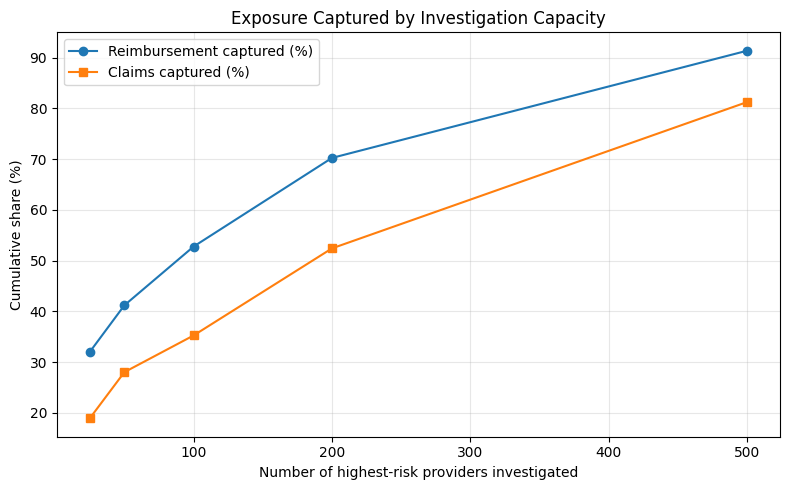

In [26]:
# ============================================================
# STEP 5A.10 — PLOTS
# ============================================================

import matplotlib.pyplot as plt

# Plot 1: Exposure captured by Top-K providers
plt.figure(figsize=(8, 5))

plt.plot(
    capacity["Top_K"],
    capacity["Reimbursement_%"],
    marker="o",
    label="Reimbursement captured (%)"
)

plt.plot(
    capacity["Top_K"],
    capacity["Claims_%"],
    marker="s",
    label="Claims captured (%)"
)

plt.xlabel("Number of highest-risk providers investigated")
plt.ylabel("Cumulative share (%)")
plt.title("Exposure Captured by Investigation Capacity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT / "step_5A10_exposure_curve.png",
    dpi=200
)

plt.show()

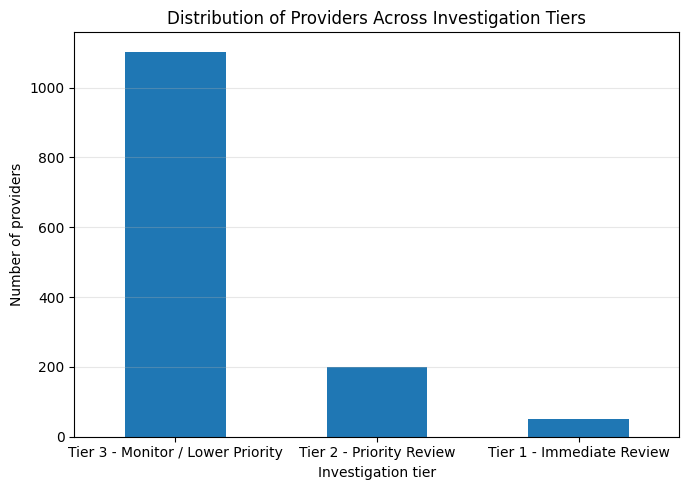

In [27]:
# Plot 2: Investigation tier distribution

tier_counts = manifest["Investigation_Tier"].value_counts()

plt.figure(figsize=(7, 5))

tier_counts.plot(kind="bar")

plt.xlabel("Investigation tier")
plt.ylabel("Number of providers")
plt.title("Distribution of Providers Across Investigation Tiers")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT / "step_5A10_tier_distribution.png",
    dpi=200
)

plt.show()

In [28]:
# ============================================================
# PREPARE FINAL MODEL OBJECTS FOR SHAP
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from lightgbm import LGBMClassifier

print("=" * 80)
print("RECOVERING STEP 5A.9 MODEL FOR SHAP")
print("=" * 80)


# ------------------------------------------------------------
# 1. Load the locked Step 4G training matrix
# ------------------------------------------------------------

step4g = pd.read_csv(
    "/content/step_4G_outputs/step_4G_clean_modeling_matrix.csv"
)

TARGET = "PotentialFraud"
ID_COL = "Provider"

y_train = step4g[TARGET].astype(int)

feature_cols = [
    c for c in step4g.columns
    if c not in [ID_COL, TARGET]
]

X_train_full = step4g[feature_cols].copy()

print("Training data:", X_train_full.shape)
print("Target:", y_train.shape)


# ------------------------------------------------------------
# 2. Locked 22 log1p features
# ------------------------------------------------------------

log1p_features = [
    "Total_Reimbursement",
    "IP_Total_Reimbursement",
    "OP_Total_Reimbursement",
    "Total_Claim_Count",
    "IP_Claim_Count",
    "OP_Claim_Count",
    "Mean_Reimbursement_Per_Claim",
    "Reimbursement_Per_Beneficiary",
    "OP_Median_Reimbursement",
    "OP_Total_Deductible",
    "OP_Mean_Deductible",
    "Repeat_Beneficiary_Count",
    "IP_Unique_Beneficiaries",
    "OP_Unique_Beneficiaries",
    "Total_Unique_Beneficiaries",
    "Mean_IP_LOS_Days",
    "Median_IP_LOS_Days",
    "Mean_OP_Diag_Per_Claim",
    "Unique_Attending_Physicians",
    "Unique_Operating_Physicians",
    "Unique_Primary_Diagnoses",
    "Primary_Diagnosis_NonMissing"
]

assert set(log1p_features).issubset(X_train_full.columns)

print("✓ 22 locked log1p features found")


# ------------------------------------------------------------
# 3. Apply the same log1p transformation
# ------------------------------------------------------------

X_train_model = X_train_full.copy()

for col in log1p_features:
    X_train_model[col] = np.log1p(
        X_train_model[col].clip(lower=0)
    )


# ------------------------------------------------------------
# 4. Fit the same median imputer + missing indicators
# ------------------------------------------------------------

production_preprocessor = SimpleImputer(
    strategy="median",
    add_indicator=True
)

X_train_proc = production_preprocessor.fit_transform(
    X_train_model
)

X_train_proc = np.asarray(
    X_train_proc,
    dtype=np.float32
)

print("Processed training matrix:", X_train_proc.shape)


# ------------------------------------------------------------
# 5. Locked LightGBM champion model
# ------------------------------------------------------------

positive = (y_train == 1).sum()
negative = (y_train == 0).sum()

imbalance_ratio = negative / positive

champion_model = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=25,
    min_child_samples=20,
    subsample=0.80,
    subsample_freq=1,
    colsample_bytree=0.80,
    scale_pos_weight=imbalance_ratio,
    objective="binary",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

champion_model.fit(
    X_train_proc,
    y_train
)

print("✓ Champion LightGBM recovered")
print(f"✓ scale_pos_weight = {imbalance_ratio:.4f}")


# ------------------------------------------------------------
# 6. Verify
# ------------------------------------------------------------

assert X_train_proc.shape[0] == len(y_train)
assert X_train_proc.shape[1] == production_preprocessor.transform(
    X_train_model
).shape[1]

print("\n" + "=" * 80)
print("✓ STEP 5A.9 MODEL OBJECTS RECOVERED")
print("=" * 80)
print("Model              :", type(champion_model).__name__)
print("Training providers :", len(X_train_full))
print("Original predictors :", X_train_full.shape[1])
print("Processed features :", X_train_proc.shape[1])

RECOVERING STEP 5A.9 MODEL FOR SHAP
Training data: (5410, 62)
Target: (5410,)
✓ 22 locked log1p features found
Processed training matrix: (5410, 90)
✓ Champion LightGBM recovered
✓ scale_pos_weight = 9.6917

✓ STEP 5A.9 MODEL OBJECTS RECOVERED
Model              : LGBMClassifier
Training providers : 5410
Original predictors : 62
Processed features : 90


STEP 5A.11 — MODEL EXPLAINABILITY WITH SHAP
✓ Step 5A.9 model and preprocessing objects found.
✓ Investigation queue loaded: 1,353 providers
Processed model features: 90
✓ Feature names match processed matrix

Computing SHAP values...
✓ SHAP matrix created: (5410, 90)

Top 20 globally influential features:


,Feature,Mean_Absolute_SHAP,Importance_Rank
0,Total_Reimbursement,1.1483,1
1,Max_IP_LOS_Days,0.5622,2
2,Std_Claims_Per_Beneficiary,0.1932,3
3,Reimbursement_Per_Beneficiary,0.1370,4
4,Primary_Diagnosis_Normalized_Entropy,0.1272,5
5,Repeat_Beneficiary_Rate,0.1176,6
6,IP_Claims_Per_Beneficiary,0.1116,7
7,Operating_Physician_Coverage,0.1109,8
8,Median_Patient_Age,0.1054,9
9,Mean_Reimbursement_Per_Claim,0.0946,10


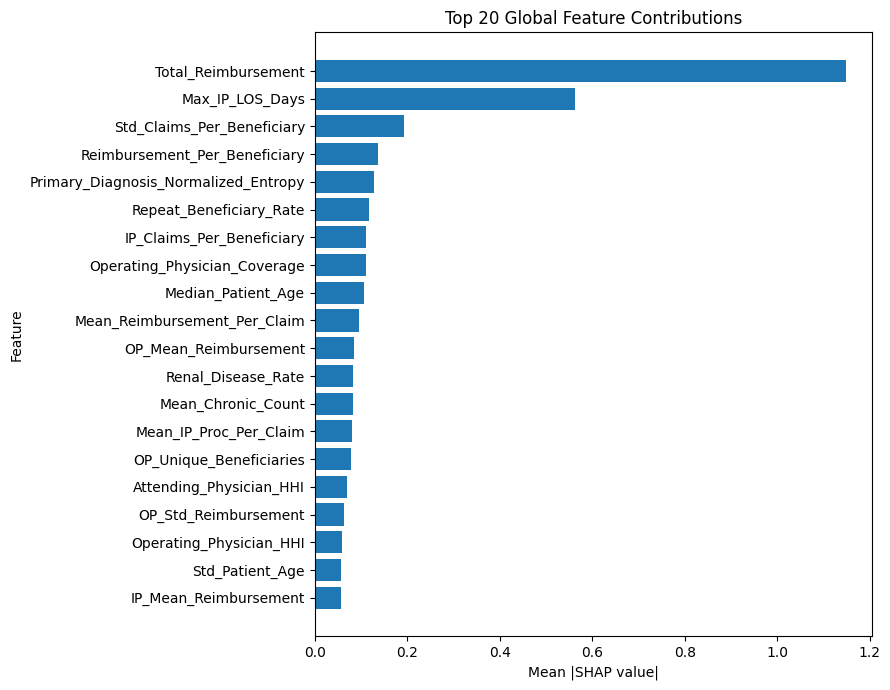

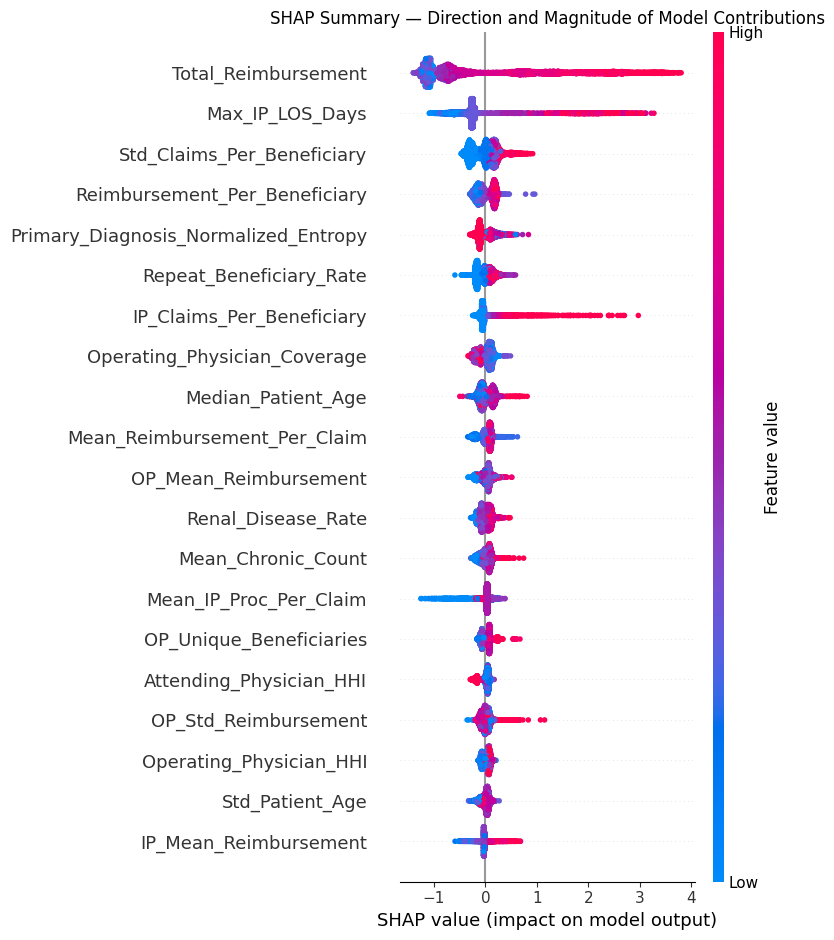


Test matrix:
Original predictors : 62
Processed features  : 90
✓ Test preprocessing matches training preprocessing

Computing SHAP values for test providers...
✓ Test SHAP matrix: (1353, 90)

TOP PROVIDER SHAP EXPLANATIONS

Provider: PRV53105
Risk Rank: 1
Calibrated Risk: 97.90%
Recommended Action: Immediate investigation review

Top 5 positive risk contributors:


,Provider,Driver_Rank,Feature,SHAP_Contribution
0,PRV53105,1,Total_Reimbursement,3.2638
1,PRV53105,2,Max_IP_LOS_Days,1.4118
2,PRV53105,3,Max_Claims_Per_Beneficiary,1.0392
3,PRV53105,4,Primary_Diagnosis_NonMissing,0.3584
4,PRV53105,5,IP_Claim_Count,0.2873



Provider: PRV56573
Risk Rank: 2
Calibrated Risk: 97.13%
Recommended Action: Immediate investigation review

Top 5 positive risk contributors:


,Provider,Driver_Rank,Feature,SHAP_Contribution
0,PRV56573,1,Total_Reimbursement,3.1787
1,PRV56573,2,Max_IP_LOS_Days,1.7827
2,PRV56573,3,Total_Claim_Count,0.3543
3,PRV56573,4,Primary_Diagnosis_NonMissing,0.3509
4,PRV56573,5,IP_Claim_Count,0.3204



Provider: PRV54751
Risk Rank: 3
Calibrated Risk: 96.95%
Recommended Action: Immediate investigation review

Top 5 positive risk contributors:


,Provider,Driver_Rank,Feature,SHAP_Contribution
0,PRV54751,1,Total_Reimbursement,3.4201
1,PRV54751,2,Max_IP_LOS_Days,1.2632
2,PRV54751,3,Primary_Diagnosis_NonMissing,0.3751
3,PRV54751,4,IP_Claim_Count,0.3431
4,PRV54751,5,OP_Total_Reimbursement,0.2855



SAVED STEP 5A.11 OUTPUTS
✓ Global importance : /content/step_5A11_outputs/step_5A11_global_feature_importance.csv
✓ Case explanations : /content/step_5A11_outputs/step_5A11_top_provider_shap_explanations.csv
✓ Case drivers      : /content/step_5A11_outputs/step_5A11_top_provider_shap_drivers.csv
✓ Global SHAP plot  : /content/step_5A11_outputs/step_5A11_global_shap_importance.png
✓ Beeswarm plot     : /content/step_5A11_outputs/step_5A11_shap_beeswarm.png

✓ STEP 5A.11 COMPLETE


In [29]:
# ============================================================
# STEP 5A.11 — SHAP EXPLAINABILITY
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ------------------------------------------------------------
# 1. Output folder
# ------------------------------------------------------------

OUT = Path("/content/step_5A11_outputs")
OUT.mkdir(exist_ok=True)

print("=" * 80)
print("STEP 5A.11 — MODEL EXPLAINABILITY WITH SHAP")
print("=" * 80)


# ------------------------------------------------------------
# 2. Check that Step 5A.9 objects are available
# ------------------------------------------------------------

required = [
    "champion_model",
    "production_preprocessor",
    "X_train_proc",
    "X_test",
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing objects: {missing}\n"
        "Please run the completed Step 5A.9 cell first."
    )

print("✓ Step 5A.9 model and preprocessing objects found.")


# ------------------------------------------------------------
# 3. Load Step 5A.10 investigation queue
# ------------------------------------------------------------

manifest_file = (
    "/content/step_5A10_outputs/"
    "step_5A10_investigation_manifest.csv"
)

manifest = pd.read_csv(manifest_file)

print(f"✓ Investigation queue loaded: {len(manifest):,} providers")


# ------------------------------------------------------------
# 4. Get processed feature names
# ------------------------------------------------------------

feature_names = production_preprocessor.get_feature_names_out(
    feature_cols
)

print(f"Processed model features: {len(feature_names)}")

assert len(feature_names) == X_train_proc.shape[1]

print("✓ Feature names match processed matrix")


# ------------------------------------------------------------
# 5. Create SHAP explainer
# ------------------------------------------------------------

print("\nComputing SHAP values...")

explainer = shap.TreeExplainer(champion_model)


# ------------------------------------------------------------
# 6. Helper for different SHAP output formats
# ------------------------------------------------------------

def get_positive_class_shap(shap_output):

    # Older SHAP versions may return [class_0, class_1]
    if isinstance(shap_output, list):
        return np.asarray(shap_output[1])

    values = np.asarray(shap_output)

    # Newer versions may return:
    # (rows, features, classes)
    if values.ndim == 3:
        if values.shape[2] == 2:
            return values[:, :, 1]

        if values.shape[1] == 2:
            return values[:, 1, :]

    return values


# ------------------------------------------------------------
# 7. GLOBAL SHAP ANALYSIS
# ------------------------------------------------------------

shap_train = explainer.shap_values(X_train_proc)

shap_train = get_positive_class_shap(shap_train)

assert shap_train.shape == X_train_proc.shape, (
    f"SHAP shape {shap_train.shape} does not match "
    f"training matrix {X_train_proc.shape}"
)

print(f"✓ SHAP matrix created: {shap_train.shape}")


# Mean absolute SHAP = overall feature influence

mean_abs_shap = np.mean(
    np.abs(shap_train),
    axis=0
)

global_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

global_importance = (
    global_importance
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .reset_index(drop=True)
)

global_importance["Importance_Rank"] = (
    np.arange(len(global_importance)) + 1
)


print("\nTop 20 globally influential features:")
display(global_importance.head(20).round(4))


# ------------------------------------------------------------
# 8. Global SHAP bar plot
# ------------------------------------------------------------

top20 = global_importance.head(20).iloc[::-1]

plt.figure(figsize=(9, 7))

plt.barh(
    top20["Feature"],
    top20["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title("Top 20 Global Feature Contributions")

plt.tight_layout()

bar_file = OUT / "step_5A11_global_shap_importance.png"

plt.savefig(
    bar_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 9. SHAP beeswarm plot
# ------------------------------------------------------------

shap.summary_plot(
    shap_train,
    X_train_proc,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary — Direction and Magnitude of Model Contributions"
)

plt.tight_layout()

beeswarm_file = OUT / "step_5A11_shap_beeswarm.png"

plt.savefig(
    beeswarm_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 10. Prepare test data using the SAME Step 5A.9 pipeline
# ------------------------------------------------------------

# Keep only the 62 model predictors.
# Provider is an ID, not a model feature.

X_test_model = X_test[feature_cols].copy()

# Apply the same 22 log1p transformations used during training

for col in log1p_features:
    X_test_model[col] = np.log1p(
        X_test_model[col].clip(lower=0)
    )

# Apply the SAME fitted imputer

X_test_proc = production_preprocessor.transform(
    X_test_model
)

X_test_proc = np.asarray(
    X_test_proc,
    dtype=np.float32
)

print("\nTest matrix:")
print("Original predictors :", X_test_model.shape[1])
print("Processed features  :", X_test_proc.shape[1])

assert X_test_model.shape[1] == 62
assert X_test_proc.shape[1] == X_train_proc.shape[1]

print("✓ Test preprocessing matches training preprocessing")


# ------------------------------------------------------------
# 11. Compute SHAP values for test providers
# ------------------------------------------------------------

print("\nComputing SHAP values for test providers...")

shap_test = explainer.shap_values(X_test_proc)

shap_test = get_positive_class_shap(
    shap_test
)

assert shap_test.shape == X_test_proc.shape

print("✓ Test SHAP matrix:", shap_test.shape)


# ------------------------------------------------------------
# 12. Local explanations for Top 3 providers
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TOP PROVIDER SHAP EXPLANATIONS")
print("=" * 80)

top_targets = manifest.head(3)

case_reports = []
all_case_drivers = []


for _, target in top_targets.iterrows():

    provider = target["Provider"]

    # Find provider in the original test data

    matches = np.where(
        X_test["Provider"].values == provider
    )[0]

    assert len(matches) == 1, (
        f"Provider {provider} was not found uniquely."
    )

    test_idx = matches[0]

    # SHAP values for this provider

    provider_shap = shap_test[test_idx]

    # Five strongest positive contributors

    top_indices = np.argsort(
        provider_shap
    )[::-1][:5]

    drivers = []

    for rank, feature_idx in enumerate(
        top_indices,
        start=1
    ):

        feature = feature_names[feature_idx]

        shap_value = provider_shap[feature_idx]

        drivers.append({
            "Provider": provider,
            "Driver_Rank": rank,
            "Feature": feature,
            "SHAP_Contribution": shap_value
        })

    drivers_df = pd.DataFrame(drivers)

    all_case_drivers.append(drivers_df)

    print(
        f"\nProvider: {provider}"
    )

    print(
        f"Risk Rank: {int(target['Risk_Rank'])}"
    )

    print(
        f"Calibrated Risk: "
        f"{target['Calibrated_Risk_Probability']:.2%}"
    )

    print(
        f"Recommended Action: "
        f"{target['Recommended_Action']}"
    )

    print("\nTop 5 positive risk contributors:")

    display(
        drivers_df.round(4)
    )

    case_reports.append({

        "Provider": provider,

        "Risk_Rank":
            int(target["Risk_Rank"]),

        "Calibrated_Risk":
            target[
                "Calibrated_Risk_Probability"
            ],

        "Driver_1":
            drivers[0]["Feature"],

        "Driver_1_SHAP":
            drivers[0]["SHAP_Contribution"],

        "Driver_2":
            drivers[1]["Feature"],

        "Driver_2_SHAP":
            drivers[1]["SHAP_Contribution"],

        "Driver_3":
            drivers[2]["Feature"],

        "Driver_3_SHAP":
            drivers[2]["SHAP_Contribution"],

        "Driver_4":
            drivers[3]["Feature"],

        "Driver_4_SHAP":
            drivers[3]["SHAP_Contribution"],

        "Driver_5":
            drivers[4]["Feature"],

        "Driver_5_SHAP":
            drivers[4]["SHAP_Contribution"]

    })


# ------------------------------------------------------------
# 13. Save SHAP results
# ------------------------------------------------------------

global_file = (
    OUT / "step_5A11_global_feature_importance.csv"
)

case_file = (
    OUT / "step_5A11_top_provider_shap_explanations.csv"
)

driver_file = (
    OUT / "step_5A11_top_provider_shap_drivers.csv"
)

global_importance.to_csv(
    global_file,
    index=False
)

pd.DataFrame(
    case_reports
).to_csv(
    case_file,
    index=False
)

pd.concat(
    all_case_drivers,
    ignore_index=True
).to_csv(
    driver_file,
    index=False
)


# ------------------------------------------------------------
# 14. Final checks
# ------------------------------------------------------------

assert len(global_importance) == 90

assert len(case_reports) == 3

assert (
    pd.DataFrame(case_reports)["Provider"]
    .nunique()
    == 3
)

print("\n" + "=" * 80)
print("SAVED STEP 5A.11 OUTPUTS")
print("=" * 80)

print(f"✓ Global importance : {global_file}")
print(f"✓ Case explanations : {case_file}")
print(f"✓ Case drivers      : {driver_file}")
print(f"✓ Global SHAP plot  : {bar_file}")
print(f"✓ Beeswarm plot     : {beeswarm_file}")

print("\n✓ STEP 5A.11 COMPLETE")
print("=" * 80)

In [30]:
# ============================================================
# STEP 5A.12 — PROVIDER RISK LOOKUP
# ============================================================
#
# Purpose:
#   Create a simple provider-level lookup system.
#
#   Example:
#       get_provider_report("PRV53105")
#
# This will later become the backend for:
#   FastAPI + Streamlit
#
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

print("=" * 70)
print("STEP 5A.12 — PROVIDER RISK LOOKUP")
print("=" * 70)


# ------------------------------------------------------------
# 1. Load the investigation queue
# ------------------------------------------------------------

manifest_path = Path(
    "/content/step_5A10_outputs/step_5A10_investigation_manifest.csv"
)

assert manifest_path.exists(), "Step 5A.10 manifest not found."

manifest = pd.read_csv(manifest_path)

print(f"✓ Investigation queue loaded: {len(manifest):,} providers")


# ------------------------------------------------------------
# 2. Check that SHAP results are available
# ------------------------------------------------------------

required_objects = ["shap_test", "feature_names", "X_test"]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing objects: {missing}. "
        "Please run Step 5A.11 first."
    )

print(f"✓ SHAP matrix: {shap_test.shape}")
print(f"✓ Model feature names: {len(feature_names)}")


# ------------------------------------------------------------
# 3. Match each Provider ID with its SHAP row
# ------------------------------------------------------------

provider_to_index = {
    provider: i
    for i, provider in enumerate(X_test["Provider"])
}


# ------------------------------------------------------------
# 4. Create provider lookup records
# ------------------------------------------------------------

records = []

for _, row in manifest.iterrows():

    provider_id = row["Provider"]

    # Find this provider's SHAP values
    shap_index = provider_to_index[provider_id]
    provider_shap = shap_test[shap_index]

    # Largest positive SHAP values
    positive_indices = np.where(provider_shap > 0)[0]

    positive_indices = positive_indices[
        np.argsort(provider_shap[positive_indices])[::-1]
    ]

    # Largest negative SHAP values
    negative_indices = np.where(provider_shap < 0)[0]

    negative_indices = negative_indices[
        np.argsort(provider_shap[negative_indices])
    ]

    # Keep only the top few
    top_positive = positive_indices[:5]
    top_negative = negative_indices[:3]

    record = {
        "Provider": provider_id,

        "Risk_Rank": int(row["Risk_Rank"]),

        "Calibrated_Risk_Probability":
            float(row["Calibrated_Risk_Probability"]),

        "Investigation_Tier":
            row["Investigation_Tier"],

        "Recommended_Action":
            row["Recommended_Action"],

        "Total_Reimbursement":
            float(row["Total_Reimbursement"]),

        "Total_Claim_Count":
            int(row["Total_Claim_Count"]),

        "IP_Claim_Count":
            int(row["IP_Claim_Count"]),

        "OP_Claim_Count":
            int(row["OP_Claim_Count"]),

        "Total_Unique_Beneficiaries":
            int(row["Total_Unique_Beneficiaries"]),

        # Store SHAP information
        "Top_Positive_Drivers": [
            {
                "feature": feature_names[i],
                "shap_value": float(provider_shap[i])
            }
            for i in top_positive
        ],

        "Top_Negative_Drivers": [
            {
                "feature": feature_names[i],
                "shap_value": float(provider_shap[i])
            }
            for i in top_negative
        ]
    }

    records.append(record)


# ------------------------------------------------------------
# 5. Create the provider database
# ------------------------------------------------------------

provider_database = pd.DataFrame(records)

provider_database = provider_database.sort_values(
    "Risk_Rank"
).reset_index(drop=True)


print(f"✓ Provider database created: {len(provider_database):,} providers")


# ------------------------------------------------------------
# 6. Create a simple lookup dictionary
# ------------------------------------------------------------

provider_lookup = {
    row["Provider"]: row.to_dict()
    for _, row in provider_database.iterrows()
}

print("✓ Provider lookup index created")


# ------------------------------------------------------------
# 7. Main provider report function
# ------------------------------------------------------------

def get_provider_report(provider_id, show_report=True):

    provider_id = str(provider_id).strip()

    # Check whether provider exists
    if provider_id not in provider_lookup:

        result = {
            "error": "Provider not found",
            "provider_id": provider_id
        }

        if show_report:
            print(f"\nProvider '{provider_id}' was not found.")

        return result


    # Get provider information
    provider = provider_lookup[provider_id]


    # Create clean result
    report = {
        "provider_id": provider_id,

        "risk_rank": provider["Risk_Rank"],

        "total_test_providers": len(provider_database),

        "calibrated_risk_probability":
            provider["Calibrated_Risk_Probability"],

        "investigation_tier":
            provider["Investigation_Tier"],

        "recommended_action":
            provider["Recommended_Action"],

        "financial_profile": {
            "total_reimbursement":
                provider["Total_Reimbursement"],

            "total_claims":
                provider["Total_Claim_Count"],

            "inpatient_claims":
                provider["IP_Claim_Count"],

            "outpatient_claims":
                provider["OP_Claim_Count"],

            "unique_beneficiaries":
                provider["Total_Unique_Beneficiaries"]
        },

        "top_risk_drivers":
            provider["Top_Positive_Drivers"],

        "top_risk_reducing_factors":
            provider["Top_Negative_Drivers"]
    }


    # --------------------------------------------------------
    # Display the report
    # --------------------------------------------------------

    if show_report:

        print("\n" + "=" * 70)
        print("PROVIDER RISK REPORT")
        print("=" * 70)

        print(f"Provider ID       : {provider_id}")

        print(
            f"Risk Rank         : "
            f"#{provider['Risk_Rank']} "
            f"of {len(provider_database):,}"
        )

        print(
            f"Calibrated Risk   : "
            f"{provider['Calibrated_Risk_Probability']:.2%}"
        )

        print(
            f"Investigation Tier: "
            f"{provider['Investigation_Tier']}"
        )

        print(
            f"Recommended Action: "
            f"{provider['Recommended_Action']}"
        )


        # Financial information
        print("\n" + "-" * 70)
        print("PROVIDER PROFILE")
        print("-" * 70)

        financial = report["financial_profile"]

        print(
            f"Total Reimbursement : "
            f"${financial['total_reimbursement']:,.2f}"
        )

        print(
            f"Total Claims        : "
            f"{financial['total_claims']:,}"
        )

        print(
            f"Inpatient Claims    : "
            f"{financial['inpatient_claims']:,}"
        )

        print(
            f"Outpatient Claims   : "
            f"{financial['outpatient_claims']:,}"
        )

        print(
            f"Unique Beneficiaries: "
            f"{financial['unique_beneficiaries']:,}"
        )


        # SHAP drivers
        print("\n" + "-" * 70)
        print("TOP RISK DRIVERS")
        print("-" * 70)

        for i, driver in enumerate(
            report["top_risk_drivers"], start=1
        ):

            print(
                f"{i}. "
                f"{driver['feature']:<40} "
                f"+{driver['shap_value']:.4f}"
            )


        # Negative SHAP
        print("\n" + "-" * 70)
        print("TOP RISK-REDUCING FACTORS")
        print("-" * 70)

        for i, driver in enumerate(
            report["top_risk_reducing_factors"], start=1
        ):

            print(
                f"{i}. "
                f"{driver['feature']:<40} "
                f"{driver['shap_value']:.4f}"
            )


        print("\n" + "-" * 70)
        print("INTERPRETATION")
        print("-" * 70)

        print(
            "This score is a statistical risk-prioritization signal."
        )

        print(
            "It does not establish confirmed fraud or legal wrongdoing."
        )

        print(
            "SHAP values describe model influence, not causation."
        )

        print("=" * 70)


    return report


# ------------------------------------------------------------
# 8. Test the lookup system
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TESTING PROVIDER LOOKUP")
print("=" * 70)


# Test 1 — highest-risk provider
report_1 = get_provider_report("PRV53105")


# Test 2 — another provider
provider_100 = manifest.loc[
    manifest["Risk_Rank"] == 100,
    "Provider"
].iloc[0]

report_100 = get_provider_report(provider_100)


# Test 3 — lower-ranked provider
provider_1000 = manifest.loc[
    manifest["Risk_Rank"] == 1000,
    "Provider"
].iloc[0]

report_1000 = get_provider_report(provider_1000)


# Test 4 — invalid provider
invalid_report = get_provider_report("PRV99999")


# ------------------------------------------------------------
# 9. Save provider database
# ------------------------------------------------------------

output_dir = Path("/content/step_5A12_outputs")
output_dir.mkdir(exist_ok=True)


# Save the complete Python-friendly database
provider_database.to_pickle(
    output_dir / "step_5A12_provider_database.pkl"
)


# Save a simple CSV version
provider_database.to_csv(
    output_dir / "step_5A12_provider_database.csv",
    index=False
)


print("\n" + "=" * 70)
print("STEP 5A.12 COMPLETE")
print("=" * 70)

print(
    f"✓ Providers indexed : {len(provider_database):,}"
)

print(
    f"✓ Database saved    : {output_dir}"
)

print(
    "✓ Provider lookup function is ready"
)

print(
    "\nExample:"
)

print(
    '    get_provider_report("PRV53105")'
)

STEP 5A.12 — PROVIDER RISK LOOKUP
✓ Investigation queue loaded: 1,353 providers
✓ SHAP matrix: (1353, 90)
✓ Model feature names: 90
✓ Provider database created: 1,353 providers
✓ Provider lookup index created

TESTING PROVIDER LOOKUP

PROVIDER RISK REPORT
Provider ID       : PRV53105
Risk Rank         : #1 of 1,353
Calibrated Risk   : 97.90%
Investigation Tier: Tier 1 - Immediate Review
Recommended Action: Immediate investigation review

----------------------------------------------------------------------
PROVIDER PROFILE
----------------------------------------------------------------------
Total Reimbursement : $2,895,670.00
Total Claims        : 2,979
Inpatient Claims    : 216
Outpatient Claims   : 2,763
Unique Beneficiaries: 1,169

----------------------------------------------------------------------
TOP RISK DRIVERS
----------------------------------------------------------------------
1. Total_Reimbursement                      +3.2638
2. Max_IP_LOS_Days                       

In [31]:
# ============================================================
# STEP 5A.13 — DEPLOYMENT ARTIFACT SERIALIZATION
# ============================================================

from pathlib import Path
import json
import joblib
import pickle
import pandas as pd
import numpy as np

print("STEP 5A.13 — DEPLOYMENT ARTIFACT SERIALIZATION")

# ------------------------------------------------------------
# 1. Platt calibrator
# ------------------------------------------------------------

production_calibrator = platt

print("✓ Champion model found:", type(champion_model).__name__)
print("✓ Platt calibrator found:", type(production_calibrator).__name__)
print("✓ Preprocessor found:", type(production_preprocessor).__name__)

# ------------------------------------------------------------
# 2. Create deployment folder
# ------------------------------------------------------------

DEPLOY_DIR = Path("/content/deployment_artifacts")
DEPLOY_DIR.mkdir(exist_ok=True)

print("✓ Deployment folder ready:", DEPLOY_DIR)

# ------------------------------------------------------------
# 3. Save the trained LightGBM model
# ------------------------------------------------------------

joblib.dump(
    champion_model,
    DEPLOY_DIR / "champion_lightgbm.joblib"
)

print("✓ LightGBM model saved")

# ------------------------------------------------------------
# 4. Save Platt calibration model
# ------------------------------------------------------------

joblib.dump(
    production_calibrator,
    DEPLOY_DIR / "platt_calibrator.joblib"
)

print("✓ Platt calibrator saved")

# ------------------------------------------------------------
# 5. Save preprocessing object
# ------------------------------------------------------------

joblib.dump(
    production_preprocessor,
    DEPLOY_DIR / "production_preprocessor.joblib"
)

print("✓ Preprocessor saved")

# ------------------------------------------------------------
# 6. Save provider database
# ------------------------------------------------------------

# provider_database was created in Step 5A.12

with open(
    DEPLOY_DIR / "provider_database.pkl",
    "wb"
) as f:
    pickle.dump(provider_database, f)

print("✓ Provider database saved")

# Also save a CSV version for easy inspection
provider_database.to_csv(
    DEPLOY_DIR / "provider_database.csv",
    index=False
)

print("✓ Provider database CSV saved")

# ------------------------------------------------------------
# 7. Save model metadata
# ------------------------------------------------------------

metadata = {
    "model": "LightGBM",
    "calibration": "Platt Scaling",
    "n_training_providers": int(len(X_train_full)),
    "n_original_predictors": int(len(feature_cols)),
    "n_processed_features": int(len(feature_names)),
    "n_log1p_features": int(len(log1p_features)),
    "imbalance_ratio": float(imbalance_ratio),
    "random_state": 42,
    "calibration_slope": float(production_calibrator.coef_[0][0]),
    "calibration_intercept": float(production_calibrator.intercept_[0])
}

with open(
    DEPLOY_DIR / "model_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("✓ Model metadata saved")

# ------------------------------------------------------------
# 8. Save feature schema
# ------------------------------------------------------------

feature_schema = {
    "original_features": list(feature_cols),
    "log1p_features": list(log1p_features),
    "processed_features": list(feature_names)
}

with open(
    DEPLOY_DIR / "feature_schema.json",
    "w"
) as f:
    json.dump(feature_schema, f, indent=4)

print("✓ Feature schema saved")

# ------------------------------------------------------------
# 9. Check saved files
# ------------------------------------------------------------

print("\nSaved deployment artifacts:")

for file in sorted(DEPLOY_DIR.iterdir()):
    print(f"  ✓ {file.name}")

print("\nSTEP 5A.13 SERIALIZATION COMPLETE")

STEP 5A.13 — DEPLOYMENT ARTIFACT SERIALIZATION
✓ Champion model found: LGBMClassifier
✓ Platt calibrator found: LogisticRegression
✓ Preprocessor found: SimpleImputer
✓ Deployment folder ready: /content/deployment_artifacts
✓ LightGBM model saved
✓ Platt calibrator saved
✓ Preprocessor saved
✓ Provider database saved
✓ Provider database CSV saved
✓ Model metadata saved
✓ Feature schema saved

Saved deployment artifacts:
  ✓ champion_lightgbm.joblib
  ✓ feature_schema.json
  ✓ model_metadata.json
  ✓ platt_calibrator.joblib
  ✓ production_preprocessor.joblib
  ✓ provider_database.csv
  ✓ provider_database.pkl

STEP 5A.13 SERIALIZATION COMPLETE


In [32]:
# ============================================================
# STEP 5A.13 — RELOAD VERIFICATION
# ============================================================

print("VERIFYING DEPLOYMENT ARTIFACTS...")

loaded_model = joblib.load(
    "/content/deployment_artifacts/champion_lightgbm.joblib"
)

loaded_calibrator = joblib.load(
    "/content/deployment_artifacts/platt_calibrator.joblib"
)

loaded_preprocessor = joblib.load(
    "/content/deployment_artifacts/production_preprocessor.joblib"
)

with open(
    "/content/deployment_artifacts/provider_database.pkl",
    "rb"
) as f:
    loaded_provider_database = pickle.load(f)

print("✓ Model reloaded:", type(loaded_model).__name__)
print("✓ Calibrator reloaded:", type(loaded_calibrator).__name__)
print("✓ Preprocessor reloaded:", type(loaded_preprocessor).__name__)
print("✓ Provider database reloaded:", type(loaded_provider_database).__name__)

# Check important dimensions
print("\nArtifact checks:")
print("Training providers:", len(X_train_full))
print("Original predictors:", len(feature_cols))
print("Processed features:", len(feature_names))
print("Provider database rows:", len(loaded_provider_database))

# Check calibration parameters
print("\nPlatt calibration parameters:")
print("Slope     :", float(loaded_calibrator.coef_[0][0]))
print("Intercept :", float(loaded_calibrator.intercept_[0]))

print("\n✓ STEP 5A.13 DEPLOYMENT ARTIFACTS VERIFIED")

VERIFYING DEPLOYMENT ARTIFACTS...
✓ Model reloaded: LGBMClassifier
✓ Calibrator reloaded: LogisticRegression
✓ Preprocessor reloaded: SimpleImputer
✓ Provider database reloaded: DataFrame

Artifact checks:
Training providers: 5410
Original predictors: 62
Processed features: 90
Provider database rows: 1353

Platt calibration parameters:
Slope     : 0.8365739270278307
Intercept : -1.2705068274985192

✓ STEP 5A.13 DEPLOYMENT ARTIFACTS VERIFIED


In [33]:
# ============================================================
# STEP 5A.14 — PROVIDER-LEVEL SHAP VISUALIZATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("STEP 5A.14 — PROVIDER-LEVEL SHAP VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Output folder
# ------------------------------------------------------------

OUT = Path("/content/step_5A14_outputs")
OUT.mkdir(exist_ok=True)

print("✓ Output folder ready:", OUT)


# ------------------------------------------------------------
# 2. Load the investigation queue
# ------------------------------------------------------------

risk_file = (
    "/content/step_5A9_outputs/"
    "step_5A9_final_test_provider_risk_scores.csv"
)

risk = pd.read_csv(risk_file)

print(f"✓ Risk scores loaded: {len(risk):,} providers")


# ------------------------------------------------------------
# 3. Check SHAP objects from Step 5A.11
# ------------------------------------------------------------

required = [
    "shap_test",
    "feature_names",
    "provider_to_index"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        f"Missing SHAP objects: {missing}. "
        "Please run the Step 5A.11 SHAP calculation first."
    )

print("✓ SHAP objects available")
print("✓ SHAP matrix:", shap_test.shape)
print("✓ Model features:", len(feature_names))


# ------------------------------------------------------------
# 4. Create provider information lookup
# ------------------------------------------------------------

provider_info = (
    risk.set_index("Provider")
)

print("✓ Provider information lookup created")


# ------------------------------------------------------------
# 5. Main visualization function
# ------------------------------------------------------------

def plot_provider_explanation(
    provider_id,
    top_n=8,
    save_plot=True
):
    """
    Display the main SHAP contributions for one provider.

    Positive SHAP values:
        Push the model toward higher predicted risk.

    Negative SHAP values:
        Push the model toward lower predicted risk.

    SHAP values explain model behavior.
    They do not prove that a provider committed fraud.
    """

    provider_id = str(provider_id).strip()

    # --------------------------------------------------------
    # Check provider
    # --------------------------------------------------------

    if provider_id not in provider_to_index:
        print(f"Provider '{provider_id}' was not found.")
        return None

    if provider_id not in provider_info.index:
        print(f"Provider '{provider_id}' has no risk-score record.")
        return None

    # --------------------------------------------------------
    # Get provider SHAP values
    # --------------------------------------------------------

    shap_index = provider_to_index[provider_id]

    provider_shap = np.asarray(
        shap_test[shap_index]
    ).reshape(-1)

    feature_names_array = np.asarray(
        feature_names
    ).reshape(-1)

    if len(provider_shap) != len(feature_names_array):
        raise ValueError(
            "SHAP values and feature names have different lengths."
        )

    # --------------------------------------------------------
    # Select strongest contributors
    # --------------------------------------------------------

    top_indices = np.argsort(
        np.abs(provider_shap)
    )[::-1][:top_n]

    # Put negative values first and positive values last
    # so the horizontal chart reads naturally.
    top_indices = top_indices[
        np.argsort(provider_shap[top_indices])
    ]

    selected_features = feature_names_array[top_indices]
    selected_values = provider_shap[top_indices]

    # --------------------------------------------------------
    # Provider risk information
    # --------------------------------------------------------

    info = provider_info.loc[provider_id]

    risk_probability = float(
        info["Calibrated_Risk_Probability"]
    )

    risk_rank = int(
        info["Risk_Rank"]
    )

    investigation_tier = str(
        info["Investigation_Tier"]
    )

    # --------------------------------------------------------
    # Create chart
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    y = np.arange(
        len(selected_features)
    )

    # Positive = higher model risk
    # Negative = lower model risk
    bar_colors = [
        "red" if value > 0 else "steelblue"
        for value in selected_values
    ]

    ax.barh(
        y,
        selected_values,
        color=bar_colors,
        alpha=0.80
    )

    # Zero reference line
    ax.axvline(
        0,
        color="black",
        linewidth=1
    )

    # --------------------------------------------------------
    # Add SHAP values beside bars
    # --------------------------------------------------------

    max_abs = max(
        np.max(np.abs(selected_values)),
        1e-6
    )

    for position, value in zip(
        y,
        selected_values
    ):

        if value >= 0:
            x_position = value + 0.02 * max_abs
            alignment = "left"
            label = f"+{value:.3f}"
        else:
            x_position = value - 0.02 * max_abs
            alignment = "right"
            label = f"{value:.3f}"

        ax.text(
            x_position,
            position,
            label,
            va="center",
            ha=alignment,
            fontsize=9
        )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_yticks(y)

    ax.set_yticklabels(
        selected_features,
        fontsize=9
    )

    ax.set_xlabel(
        "SHAP contribution to model output",
        fontsize=10
    )

    ax.set_ylabel(
        "Feature",
        fontsize=10
    )

    ax.set_title(
        f"Provider Risk Explanation — {provider_id}\n"
        f"Risk Rank #{risk_rank} | "
        f"Calibrated Risk {risk_probability:.2%} | "
        f"{investigation_tier}",
        fontsize=12,
        pad=12
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    plt.tight_layout()

    # --------------------------------------------------------
    # Save figure
    # --------------------------------------------------------

    if save_plot:

        file_path = (
            OUT /
            f"{provider_id}_shap_explanation.png"
        )

        fig.savefig(
            file_path,
            dpi=200,
            bbox_inches="tight"
        )

        print(
            f"✓ Saved: {file_path}"
        )

    plt.show()

    return fig


print("✓ Explanation function created")
print("\nSTEP 5A.14 visualization engine ready")

STEP 5A.14 — PROVIDER-LEVEL SHAP VISUALIZATION
✓ Output folder ready: /content/step_5A14_outputs
✓ Risk scores loaded: 1,353 providers
✓ SHAP objects available
✓ SHAP matrix: (1353, 90)
✓ Model features: 90
✓ Provider information lookup created
✓ Explanation function created

STEP 5A.14 visualization engine ready


TESTING PROVIDER EXPLANATIONS

1. Highest-risk provider
✓ Saved: /content/step_5A14_outputs/PRV53105_shap_explanation.png


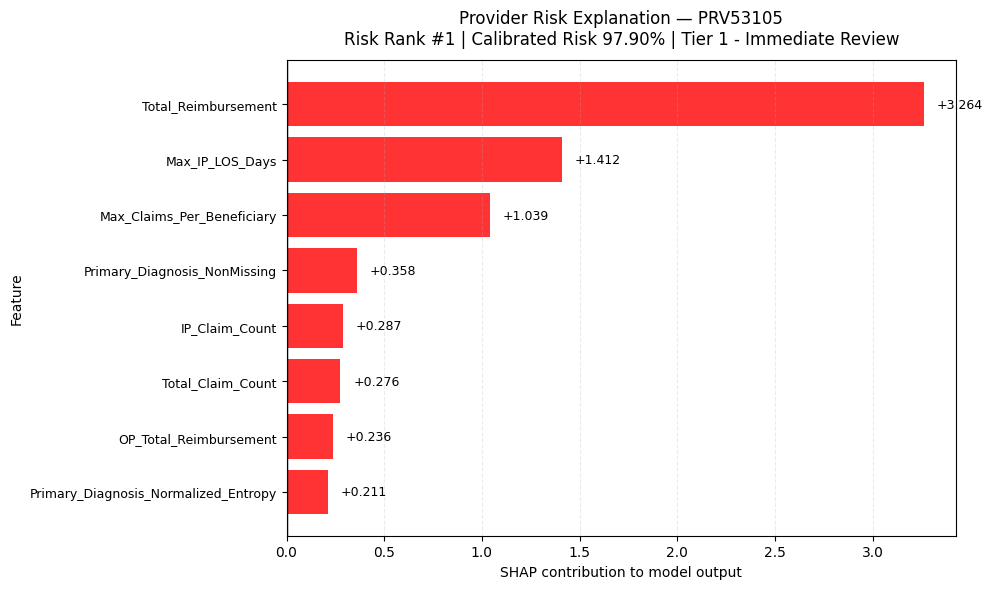


2. Rank #100 provider
Provider: PRV54740
✓ Saved: /content/step_5A14_outputs/PRV54740_shap_explanation.png


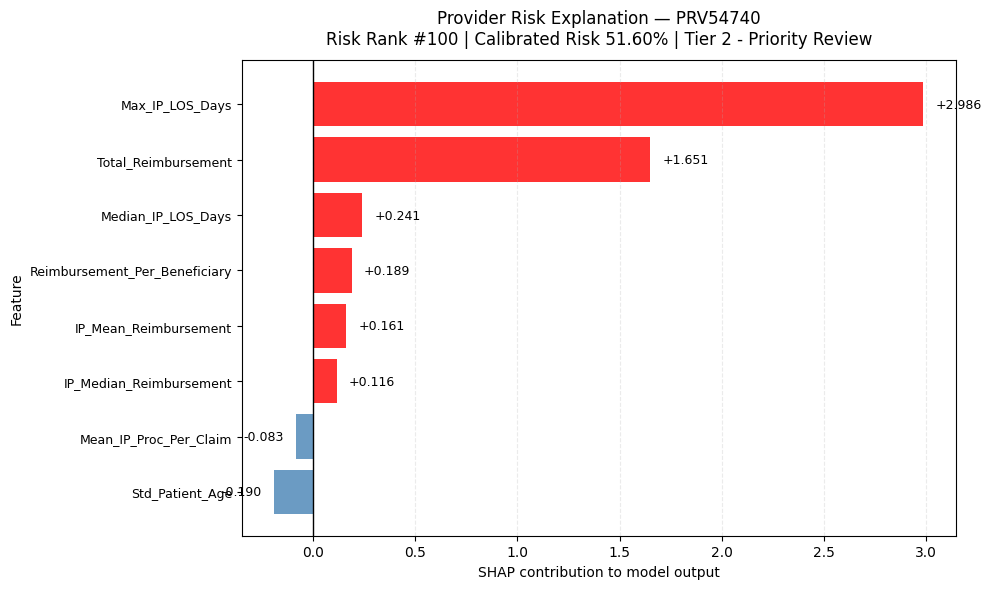


3. Rank #1000 provider
Provider: PRV51320
✓ Saved: /content/step_5A14_outputs/PRV51320_shap_explanation.png


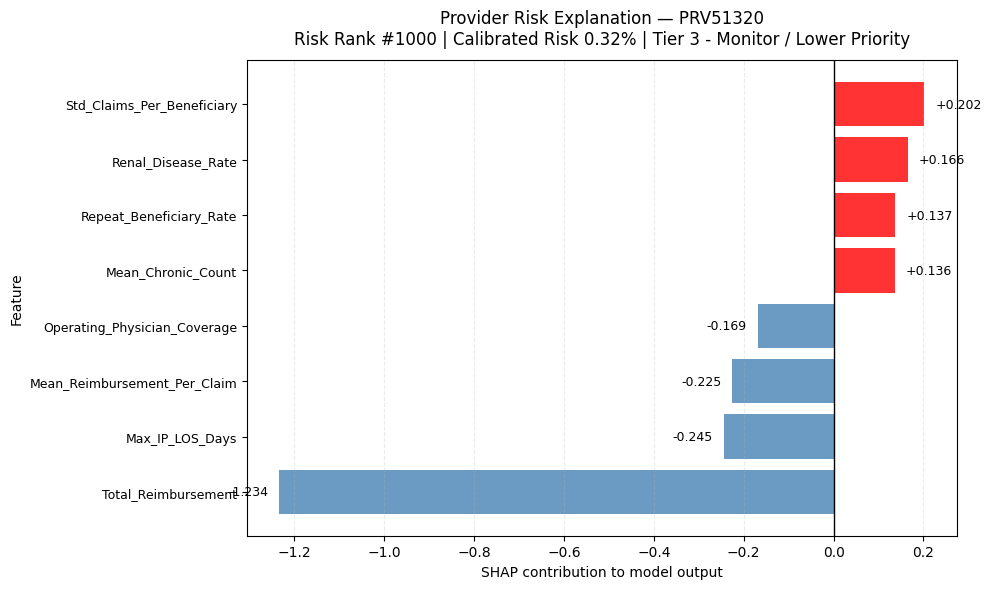


✓ STEP 5A.14 COMPLETE


In [34]:
# ============================================================
# STEP 5A.14 — TEST THREE PROVIDERS
# ============================================================

print("=" * 70)
print("TESTING PROVIDER EXPLANATIONS")
print("=" * 70)

# Rank #1
print("\n1. Highest-risk provider")
plot_provider_explanation(
    "PRV53105",
    top_n=8
)

# Rank #100
rank_100_provider = (
    risk.loc[
        risk["Risk_Rank"] == 100,
        "Provider"
    ].iloc[0]
)

print("\n2. Rank #100 provider")
print("Provider:", rank_100_provider)

plot_provider_explanation(
    rank_100_provider,
    top_n=8
)

# Rank #1000
rank_1000_provider = (
    risk.loc[
        risk["Risk_Rank"] == 1000,
        "Provider"
    ].iloc[0]
)

print("\n3. Rank #1000 provider")
print("Provider:", rank_1000_provider)

plot_provider_explanation(
    rank_1000_provider,
    top_n=8
)

print("\n" + "=" * 70)
print("✓ STEP 5A.14 COMPLETE")
print("=" * 70)

In [35]:
# ============================================================
# STEP 5A.15 — FASTAPI BACKEND
# ============================================================
#
# Purpose:
#   Create a small REST API for the healthcare provider
#   risk-prioritization system.
#
# Endpoints:
#   GET /health
#   GET /model-info
#   GET /providers/{provider_id}
#   GET /investigation-queue/top?k=10
#
# The API uses the deployment artifacts created in Step 5A.13.
#
# ============================================================

import sys
import subprocess
import time
import threading
import requests
import json

from pathlib import Path


# ------------------------------------------------------------
# 1. Install FastAPI and Uvicorn if necessary
# ------------------------------------------------------------

try:
    import fastapi
    import uvicorn

except ImportError:

    print("Installing FastAPI and Uvicorn...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "fastapi",
        "uvicorn"
    ])

    import fastapi
    import uvicorn


from fastapi import FastAPI, HTTPException, Query


print("=" * 70)
print("STEP 5A.15 — FASTAPI BACKEND")
print("=" * 70)


# ------------------------------------------------------------
# 2. Check deployment artifacts
# ------------------------------------------------------------

DEPLOY_DIR = Path(
    "/content/deployment_artifacts"
)

REQUIRED_FILES = [
    "provider_database.pkl",
    "model_metadata.json",
    "feature_schema.json",
    "champion_lightgbm.joblib",
    "platt_calibrator.joblib",
    "production_preprocessor.joblib"
]

missing_files = [
    file_name
    for file_name in REQUIRED_FILES
    if not (DEPLOY_DIR / file_name).exists()
]

if missing_files:

    raise RuntimeError(
        "Missing deployment artifacts:\n"
        + "\n".join(missing_files)
        + "\n\nPlease complete Step 5A.13 first."
    )


print("✓ Deployment artifacts found")


# ------------------------------------------------------------
# 3. Create API folder
# ------------------------------------------------------------

API_DIR = Path(
    "/content/api_service"
)

API_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("✓ API folder:", API_DIR)


# ------------------------------------------------------------
# 4. FastAPI application
# ------------------------------------------------------------

app_code = r'''
from fastapi import FastAPI, HTTPException, Query
from pathlib import Path
import pandas as pd
import json


# ============================================================
# API APPLICATION
# ============================================================

app = FastAPI(
    title="Healthcare Provider Risk Intelligence API",
    description=(
        "REST API for healthcare provider risk prioritization, "
        "investigation ranking, and model explanations."
    ),
    version="1.0.0"
)


# ============================================================
# LOAD DEPLOYMENT DATA
# ============================================================

DEPLOY_DIR = Path(
    "/content/deployment_artifacts"
)

DATABASE_FILE = (
    DEPLOY_DIR /
    "provider_database.pkl"
)

METADATA_FILE = (
    DEPLOY_DIR /
    "model_metadata.json"
)


if not DATABASE_FILE.exists():
    raise RuntimeError(
        f"Provider database not found: {DATABASE_FILE}"
    )


# Load the provider database once when the API starts.
provider_database = pd.read_pickle(
    DATABASE_FILE
)


# Create a fast provider lookup.
provider_lookup = (
    provider_database
    .set_index("Provider")
    .to_dict(orient="index")
)


# Load model metadata.
if METADATA_FILE.exists():

    with open(
        METADATA_FILE,
        "r"
    ) as file:

        model_metadata = json.load(file)

else:

    model_metadata = {}


# ============================================================
# 1. HEALTH CHECK
# ============================================================

@app.get(
    "/health",
    tags=["System"]
)
def health_check():

    return {
        "status": "online",
        "service": "Healthcare Provider Risk Intelligence API",
        "indexed_providers": len(provider_database),
        "model": "LightGBM + Platt Calibration"
    }


# ============================================================
# 2. MODEL INFORMATION
# ============================================================

@app.get(
    "/model-info",
    tags=["System"]
)
def model_info():

    return {
        "model": model_metadata.get(
            "model",
            "LightGBM"
        ),

        "calibration": model_metadata.get(
            "calibration",
            "Platt Scaling"
        ),

        "training_providers": model_metadata.get(
            "n_training_providers"
        ),

        "original_predictors": model_metadata.get(
            "n_original_predictors"
        ),

        "processed_features": model_metadata.get(
            "n_processed_features"
        ),

        "imbalance_ratio": model_metadata.get(
            "imbalance_ratio"
        ),

        "calibration_slope": model_metadata.get(
            "calibration_slope"
        ),

        "calibration_intercept": model_metadata.get(
            "calibration_intercept"
        ),

        "ranking_policy": (
            "Providers are prioritized primarily by calibrated "
            "risk ranking and available investigation capacity."
        ),

        "important_note": (
            "The score represents statistical model risk "
            "prioritization. It is not a legal determination "
            "or proof of fraud."
        )
    }


# ============================================================
# 3. PROVIDER DETAILS
# ============================================================

@app.get(
    "/providers/{provider_id}",
    tags=["Investigation"]
)
def get_provider(
    provider_id: str
):

    provider_id = (
        provider_id
        .strip()
    )

    # Check whether provider exists.
    if provider_id not in provider_lookup:

        raise HTTPException(
            status_code=404,
            detail=(
                f"Provider '{provider_id}' "
                "was not found in the scored test cohort."
            )
        )


    provider = provider_lookup[
        provider_id
    ]


    # --------------------------------------------------------
    # Convert values into normal Python types.
    # This makes the JSON response easier for applications
    # such as Streamlit to consume.
    # --------------------------------------------------------

    def safe_int(value):

        return int(value)


    def safe_float(value):

        return float(value)


    # --------------------------------------------------------
    # Provider response
    # --------------------------------------------------------

    return {

        "provider_id": provider_id,

        "risk": {
            "risk_rank": safe_int(
                provider["Risk_Rank"]
            ),

            "total_scored_providers": len(
                provider_database
            ),

            "calibrated_risk_probability": safe_float(
                provider["Calibrated_Risk_Probability"]
            ),

            "investigation_tier": str(
                provider["Investigation_Tier"]
            ),

            "recommended_action": str(
                provider["Recommended_Action"]
            )
        },

        "financial_profile": {

            "total_reimbursement": safe_float(
                provider["Total_Reimbursement"]
            ),

            "total_claims": safe_int(
                provider["Total_Claim_Count"]
            ),

            "inpatient_claims": safe_int(
                provider["IP_Claim_Count"]
            ),

            "outpatient_claims": safe_int(
                provider["OP_Claim_Count"]
            ),

            "unique_beneficiaries": safe_int(
                provider["Total_Unique_Beneficiaries"]
            )
        },

        "model_explanation": {

            "top_positive_drivers": provider.get(
                "Top_Positive_Drivers",
                []
            ),

            "top_negative_drivers": provider.get(
                "Top_Negative_Drivers",
                []
            )
        },

        "note": (
            "Positive SHAP contributions indicate features "
            "that pushed the model toward higher predicted risk. "
            "Negative contributions indicate features that pushed "
            "the model toward lower predicted risk. "
            "These are model explanations, not causal conclusions."
        )
    }


# ============================================================
# 4. TOP INVESTIGATION QUEUE
# ============================================================

@app.get(
    "/investigation-queue/top",
    tags=["Investigation"]
)
def get_top_queue(
    k: int = Query(
        default=10,
        ge=1,
        le=500
    )
):

    # The provider database is already ordered by Risk_Rank.
    top_providers = (
        provider_database
        .sort_values("Risk_Rank")
        .head(k)
    )


    results = []


    for _, provider in top_providers.iterrows():

        results.append({

            "risk_rank": int(
                provider["Risk_Rank"]
            ),

            "provider_id": provider["Provider"],

            "calibrated_risk_probability": float(
                provider["Calibrated_Risk_Probability"]
            ),

            "investigation_tier": str(
                provider["Investigation_Tier"]
            ),

            "recommended_action": str(
                provider["Recommended_Action"]
            ),

            "total_reimbursement": float(
                provider["Total_Reimbursement"]
            ),

            "total_claims": int(
                provider["Total_Claim_Count"]
            ),

            "unique_beneficiaries": int(
                provider["Total_Unique_Beneficiaries"]
            )
        })


    return {

        "requested_capacity": k,

        "providers_returned": len(
            results
        ),

        "total_reimbursement_in_queue": float(
            top_providers[
                "Total_Reimbursement"
            ].sum()
        ),

        "providers": results
    }
'''


# ------------------------------------------------------------
# 5. Save app.py
# ------------------------------------------------------------

app_file = (
    API_DIR /
    "app.py"
)

with open(
    app_file,
    "w"
) as file:

    file.write(
        app_code.strip()
    )


print(
    f"✓ FastAPI application saved: {app_file}"
)


# ------------------------------------------------------------
# 6. Load the saved FastAPI application
# ------------------------------------------------------------

import importlib.util

spec = importlib.util.spec_from_file_location(
    "healthcare_risk_api",
    app_file
)

api_module = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(
    api_module
)

api_app = api_module.app

print("✓ FastAPI application loaded")


# ------------------------------------------------------------
# 7. Start Uvicorn
# ------------------------------------------------------------

# If this cell is rerun in the same Colab runtime, stop an older
# Uvicorn process first so port 8000 is available.
subprocess.run(
    ["pkill", "-f", "uvicorn"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(1)

# ------------------------------------------------------------
# ------------------------------------------------------------

def start_server():

    uvicorn.run(
        api_app,
        host="127.0.0.1",
        port=8000,
        log_level="warning"
    )


server_thread = threading.Thread(
    target=start_server,
    daemon=True
)

server_thread.start()

print(
    "Starting FastAPI server..."
)

time.sleep(3)


# ------------------------------------------------------------
# 8. Test the server
# ------------------------------------------------------------

BASE_URL = (
    "http://127.0.0.1:8000"
)


print("\n" + "=" * 70)
print("TESTING FASTAPI ENDPOINTS")
print("=" * 70)


# ------------------------------------------------------------
# Test 1 — Health
# ------------------------------------------------------------

response = requests.get(
    f"{BASE_URL}/health"
)

print("\n1. GET /health")

print(
    json.dumps(
        response.json(),
        indent=2
    )
)


# ------------------------------------------------------------
# Test 2 — Model information
# ------------------------------------------------------------

response = requests.get(
    f"{BASE_URL}/model-info"
)

print("\n2. GET /model-info")

print(
    json.dumps(
        response.json(),
        indent=2
    )
)


# ------------------------------------------------------------
# Test 3 — Highest-ranked provider
# ------------------------------------------------------------

response = requests.get(
    f"{BASE_URL}/providers/PRV53105"
)

print("\n3. GET /providers/PRV53105")

if response.status_code == 200:

    print(
        json.dumps(
            response.json(),
            indent=2
        )
    )

else:

    print(
        "ERROR:",
        response.status_code,
        response.text
    )


# ------------------------------------------------------------
# Test 4 — Top 3 queue
# ------------------------------------------------------------

response = requests.get(
    f"{BASE_URL}/investigation-queue/top?k=3"
)

print("\n4. GET /investigation-queue/top?k=3")

print(
    json.dumps(
        response.json(),
        indent=2
    )
)


# ------------------------------------------------------------
# Test 5 — Invalid provider
# ------------------------------------------------------------

response = requests.get(
    f"{BASE_URL}/providers/PRV99999"
)

print(
    "\n5. Invalid provider test"
)

print(
    "Status code:",
    response.status_code
)

print(
    json.dumps(
        response.json(),
        indent=2
    )
)


# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("✓ STEP 5A.15 FASTAPI BACKEND COMPLETE")
print("=" * 70)

print(
    "\nAPI address:"
)

print(
    "http://127.0.0.1:8000"
)

print(
    "\nInteractive API documentation:"
)

print(
    "http://127.0.0.1:8000/docs"
)

STEP 5A.15 — FASTAPI BACKEND
✓ Deployment artifacts found
✓ API folder: /content/api_service
✓ FastAPI application saved: /content/api_service/app.py
✓ FastAPI application loaded
Starting FastAPI server...

TESTING FASTAPI ENDPOINTS

1. GET /health
{
  "status": "online",
  "service": "Healthcare Provider Risk Intelligence API",
  "indexed_providers": 1353,
  "model": "LightGBM + Platt Calibration"
}

2. GET /model-info
{
  "model": "LightGBM",
  "calibration": "Platt Scaling",
  "training_providers": 5410,
  "original_predictors": 62,
  "processed_features": 90,
  "imbalance_ratio": 9.691699604743082,
  "calibration_slope": 0.8365739270278307,
  "calibration_intercept": -1.2705068274985192,
  "ranking_policy": "Providers are prioritized primarily by calibrated risk ranking and available investigation capacity.",
  "important_note": "The score represents statistical model risk prioritization. It is not a legal determination or proof of fraud."
}

3. GET /providers/PRV53105
{
  "provide

In [36]:
# ============================================================
# STEP 5A.16 — FINAL STREAMLIT DASHBOARD
# Healthcare Provider Risk Intelligence
# ============================================================

import os
import time
import re
import shutil
import requests
import subprocess
import sys
from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration + dependency checks
# ------------------------------------------------------------

API_URL = "http://127.0.0.1:8000"
STREAMLIT_PORT = 8501

# A fresh Colab runtime may not have the Streamlit executable.
if shutil.which("streamlit") is None:
    print("Streamlit executable not found. Installing Streamlit...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "streamlit"
    ])

print("✓ Streamlit executable:", shutil.which("streamlit"))


try:
    health = requests.get(f"{API_URL}/health", timeout=5)

    if health.status_code != 200:
        raise RuntimeError(
            f"FastAPI health check failed. Status code: {health.status_code}"
        )

    print("✓ FastAPI is running")

except Exception as e:
    raise RuntimeError(
        "FastAPI is not running.\n"
        "Please run the finalized Step 5A.15 FastAPI cell first."
    ) from e


# ------------------------------------------------------------
# 2. Verify one provider endpoint
# ------------------------------------------------------------

try:
    test_report = requests.get(
        f"{API_URL}/providers/PRV53105",
        timeout=10
    )

    if test_report.status_code != 200:
        raise RuntimeError(
            f"Provider API check failed. Status code: "
            f"{test_report.status_code}"
        )

    test_report = test_report.json()

    print(
        "✓ Provider API verified:",
        f"PRV53105 | "
        f"Risk = {test_report['risk']['calibrated_risk_probability']:.2%} | "
        f"Rank = #{test_report['risk']['risk_rank']}"
    )

except Exception as e:
    raise RuntimeError(
        "FastAPI provider endpoint could not be verified."
    ) from e


# ------------------------------------------------------------
# 3. Create dashboard directory
# ------------------------------------------------------------

dashboard_dir = Path("/content/dashboard_app")
dashboard_dir.mkdir(parents=True, exist_ok=True)

dashboard_file = dashboard_dir / "dashboard.py"


# ------------------------------------------------------------
# 4. Dashboard code
# ------------------------------------------------------------

dashboard_code = r'''
import streamlit as st
import requests
import pandas as pd
import numpy as np


# ============================================================
# CONFIGURATION
# ============================================================

API_URL = "http://127.0.0.1:8000"

st.set_page_config(
    page_title="Healthcare Provider Risk Intelligence",
    page_icon="🏥",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ============================================================
# CSS
# ============================================================

st.markdown(
    """
    <style>

    .main-title {
        font-size: 2.2rem;
        font-weight: 700;
        margin-bottom: 0.2rem;
    }

    .subtitle {
        color: #666666;
        font-size: 1rem;
        margin-bottom: 1.5rem;
    }

    .metric-card {
        padding: 1rem;
        border-radius: 10px;
        border: 1px solid #dddddd;
        background: #fafafa;
    }

    .small-note {
        color: #666666;
        font-size: 0.85rem;
    }

    </style>
    """,
    unsafe_allow_html=True
)


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def get_json(endpoint):

    try:
        response = requests.get(
            f"{API_URL}{endpoint}",
            timeout=20
        )

        if response.status_code != 200:
            return None

        return response.json()

    except Exception:
        return None


def model_signal(probability):

    if probability >= 0.70:
        return "Higher model-estimated risk"

    elif probability >= 0.30:
        return "Intermediate model-estimated risk"

    else:
        return "Lower model-estimated risk"


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.title("🏥 Healthcare Risk Intelligence")

st.sidebar.markdown(
    """
    **Claims-based AI for provider
    investigation prioritization**
    """
)

st.sidebar.divider()

st.sidebar.markdown(
    """
    ### System

    **Model:** LightGBM
    **Calibration:** Platt Scaling
    **Explainability:** SHAP
    **Backend:** FastAPI
    **Dashboard:** Streamlit
    """
)

st.sidebar.divider()

st.sidebar.caption(
    "Risk scores support investigation prioritization. "
    "They are not legal determinations or proof of fraud."
)


# ============================================================
# HEADER
# ============================================================

st.markdown(
    '<div class="main-title">Healthcare Provider Risk Intelligence</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">'
    'Explainable provider-level risk scoring and '
    'investigation prioritization from healthcare claims data.'
    '</div>',
    unsafe_allow_html=True
)


# ============================================================
# TABS
# ============================================================

tab1, tab2, tab3, tab4 = st.tabs(
    [
        "📋 Investigation Queue",
        "🔎 Provider Deep Dive",
        "🔍 Provider Risk Lookup",
        "📊 Model Governance & Validation"
    ]
)


# ============================================================
# TAB 1 — INVESTIGATION QUEUE
# ============================================================

with tab1:

    st.header("Investigation Queue")

    st.write(
        "Providers are ranked by calibrated model-estimated risk. "
        "The queue is designed to support prioritization when "
        "investigation capacity is limited."
    )

    capacity = st.selectbox(
        "Investigation capacity",
        [25, 50, 100, 200, 500],
        index=2
    )

    queue = get_json(
        f"/investigation-queue/top?k={capacity}"
    )

    if queue is None:

        st.error(
            "Could not retrieve the investigation queue "
            "from FastAPI."
        )

    else:

        providers = queue.get("providers", [])

        if len(providers) == 0:

            st.warning("No providers returned.")

        else:

            df = pd.DataFrame(providers)

            st.success(
                f"Top {len(df)} providers selected "
                f"for the investigation queue."
            )

            st.dataframe(
                df,
                use_container_width=True,
                hide_index=True
            )

            st.info(
                "The selected capacity is an operational ranking "
                "choice, not an arbitrary probability threshold."
            )


# ============================================================
# TAB 2 — PROVIDER DEEP DIVE
# ============================================================

with tab2:

    st.header("Provider Deep Dive")

    provider_id = st.text_input(
        "Enter Provider ID",
        value="PRV53105"
    ).strip()

    if st.button("Analyze Provider", key="deep_dive_button"):

        if provider_id == "":
            st.warning("Please enter a Provider ID.")

        else:

            report = get_json(
                f"/providers/{provider_id}"
            )

            if report is None:

                st.error(
                    "Provider not found or API request failed."
                )

            else:

                risk_info = report["risk"]
                financial = report["financial_profile"]
                explanation = report["model_explanation"]

                # --------------------------------------------
                # Risk section
                # --------------------------------------------

                st.subheader("Risk Summary")

                c1, c2, c3 = st.columns(3)

                with c1:
                    st.metric(
                        "Calibrated Risk",
                        f"{risk_info['calibrated_risk_probability']:.2%}"
                    )

                with c2:
                    st.metric(
                        "Risk Rank",
                        f"#{risk_info['risk_rank']}"
                    )

                with c3:
                    st.metric(
                        "Investigation Tier",
                        risk_info["investigation_tier"]
                    )

                st.write(
                    "**Model signal:**",
                    model_signal(
                        risk_info[
                            "calibrated_risk_probability"
                        ]
                    )
                )

                st.write(
                    "**Recommended action:**",
                    risk_info["recommended_action"]
                )

                # --------------------------------------------
                # Financial / utilization profile
                # --------------------------------------------

                st.subheader(
                    "Financial & Utilization Profile"
                )

                f1, f2, f3, f4, f5 = st.columns(5)

                with f1:
                    st.metric(
                        "Total Reimbursement",
                        f"${financial['total_reimbursement']:,.0f}"
                    )

                with f2:
                    st.metric(
                        "Total Claims",
                        f"{financial['total_claims']:,}"
                    )

                with f3:
                    st.metric(
                        "Inpatient Claims",
                        f"{financial['inpatient_claims']:,}"
                    )

                with f4:
                    st.metric(
                        "Outpatient Claims",
                        f"{financial['outpatient_claims']:,}"
                    )

                with f5:
                    st.metric(
                        "Unique Beneficiaries",
                        f"{financial['unique_beneficiaries']:,}"
                    )

                # --------------------------------------------
                # SHAP explanation
                # --------------------------------------------

                st.subheader(
                    "Model Explanation"
                )

                positive = explanation.get(
                    "top_positive_drivers",
                    []
                )

                negative = explanation.get(
                    "top_negative_drivers",
                    []
                )

                col_pos, col_neg = st.columns(2)

                with col_pos:

                    st.markdown(
                        "**Higher-risk model contributions**"
                    )

                    if positive:

                        pos_df = pd.DataFrame(positive)

                        st.dataframe(
                            pos_df,
                            use_container_width=True,
                            hide_index=True
                        )

                    else:
                        st.write("No positive drivers available.")

                with col_neg:

                    st.markdown(
                        "**Lower-risk model contributions**"
                    )

                    if negative:

                        neg_df = pd.DataFrame(negative)

                        st.dataframe(
                            neg_df,
                            use_container_width=True,
                            hide_index=True
                        )

                    else:
                        st.write("No negative drivers available.")

                st.caption(
                    "SHAP values describe how model features "
                    "contributed to this prediction. They do not "
                    "establish causal relationships."
                )


# ============================================================
# TAB 3 — PROVIDER RISK LOOKUP
# ============================================================

with tab3:

    st.header("Provider Risk Lookup")

    lookup_id = st.text_input(
        "Provider ID",
        value="PRV53105",
        key="lookup_provider"
    ).strip()

    if st.button(
        "Search Provider",
        key="lookup_button"
    ):

        if lookup_id == "":
            st.warning("Please enter a Provider ID.")

        else:

            report = get_json(
                f"/providers/{lookup_id}"
            )

            if report is None:

                st.error(
                    "Provider not found."
                )

            else:

                risk = report["risk"]

                st.success(
                    f"Provider {lookup_id} found."
                )

                c1, c2, c3, c4 = st.columns(4)

                with c1:
                    st.metric(
                        "Calibrated Risk",
                        f"{risk['calibrated_risk_probability']:.2%}"
                    )

                with c2:
                    st.metric(
                        "Risk Rank",
                        f"#{risk['risk_rank']}"
                    )

                with c3:
                    st.metric(
                        "Investigation Tier",
                        risk["investigation_tier"]
                    )

                with c4:
                    st.metric(
                        "Recommended Action",
                        risk["recommended_action"]
                    )

                st.json(report)


# ============================================================
# TAB 4 — MODEL GOVERNANCE & VALIDATION
# ============================================================

with tab4:

    st.header("Model Governance & Validation")

    info = get_json("/model-info")

    if info is None:

        st.error(
            "Could not retrieve model information."
        )

    else:

        st.subheader("Model")

        c1, c2, c3 = st.columns(3)

        with c1:
            st.metric(
                "Model",
                info.get("model", "N/A")
            )

        with c2:
            st.metric(
                "Calibration",
                info.get("calibration", "N/A")
            )

        with c3:
            st.metric(
                "Training Providers",
                f"{info.get('training_providers', 0):,}"
            )

        st.subheader(
            "Feature Pipeline"
        )

        c1, c2, c3 = st.columns(3)

        with c1:
            st.metric(
                "Original Predictors",
                info.get("original_predictors", "N/A")
            )

        with c2:
            st.metric(
                "Processed Features",
                info.get("processed_features", "N/A")
            )

        with c3:
            st.metric(
                "Imbalance Ratio",
                f"{info.get('imbalance_ratio', 0):.2f}"
            )

        st.subheader(
            "Calibration Parameters"
        )

        c1, c2 = st.columns(2)

        with c1:
            st.metric(
                "Platt Slope",
                f"{info.get('calibration_slope', 0):.4f}"
            )

        with c2:
            st.metric(
                "Platt Intercept",
                f"{info.get('calibration_intercept', 0):.4f}"
            )

        st.subheader(
            "Investigation Policy"
        )

        st.info(
            info.get(
                "ranking_policy",
                "Capacity-based risk ranking."
            )
        )

        st.warning(
            "The model estimates statistical provider risk "
            "for prioritization. A high score does not mean "
            "that fraud has been legally or clinically established."
        )

'''


# ------------------------------------------------------------
# 5. Write dashboard file
# ------------------------------------------------------------

dashboard_file.write_text(
    dashboard_code,
    encoding="utf-8"
)

print(f"✓ Dashboard created: {dashboard_file}")


# ------------------------------------------------------------
# 6. Stop old Streamlit process if one exists
# ------------------------------------------------------------

subprocess.run(
    ["pkill", "-f", "streamlit"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)


# ------------------------------------------------------------
# 7. Start Streamlit
# ------------------------------------------------------------

# Stop only an older Streamlit process if the cell is rerun.
subprocess.run(
    ["pkill", "-f", "streamlit run"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(1)

streamlit_process = subprocess.Popen(
    [
        shutil.which("streamlit"),
        "run",
        str(dashboard_file),
        "--server.address=0.0.0.0",
        "--server.port=8501",
        "--server.headless=true",
        "--browser.gatherUsageStats=false"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(5)

print("✓ Streamlit started on port 8501")


# ------------------------------------------------------------
# 8. Check Streamlit locally
# ------------------------------------------------------------

try:

    local_check = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )

    print(
        "✓ Local Streamlit check:",
        local_check.status_code
    )

except Exception as e:

    print(
        "⚠ Could not verify Streamlit locally:",
        e
    )


# ------------------------------------------------------------
# 9. Start Cloudflare Quick Tunnel
# ------------------------------------------------------------

# Fresh Colab runtimes may not have cloudflared installed.
cloudflared_path = shutil.which("cloudflared")

if cloudflared_path is None:

    print("cloudflared not found. Downloading the Linux binary...")

    cloudflared_path = "/content/cloudflared"

    subprocess.check_call([
        "wget",
        "-q",
        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
        "-O",
        cloudflared_path
    ])

    subprocess.check_call([
        "chmod",
        "+x",
        cloudflared_path
    ])

print("✓ cloudflared:", cloudflared_path)

subprocess.run(
    ["pkill", "-f", "cloudflared"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

cloudflare_process = subprocess.Popen(
    [
        cloudflared_path,
        "tunnel",
        "--url",
        "http://127.0.0.1:8501"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

print("\nStarting Cloudflare Quick Tunnel...\n")

public_url = None
start_time = time.time()

while time.time() - start_time < 30:

    line = cloudflare_process.stdout.readline()

    if not line:
        time.sleep(0.2)
        continue

    line = line.strip()
    print(line)

    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        line
    )

    if match:
        public_url = match.group(0)
        break


# ------------------------------------------------------------
# 10. Final output
# ------------------------------------------------------------

print("\n" + "=" * 70)

if public_url:

    print("✓ DASHBOARD IS LIVE")
    print("=" * 70)
    print("\nOpen this URL on your laptop:\n")
    print(public_url)

else:

    print("⚠ Cloudflare URL was not detected automatically.")
    print(
        "Check the Cloudflare output above for the "
        "trycloudflare.com URL."
    )

print("\nKeep this Colab runtime running while using the dashboard.")
print("=" * 70)

Streamlit executable not found. Installing Streamlit...
✓ Streamlit executable: /usr/local/bin/streamlit
✓ FastAPI is running
✓ Provider API verified: PRV53105 | Risk = 97.90% | Rank = #1
✓ Dashboard created: /content/dashboard_app/dashboard.py
✓ Streamlit started on port 8501
✓ Local Streamlit check: 200
cloudflared not found. Downloading the Linux binary...
✓ cloudflared: /content/cloudflared

Starting Cloudflare Quick Tunnel...

2026-11-18T18:50:39Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cl

# Final Project Results & Interpretation

## Locked model
- **Champion:** LightGBM with leakage-safe preprocessing and class weighting.
- **Calibration:** Platt scaling.
- **Provider predictors:** 62 locked predictors before preprocessing.
- **Processed features:** 90 after median imputation and missingness indicators.
- **Final training providers:** 5,410.

## Out-of-fold validation
| Metric | Final calibrated LightGBM |
|---|---:|
| Average Precision | 0.7769 |
| ROC-AUC | 0.9572 |
| Brier Score | 0.0387 |
| ECE | 0.0059 |
| Log Loss | 0.1340 |

The public test provider table contains no `PotentialFraud` labels, so **test-set accuracy, recall, precision, AP, or ROC-AUC are not reported**. The 1,353 public test providers are used for final risk scoring and investigation ranking.

## Operational investigation policy
The final system prioritizes providers by calibrated risk ranking under a chosen investigation capacity rather than relying on an arbitrary probability cutoff. This matches the intended operational use: investigators can inspect the highest-ranked K providers first and evaluate the resulting exposure captured by that queue.

## Explainability
SHAP is used for global feature importance and provider-level explanations. SHAP values describe model contribution, not causality and not proof of fraudulent behavior.

## Deployment
- FastAPI backend: provider lookup, model information, and investigation queue endpoints.
- Streamlit dashboard: investigation queue, provider deep dive, provider lookup, and model governance/validation.
- Cloudflare Quick Tunnel is used only for temporary remote dashboard access from a Colab runtime; it is not a permanent production deployment.

## Limitations
1. The dataset label represents `PotentialFraud`, not independently adjudicated fraud.
2. Public test providers have no target labels, so their predictions cannot be performance-evaluated within this dataset.
3. SHAP explanations are model explanations, not causal explanations.
4. Investigation tiers and recommended actions are prioritization aids, not legal, regulatory, or clinical decisions.
5. The system should be validated against independently reviewed cases before any real-world enforcement or financial action.
